# Risk stratification for work disability in systemic lupus erythematosus from routine clinic visits: development and temporal validation of a prediction model

**At every routine clinic visit of an employed patient with SLE, the tool places the patient in a risk tier for
work disability within the next 24 months**, where work disability means leaving paid work for health reasons: a
recorded status of *disabled* (receiving disability benefits), or sick leave lasting at least 6 months without a
return to work. The tiers are meant to decide **whom to talk to about work and refer for vocational support**; they
are not an alarm that a work loss is imminent. The notebook develops the tool from routine visit data, shows what
each kind of information adds (a **ladder** of models), checks whether deep learning does better, and validates the
tool over calendar time.

| | |
|---|---|
| **Prediction** | At each employed visit (a *landmark*): the cumulative incidence of work disability in the next **24 months** (12 months also reported), placed in a **risk tier** |
| **Reported model** | **HazReg**: cause-specific Poisson hazard regression (onset and competing exits; ridge) on a **compact current-visit set** of 20 clinical and social variables, with splines for prednisone, SDI, SLEDAI-2K and age. **LogReg** (logistic regression of the 24-month label, same inputs) is reported beside it |
| **Model ladder** | L1 demographics → L2 first visit → L3 current visit (the reported model); a unit-weighted core score and a wide input set alongside |
| **Deep-learning comparator** | **DYN**: an LSTM reading the current visit + change from own baseline as a 2-year history on a 6-month grid, with onset and competing-exit hazards |
| **Primary metrics** | Time-dependent **AUROC** (cumulative case / dynamic control, IPCW, competing risks) and **Brier score / IPA** at 24 months over all landmarks; calibration; decision curves |
| **Secondary metrics** | Within-era AUROC and time-matched patient AUROC (patients compared within the same era / on the same dates) |
| **Clinical output** | Risk **tiers** (absolute < 2 %, 2-4 %, 4-10 %, ≥ 10 %; and relative, by percentile among the clinic's current patients), for **referral to vocational support** |
| **Validation** | 5 × 5-fold patient-grouped cross-validation (internal); **validation by calendar period** (forward-chaining, pooled over 2-year periods) and a temporal split (develop < 2012, evaluate ≥ 2012); refitted sensitivity analyses; two outcome variants |
| **Calendar time** | No model reads the calendar year; the level of the published model is set by one **deployment intercept** on 2012-2019 (Section 18.5); a year-adjusted model checks that the coefficients do not carry the era (Section 17.1) |

**Aims.** (1) Do routine visits carry a signal? (the ladder; Section 13). (2) Build and describe the stratification
tool: performance, risk factors, calibration, clinical use, stability (Section 14). (3) Does deep learning do
better? (DYN against the reported model; Section 15). (4) Does the tool transport over calendar time, and what does
it need before use? (Section 18). And one question of interpretation: are the tiers stable strata, or do they also
warn of a coming onset? (Section 16).

**Contents.** 1 Motivation · 2 Data · 3 Outcome, competing events and censoring (Box 2) · 4 Landmarks and the
24-month risk (Box 1) · 5 Variables · 6 Models · 7 Calibration and thresholds · 8 Validation, aims and hypotheses ·
9 Evaluation (Box 3) · 10 Pitfalls and limitations (Box 4) · 11 Code · 12-19 Results (13 the ladder, 14 the
stratification tool, 15 deep learning, 16 stratification vs early warning, 17 sensitivity analyses, 18 transport
over calendar time, 19 summary) · 20 TRIPOD+AI reporting · Appendix A secondary analyses

The notebook runs on its own from the visit-level extract (`lupus_merged_visit_level.csv`). Every fit is stored in
`cv_state_update_v17.pkl` so that an interrupted run resumes; deleting that file refits everything. `SLE_SMOKE=1` runs
a quick test version; `run_notebook.py --variant NAME` runs an outcome variant (Section 17.2). Figures are written
to `figs/` as 300-dpi PNG and as PDF.

## 1. Motivation

Work disability is common in SLE and hard to reverse once it happens. Vocational support (occupational therapy,
workplace adjustments, social work, vocational rehabilitation) is most useful before a patient leaves work, so a
clinic needs to know which working patients are at higher risk. A risk tier built from data the clinic already
records at every visit would let the rheumatologist raise work with the patients for whom it matters and refer
early. The referral is low-harm and low-cost, which is why the tool is judged at low risk thresholds (Section 14.4).

The purpose is **risk stratification**: sorting the patients seen in clinic into groups with different risks, so
that attention goes where the risk is. That differs from early warning (detecting the months before a work loss),
which needs a risk that rises within the patient ahead of the event; Section 16 tests whether the tiers do that.

A 24-month horizon is used because work disability usually develops over months to years (a sick-leave spell must
last 6 months before it counts), because a clinic sees most patients two to four times a year, so a 24-month window
spans several chances to act, and because the outcome is rare (a few per 100 patient-years), so a 24-month horizon
roughly doubles the events behind each risk estimate compared with 12 months (12 months is reported alongside).

Prediction studies of this kind usually find that machine learning does not beat a well-specified regression, and
that sequence models rarely beat the last visit unless the trajectories carry strong information. The study shows
what the routine data can do and whether a deep-learning model adds anything, with the simpler model preferred when
they tie.

## 2. Data and visit-level processing

**Source.** One row per clinic visit of the Toronto Lupus Clinic (a single centre; routinely collected, prospective
clinic data), with demographics, disease activity (SLEDAI-2K and its items), damage (SLICC/ACR damage index, SDI, and
its items), treatment and doses, symptoms, laboratory results, and the **employment status recorded at the visit**
(employed, sick leave, disabled, retired, homemaker, student, looking for work, other, or not recorded).

**Cleaning** (Section 11.2):
1. Visits without a patient identifier or a visit date are dropped; duplicate visits (same patient and date) keep
   the first record; visits are put in date order within each patient.
2. **Only information recorded on or before a visit is used to describe that visit.** Every derived variable
   (running means, counts in the last 12 months, change from the patient's usual value, cumulative exposures) looks
   backwards only.
3. **Clinical items not recorded at a visit are carried forward** from the patient's previous visit (SLEDAI-2K,
   SDI and its domains, fatigue, fibromyalgia, arthralgia, dyspnoea, tender points, smoking). Before the first
   recording they stay missing and are handled by the model's missing-value indicators (Section 5).
4. **Patient-constant items** (sex, race, highest education) are filled forwards and backwards within the patient.
   Race is grouped as White, Black, Asian (Chinese, Filipino) and other / mixed / not recorded.
5. **Doses**: an empty dose field means the patient is not on the drug (dose 0). Treatment is summarised by drug
   class so that it means the same in every era (antimalarial; conventional immunosuppressant: azathioprine,
   methotrexate, mycophenolate, ciclosporin; advanced therapy: IV cyclophosphamide and biologics), the EULAR 2023
   treatment step (0-4), the prednisone dose and its percentile among all clinic visits of the same calendar year
   (the usual dose fell over the decades), and an **acute visit** flag (an IV methylprednisolone pulse, a prednisone
   increase of ≥ 5 mg/day, or a new immunosuppressant or biologic).
6. **Care pattern**: visits per year over the last 12 months (per year of observed time, at least 3 months), years
   since the first clinic visit, the gap since the previous visit and that gap relative to the patient's usual gap.
7. **Work history** from the employment statuses recorded before the visit: months on sick leave so far, and years
   of continuous employment up to the visit.
8. **Calendar year** (decimal) and a restricted-cubic-spline term (knots at the 10th, 50th and 90th percentiles of the
   landmark dates) are computed for the year-adjusted sensitivity model only (Section 17.1); no other model reads
   them (Sections 6 and 18).

## 3. Outcome, competing events and censoring

**Work disability** (the outcome): leaving paid work for health reasons, recorded as a status of *disabled*
(disability benefits) or as sick leave lasting at least 6 months without a return to work. Each recorded employment
status is mapped to a state: **working** (employed), **sick leave**, **disabled**, **other exit** (retired,
homemaker, student, looking for work, other) or **unknown** (not recorded; skipped: the patient stays at risk).
Follow-up of a working patient ends at the first of:

| What happens next | Classified as | Dated at |
|---|---|---|
| A visit with status *disabled* | **Work-disability onset** | that visit |
| A sick-leave spell with no return to work that lasts **≥ 6 months**, whatever status follows it | **Work-disability onset** | the start of the spell |
| A shorter sick-leave spell followed by *disabled* | **Work-disability onset** | the start of the spell |
| A sick-leave spell followed by a return to work | nothing: the patient is still at risk | – |
| A visit with an other-exit status (or a short sick-leave spell followed by one) | **Competing exit** | that visit (spell start) |
| An open sick-leave spell shorter than 6 months at the last visit | **Censored** | the start of the spell |
| The last visit with a known status, or age 65, or death | **Censored** | that date |

Every sick-leave onset is dated at the start of the spell, so that patients with the same course have the same
onset date whatever the timing of their visits (dating at the confirming visit is an outcome variant, Section
17.2). A spell of ≥ 6 months that ends in an other-exit status (homemaker, student, retired, looking for work) already
counts as an onset, so the outcome absorbs some "disability under another name"; the broader outcome variant
(Section 17.2) goes further. Section 20.1b audits every route.

* A patient who **returns to paid work after an onset** re-enters the cohort at their next employed visit; a second
  onset is a new event.
* Partial work loss (reduced hours) cannot be identified: the employment field has no hours or part-time category.

> **Box 2. Competing risks and censoring weights.** **Competing exits** (mostly retirement, homemaking and job
> loss) end the time at risk of work disability; they are treated as a second cause, not censored. **The estimand is
> the probability of a work-disability onset within 24 months before any competing exit** (the cumulative
> incidence), not one minus a survival probability: a patient who retires next month cannot become work-disabled
> this year, and the risk should say so. In the 24-month label a competing exit counts as no onset.
> **Censoring** (end of records, age 65, death) is handled by **inverse-probability-of-censoring weights (IPCW)**:
> the Kaplan-Meier distribution of the censoring times, *G*, over all landmark follow-up times; at horizon *h*, a
> landmark whose onset or competing exit happens before *h* gets weight 1/G(its event time), a landmark followed
> beyond *h* gets weight 1/G(*h*), and a landmark censored before *h* gets weight 0. The weighted landmarks stand in
> for the full cohort at that horizon. This marginal Kaplan-Meier assumes censoring is **non-informative**; the
> main threat is clinic dropout (patients who leave the clinic after losing work), counted in Sections 18.1 and
> 20.1b.

## 4. Landmarks and the 24-month risk

> **Box 1. The landmark data structure.** Every **employed visit before age 65 that is not the patient's last visit
> with a known status** is a landmark: a point at which the model is asked for a prediction, using only what was
> recorded on or before that visit. A patient contributes as many landmarks as such visits, each with its own
> follow-up (to the onset, a competing exit or censoring), so the follow-up of successive landmarks of the same
> patient **overlaps** and the landmarks are not independent: patients, not landmarks, are the unit of every split
> and every bootstrap, and the effective sample size is the ~150 patients with an onset, not the thousands of
> landmarks. A patient in the 24 months before an onset contributes several positive landmarks (a median of about
> four); the patient-level metrics (Section 9) correct for this.

**Two labels at each horizon *h*** (6, 12, ..., 48 months; primary 24):
* the **IPCW label** (used by every visit-level metric): onset within *h* = 1; competing exit within *h* or followed
  beyond *h* without an onset = 0; censored before *h* = weight 0 (Box 2);
* the **complete-case label** (used to fit the logistic regressions, the recalibration and the thresholds, inside the
  training folds): the same, but a landmark whose **potential** follow-up (to the end of the extract or to age 65) is
  shorter than *h* is left out whatever happened, so recent and older-age landmarks are not enriched with cases.
  The price: the newest 2 years of landmarks cannot be learned from (HazReg avoids this; Section 14).

**Hazards** (DYN and HazReg, Section 14). These models predict two **cause-specific hazards**
(rates per year) at each landmark, λ₁ for a work-disability onset and λ₂ for a competing exit, **assumed constant
until the next landmark**. The follow-up is cut at the landmarks into at-risk intervals, each ending in an onset
(d₁ = 1), a competing exit (d₂ = 1) or nothing; with η = log λ, the Poisson (piecewise-exponential) log-likelihood is
$\ell = \sum_j \left[d_{1j}\eta_{1j} + d_{2j}\eta_{2j} - (e^{\eta_{1j}} + e^{\eta_{2j}})\Delta_j\right]$, Δⱼ the interval's
length in years. The risk at horizon *h* assumes the current hazards hold:
$F(h) = \frac{\lambda_1}{\lambda_1 + \lambda_2}\left(1 - e^{-(\lambda_1 + \lambda_2)h}\right)$.
Because λ₂ differs between patients (age, retirement), the ranking is **nearly, not exactly, the same at every
horizon**. The recalibration (Section 7) corrects the level and spread of this extrapolation on held-out patients.

**Primary horizon: 24 months**, with 12 months alongside; 6-48 months and exclusive 12-month intervals in Appendix A.

## 5. Variables and the 6-month grid

**Variables** (the regressions read them at the landmark visit; DYN reads them on the 6-month grid, 55 channels
at every grid point; every model adds a missing-value indicator for each input that has missing values):

| Group | Variables |
|---|---|
| Demographics | age, race (Black; Asian; other / not recorded), higher education |
| Disease | disease duration, SLEDAI-2K, SDI, SDI neuropsychiatric and musculoskeletal domains |
| Treatment | prednisone dose and its era percentile, EULAR treatment step, antimalarial, conventional immunosuppressant, advanced therapy, acute visit |
| Symptoms | fatigue, fibromyalgia, fibromyalgia tender points (0-18), arthralgia, dyspnoea |
| Care pattern | visits per year (last 12 months), years in clinic, visits in the last 6 months, months since the last visit |
| Work and lifestyle | months on sick leave before, years continuously employed, current smoker |
| **Change from the patient's own baseline** | for SLEDAI-2K, SDI, prednisone, treatment step, visit rate, tender points, fatigue, arthralgia, dyspnoea, fibromyalgia and acute visits: the value now **minus the patient's usual value** (the mean over all their earlier visits) and **minus the value 12 months ago** (the latest visit at least 12 months earlier; 0 when there is none); the visit gap over the patient's usual gap; new damage in the last 24 months; months since the last flare; acute visits in the last 12 months |

**The 6-month calendar grid** (DYN only). Visits are irregular (a few months apart on average, with long gaps). For each
landmark, the LSTM reads the patient's history at **fixed 6-month steps back from the landmark date**: grid points at
t, t − 6, t − 12, t − 18 and t − 24 months (5 points for its 2-year lookback). Each grid point is built **from the visits on or before the landmark only**:

* continuous items and symptoms (age, disease duration, years in clinic, SLEDAI-2K, prednisone and
  its era percentile, fatigue, arthralgia, dyspnoea, visit rate, tender points) are **interpolated linearly** between
  the visits on either side of the point;
* acute visits: **any** acute visit in the 6 months up to the point;
* every other item: the **last value recorded** on or before the point;
* two care-pattern channels: the number of visits in the 6 months up to the point and the months since the last
  visit (so the model knows how fresh each point is);
* the last point is the landmark visit itself (checked in the code). A patient with less than 2 years in the clinic
  has fewer points (one at a first visit).

**Preprocessing** (fitted on the training patients of each fold only, then applied to the test patients): signed
log(1 + x) of skewed counts and doses; **median imputation plus a missing-value indicator** for each channel with
missing values (no landmark is dropped for a missing input); standardisation to mean 0, SD 1; values clipped at
±5 SD.

**The ladder's inputs** (Section 6): L1 reads age, education and race; L2 every one of the 27 variables as recorded
at the patient's **first employed visit** (missing values as at that visit), held fixed, plus the years since that
visit (so that, with the index age, it knows the current age); L3, the reported model, the **compact set** at the
landmark visit: the 27 variables without race, the care-process inputs (visit rate, acute visit) and the
work-history inputs (months on prior sick leave, years continuously employed), i.e. 20 variables. Race is left out
of the tool's inputs on principle; care-process inputs record how the clinic behaved and transport poorly; the
work-history inputs come from the same employment statuses as the outcome. The **wide set** (all 27 variables + the
change-from-own-baseline variables) is fitted alongside to show what leaving them out costs (H1c; Section 17.1). Four
continuous inputs (prednisone dose, SDI, SLEDAI-2K, age) get a **3-knot restricted cubic spline** (knots at the
training fold's 10th, 50th and 90th percentiles after the log transform).

## 6. Models

| Model | Input | Target | Role |
|---|---|---|---|
| L1 Demographics | age, education, race | onset + competing hazards (ridge Poisson) | the bottom rung: no clinical data |
| L2 First visit | every variable at the first employed visit + years since | onset + competing hazards | one assessment, never updated |
| **L3 HazReg** | compact current-visit set + splines | onset + competing hazards (ridge Poisson), every at-risk interval | **the reported model** |
| LogReg | compact current-visit set + splines | 24-month label (ridge logistic) | the same inputs with a binary target, beside the reported model |
| Unit-weighted score | sum of standardised SLEDAI-2K, SDI, prednisone, fatigue, fibromyalgia, age | – (recalibrated) | the "flat maximum" |
| **DYN** | current visit + change from own baseline, on a 2-year grid | onset + competing hazards (LSTM) | **deep-learning comparator** |
| HazReg wide | current visit + change, race, care process, work history | onset + competing hazards | does the compact set lose anything? (H1c) |
| HazReg linear | the compact set without splines | onset + competing hazards | what the splines add (Section 17.1) |
| HazReg + year | the compact set + calendar year (linear + spline, clipped at prediction) | onset + competing hazards | do the coefficients carry the era? (Section 17.1) |

**Why a hazard model.** The estimand is a cumulative incidence with a competing event (Box 2), which the two
cause-specific hazards give directly; and the hazard model learns from every at-risk interval, including the
partial follow-up of the most recent visits, which a 24-month label must leave out (Section 17.1b). LogReg is
reported beside it so that the reader can see the result does not depend on the target.

**The regressions** choose their ridge penalty (8 values) on inner cross-validation by the **Poisson deviance** of
both causes over the at-risk intervals (hazard models) or the **out-of-fold log-loss** of the 24-month label
(LogReg): proper scoring rules, which reward calibration as well as ranking. **DYN** (one layer, 32 hidden units)
reads the landmark's window of grid points in date order; the last hidden state, with dropout 0.3, is concatenated
with the landmark point's own inputs (a skip connection) and a linear layer gives the two log-hazards; the output
bias starts at the training patients' crude rates. Training: AdamW (learning rate 0.002, weight decay 0.01), batches
of 32 patients, gradient clipping at 1, early stopping (patience 15 epochs, at most 150) on the loss of 15 % of the
training patients held out; **5 networks with different seeds are averaged**. Nothing about DYN is tuned: one fixed
configuration.

**Calendar time.** No model reads the calendar year. Each coefficient describes the average relation over the whole
study period, and the predicted level is the average level of that period; onset rates fell over the decades, so the
published model gets one **deployment intercept** set on the landmarks of 2012-2019, the most recent years whose
24-month outcomes can be ascertained (Section 18.5). Whether the coefficients absorb the fall in rates through
clinical inputs that changed over the same years (prednisone dose, drug classes) is checked by refitting with the
calendar year as an input (HazReg + year, Section 17.1).

## 7. Calibration and thresholds

Each model's raw 24-month risk is **recalibrated** inside each training fold: a logistic regression of the
complete-case 24-month label on the logit of the raw risk (intercept and slope), fitted on the training patients'
**out-of-fold** scores (Section 11.5) and applied unchanged to the test patients. The **alarm threshold** of each
fold is chosen on the same out-of-fold risks (maximum of Youden's J; or the highest PPV with sensitivity ≥ 25 %).
The calibration of the held-out predictions is therefore a test of whether the recalibration transports to new
patients. Calibration **over calendar time** is a separate question (Section 18).

## 8. Validation, aims and hypotheses

**5 × 5-fold patient-grouped cross-validation**, stratified by whether the patient ever has an onset; every landmark
of a patient is in the same fold. Inside each training fold, **3 inner patient-grouped folds** give out-of-fold
scores for every training landmark (for recalibration, thresholds and the regressions' penalty). Each metric is
computed on the pooled test folds of a repeat and averaged over the 5 repeats. **95 % CIs** from a patient-cluster
bootstrap (1,000 resamples of patients with all their landmarks, the same resamples for every model, so differences
are paired). Verdicts for model contrasts: **superior** if the lower 95 % bound > 0, **inferior** if the upper bound
< 0, **equivalent** if the CI lies within ±0.02, otherwise inconclusive. The cross-validation is the development
evaluation of the modelling procedure; the published model is fitted on every patient. For claims about a model in
use (transport of the ranking, absolute risk) the **evaluations over calendar time of Section 18** (validation by
calendar period, the temporal split) are the ones that count.

| Aim | | Hypothesis | Estimand | Criterion |
|---|---|---|---|---|
| 1 the ladder | **H1 (primary)** | routine clinical data add to demographics | L3 (HazReg) − L1, visit AUROC 24 mo | lower bound > 0 |
| | H1a, H1b | each step adds | L2 − L1; L3 − L2 | lower bound > 0 |
| | H1c | the compact set loses nothing | L3 − HazReg wide | equivalence (±0.02) |
| | H1d | fitted weights beat equal weights | L3 − unit score | lower bound > 0 |
| 2 the tool | H2a | calibrated in held-out patients | visit calibration slope, intercept | slope 0.8-1.2; intercept CI includes 0 |
| | H2b | better than knowing the overall risk | IPA 24 mo | lower bound > 0 |
| | H2c | clinically useful at a referral threshold | net benefit at 4 % vs refer all / none | both lower bounds > 0 |
| 3 deep learning | **H3a** | DYN is not materially better | DYN − reported model, visit AUROC 24 mo | equivalence (±0.02) |
| | H3b | ... on accuracy | DYN − reported model, IPA | equivalence (±0.02) |
| stratification vs warning | H4a | discrimination is higher close to the onset | time-matched AUROC 0-24 − 24-36 months before | lower bound > 0 |
| | H4b | the risk rises within patients before the onset | mixed-model extra slope vs never-onset patients | > 0 |
| | H4c | ... more than age alone makes it rise | within-patient C, reported model − L1 | lower bound > 0 |
| | H4d | alarms reflect a rise, not a persistently high risk | share flagged at the window's first landmark | upper bound < 0.5 |
| 4 over time | H5a | the ranking transports to later years | temporal visit AUROC, reported model − L1 | lower bound > 0 |
| | H5b | the level transports as it is | temporal O/E, no update | CI includes 1 |
| | H5c | one local intercept update restores the level | O/E from 2016 after an intercept update on 2012-2015 | CI includes 1 |

H4a-d test whether the tiers also give early warning; if they are not met, the tiers stratify patients by a risk
that is stable over time, which is the intended use.

## 9. Evaluation

> **Box 3. Visit-level vs patient-level evaluation.** A landmark model makes a prediction at every visit, so the
> natural unit of evaluation is the **visit**: the **time-dependent AUROC** for competing risks (Blanche et al.
> 2013; cases: onset within 24 months; controls: everyone else with a known status, including those with a
> competing exit; IPCW), the **IPCW Brier score** and **IPA** at 24 months, pooled over all landmarks, plus
> calibration and decision curves. Pooling over 40 years lets differences **between eras** add to the AUROC (onset
> risk was higher in the 1990s), so three checks follow. The **within-era AUROC** compares cases only with controls
> of the same era (Section 13). The **time-matched patient AUROC** (secondary) compares, for
> each onset on date *E*, the patient's mean 24-month risk logit over their landmarks in the 24 months before *E*
> with every other patient at risk on *E*, scored over the same calendar window (ties ½, pooled over onsets): a
> date-matched comparison, unaffected by the calendar trend. The **recent-era** results (landmarks from 2012) are
> reported beside the pooled ones. **Patient windows** (each patient's mean risk over the 24 months before their
> onset, or over their last 24 months of follow-up) compare cases and controls at **different calendar times**;
> they are descriptive only (Appendix A).

* **Risk tiers**: the recalibrated 24-month risk in four fixed tiers (< 2 %, 2-4 %, 4-10 %, ≥ 10 %), and relative
  tiers by percentile among the same calendar year's landmarks (Section 14.5).
* **Healthy-looking** at a visit (Appendix A.4): modified LLDAS (SLEDAI-2K ≤ 4, no major-organ activity, no new
  activity, prednisone ≤ 7.5 mg/day), SDI 0, prednisone ≤ 5 mg/day, and none of fatigue, arthralgia, dyspnoea or
  fibromyalgia.

## 10. Pitfalls and limitations

> **Box 4. Pitfalls of dynamic prediction from routine visits.**
> * **Time-period confounding.** The outcome became about 5-fold rarer over the decades, while treatment and case
>   mix changed. A pooled AUROC partly rewards separating eras; a model calibrated on the past over-predicts the
>   present. Hence the within-era and time-matched AUROCs, the recent-era results, the year-adjusted model, the
>   validation by calendar period and the deployment intercept (Sections 13, 17.1, 18).
> * **Outcome ascertainment over time.** Work exits are recorded at clinic visits. If recent exits are recorded
>   late or not at all, every exit type looks rarer in recent years and no model update can tell this from a real
>   fall; Section 18.1 shows how follow-up ends by era.
> * **Care-process variables.** Visit frequency, gaps and acute visits record how the clinic behaved as much as how
>   the patient was: they predict, but they transport poorly to clinics with other scheduling habits; they are not
>   inputs of the tool (only of the wide set).
> * **Informative visit timing.** Sicker patients are seen more often, so they contribute more landmarks; patients
>   are the unit of resampling, and the patient-level metrics weight each onset once.
> * **Label delay.** A 24-month outcome means the newest usable labels are 2 years old; the hazard model learns from
>   partial follow-up as well (Section 17.1b).

**Limitations.**
* About 150 patients with an onset: the effective sample size. Differences of about 0.03 AUROC are the smallest the
  design can detect, and the patient-level sample-size criterion is not met (Section 20.3).
* Single tertiary centre; no external validation. External validation in another cohort (the SLICC inception
  cohort, Hopkins, LUMINA) is the necessary next step.
* **The ceiling is set by the data, not the method.** There are no patient-reported outcomes, cognition, depression,
  job demands or occupation. AUROCs around 0.72 are similar to multiple-sclerosis disability progression across
  146 centres (about 0.71, De Brouwer et al.) and below work-absence models for musculoskeletal pain that used
  patient-reported data (about 0.76-0.79).
* The outcome is recorded at clinic visits; partial work loss cannot be seen; concept drift (benefit rules,
  recording, remote work since 2020) cannot be corrected from these data.
* Censoring is assumed non-informative (Box 2); clinic dropout is the main threat (Sections 18.1, 20.1b).
* Education is an input; race is not. Performance by group, including race, is in Section 20.4.
* Few measured variables move before the onset, which limits how much any model's risk can rise before it
  (Section 16): the tool stratifies, it does not time the onset.
* The risk-factor estimates (Section 14.2b) are associations within a prediction model, not causal effects.

---
# 11. Code

## 11.1 Configuration

In [1]:
"""Configuration and shared settings (Sections 2-9). Everything the analysis can change is set here."""
import os, time, pickle, random, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, sparse
from scipy.optimize import brentq
from sklearn.linear_model import LogisticRegression, PoissonRegressor
from sklearn.metrics import roc_auc_score, roc_curve
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning, message="Mean of empty slice")
pd.set_option("display.width", 200, "display.max_columns", 60, "display.max_rows", 200)

SMOKE = os.environ.get("SLE_SMOKE") == "1"          # quick end-to-end test only (not for results)
# Outcome variants (Section 17.2) are separate runs of this notebook up to the metrics (run_notebook.py --variant):
#   broad_outcome  early retirement (< 60), unemployment and homemaking (< 60) also count as work disability
#   visit_dating   onsets dated at the visit that confirms them, not at the start of the sick-leave spell
VARIANT = os.environ.get("SLE_VARIANT", "")
assert VARIANT in ("", "broad_outcome", "visit_dating"), VARIANT
TAG = "update_v17" + (f"_{VARIANT}" if VARIANT else "")
MAIN_TAG = "update_v17"
RAW_PATH = "lupus_merged_visit_level.csv"
OUT_DIR = "figs"
os.makedirs(OUT_DIR, exist_ok=True)
SEED = 240
random.seed(SEED); np.random.seed(SEED)
MONTH_DAYS = 365.25 / 12

# ---------------------------------------------------------------- cohort and outcome (Sections 2-3)
SICK_LEAVE_MIN_MONTHS = 6          # a sick-leave spell without return to work is an onset once it lasts this long
ONSET_DATING = "visit" if VARIANT == "visit_dating" else "spell_start"   # every sick-leave onset dated at the spell start
EXTRA_EVENT_EXITS = ("early_retirement", "unemployment", "early_homemaker") if VARIANT == "broad_outcome" else ()
EARLY_RETIREMENT_AGE = 60                                                # also the age limit for homemaking
UNEMPLOYED_STATES = {"looking for work"}
LANDMARKS_AFTER_DISABILITY = True  # a patient who returns to paid work after a disability onset re-enters at the next
                                   # employed visit; a second onset is an event
DEATH_AS_COMPETING_EVENT = False   # a death is censored at the last recorded employment status
DEATH_LINK_DAYS = 365
AGE_CAP_YEARS = 65                 # follow-up ends at age 65; no landmark at >= 65
WORKING_STATES = {"employed"}
SICK_STATES = {"sick leave"}
DISABLED_STATES = {"disabled"}
OTHER_EXIT_STATES = {"retired", "homemaker", "student", "looking for work", "other"}
CAUSE_NAMES = {0: "censored", 1: "work disability", 2: "other exit", 3: "death"}

# ---------------------------------------------------------------- horizons (Section 4)
PRIMARY_HORIZON_MONTHS = 24
HORIZON_DAYS = round(PRIMARY_HORIZON_MONTHS * MONTH_DAYS)
HORIZON_YEARS = HORIZON_DAYS / 365.25
HORIZONS = [6, 12, 18, 24, 30, 36, 42, 48]        # cumulative horizons (months), one fit gives all of them
INTERVALS = [(0, 12), (12, 24), (24, 36), (36, 48)]  # exclusive 12-month intervals (H2c)
H = PRIMARY_HORIZON_MONTHS

# ---------------------------------------------------------------- variables (Section 5): 27 clinical and social variables
V1_VARS = ["age_at_record", "disease_duration_yrs", "SLEDAI2_I", "score_n", "STERAVER_0", "FATIGUE",
           "FIBROMYALGIA", "RACE_BLACK", "RACE_ASIAN", "RACE_OTHER_UNKNOWN", "ARTHRALGIA", "DYSPNOEA",
           "ACUTE_VISIT", "TREAT_STEP", "VISIT_RATE_1Y", "YRS_IN_CLINIC"]
DOMAINS = {
    "Era of care": ["AM_CLASS", "IS_CLASS", "ADV_CLASS", "GC_ERA_PCTL"],
    "Mood / cognition (proxy)": ["SDI_NP"],
    "Pain": ["TENDER_POINTS"],
    "Function": ["MSK_DAMAGE"],
    "Work": ["SICK_MONTHS_PRIOR", "YRS_CONT_EMPLOYED", "EDU_HIGHER"],
    "Smoking": ["SMOKER"],
}
NEW_VARS = [c for cols in DOMAINS.values() for c in cols]
V2_VARS = V1_VARS + NEW_VARS                     # the 27 variables (every model except L1 and L2)
DERIVED_DOMAINS = {                              # further derived variables: computed by the data code,
    "Disease course": ["LLDAS_NOW", "LLDAS_SHARE", "REMISSION_SHARE", "FLARE_RATE", "MONTHS_SINCE_FLARE"],
    "Damage accrual": ["SDI_RATE", "SDI_NEW_24M"],    # not read by any model (descriptive / Section 15 only)
    "Symptom burden": ["SYMPTOM_BURDEN", "TYPE2_DISCORDANT"],
    "Care use": ["GAP_RATIO"],
    "Steroid exposure": ["PRED_GRAMS_CUM", "YRS_PRED_GT75"],
    "Comorbidity": ["BMI", "INFECT_12M", "HYPOTHYROID", "APL_POS"],
}
DERIVED_VARS = [c for cols in DERIVED_DOMAINS.values() for c in cols]
YEAR_COLS = ["CAL_YEAR", "CAL_YEAR_NL"]          # calendar year (linear + spline): the year-adjusted sensitivity model only
VIS_EXTRA = ["LOG_GAP"]                          # log(1 + months since the previous visit)
NUMERIC_TV = ["SLEDAI2_I", "score_n", "STERAVER_0", "TREAT_STEP", "VISIT_RATE_1Y", "GC_ERA_PCTL", "TENDER_POINTS"]
BINARY_TV = ["FATIGUE", "FIBROMYALGIA", "ARTHRALGIA", "DYSPNOEA", "ACUTE_VISIT", "AM_CLASS", "IS_CLASS", "ADV_CLASS"]
SUMMARY_STATS_NUM = ["MIN", "MAX", "MEAN", "SLOPE"]
SUMMARY_STATS_BIN = ["MEAN", "MAX"]


def seq_cols(current):
    """What the LSTM reads at every visit (and the regression at the landmark visit)."""
    return list(current) + YEAR_COLS + VIS_EXTRA


BASELINE_VARS = ["age_at_record", "AGE_INDEX", "SDI_INDEX", "SLEDAI_INDEX", "EDU_HIGHER", "RACE_BLACK",
                 "RACE_ASIAN", "RACE_OTHER_UNKNOWN"] + YEAR_COLS
# L2 (first-visit rung of the ladder): every model variable at the patient's first employed visit (the index visit),
# fixed for the rest of follow-up, + years since that visit (current age = index age + years)
FIRST_VARS = [f"{c}__IDX" for c in V2_VARS] + ["YRS_SINCE_INDEX"]
CAL_YEAR_KNOT_PCTS = (10, 50, 90)

# the pooled regression's window summaries: the last year
LOOKBACKS = {"12": 12}
LOOKBACK_LABELS = {"12": "last year"}
REG_LOOKBACK = "12"


def visit_summary_cols(current, lb):
    keep = set(current)
    return ([f"{c}__{s}__V{lb}" for c in NUMERIC_TV if c in keep for s in SUMMARY_STATS_NUM]
            + [f"{c}__{s}__V{lb}" for c in BINARY_TV if c in keep for s in SUMMARY_STATS_BIN] + [f"N_VISITS__V{lb}"])


_LOGSUM = ["SLEDAI2_I", "score_n", "STERAVER_0", "VISIT_RATE_1Y", "TENDER_POINTS"]
LOG1P_VARS = ({"STERAVER_0", "score_n", "SLEDAI2_I", "disease_duration_yrs", "VISIT_RATE_1Y", "YRS_IN_CLINIC",
               "SDI_INDEX", "SLEDAI_INDEX", "TENDER_POINTS", "SDI_NP", "MSK_DAMAGE", "SICK_MONTHS_PRIOR",
               "YRS_CONT_EMPLOYED"}
              | {f"{c}__{s}__V{lb}" for c in _LOGSUM for s in ["MIN", "MAX", "MEAN"] for lb in LOOKBACKS}
              | {f"N_VISITS__V{lb}" for lb in LOOKBACKS})
CLIP_Z = 5.0
SLOPE_CLIP = 20.0

# ---------------------------------------------------------------- personal-baseline (change) variables (Section 5)
# For each item: the value now minus the patient's own usual value (the mean of all their EARLIER visits), and minus
# the value 12 months ago (the latest visit at least 12 months before). Earlier visits only.
DEV_ITEMS = ["SLEDAI2_I", "score_n", "STERAVER_0", "TREAT_STEP", "VISIT_RATE_1Y", "TENDER_POINTS", "FATIGUE",
             "ARTHRALGIA", "DYSPNOEA", "FIBROMYALGIA", "ACUTE_VISIT"]
DEV_VARS = ([f"{c}__DEV" for c in DEV_ITEMS] + [f"{c}__CHG12" for c in DEV_ITEMS]
            + ["GAP_RATIO", "SDI_NEW_24M", "MONTHS_SINCE_FLARE", "ACUTE_12M"])
LOG1P_VARS |= {"MONTHS_SINCE_FLARE", "GAP_RATIO", "ACUTE_12M"}
LOG1P_VARS |= {f"{c}__IDX" for c in V2_VARS if c in LOG1P_VARS} | {"YRS_SINCE_INDEX"}

# ---------------------------------------------------------------- the 6-month calendar grid (Section 5)
GRID_STEP_MONTHS = 6
GRID_STEP_DAYS = GRID_STEP_MONTHS * MONTH_DAYS
GRID_MAX_POINTS = 81                             # 40 years of history at most
GRID_INTERP = {"age_at_record", "disease_duration_yrs", "YRS_IN_CLINIC", "CAL_YEAR", "SLEDAI2_I", "STERAVER_0",
               "FATIGUE", "ARTHRALGIA", "DYSPNOEA", "VISIT_RATE_1Y", "GC_ERA_PCTL", "TENDER_POINTS"}
GRID_ANY_IN_BIN = {"ACUTE_VISIT"}
GRID_EXTRA = ["GRID_N_VISITS", "GRID_STALE_MONTHS"]
GRID_COLS = V2_VARS + DEV_VARS + YEAR_COLS + GRID_EXTRA     # every channel the grid holds
GRID_LOOKBACKS = {"ALL": None, "24": 24}         # months of history read (None = all)
GRID_LOOKBACK_LABELS = {"ALL": "all history", "24": "last 2 years"}
LOG1P_VARS |= {"GRID_N_VISITS", "GRID_STALE_MONTHS"}
CUR_COLS = V2_VARS + GRID_EXTRA                            # current status only
DYN_COLS = V2_VARS + DEV_VARS + GRID_EXTRA                 # + change from the patient's own baseline
CHANGE_COLS = DEV_VARS + GRID_EXTRA                        # change only (the two-part model's dynamic part)

# ---------------------------------------------------------------- the 6-month risk bands (Section 4)
BAND_MONTHS = 6
N_BANDS = 8                                      # 0-6, 6-12, ..., 42-48 months after the landmark

# ---------------------------------------------------------------- models (Section 6)
#   input     cur = current status on the grid; dyn = + change from the patient's own baseline; chg = change only;
#             reg = landmark visit + last-year summaries; first = every variable at the first employed visit;
#             base = index-visit age, SDI and SLEDAI-2K + demographics (Index-3)
#   hazard    const = one hazard per landmark, fitted on the intervals between landmarks
#             band  = a separate hazard for every 6-month band after the landmark, fitted on the landmark's whole
#                     follow-up to 48 months (landmark supermodel); bin = the 24-month label (logistic)
#   pool      months of the patient's landmarks averaged into the score (0 = each visit scored on its own)
#   offset    trait = Index-3's log-hazard (index-visit and demographic risk) added as a fixed offset
#   drop      inputs removed from the model's input set (the refitted sensitivity analyses, Section 17)
#   spline    True = 3-knot restricted cubic spline terms for the continuous inputs in SPLINE_VARS
#   tune      the inner-fold criterion that chooses the ridge penalty: "loss" (log-loss for the logistic models,
#             Poisson deviance for the hazard models)
# The model ladder (Aim 1): ridge cause-specific Poisson hazard regressions that add information one step at a time
# (demographics, the first visit, the current visit). The current-visit rung is the reported model (HazReg). It is a
# hazard model because the estimand is a cumulative incidence with a competing event and because it learns from every
# at-risk interval, including the partial follow-up of recent visits. A logistic regression of the 24-month label on
# the same inputs (LogReg) is shown beside it; the deep-learning model (DYN), a unit-weighted score, a wide input set,
# a linear version and a calendar-year-adjusted version are shown alongside. No model reads the calendar year except
# the year-adjusted sensitivity model.
DEMO_VARS = ["age_at_record", "EDU_HIGHER", "RACE_BLACK", "RACE_ASIAN", "RACE_OTHER_UNKNOWN"]
RACE_VARS = ["RACE_BLACK", "RACE_ASIAN", "RACE_OTHER_UNKNOWN"]
# care-process inputs: how often and how urgently the clinic saw the patient, rather than the disease itself
CARE_VARS = ["VISIT_RATE_1Y", "VISIT_RATE_1Y__DEV", "VISIT_RATE_1Y__CHG12", "LOG_GAP", "GAP_RATIO", "GRID_N_VISITS",
             "GRID_STALE_MONTHS", "ACUTE_VISIT", "ACUTE_VISIT__DEV", "ACUTE_VISIT__CHG12", "ACUTE_12M"]
# work-history inputs: derived from the same employment statuses that define the outcome
WORK_VARS = ["SICK_MONTHS_PRIOR", "YRS_CONT_EMPLOYED"]
# the compact input set: the current visit without race, care-process and work-history inputs and without the
# change-from-own-baseline variables (the wide set, HZ_FULL, has all of them: H1c)
COMPACT_VARS = [c for c in V2_VARS if c not in RACE_VARS + CARE_VARS + WORK_VARS]
COMPACT_YEAR_VARS = COMPACT_VARS + YEAR_COLS     # the year-adjusted sensitivity model (Section 17.1)
# continuous inputs given a 3-knot restricted cubic spline (knots at the 10th, 50th and 90th percentiles of the
# training fold, after the log transform)
SPLINE_VARS = ["STERAVER_0", "score_n", "SLEDAI2_I", "age_at_record"]
# the unit-weighted score ('flat maximum'): the sum of six standardised core inputs, each counted as raising the risk
UNIT_VARS = ["SLEDAI2_I", "score_n", "STERAVER_0", "FATIGUE", "FIBROMYALGIA", "age_at_record"]
_LR = dict(family="Reg", lookback=None, hazard="bin", pool=0, offset=None, target="BIN")
_HZ = dict(family="Reg", lookback=None, hazard="const", pool=0, offset=None)
MODEL_SPEC = {
    # ---- the model ladder (Aim 1); the current-visit rung is the reported model
    "L1_DEMO":  dict(_HZ, input="demo"),
    "L2_FIRST": dict(_HZ, input="first"),
    "HZ_C":     dict(_HZ, input="compact", spline=True),      # the reported model: HazReg
    # ---- comparators
    "LR_C":     dict(_LR, input="compact", spline=True),      # LogReg: the 24-month label, same inputs
    "UNIT":     dict(family="Unit", input="unit", lookback=None, hazard="bin", pool=0, offset=None, target="BIN"),
    "DYN1":     dict(family="LSTM", input="dyn", lookback="24", hazard="const", pool=0, offset=None),
    # ---- sensitivity analyses of the reported model (Section 17.1)
    "HZ_CL":    dict(_HZ, input="compact"),                   # linear (no splines)
    "HZ_YR":    dict(_HZ, input="compact_year", spline=True), # + calendar year (linear + spline), clipped at prediction
    "HZ_FULL":  dict(_HZ, input="dyn"),                       # the wide input set
}
L1_DEMO, L2_FIRST, UNIT = "L1_DEMO", "L2_FIRST", "UNIT"
HZ_C, LR_C, HZ_CL, HZ_YR, HZ_FULL = "HZ_C", "LR_C", "HZ_CL", "HZ_YR", "HZ_FULL"
CANDIDATES = [HZ_C, LR_C]
SEQ_MAIN = "DYN1"                     # the deep-learning comparator: grid LSTM, current status + change, one hazard
MAIN_MODEL = SEQ_MAIN                 # (code name kept for the LSTM-specific code: hazards figure, history)
S1_MODEL = "S1_P0"                    # (not fitted)
DYN_BANDS = "DYN"
V8_MAIN = "LSTM_GALL"
REG_DYN = "REG_DYN"
TWO_PART = "DYN_2PART"
REG_MODEL = "Reg_TTE_P24"
BASELINE = "First_TTE_P0"
INDEX3 = "Base_TTE_P0"                # index-visit age, SDI and SLEDAI-2K + demographics (also the two-part offset)
if VARIANT:                                      # the outcome variants refit the bottom rung, both regressions, DYN
    MODEL_SPEC = {k: MODEL_SPEC[k] for k in (L1_DEMO, HZ_C, LR_C, SEQ_MAIN)}
REF_MODELS = []
NEW_MODELS = [m for m in MODEL_SPEC if m not in REF_MODELS]
FIT_MODELS = list(MODEL_SPEC)
AVG_MODEL = "AVG"
AVG_PARTS = []                                   # no average
ALL_MODELS = FIT_MODELS + [AVG_MODEL]


def set_reported(m):
    """Make m the reported model: the ladder, the figure sets and the sensitivity analyses follow it."""
    global REPORTED, OTHER, LADDER, LADDER_LABELS, SENS_VARIANTS, SENS_BASE, FIG_MODELS, KEY_MODELS
    REPORTED = m
    OTHER = [c for c in CANDIDATES if c != m][0]
    LADDER = [L1_DEMO, L2_FIRST, REPORTED]
    LADDER_LABELS = {L1_DEMO: "L1 Demographics", L2_FIRST: "L2 First visit",
                     REPORTED: f"L3 Current visit: {_SHORT[REPORTED]} (reported)",
                     OTHER: f"L3 Current visit: {_SHORT[OTHER]} (beside)",
                     SEQ_MAIN: "Deep learning: DYN (LSTM)", UNIT: "Unit-weighted core score",
                     HZ_FULL: "Wide input set (HazReg)", HZ_YR: "Calendar-year adjusted (HazReg)",
                     HZ_CL: "Linear, no splines (HazReg)"}
    SENS_VARIANTS = {"logistic 24-month label (LogReg)": OTHER,
                     "linear (no splines)": HZ_CL,
                     "calendar-year adjusted": HZ_YR,
                     "wide input set": HZ_FULL}
    SENS_BASE = {v: REPORTED for v in SENS_VARIANTS.values()}
    FIG_MODELS = [REPORTED, OTHER, SEQ_MAIN, L2_FIRST, L1_DEMO, UNIT]
    KEY_MODELS = [REPORTED, SEQ_MAIN, L2_FIRST]   # the reported model, the deep-learning comparator, the first visit
    _COLORS[REPORTED], _COLORS[OTHER] = "#eb6834", "#a34a1f"


TRAIT_ALPHA = 1e-3                    # ridge penalty of the trait offset (Index-3's variables; few inputs)


def parse_model(m):
    if m == AVG_MODEL:
        return {"family": "AVG", "input": "mixed", "lookback": None, "hazard": "band", "pool": 0, "offset": None,
                "target": "TTE"}
    return {"target": "TTE", **MODEL_SPEC[m]}


def is_grid(m):
    return parse_model(m)["family"] == "LSTM"


def is_seq(m):
    return False                                 # no visit-sequence LSTM


def is_reg(m):
    return parse_model(m)["family"] in ("Reg", "Base")


def is_unit(m):
    return parse_model(m)["family"] == "Unit"


def is_pooled(m):
    return parse_model(m)["pool"] > 0


def is_band(m):
    return parse_model(m)["hazard"] == "band"


def _drop(m, cols):
    d = set(parse_model(m).get("drop", ()))
    return [c for c in cols if c not in d]


def grid_cols_of(m):
    return _drop(m, {"cur": CUR_COLS, "dyn": DYN_COLS, "chg": CHANGE_COLS}[parse_model(m)["input"]])


_LABELS = {SEQ_MAIN: "DYN: grid LSTM, last 2 years, current status + change from own baseline, one hazard [comparator]",
           L1_DEMO: "L1: hazard regression on age, education and race only",
           L2_FIRST: "L2: hazard regression on every variable at the first employed visit + years since it",
           HZ_C: "HazReg: cause-specific Poisson hazard regression on the current visit (compact set, splines)",
           LR_C: "LogReg: logistic regression of the 24-month label on the current visit (compact set, splines)",
           HZ_CL: "HazReg, linear (no splines)", HZ_YR: "HazReg + calendar year (linear + spline, clipped at prediction)",
           HZ_FULL: "HazReg on the wide input set (current visit + change, race, care process, work history)",
           UNIT: "Unit-weighted score: sum of standardised SLEDAI-2K, SDI, prednisone, fatigue, fibromyalgia, age"}
_SHORT = {SEQ_MAIN: "DYN", HZ_C: "HazReg", LR_C: "LogReg", HZ_CL: "HazReg linear", HZ_YR: "HazReg + year",
          HZ_FULL: "HazReg wide", L1_DEMO: "L1 Demographics", L2_FIRST: "L2 First visit", UNIT: "Unit score"}


def model_label(m):
    return _LABELS.get(m, m) + (" [reported model]" if m == globals().get("REPORTED") else "")


def short_label(m):
    return _SHORT.get(m, m)


# colours: the reported model and the comparator take the first two slots of a colour-blind-checked palette, the
# ladder rungs the next ones, the variants shades of the reported model's colour
_COLORS = {HZ_C: "#eb6834", LR_C: "#a34a1f", SEQ_MAIN: "#2a78d6", L2_FIRST: "#1baf7a", HZ_FULL: "#4a3aa7",
           L1_DEMO: "#8d6e63", UNIT: "#e87ba4", HZ_CL: "#f2a37a", HZ_YR: "#9e9e9e"}


def model_color(m):
    return _COLORS.get(m, "#7f8c8d")


set_reported(HZ_C)                    # the reported model (Section 6)


def model_ls(m):
    return "-" if is_band(m) else "--"


LOGREG_C_GRID = [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 1.0]
POISSON_ALPHA_GRID = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1]
SEQ_CFG = dict(hidden=32, dropout=0.3, weight_decay=1e-2)
SEQ_TRAIN = dict(lr=2e-3, batch_patients=32, max_epochs=8 if SMOKE else 150, patience=3 if SMOKE else 15,
                 val_share=0.15)
SEQ_SEEDS_INNER = 1
SEQ_SEEDS_FINAL = 1 if SMOKE else 5
SEQ_N_JOBS = int(os.environ.get("SLE_SEQ_JOBS", min(6, max(1, (os.cpu_count() or 2) - 2))))

# ---------------------------------------------------------------- validation (Section 8)
CV_N_SPLITS = 3 if SMOKE else 5
CV_N_REPEATS = 1 if SMOKE else 5
CV_INNER_SPLITS = 3
BOOT_N = 100 if SMOKE else 1000
N_CAL_BOOT = min(BOOT_N, 200)
CV_STATE_PATH = f"cv_state_{TAG}{'_smoke' if SMOKE else ''}.pkl"

# ---------------------------------------------------------------- the prespecified protocol (Section 8.1)
EQUIV_MARGIN = 0.02
LEAD_TIME_MIN_MONTHS = 3                         # H2c
CAL_SLOPE_RANGE = (0.8, 1.2)
NB_RANGE = (0.02, 0.10)                          # decision curves: the range of 24-month risk thresholds of interest
NB_GRID = np.round(np.arange(0.01, 0.1601, 0.005), 4)
NB_SHOW = [0.02, 0.04, 0.06, 0.10]
FIXED_RISKS = [0.05, 0.10]
RISK_TIERS = [(0.0, 0.02, "< 2 %"), (0.02, 0.04, "2-4 %"), (0.04, 0.10, "4-10 %"), (0.10, 1.01, ">= 10 %")]
RULE_OUT_TIERS = [(0.0, 0.02, "below 2 %"), (0.0, 0.04, "below 4 %")]   # cumulative: the rule-out use
TIER_LOW, TIER_HIGH = RISK_TIERS[0][2], RISK_TIERS[-1][2]
RULE_OUT_MAIN = RULE_OUT_TIERS[0][2]
TIER_RECENT_FROM = 2012                          # the recent era (the period closest to use)
DEPLOY_RECAL_YEARS = (2012, 2020)                # deployment recalibration window: landmarks 2012-2019 (Section 18.5)

# ---------------------------------------------------------------- decisions and alarms (Section 9)
THRESHOLD_RULES = ["cost", "ppv"]
THRESHOLD_LABELS = {"cost": "Max Youden (cost-weighted, R = (1 - pi) / pi)", "ppv": "Max PPV (sensitivity >= 25%)"}
MAIN_THRESHOLD = "cost"
PPV_MIN_SENS = 0.25
PATIENT_RULES = ["meanlogit", "run2"]
PATIENT_RULE_LABELS = {"meanlogit": "mean logit over the window", "run2": "2 consecutive alarms"}
MAIN_PATIENT_RULE = "meanlogit"
PATIENT_WINDOW_MONTHS = 24                       # patient windows: min(24, horizon) months
ASSESS_SCHEDULES = {"visit": 0, "6 months": 6, "12 months": 12}
ALARM_RULE_LABELS = {"level": "risk above the threshold", "confirmed": "above the threshold twice in a row",
                     "rise": "rise above the patient's own usual risk", "level_or_rise": "level or rise"}
EWMA_LAMBDA = 0.3                                # the patient's usual risk: EWMA of their earlier scores
WITHIN_NEAR_MONTHS, WITHIN_FAR_MONTHS = 12, 24   # within-patient C: <= 12 months before onset vs > 24 months before
CAL_WINDOW_YEARS, CAL_WINDOW_STEP = 4, 1
CAL_WINDOW_MIN_ONSETS = 10
ERA_BANDS = [(1900, 2000, "< 2000"), (2000, 2006, "2000-05"), (2006, 2012, "2006-11"), (2012, 2100, ">= 2012")]
AGE_BANDS = [(0, 40, "< 40"), (40, 50, "40-49"), (50, 60, "50-59"), (60, 200, ">= 60")]
H2D_MIN_PRIOR_VISITS = 18
H2D_MIN_YEARS_IN_CLINIC = 10
H2D_GAP_VISITS = 8
H2D_FLARE_MONTHS = 12

# ---------------------------------------------------------------- patient-level objectives (Sections 9 and 13-16)
TM_WINDOW_MONTHS = H                             # time-matched patient AUROC: the 24 months before each onset
TTO_BINS = [(0, 6), (6, 12), (12, 24), (24, 36), (36, 48)]   # months before the onset (Section 16.1)
H2A_NEAR, H2A_FAR = (0, H), (24, 36)             # H2a: AUROC 0-24 months before onset minus 24-36 months before
NEAR_LABEL = f"Before an onset (within {H} months)"
TRAJ_MAX_MONTHS = 48
# "healthy-looking": low disease activity (modified LLDAS), no damage, prednisone <= 5 mg/day, and no fatigue,
# arthralgia, dyspnoea or fibromyalgia recorded at the visit
HEALTHY_PRED_MAX = 5.0
FP_PROFILE_VARS = ["age_at_record", "SLEDAI2_I", "score_n", "STERAVER_0", "FATIGUE", "FIBROMYALGIA", "ARTHRALGIA",
                   "DYSPNOEA", "TENDER_POINTS", "VISIT_RATE_1Y", "ACUTE_12M", "EDU_HIGHER", "YRS_IN_CLINIC", "CAL_YEAR"]
# risk factors (Section 15): the reported model's predicted risk across each continuous input's range (5th-95th
# percentile), the other inputs held at their observed values (average marginal effect)
PARTIAL_N_POINTS = 25
PARTIAL_N_SAMPLE = 2000 if SMOKE else 6000       # landmarks over which the marginal effect is averaged

# ---------------------------------------------------------------- figures: one publication style for every figure
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7.5,
    "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
    "axes.edgecolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.labelcolor": "#0b0b0b",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "lines.linewidth": 1.6,
    "pdf.fonttype": 42, "ps.fonttype": 42, "figure.facecolor": "white", "axes.facecolor": "white"})
STATUS_COLORS = {"onset": "#e34948", "other exit": "#9e9e9e", "working": "#2a78d6"}   # outcome groups in histograms
INK_2 = "#52514e"                                                                   # secondary text / reference lines


def save_fig(name, fig=None):
    """Save the current (or given) figure as a 300-dpi PNG and a vector PDF in OUT_DIR, then show it."""
    fig = fig or plt.gcf()
    for ext in ("png", "pdf"):
        fig.savefig(f"{OUT_DIR}/{TAG}_{name}.{ext}", bbox_inches="tight")
    plt.show()
    plt.close(fig)


def panel_label(ax, letter, dx=-0.12):
    """Bold panel letter at the top-left corner, outside the axes."""
    ax.text(dx, 1.04, letter, transform=ax.transAxes, fontsize=11, fontweight="bold", va="bottom", ha="left")


INSTAB_B = 20 if SMOKE else 200                 # bootstrap refits of the reported model (prediction instability)
CLINIC_YEAR_BANDS = [(0, 2, "< 2 years in clinic"), (2, 5, "2-5 years"), (5, 10, "5-10 years"), (10, 100, ">= 10 years")]
print(f"{TAG}{' | SMOKE TEST' if SMOKE else ''} | reported model: {short_label(REPORTED)} (beside it: "
      f"{short_label(OTHER)}) | comparator: {short_label(SEQ_MAIN)} | primary horizon {H} months | "
      f"CV {CV_N_REPEATS} x {CV_N_SPLITS}-fold | {len(FIT_MODELS)} models")

update_v17 | reported model: HazReg (beside it: LogReg) | comparator: DYN | primary horizon 24 months | CV 5 x 5-fold | 9 models


## 11.2 Data: visits, outcome and landmarks

The steps of Sections 2-4 in order: (1) read the extract, drop visits without an identifier or a date, drop
duplicate visits, sort; (2) build every visit-level variable from that visit and earlier ones only (carry-forward of
clinical items, drug classes, treatment step, care pattern, work history, change from the patient's own baseline);
(3) map each employment status to a state and follow every employed visit before 65 to its onset, competing exit or
censoring (Section 3); (4) keep the landmarks and attach the 24-month complete-case label. A few further variables
(treatment adverse events, laboratory domains, cumulative exposures) are computed for description and for the
false-positive profile of Section 15.2; no model reads them.

In [2]:
"""Visit-level variables, competing-risk outcome, landmarks and the 24-month label (Sections 2-4)."""
STALE_MONTHS = 12
STALE_CONT = ["LOG_ESR", "LOG_HS_CRP", "C3", "C4", "BP_SYSTOLIC", "BP_DIASTOLIC", "WEIGHT_KG", "EGFR", "BMI"]
CHANGE_SYMPTOMS = ["FATIGUE", "ARTHRALGIA", "DYSPNOEA", "HEADACHE", "CHEST_PAIN", "WEIGHT_LOSS", "ALOPECIA"]
FLARE_MILD_INCREASE, FLARE_SEVERE_INCREASE = 3, 10
ACUTE_STEROID_INCREASE = 5
TREATMENT_DOSE_MAP = {"STERAVER": "STERAVER_0", "STPULSE": "STPULSE_0", "AMDOSE": "AMDOSE_0",
                      "IS_IMURAN_DOSE": "IS_IMURAN_DOSE_0", "IS_MYCOPHENOLATE_DOSE": "IS_MYCOPHENOLATE_DOSE_0",
                      "IS_METHOTREXATE_DOSE": "IS_METHOTREXATE_DOSE_0"}

COMPOSITE_LABELS = {
    "AE_GC_DAMAGE": "Glucocorticoid-attributable damage (cataract, AVN, osteoporotic fracture, diabetes; SDI points)",
    "AE_OTHER_TX_DAMAGE": "Other treatment-attributable damage (gonadal failure, malignancy, retinal; SDI points)",
    "AE_NEW_12M": "Treatment adverse events, last 12 months (new damage item, new AVN, fracture, infection)",
    "SDI_NON_TX": "SDI damage not attributable to treatment",
    "LAB_COMPLEMENT_LOW": "Low C3, C4 or CH50", "LAB_DSDNA": "Raised anti-dsDNA",
    "LAB_INFLAM": "Raised CRP, hs-CRP or ESR > 30",
    "LAB_RENAL": "Renal laboratory abnormality (creatinine, CrCl, proteinuria, casts, haematuria, pyuria)",
    "LAB_CYTOPENIA": "Leukopenia or thrombocytopenia", "LAB_ABN_COUNT": "Abnormal laboratory domains (0-5)",
    "LAB_ABN_12M": "Share of the last 12 months' visits with an abnormal laboratory domain",
    "IMMUNOSUPPRESSED": "Any immunosuppressant (conventional or advanced)",
    "YRS_AM": "Years on an antimalarial", "YRS_IS": "Years on a conventional immunosuppressant",
    "YRS_ADV": "Years on an advanced therapy", "TX_ERA_PCTL": "Treatment step, percentile within its calendar year"}
DISPLAY_NAMES = {
    "age_at_record": "Age", "disease_duration_yrs": "Disease duration (yrs)", "SLEDAI2_I": "SLEDAI-2K",
    "score_n": "SDI damage score", "STERAVER_0": "Prednisone, average dose since last visit (mg/day)",
    "FATIGUE": "Fatigue", "FIBROMYALGIA": "Fibromyalgia", "RACE_BLACK": "Race: Black",
    "RACE_ASIAN": "Race: Asian (Chinese, Filipino)", "RACE_OTHER_UNKNOWN": "Race: other / mixed / not recorded",
    "ARTHRALGIA": "Arthralgia", "DYSPNOEA": "Dyspnoea",
    "ACUTE_VISIT": "Acute visit (pulse, steroid increase or new immunosuppressant)",
    "TREAT_STEP": "EULAR treatment step (0-4)", "VISIT_RATE_1Y": "Clinic visits per year, last 12 mo",
    "YRS_IN_CLINIC": "Years since the first clinic visit", "CAL_YEAR": "Calendar year (adjustment)",
    "CAL_YEAR_NL": "Calendar year, spline term (adjustment)", "N_PRIOR_VISITS": "Clinic visits so far",
    "AGE_INDEX": "Age at index visit", "SDI_INDEX": "SDI at index visit", "SLEDAI_INDEX": "SLEDAI-2K at index visit",
    "EDU_HIGHER": "Education: higher", "GAP": "Visit gap",
    "AM_CLASS": "Antimalarial (HCQ; chloroquine in earlier years)",
    "IS_CLASS": "Conventional immunosuppressant (AZA, MTX, MMF)",
    "ADV_CLASS": "Advanced therapy (IV CYC; later biologics)",
    "GC_ERA_PCTL": "Prednisone dose, percentile within its calendar year",
    "SDI_NP": "SDI neuropsychiatric damage", "TENDER_POINTS": "Fibromyalgia tender points (0-18)",
    "MSK_DAMAGE": "SDI musculoskeletal damage", "SICK_MONTHS_PRIOR": "Months on sick leave before",
    "YRS_CONT_EMPLOYED": "Years continuously employed", "SMOKER": "Current smoker",
    "LOG_GAP": "Months since the previous visit (log)",
    "LLDAS_NOW": "In low disease activity state (modified LLDAS) now",
    "LLDAS_SHARE": "Share of visits so far in modified LLDAS",
    "REMISSION_SHARE": "Share of visits so far in clinical remission",
    "FLARE_RATE": "Flares per year in clinic so far", "MONTHS_SINCE_FLARE": "Months since the last flare",
    "SDI_RATE": "SDI accrual per year in clinic", "SDI_NEW_24M": "New damage in the last 24 months",
    "SYMPTOM_BURDEN": "Non-inflammatory symptom count (0-7)",
    "TYPE2_DISCORDANT": "Symptoms with low activity (>= 2 symptoms, clinical SLEDAI <= 2)",
    "GAP_RATIO": "Visit gap / the patient's usual gap", "PRED_GRAMS_CUM": "Cumulative prednisone (g)",
    "YRS_PRED_GT75": "Years on prednisone > 7.5 mg/day", "BMI": "Body-mass index",
    "INFECT_12M": "Infection recorded in the last 12 months", "HYPOTHYROID": "Hypothyroidism (ever)",
    "APL_POS": "Antiphospholipid antibody positive (ever; LA or aCL)",
}
DISPLAY_NAMES.update(COMPOSITE_LABELS)
DISPLAY_NAMES["ACUTE_12M"] = "Acute visits, last 12 months"
_STAT_NAMES = {"MIN": "minimum", "MAX": "maximum", "MEAN": "mean", "SLOPE": "slope per year"}
_BIN_NAMES = {"MEAN": "share of visits", "MAX": "ever"}
SHORT_NAMES = {"STERAVER_0": "Prednisone", "VISIT_RATE_1Y": "Visit rate", "TREAT_STEP": "EULAR step",
               "score_n": "SDI", "SLEDAI2_I": "SLEDAI-2K", "ACUTE_VISIT": "Acute visit",
               "GC_ERA_PCTL": "Prednisone era-percentile", "TENDER_POINTS": "Tender points",
               "AM_CLASS": "Antimalarial", "IS_CLASS": "Conventional immunosuppressant",
               "ADV_CLASS": "Advanced therapy"}
for lb in LOOKBACKS:
    for c in NUMERIC_TV:
        for s in SUMMARY_STATS_NUM:
            DISPLAY_NAMES[f"{c}__{s}__V{lb}"] = (f"{SHORT_NAMES.get(c, DISPLAY_NAMES[c])}, {_STAT_NAMES[s]}, "
                                                 f"{LOOKBACK_LABELS[lb]}")
    for c in BINARY_TV:
        for s in SUMMARY_STATS_BIN:
            DISPLAY_NAMES[f"{c}__{s}__V{lb}"] = (f"{SHORT_NAMES.get(c, DISPLAY_NAMES[c])}, {_BIN_NAMES[s]}, "
                                                 f"{LOOKBACK_LABELS[lb]}")
    DISPLAY_NAMES[f"N_VISITS__V{lb}"] = f"Visits, {LOOKBACK_LABELS[lb]}"
FEATURE_GROUP = {"age_at_record": "Demographics", "RACE_BLACK": "Demographics", "RACE_ASIAN": "Demographics",
                 "RACE_OTHER_UNKNOWN": "Demographics", "disease_duration_yrs": "Disease course",
                 "SLEDAI2_I": "Disease activity", "score_n": "Damage", "STERAVER_0": "Treatment",
                 "TREAT_STEP": "Treatment", "ACUTE_VISIT": "Treatment", "FATIGUE": "Symptoms",
                 "FIBROMYALGIA": "Symptoms", "ARTHRALGIA": "Symptoms", "DYSPNOEA": "Symptoms",
                 "VISIT_RATE_1Y": "Care pattern", "YRS_IN_CLINIC": "Care pattern", "GAP": "Care pattern",
                 "CAL_YEAR": "Calendar year", "CAL_YEAR_NL": "Calendar year"}
FEATURE_GROUP.update({c: k for k, cols in DOMAINS.items() for c in cols})
FEATURE_GROUP.update({c: k for k, cols in DERIVED_DOMAINS.items() for c in cols})
FEATURE_GROUP["LOG_GAP"] = "Care pattern"
for _c in DEV_ITEMS:
    DISPLAY_NAMES[f"{_c}__DEV"] = f"{SHORT_NAMES.get(_c, DISPLAY_NAMES[_c])}: now minus own usual"
    DISPLAY_NAMES[f"{_c}__CHG12"] = f"{SHORT_NAMES.get(_c, DISPLAY_NAMES[_c])}: change over 12 months"
for _c in DEV_VARS:
    FEATURE_GROUP[_c] = "Change from own baseline"
for _c in GRID_EXTRA:
    FEATURE_GROUP[_c] = "Care pattern"
DISPLAY_NAMES.update({"GRID_N_VISITS": "Visits in the last 6 months", "GRID_STALE_MONTHS": "Months since the last visit"})
DISPLAY_NAMES.update({f"{c}__IDX": f"{DISPLAY_NAMES.get(c, c)}, first visit" for c in V2_VARS})
DISPLAY_NAMES["YRS_SINCE_INDEX"] = "Years since the first employed visit"


def _rolling_by_patient(df, col, window, how):
    s = df.set_index("ASSDT").groupby("PTNO", sort=False)[col].rolling(window, min_periods=1)
    return pd.Series(getattr(s, how)().values, index=df.index)


def cal_year_nl(year, knots):
    """Nonlinear term of a 3-knot restricted cubic spline of the calendar year (Harrell)."""
    k1, k2, k3 = knots
    p3 = lambda u: np.maximum(u, 0.0) ** 3
    x = np.asarray(year, float)
    return (p3(x - k1) - p3(x - k2) * (k3 - k1) / (k3 - k2) + p3(x - k3) * (k2 - k1) / (k3 - k2)) / (k3 - k1) ** 2


def load_visits(path=RAW_PATH):
    """The visit-level variables (this and earlier visits only)."""
    df = pd.read_csv(path, low_memory=False)
    audit = {"raw_rows": len(df), "raw_patients": df["PTNO"].nunique(dropna=True)}
    for c in ["ASSDT", "DATEOFDX", "DEATHDT", "BIRTHDT"]:
        df[c] = pd.to_datetime(df[c], errors="coerce")
    df = df.dropna(subset=["PTNO", "ASSDT"]).drop_duplicates(["PTNO", "ASSDT"], keep="first")
    df = df.sort_values(["PTNO", "ASSDT"]).reset_index(drop=True)
    df["EMP"] = df["EMP"].astype(str).str.strip().str.lower()
    audit["usable_rows"], audit["usable_patients"] = len(df), df["PTNO"].nunique()
    g = df.groupby("PTNO", sort=False)

    df["age_at_record"] = df["AGE_AT_VISIT_YEARS"]
    df["score_n"] = df["SDI_TOTAL"]
    df["disease_duration_yrs"] = (df["ASSDT"] - df["DATEOFDX"]).dt.days / 365.25
    df["CAL_YEAR"] = df["ASSDT"].dt.year + (df["ASSDT"].dt.dayofyear - 1) / 365.25
    for src, dst in TREATMENT_DOSE_MAP.items():                      # empty dose = not on the drug
        df[dst] = pd.to_numeric(df[src], errors="coerce").fillna(0.0)
    df["ON_STEROID"] = (df["STERAVER_0"] > 0).astype(float)
    df["ON_ANTIMALARIAL"] = (df["AMDOSE_0"] > 0).astype(float)
    df["ON_AZA"] = (df["IS_IMURAN_DOSE_0"] > 0).astype(float)
    df["ON_MMF"] = (df["IS_MYCOPHENOLATE_DOSE_0"] > 0).astype(float)
    df["ON_CYC"] = df[["IS_CYCLOPHOSPHAMIDE_METH", "IS_CYCLOPHOSPHAMIDE_DATE", "IS_CYCLOPHOSPHAMIDE_DOSE",
                       "IS_CYCLOPHOSPHAMIDE_AVER"]].notna().any(axis=1).astype(float)
    df["ON_MTX"] = (df["IS_METHOTREXATE_DOSE_0"] > 0).astype(float)
    df["ON_BIOLOGIC"] = pd.to_numeric(df["HAS_BIOLOGIC_REC"], errors="coerce").fillna(0.0).clip(0, 1)
    for name, cols in [("RIT_NOW", ["RIT", "BIOG_RIT"]), ("BEL_NOW", ["BEL", "BIOG_BEL"])]:
        df[name] = np.column_stack([pd.to_numeric(df[c], errors="coerce").eq(1) for c in cols]).any(axis=1).astype(float)

    # sociodemographics (patient-constant)
    race = df["RACE_LABEL"]
    df["SEX_FEMALE"] = np.where(df["SEX"].isna(), np.nan, (df["SEX"] == "F").astype(float))
    for col, lab in [("RACE_BLACK", ["Black"]), ("RACE_CHINESE", ["Chinese"]), ("RACE_FILIPINO", ["Filipino"]),
                     ("RACE_OTHER", ["Other", "Mixed", "Native North American"])]:
        df[col] = np.where(race.isna(), np.nan, race.isin(lab).astype(float))
    df["EDU_HIGHER"] = df["DS_MAX_EDU"].astype(float)
    demo = ["SEX_FEMALE", "RACE_BLACK", "RACE_CHINESE", "RACE_FILIPINO", "RACE_OTHER", "EDU_HIGHER"]
    df[demo] = g[demo].transform(lambda s: s.ffill().bfill())
    known = df["RACE_BLACK"].notna()
    df["RACE_BLACK"] = df["RACE_BLACK"].fillna(0.0)
    df["RACE_ASIAN"] = (df["RACE_CHINESE"].fillna(0.0) + df["RACE_FILIPINO"].fillna(0.0)).clip(0, 1)
    df["RACE_OTHER_UNKNOWN"] = np.where(known, df["RACE_OTHER"], 1.0)
    df["RACE_GROUP"] = np.select([df["RACE_BLACK"] == 1, df["RACE_ASIAN"] == 1, df["RACE_OTHER_UNKNOWN"] == 1],
                                 ["Black", "Asian", "Other / not recorded"], "White")

    # clinic items: last observation carried forward
    sledai_recorded = df["SLEDAI2_I"].notna()
    locf = ["SLEDAI2_I", "FATIGUE", "FIBROMYA", "ARTHRALG", "DYSPNEA"]
    for c in locf:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df[locf] = g[locf].ffill()
    df["SDI_TOTAL"] = g["SDI_TOTAL"].ffill()
    df["score_n"] = df["SDI_TOTAL"]
    df["FATIGUE"] = (df["FATIGUE"] > 0).astype(float).where(df["FATIGUE"].notna())
    df["FIBROMYALGIA"] = (df["FIBROMYA"] > 0).astype(float).where(df["FIBROMYA"].notna())
    df["ARTHRALGIA"] = (df["ARTHRALG"] > 0).astype(float).where(df["ARTHRALG"].notna())
    df["DYSPNOEA"] = (df["DYSPNEA"] > 0).astype(float).where(df["DYSPNEA"].notna())

    # care pattern
    gap_days = g["ASSDT"].diff().dt.days
    df["DAYS_SINCE_LAST_VISIT"] = gap_days
    df["YRS_IN_CLINIC"] = (df["ASSDT"] - g["ASSDT"].transform("min")).dt.days / 365.25
    tmp = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"], "one": 1.0})
    n1y = _rolling_by_patient(tmp, "one", "365D", "sum")
    obs_days = (df["ASSDT"] - g["ASSDT"].transform("min")).dt.days.clip(lower=90, upper=365)
    df["VISIT_RATE_1Y"] = n1y * 365.0 / obs_days                 # visits per year of OBSERVED time, last 12 months

    # flares (description only) and acute care at the visit
    sled = df["SLEDAI2_I"].fillna(0.0)
    delta = sled - sled.groupby(df["PTNO"]).shift(1)
    df["FLARE_AT_VISIT"] = (sledai_recorded & (delta > FLARE_MILD_INCREASE)).astype(float)
    prev_dose = g["STERAVER_0"].shift(1).fillna(0.0)
    df["STEROID_DELTA"] = df["STERAVER_0"] - prev_dose
    acute = (df["STPULSE_0"] > 0).astype(float) + (df["STEROID_DELTA"] >= ACUTE_STEROID_INCREASE).astype(float)
    for c in ["ON_AZA", "ON_MMF", "ON_MTX", "ON_BIOLOGIC"]:
        acute += ((df[c] == 1) & (g[c].shift(1) == 0)).astype(float)
    df["ACUTE_VISIT"] = (acute > 0).astype(float)

    # EULAR 2023 treatment step: 0 none; 1 antimalarial and/or GC <= 5; 2 conventional IS or GC > 5-7.5;
    # 3 GC > 7.5-30; 4 biologic, cyclophosphamide, GC > 30 or a pulse
    gc = df["STERAVER_0"].astype(float)
    pulse = df["STPULSE_0"] > 0
    conv = ((df["ON_AZA"] > 0) | (df["ON_MMF"] > 0) | (df["ON_MTX"] > 0)
            | (pd.to_numeric(df["IS_CYCLOSPORIN_DOSE"], errors="coerce").fillna(0.0) > 0) | df["IS_OTHER_DATE"].notna())
    bio = (df["ON_BIOLOGIC"] > 0) | (df["RIT_NOW"] > 0) | (df["BEL_NOW"] > 0)
    df["TREAT_STEP"] = np.select([(df["ON_CYC"] > 0) | bio | (gc > 30) | pulse, gc > 7.5, conv | (gc > 5),
                                  (df["ON_ANTIMALARIAL"] > 0) | (gc > 0)], [4, 3, 2, 1], 0).astype(float)

    # ---- era of care, mood / pain / function proxies, smoking and work history; this and earlier visits only
    # era of care: drug classes whose standard drug changed over the years, so the variable means the same in every era
    #   antimalarial: hydroxychloroquine, or chloroquine where it was used (the majority of antimalarial visits
    #   before 1995, ~2 % after 2015); conventional immunosuppressant: azathioprine, methotrexate, mycophenolate
    #   (MMF replaced AZA from ~2000); advanced therapy: IV cyclophosphamide, later biologics (rituximab, belimumab,
    #   others); prednisone: the dose as a percentile of all clinic visits' doses in the same calendar year (the
    #   median dose fell from 5 mg/day to 0 after 2010)
    df["AM_CLASS"] = df["ON_ANTIMALARIAL"]
    df["IS_CLASS"] = ((df["ON_AZA"] + df["ON_MMF"] + df["ON_MTX"]
                       + (pd.to_numeric(df["IS_CYCLOSPORIN_DOSE"], errors="coerce").fillna(0.0) > 0)) > 0).astype(float)
    df["ADV_CLASS"] = ((df["ON_CYC"] + df["ON_BIOLOGIC"] + df["RIT_NOW"] + df["BEL_NOW"]) > 0).astype(float)
    df["GC_ERA_PCTL"] = df.groupby(df["ASSDT"].dt.year)["STERAVER_0"].rank(pct=True)
    # mood / cognition (no depression, anxiety or PRO field in the data): SDI neuropsychiatric damage domain
    # (cognitive impairment, psychosis, seizures, stroke, neuropathy, myelitis); pain: fibromyalgia tender points
    # (0-18); function: SDI musculoskeletal damage domain (atrophy, deforming arthritis, osteoporotic fracture,
    # avascular necrosis, osteomyelitis, tendon rupture); smoking: current smoker. Carried forward.
    for src, dst in [("SDI_DOM_NEUROPSYCHIATRIC", "SDI_NP"), ("TPCOUNT", "TENDER_POINTS"),
                     ("SDI_DOM_MUSCULOSKELETAL", "MSK_DAMAGE"), ("CIGSMOK", "SMOKER")]:
        df[dst] = pd.to_numeric(df[src], errors="coerce")
    df[["SDI_NP", "TENDER_POINTS", "MSK_DAMAGE", "SMOKER"]] = g[["SDI_NP", "TENDER_POINTS", "MSK_DAMAGE",
                                                                  "SMOKER"]].ffill()
    df["SMOKER"] = (df["SMOKER"] > 0).astype(float).where(df["SMOKER"].notna())
    # work history from the recorded employment status at the visits before this one
    nxt = g["ASSDT"].shift(-1)
    sick = (df["EMP"].isin(SICK_STATES)).astype(float)
    sick_mo = sick * ((nxt - df["ASSDT"]).dt.days / MONTH_DAYS).clip(upper=12).fillna(0.0)
    df["SICK_MONTHS_PRIOR"] = sick_mo.groupby(df["PTNO"]).cumsum() - sick_mo     # months on sick leave before
    working = df["EMP"].isin(WORKING_STATES)
    block = (~working).astype(int).groupby(df["PTNO"]).cumsum()
    run_start = df["ASSDT"].where(working).groupby([df["PTNO"], block]).transform("min")
    df["YRS_CONT_EMPLOYED"] = ((df["ASSDT"] - run_start).dt.days / 365.25).where(working, 0.0)

    # ---- disease course, damage accrual, symptom burden, care use, steroid exposure, comorbidity; earlier visits only
    df["LOG_GAP"] = np.log1p(gap_days.fillna(0.0) / MONTH_DAYS)
    num = lambda c: pd.to_numeric(df[c], errors="coerce")
    first_visit = g.cumcount() == 0
    yrs_obs = df["YRS_IN_CLINIC"].clip(lower=1.0)                   # rates per year, at least 1 year of follow-up
    # disease course: modified LLDAS (no physician global in the data): SLEDAI-2K <= 4, no renal / CNS / vasculitis /
    # serositis / fever activity, no new activity (SLEDAI rise > 3), prednisone <= 7.5 mg/day; clinical remission:
    # SLEDAI-2K without the serology items = 0 and prednisone <= 5 mg/day. Shares are over the visits so far.
    major = sum(num(c).fillna(0.0) for c in ["SLEDAI_DOM_RENAL_ANY", "SLEDAI_DOM_CNS_ANY", "SLEDAI_DOM_VASCULAR_ANY",
                                             "SLEDAI_DOM_SEROSITIS_ANY", "SLEDAI_FEVER"]) > 0
    clin_sledai = (df["SLEDAI2_I"].fillna(0.0) - 2 * num("SLEDAI_LOW_COMPLEMENT").fillna(0.0)
                   - 2 * num("SLEDAI_INCREASED_DNA_BINDING").fillna(0.0)).clip(lower=0.0)
    df["LLDAS_NOW"] = ((df["SLEDAI2_I"].fillna(0.0) <= 4) & ~major & (df["FLARE_AT_VISIT"] == 0)
                       & (df["STERAVER_0"] <= 7.5)).astype(float)
    remission = ((clin_sledai == 0) & (df["STERAVER_0"] <= 5)).astype(float)
    df["LLDAS_SHARE"] = df["LLDAS_NOW"].groupby(df["PTNO"]).cumsum() / (g.cumcount() + 1)
    df["REMISSION_SHARE"] = remission.groupby(df["PTNO"]).cumsum() / (g.cumcount() + 1)
    # flares: SLEDAI rise > 3 or prednisone increase >= 5 mg/day (not at the first visit)
    flare = (((df["FLARE_AT_VISIT"] == 1) | (df["STEROID_DELTA"] >= ACUTE_STEROID_INCREASE)) & ~first_visit)
    df["FLARE_RATE"] = flare.astype(float).groupby(df["PTNO"]).cumsum() / yrs_obs
    last_flare = df["ASSDT"].where(flare).groupby(df["PTNO"]).ffill()
    since_first = df["YRS_IN_CLINIC"] * 12                          # no flare yet: the flare-free time observed
    df["MONTHS_SINCE_FLARE"] = ((df["ASSDT"] - last_flare).dt.days / MONTH_DAYS).fillna(since_first)
    # damage accrual
    df["SDI_RATE"] = (df["score_n"] - g["score_n"].transform("first")).clip(lower=0) / yrs_obs
    tmp_sdi = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"], "sdi": df["score_n"]})
    df["SDI_NEW_24M"] = (df["score_n"] - _rolling_by_patient(tmp_sdi, "sdi", "730D", "min") > 0).astype(float)
    # non-inflammatory symptom burden ("type 2 SLE"): fatigue, arthralgia, dyspnoea, headache, chest pain, proximal
    # muscle weakness, weight loss (each carried forward); discordance = >= 2 symptoms with clinical SLEDAI <= 2
    extra = [f"_{c}" for c in ["HEADACHE", "CHEST_PAIN", "PMWEAK", "WTLOSS"]]
    for c in extra:
        df[c] = num(c[1:])
    df[extra] = g[extra].ffill()
    symp = (df[["FATIGUE", "ARTHRALGIA", "DYSPNOEA"]].fillna(0.0) > 0).sum(1) + (df[extra].fillna(0.0) > 0).sum(1)
    df["SYMPTOM_BURDEN"] = symp.astype(float)
    df["TYPE2_DISCORDANT"] = ((symp >= 2) & (clin_sledai <= 2)).astype(float)
    # care use: this gap against the patient's median earlier gap (1 when there is no earlier gap)
    usual = gap_days.groupby(df["PTNO"]).transform(lambda s: s.expanding().median().shift(1))
    df["GAP_RATIO"] = (gap_days / usual.where(usual > 0)).fillna(1.0).clip(upper=20.0)
    # steroid exposure: average dose since the last visit x the interval (capped at 1 year)
    span = gap_days.fillna(0.0).clip(upper=365.0)
    df["PRED_GRAMS_CUM"] = (df["STERAVER_0"] * span).groupby(df["PTNO"]).cumsum() / 1000.0
    df["YRS_PRED_GT75"] = ((df["STERAVER_0"] > 7.5) * span).groupby(df["PTNO"]).cumsum() / 365.25
    # comorbidity: BMI (adult height is stable, so a patient's recorded height is carried both ways; weight carried
    # forward; implausible values removed), infection in the last 12 months, hypothyroidism ever, antiphospholipid
    # antibody ever positive (missing until first tested)
    h = num("HEIGHT").where(lambda x: x.between(120, 210)).groupby(df["PTNO"]).transform(lambda s: s.ffill().bfill())
    w = num("WEIGHT").where(lambda x: x.between(30, 250)).groupby(df["PTNO"]).ffill()
    df["BMI"] = (w / (h / 100) ** 2).clip(12, 70)
    tmp_inf = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"],
                            "inf": (num("INFECT").fillna(0.0) > 0).astype(float)})
    df["INFECT_12M"] = _rolling_by_patient(tmp_inf, "inf", "365D", "max")
    df["HYPOTHYROID"] = (num("HYPOTHYR").fillna(0.0) > 0).astype(float).groupby(df["PTNO"]).cummax()
    tested = num("LA").notna() | num("ACL_N").notna()
    pos = ((num("LA") == 1) | (num("ACL_N") == 1)).astype(float).where(tested)
    df["APL_POS"] = pos.groupby(df["PTNO"]).cummax()
    df["APL_POS"] = df["APL_POS"].groupby(df["PTNO"]).ffill()

    # ---- change from the patient's own baseline (Section 5); this and earlier visits only
    df = df.copy()
    g = df.groupby("PTNO", sort=False)
    tmp12 = pd.DataFrame({"PTNO": df["PTNO"].values, "key": df["ASSDT"] - pd.Timedelta(days=365), "_i": np.arange(len(df))})
    right = df[["PTNO", "ASSDT"] + DEV_ITEMS].rename(columns={"ASSDT": "key"}).astype({c: float for c in DEV_ITEMS})
    ago = pd.merge_asof(tmp12.sort_values("key"), right.sort_values("key"), on="key", by="PTNO",
                        direction="backward").sort_values("_i")
    for c in DEV_ITEMS:
        x = df[c].astype(float)
        usual = x.groupby(df["PTNO"]).transform(lambda s_: s_.expanding().mean().shift(1))
        df[f"{c}__DEV"] = (x - usual).fillna(0.0)                  # no earlier visit: no change
        df[f"{c}__CHG12"] = (x - ago[c].values).fillna(0.0)        # no visit >= 12 months earlier: no change
    tmp_ac = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"], "ac": df["ACUTE_VISIT"].astype(float)})
    df["ACUTE_12M"] = _rolling_by_patient(tmp_ac, "ac", "365D", "sum")

    # ---- composite variables (description only; no model reads them); this and earlier visits only.
    # Treatment adverse events: the data have no adverse-event table, so these are the recorded complications that are
    # known effects of a drug class. SDI items are cumulative (carried forward, never decreasing); a new event is a
    # 0 -> 1 rise after the first visit.
    #   glucocorticoid: cataract, avascular necrosis (1-2), osteoporosis with fracture, diabetes
    #   other treatment: premature gonadal failure (cyclophosphamide), malignancy (immunosuppression; 1-2), retinal
    #   change or optic atrophy (antimalarial; can also be lupus)
    df = df.copy()                                                  # defragment before adding columns
    g = df.groupby("PTNO", sort=False)
    gc_items, oth_items = ["ACATARACT", "AVASCNEC", "OSTEOPOR", "DIABETES"], ["GONADALF", "MALIGNAN", "RETOPT"]
    items = [f"_SDI_{c}" for c in gc_items + oth_items]
    for c in gc_items + oth_items:
        df[f"_SDI_{c}"] = num(c)
    df[items] = g[items].ffill()
    df[items] = df[items].groupby(df["PTNO"]).cummax().fillna(0.0)
    df["AE_GC_DAMAGE"] = df[[f"_SDI_{c}" for c in gc_items]].sum(1)
    df["AE_OTHER_TX_DAMAGE"] = df[[f"_SDI_{c}" for c in oth_items]].sum(1)
    df["SDI_NON_TX"] = (df["score_n"] - df["AE_GC_DAMAGE"] - df["AE_OTHER_TX_DAMAGE"]).clip(lower=0)
    prev = df[items].groupby(df["PTNO"]).shift(1)
    rise = (df[items] - prev.fillna(df[items])).clip(lower=0).sum(1).where(~first_visit, 0.0)
    ae = rise + (num("AVNNEW").fillna(0) > 0) + (num("FRACTUR").fillna(0) > 0) + (num("INFECT").fillna(0) > 0)
    tmp_ae = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"], "ae": ae.astype(float)})
    df["AE_NEW_12M"] = _rolling_by_patient(tmp_ae, "ae", "365D", "sum")
    # Laboratory domains, from each test's own normal-range flag (-1 low, 0 normal, 1 high), so a change of assay
    # across eras (CRP -> hs-CRP; CH50 in some years only) keeps the same meaning. Each result is carried forward for
    # up to 12 months; a domain is missing only when none of its tests is available.
    lab_src = ["C3_N", "C4_N", "CH50_N", "CRP_N", "HS_CRP_N", "SCR_N", "CRCL_N", "ESR", "SLEDAI_INCREASED_DNA_BINDING",
               "SLEDAI_PROTEINURIA", "SLEDAI_URINARY_CASTS", "SLEDAI_HEMATURIA", "SLEDAI_PYURIA", "SLEDAI_LEUKOPENIA",
               "SLEDAI_THROMBOCYTOPENIA"]
    L = {}
    for c in lab_src:
        x = num(c)
        seen = df["ASSDT"].where(x.notna()).groupby(df["PTNO"]).ffill()
        L[c] = x.groupby(df["PTNO"]).ffill().where((df["ASSDT"] - seen).dt.days <= 365)

    def lab_domain(hits, tests):
        avail = pd.concat([L[t] for t in tests], axis=1).notna().any(axis=1)
        return pd.concat([h.fillna(False) for h in hits], axis=1).any(axis=1).astype(float).where(avail)

    df["LAB_COMPLEMENT_LOW"] = lab_domain([L["C3_N"] == -1, L["C4_N"] == -1, L["CH50_N"] == -1],
                                          ["C3_N", "C4_N", "CH50_N"])
    df["LAB_DSDNA"] = lab_domain([L["SLEDAI_INCREASED_DNA_BINDING"] > 0], ["SLEDAI_INCREASED_DNA_BINDING"])
    df["LAB_INFLAM"] = lab_domain([L["CRP_N"] == 1, L["HS_CRP_N"] == 1, L["ESR"] > 30], ["CRP_N", "HS_CRP_N", "ESR"])
    df["LAB_RENAL"] = lab_domain([L["SCR_N"] == 1, L["CRCL_N"] == -1, L["SLEDAI_PROTEINURIA"] > 0,
                                  L["SLEDAI_URINARY_CASTS"] > 0, L["SLEDAI_HEMATURIA"] > 0, L["SLEDAI_PYURIA"] > 0],
                                 ["SCR_N", "CRCL_N", "SLEDAI_PROTEINURIA"])
    df["LAB_CYTOPENIA"] = lab_domain([L["SLEDAI_LEUKOPENIA"] > 0, L["SLEDAI_THROMBOCYTOPENIA"] > 0],
                                     ["SLEDAI_LEUKOPENIA", "SLEDAI_THROMBOCYTOPENIA"])
    lab_doms = ["LAB_COMPLEMENT_LOW", "LAB_DSDNA", "LAB_INFLAM", "LAB_RENAL", "LAB_CYTOPENIA"]
    df["LAB_ABN_COUNT"] = df[lab_doms].fillna(0.0).sum(1)
    tmp_lab = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"], "lab": (df["LAB_ABN_COUNT"] > 0).astype(float)})
    df["LAB_ABN_12M"] = _rolling_by_patient(tmp_lab, "lab", "365D", "mean")
    # Treatment classes across eras: drugs that do the same job form one class whatever the era's standard drug
    # (AM_CLASS, IS_CLASS, ADV_CLASS, GC_ERA_PCTL above); added: any immunosuppression, years of exposure per class
    # (interval since the last visit, capped at 1 year) and the overall treatment step ranked against the same
    # calendar year's visits ("intensive for its era")
    df["IMMUNOSUPPRESSED"] = ((df["IS_CLASS"] + df["ADV_CLASS"]) > 0).astype(float)
    for cls, dst in [("AM_CLASS", "YRS_AM"), ("IS_CLASS", "YRS_IS"), ("ADV_CLASS", "YRS_ADV")]:
        df[dst] = (df[cls] * span / 365.25).groupby(df["PTNO"]).cumsum()
    df["TX_ERA_PCTL"] = df.groupby(df["ASSDT"].dt.year)["TREAT_STEP"].rank(pct=True)
    df.drop(columns=items, inplace=True)

    # index visit (first employed visit before 65) and the first-visit (L2) values
    at_work = df["EMP"].isin(WORKING_STATES) & ~(df["age_at_record"] >= AGE_CAP_YEARS)
    index_date = df["ASSDT"].where(at_work).groupby(df["PTNO"]).transform("min")
    is_index = at_work & (df["ASSDT"] == index_date)
    for src, dst in [("age_at_record", "AGE_INDEX"), ("score_n", "SDI_INDEX"), ("SLEDAI2_I", "SLEDAI_INDEX")]:
        df[dst] = df[src].where(is_index).groupby(df["PTNO"]).transform("first")
    # L2's inputs: every model variable as recorded at the index visit (missing stays missing), fixed after
    for c in V2_VARS:
        df[f"{c}__IDX"] = df[c].where(is_index).groupby(df["PTNO"]).transform("first")
    df["YRS_SINCE_INDEX"] = ((df["ASSDT"] - index_date).dt.days / 365.25).clip(lower=0)
    return df.copy(), audit


# ============================================================================ OUTCOME / LANDMARKS (Sections 3-4)
def _exit_kind(emp, age):
    if emp in DISABLED_STATES:
        return "disability"
    if "early_retirement" in EXTRA_EVENT_EXITS and emp == "retired" and age < EARLY_RETIREMENT_AGE:
        return "disability"
    if "unemployment" in EXTRA_EVENT_EXITS and emp in UNEMPLOYED_STATES:
        return "disability"
    if "early_homemaker" in EXTRA_EVENT_EXITS and emp == "homemaker" and age < EARLY_RETIREMENT_AGE:
        return "disability"
    return "other_exit"


SICK_MIN_DAYS = SICK_LEAVE_MIN_MONTHS * MONTH_DAYS


def _resolve_nonworking(states, emps, ages, dates, j, n):
    """Outcome of the non-working spell starting at visit j: (kind, date, next_index, detail). detail = (route, the
    status that resolved the spell, age at that visit) for the outcome audit (Section 19.1b)."""
    s = states[j]
    if s in ("D", "O"):
        return _exit_kind(emps[j], ages[j]), dates[j], None, ("direct", emps[j], ages[j])
    if s != "S":
        return "skip", None, j + 1, None
    r = j
    while r + 1 < n and states[r + 1] == "S":
        r += 1
    nxt = r + 1 if r + 1 < n else None
    if nxt is not None and states[nxt] in ("W", "U"):
        return None, None, nxt, None                  # back to work: still at risk
    start = dates[j]
    spell = list(range(j, r + 1)) + ([nxt] if nxt is not None else [])
    long_enough = [q for q in spell if (dates[q] - start).days >= SICK_MIN_DAYS]
    end_emp = emps[nxt] if nxt is not None else "sick leave (open)"
    end_age = ages[nxt] if nxt is not None else ages[r]
    if long_enough:                                   # a sick-leave spell without return lasting >= 6 months
        return "disability", (start if ONSET_DATING == "spell_start" else dates[long_enough[0]]), None, \
            ("long sick spell", end_emp, end_age)
    if nxt is None:                                   # open and shorter than the threshold: censored
        return "censored_sick", (start if ONSET_DATING == "spell_start" else dates[r]), None, \
            ("short open sick spell", end_emp, end_age)
    if emps[nxt] in DISABLED_STATES:                  # benefits after a short spell: dated at the spell start too
        return "disability", (start if ONSET_DATING == "spell_start" else dates[nxt]), None, \
            ("short sick spell", end_emp, end_age)
    kind = _exit_kind(emps[nxt], ages[nxt])
    return kind, (start if ONSET_DATING == "spell_start" else dates[nxt]), None, ("short sick spell", end_emp, end_age)


def _follow_up_from(i, states, emps, ages, dates, last_date, cap_date, death_date):
    """(end date, cause, exit type, detail) of follow-up from visit i: cause 1 work disability, 2 other exit, 3 death,
    0 censored."""
    n = len(states)
    j = i + 1
    while j < n:
        if states[j] == "W":
            j += 1
            continue
        kind, d, nxt, det = _resolve_nonworking(states, emps, ages, dates, j, n)
        if kind in ("disability", "other_exit", "censored_sick"):
            if d > cap_date:
                return cap_date, 0, "age_cap", None
            return d, {"disability": 1, "other_exit": 2}.get(kind, 0), \
                {"censored_sick": "unresolved_sick_leave"}.get(kind, kind), det
        j = nxt
    if death_date is not None:
        return ((death_date, 3, "death", None) if death_date <= cap_date else (cap_date, 0, "age_cap", None))
    if cap_date < last_date:
        return cap_date, 0, "age_cap", None
    return last_date, 0, "end_of_follow_up", None


def _state_of(emp):
    if emp in WORKING_STATES:
        return "W"
    if emp in SICK_STATES:
        return "S"
    if emp in DISABLED_STATES:
        return "D"
    if emp in OTHER_EXIT_STATES:
        return "O"
    return "U"


def build_landmarks(visits):
    """Every employed visit before age 65 and the first onset (never the last observed visit) is a landmark."""
    rows, patients = [], []
    for pid, idx in visits.groupby("PTNO", sort=False).indices.items():
        p = visits.iloc[idx]
        states_all = [_state_of(e) for e in p["EMP"].values]
        known = [j for j, s in enumerate(states_all) if s != "U"]
        n_known = known[-1] + 1 if known else 0
        states, dates = states_all[:n_known], list(p["ASSDT"])[:n_known]
        emps = list(p["EMP"].values)[:n_known]
        ages = p["age_at_record"].values
        dead = (p["STATUS"].iloc[-1] == "D")
        birth = p["BIRTHDT"].dropna()
        cap_date = birth.iloc[0] + pd.DateOffset(years=AGE_CAP_YEARS) if len(birth) else pd.Timestamp.max
        ddt = p["DEATHDT"].dropna()
        death_date = None
        if DEATH_AS_COMPETING_EVENT and dead and dates and len(ddt) and (ddt.iloc[0] - dates[-1]).days <= DEATH_LINK_DAYS:
            death_date = max(ddt.iloc[0], dates[-1])
        work = [i for i, s in enumerate(states) if s == "W" and (np.isnan(ages[i]) or ages[i] < AGE_CAP_YEARS)]
        rec = {"pid": pid, "ever_employed": bool(work), "dead": dead,
               "final_emp": emps[-1] if emps else "unknown"}
        for i in work:
            if i == len(states) - 1:
                continue
            d_end, cause, typ, det = _follow_up_from(i, states, emps, ages, dates, dates[-1], cap_date, death_date)
            t = (d_end - dates[i]).days
            if t <= 0:
                continue
            rows.append({"pid": pid, "visit_row": int(idx[i]), "visit_date": dates[i], "time_days": t,
                         "event": int(cause == 1), "cause": cause, "exit_type": typ,
                         "event_date": d_end if cause == 1 else pd.NaT,
                         "exit_route": det[0] if det else None, "exit_emp": det[1] if det else None,
                         "exit_age": float(det[2]) if det else np.nan})
        patients.append(rec)
    land = pd.DataFrame(rows)
    pts = pd.DataFrame(patients).set_index("pid")
    if not LANDMARKS_AFTER_DISABILITY:
        first_onset = land.loc[land["cause"] == 1].groupby("pid")["event_date"].min()
        land = land[~(land["visit_date"] >= land["pid"].map(first_onset))]
    land = land.reset_index(drop=True)
    pts["n_landmarks"] = land.groupby("pid").size().reindex(pts.index).fillna(0).astype(int)
    return land, pts


visits, load_audit = load_visits()
land, patients_df = build_landmarks(visits)

# calendar-year spline (knots at percentiles of the landmark dates; no outcome used)
CAL_YEAR_KNOTS = np.percentile(visits.loc[land["visit_row"], "CAL_YEAR"].values, CAL_YEAR_KNOT_PCTS)
visits["CAL_YEAR_NL"] = cal_year_nl(visits["CAL_YEAR"].values, CAL_YEAR_KNOTS)

# ---- the 24-month label, WITHOUT weights (Section 4). 1 = onset within 24 months; 0 = followed beyond 24 months
# without onset, or a competing exit within 24 months (cumulative-incidence target); NaN = unresolved (censored before
# 24 months). A landmark whose POTENTIAL follow-up (to the end of the extract and to age 65) is shorter than 24 months
# is unresolved whatever happened, so recent and older-age landmarks are not enriched with cases.
DATA_END_DATE = visits["ASSDT"].max()
_age = visits.loc[land["visit_row"], "age_at_record"].values.astype(float)
land["admin_days"] = np.minimum((DATA_END_DATE - land["visit_date"]).dt.days.values.astype(float),
                                (AGE_CAP_YEARS - _age) * 365.25)
_h = land["time_days"] <= HORIZON_DAYS
land["label30"] = np.where((land["cause"] == 1) & _h, 1.0, np.where(~_h | (land["cause"] >= 2), 0.0, np.nan))
land.loc[land["admin_days"] < HORIZON_DAYS, "label30"] = np.nan
land["labelled"] = land["label30"].notna()
land["pt_event"] = land.groupby("pid")["event"].transform("max").astype(int)   # ever an onset (CV strata)
for c in ["age_at_record", "CAL_YEAR", "SEX_FEMALE", "RACE_GROUP", "YRS_IN_CLINIC"]:
    land[c] = visits.loc[land["visit_row"], c].values
_first_onset = land.loc[land["cause"] == 1].groupby("pid")["event_date"].min()
land["after_return"] = (land["visit_date"] >= land["pid"].map(_first_onset)).values   # back at work after an onset

print("=" * 100)
print(f"Patients in the extract: {load_audit['raw_patients']:,} | usable: {load_audit['usable_patients']:,} | "
      f"ever employed before {AGE_CAP_YEARS}: {int(patients_df['ever_employed'].sum()):,} | "
      f"with >= 1 landmark: {int((patients_df['n_landmarks'] > 0).sum()):,}")
print(f"Landmark visits: {len(land):,} from {land['pid'].nunique():,} patients "
      f"(median {land.groupby('pid').size().median():.0f} per patient)")
for c in range(4):
    d = land[land["cause"] == c]
    print(f"  follow-up ends in cause {c} ({CAUSE_NAMES[c]}): {len(d):,} landmarks, {d['pid'].nunique():,} patients")
lab = land["label30"]
print(f"{H}-month label: onset {int((lab == 1).sum()):,} | no onset {int((lab == 0).sum()):,} (of which a competing exit "
      f"within {H} months {int(((lab == 0) & (land['cause'] >= 2) & (land['time_days'] <= HORIZON_DAYS)).sum()):,}) | "
      f"unresolved {int(lab.isna().sum()):,} (potential follow-up < {H} months: "
      f"{int((land['admin_days'] < HORIZON_DAYS).sum()):,})")
_ar = land["after_return"]
print(f"After a return to paid work from disability (re-entry): {int(_ar.sum()):,} landmarks, "
      f"{land.loc[_ar, 'pid'].nunique()} patients, {int((lab[_ar] == 1).sum())} onset landmarks, "
      f"{land.loc[_ar & (land['event'] == 1), 'pid'].nunique()} patients with a second onset")
print(f"Onset rate among resolved landmarks: {np.nanmean(lab):.3f} | patients with an onset: "
      f"{land.loc[land['event'] == 1, 'pid'].nunique()} | patients with a resolved landmark: "
      f"{land.loc[land['labelled'], 'pid'].nunique()}")

Patients in the extract: 1,898 | usable: 1,898 | ever employed before 65: 1,112 | with >= 1 landmark: 1,059
Landmark visits: 17,338 from 1,059 patients (median 11 per patient)
  follow-up ends in cause 0 (censored): 13,188 landmarks, 798 patients
  follow-up ends in cause 1 (work disability): 1,753 landmarks, 150 patients
  follow-up ends in cause 2 (other exit): 2,397 landmarks, 203 patients
  follow-up ends in cause 3 (death): 0 landmarks, 0 patients
24-month label: onset 556 | no onset 14,592 (of which a competing exit within 24 months 669) | unresolved 2,190 (potential follow-up < 24 months: 1,238)
After a return to paid work from disability (re-entry): 487 landmarks, 30 patients, 25 onset landmarks, 8 patients with a second onset
Onset rate among resolved landmarks: 0.037 | patients with an onset: 150 | patients with a resolved landmark: 917


## 11.3 Model inputs, at-risk intervals, patient-level pools, horizons, patient windows and risk sets

* **Inputs.** The grid LSTMs read the 6-month grid (Section 11.3b). The ladder's regressions read, at the landmark
  visit: L1 age, education and race; L2 every variable as recorded at the first employed visit and the years since
  it; L3 (HazReg, the reported model, and LogReg beside it) the compact set (20 variables, with spline terms); the
  wide set (the 27 variables, visit gap and the change-from-own-baseline variables: DYN's variables at the
  landmark); the year-adjusted model the compact set + calendar year. No other model reads the calendar year.
* **At-risk intervals** (time-to-event target): a patient's follow-up is cut at the landmarks; interval *j* runs
  from landmark *j* to the next landmark, or to the end of follow-up from landmark *j*, and ends in an onset, a
  competing exit or nothing. **Risk bands** (band-hazard target): for every landmark, the years its follow-up spends
  in each 6-month band after it (0-6, ..., 42-48 months) and the band in which its onset or competing exit falls.
* **Patient-level pools**: for each landmark, the same patient's landmarks of the last *k* months up to and
  including it (used by pooled specifications; none is fitted here).
* **Horizons**: at each horizon *h* (6-48 months) a censoring-weighted label on every landmark (onset within *h* =
  1; followed beyond *h*, or a competing exit first = 0; weights 1 / G) and a complete-case label (for recalibration
  and thresholds); the exclusive 12-month intervals among the landmarks still at risk at the interval's start.
* **Patient windows** (Section 9): per horizon, the landmarks of each patient whose mean score is that patient's
  patient-level score.
* **Risk sets**: for each onset, every other patient at risk on the onset date (robustness metric).

In [3]:
"""Inputs, intervals, pools, horizon labels and weights, patient windows, risk sets, subgroups, LSTM sequences."""
Y_ALL = land["label30"].values                     # NaN = unresolved
LABELLED = land["labelled"].values
PID_ALL = land["pid"].values
T_ALL = land["time_days"].values.astype(float)
C_ALL = land["cause"].values.astype(int)
ROWS_LAB = np.flatnonzero(LABELLED)
N_LAND = len(land)
_VDAYS = ((visits["ASSDT"] - pd.Timestamp("1970-01-01")).dt.days).values.astype(float)
_VIDX = visits.groupby("PTNO", sort=False).indices
LAND_VROW = land["visit_row"].values
_LAND_T = _VDAYS[LAND_VROW]
VISIT_DATE = land["visit_date"].values
assert (np.diff(_LAND_T)[PID_ALL[1:] == PID_ALL[:-1]] > 0).all(), "landmarks must be in date order within a patient"
assert pd.Series(PID_ALL).ne(pd.Series(PID_ALL).shift()).sum() == land["pid"].nunique(), "patients must be contiguous"


def window_slices(lb):
    mo = LOOKBACKS[lb]
    st = np.empty(N_LAND, np.int64)
    for pid, li in land.groupby("pid", sort=False).indices.items():
        vr = _VIDX[pid]
        st[li] = vr[0] + np.searchsorted(_VDAYS[vr], _LAND_T[li] - mo * MONTH_DAYS - 1e-9, side="left")
    return st, LAND_VROW - st + 1


def visit_window_summaries(lb):
    """Min / max / mean / slope per year (numeric) and share / ever (binary) over the window's visits; visit count."""
    st, ln = window_slices(lb)
    gid = np.repeat(np.arange(N_LAND), ln)
    rows = np.concatenate([np.arange(s, s + l) for s, l in zip(st, ln)])
    tpos = (_VDAYS[rows] - _LAND_T[gid]) / 365.25
    out = {}
    for c in NUMERIC_TV + BINARY_TV:
        x = pd.Series(visits[c].values[rows].astype(float))
        g_ = x.groupby(gid)
        out[f"{c}__MEAN__V{lb}"] = g_.mean().reindex(range(N_LAND)).values
        out[f"{c}__MAX__V{lb}"] = g_.max().reindex(range(N_LAND)).values
        if c in NUMERIC_TV:
            out[f"{c}__MIN__V{lb}"] = g_.min().reindex(range(N_LAND)).values
            ok = x.notna().values
            df_ = pd.DataFrame({"g": gid[ok], "t": tpos[ok], "x": x.values[ok]})
            df_["tt"], df_["tx"] = df_["t"] ** 2, df_["t"] * df_["x"]
            s_ = df_.groupby("g").agg(n=("x", "size"), st=("t", "sum"), sx=("x", "sum"), stt=("tt", "sum"),
                                      stx=("tx", "sum")).reindex(range(N_LAND))
            den = s_["n"] * s_["stt"] - s_["st"] ** 2
            slope = (s_["n"] * s_["stx"] - s_["st"] * s_["sx"]) / den.where(den > 1e-9)
            out[f"{c}__SLOPE__V{lb}"] = slope.fillna(0.0).where(s_["n"] > 0).clip(-SLOPE_CLIP, SLOPE_CLIP).values
    out[f"N_VISITS__V{lb}"] = ln.astype(float)
    return pd.DataFrame(out)


SEQ_ALL_COLS = seq_cols(V2_VARS)
LAND_X = visits.loc[LAND_VROW, list(dict.fromkeys(SEQ_ALL_COLS + BASELINE_VARS + FIRST_VARS + DEV_VARS))
                   ].reset_index(drop=True)
LAND_X = pd.concat([LAND_X, visit_window_summaries(REG_LOOKBACK)], axis=1)
REG_COLS = seq_cols(V2_VARS) + visit_summary_cols(V2_VARS, REG_LOOKBACK)
REG_DYN_COLS = V2_VARS + DEV_VARS + VIS_EXTRA                    # the wide input set (DYN's variables at the landmark)
VIS_RAW = visits[SEQ_ALL_COLS].astype(np.float32).values


def seq_cols_of(m):
    return seq_cols(V2_VARS)


def reg_cols_of(m):
    inp = parse_model(m)["input"]
    return _drop(m, {"base": BASELINE_VARS, "first": FIRST_VARS, "dyn": REG_DYN_COLS, "demo": DEMO_VARS,
                     "cur": seq_cols(V2_VARS), "unit": UNIT_VARS, "compact": COMPACT_VARS,
                     "compact_year": COMPACT_YEAR_VARS}.get(inp, REG_COLS))


def spline_cols_of(m):
    """The inputs of model m that get a restricted cubic spline term."""
    if m not in MODEL_SPEC or not MODEL_SPEC[m].get("spline"):
        return []
    return [c for c in SPLINE_VARS if c in reg_cols_of(m)]


def make_prep(m):
    """The training-fold preprocessing of a regression's inputs (with its spline terms)."""
    return TabPrep(reg_cols_of(m), spline_cols_of(m))


print("Columns per rung of the model ladder (before missing-value indicators): " + ", ".join(
    f"{short_label(m)} {len(reg_cols_of(m))}" for m in FIT_MODELS if not is_grid(m)))

# ---- at-risk intervals between landmarks (time-to-event target)
_END = _LAND_T + T_ALL                                         # end of follow-up from each landmark (days)
_same_next = np.r_[PID_ALL[1:] == PID_ALL[:-1], False]
_next = np.r_[_LAND_T[1:], np.inf]
_cont = _same_next & (_next < _END)                            # still at risk at the next landmark
INT_START = _LAND_T
INT_END = np.where(_cont, _next, _END)
INT_YRS = ((INT_END - INT_START) / 365.25).astype(np.float32)
D_ONSET = (~_cont & (C_ALL == 1)).astype(np.float32)
D_COMP = (~_cont & (C_ALL >= 2)).astype(np.float32)
# ---- 6-month risk bands after each landmark (band-hazard target): exposure and events in each band, to 48 months
_bs = np.arange(N_BANDS) * BAND_MONTHS * MONTH_DAYS
_be = _bs + BAND_MONTHS * MONTH_DAYS
BAND_DT = ((np.clip(T_ALL[:, None], _bs, _be) - _bs) / 365.25).astype(np.float32)
_inb = (T_ALL[:, None] > _bs) & (T_ALL[:, None] <= _be)
BAND_D1 = (_inb & (C_ALL == 1)[:, None]).astype(np.float32)
BAND_D2 = (_inb & (C_ALL >= 2)[:, None]).astype(np.float32)
print(f"Risk bands (6 months, to 48): onsets per band {BAND_D1.sum(0).astype(int).tolist()}, person-years "
      f"{BAND_DT.sum():,.0f} (landmark follow-up overlaps: each landmark contributes its own follow-up)")
print(f"At-risk intervals: {N_LAND:,} ({INT_YRS.sum():,.0f} person-years) | onsets {int(D_ONSET.sum())} (patients "
      f"{land.loc[land['event'] == 1, 'pid'].nunique()}) | competing exits {int(D_COMP.sum())} | crude onset rate "
      f"{100 * D_ONSET.sum() / INT_YRS.sum():.2f} per 100 person-years")

# ---- patient-level pools: for each landmark, the same patient's landmarks in (t - k months, t]
PT_ROWS = {pid: np.sort(li) for pid, li in land.groupby("pid", sort=False).indices.items()}


def pool_matrix(months):
    pi_, pk_ = [], []
    for pid, li in PT_ROWS.items():
        t = _LAND_T[li]
        lo = np.searchsorted(t, t - months * MONTH_DAYS, side="right")
        for j in range(len(li)):
            pi_.append(np.full(j + 1 - lo[j], li[j])); pk_.append(li[lo[j]:j + 1])
    pi_, pk_ = np.concatenate(pi_), np.concatenate(pk_)
    P1 = sparse.csr_matrix((np.ones(len(pi_), np.float32), (pi_, pk_)), shape=(N_LAND, N_LAND))
    n = np.asarray(P1.sum(1)).ravel()
    return P1, sparse.diags(1.0 / n) @ P1, (pi_, pk_, n)


POOL1, POOLS, _POOL_PAIRS = {}, {}, {}
for k in sorted(set(parse_model(m)["pool"] for m in FIT_MODELS + [AVG_MODEL]) | {24}):
    if k > 0:
        POOL1[k], POOLS[k], _POOL_PAIRS[k] = pool_matrix(k)
        print(f"{k:>2}-month pool: landmarks per pool median {np.median(_POOL_PAIRS[k][2]):.0f} "
              f"(max {_POOL_PAIRS[k][2].max():.0f})")


def pooled_logit(z, months=24):
    """Running mean over the patient's last `months` of logits z (NaN-aware)."""
    ok = ~np.isnan(z)
    num = POOL1[months] @ np.where(ok, z, 0.0)
    den = POOL1[months] @ ok.astype(float)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, num / den, np.nan)


# ---- censoring weights (Kaplan-Meier of censoring) and labels at every horizon
def km_censoring(t, censored):
    """Kaplan-Meier of the censoring distribution; returns G(s-) (probability uncensored just before s)."""
    ut = np.unique(t[censored])
    at_risk = np.array([(t >= u).sum() for u in ut], float)
    n_c = np.array([((t == u) & censored).sum() for u in ut], float)
    surv = np.cumprod(1.0 - n_c / at_risk)

    def G_minus(s):
        idx = np.searchsorted(ut, s, side="left") - 1
        return np.where(idx >= 0, surv[np.clip(idx, 0, None)], 1.0)
    return G_minus


G_CENS = km_censoring(T_ALL, C_ALL == 0)
_ADMIN = land["admin_days"].values


def hdays(months):
    return round(months * MONTH_DAYS)


def ipcw_at(lo_m, hi_m):
    """Censoring-weighted label for an onset in (lo, hi] months among landmarks still at risk at lo: rows, y, w."""
    lo, hi = hdays(lo_m), hdays(hi_m)
    risk = T_ALL > lo
    on = risk & (C_ALL == 1) & (T_ALL <= hi)
    cmp = risk & (C_ALL >= 2) & (T_ALL <= hi)
    surv = T_ALL > hi
    w = np.zeros(N_LAND)
    w[on | cmp] = 1.0 / G_CENS(T_ALL[on | cmp])
    w[surv] = 1.0 / G_CENS(np.array([hi + 0.5]))[0]
    rows = np.flatnonzero(w > 0)
    return rows, on[rows].astype(int), w[rows].astype(np.float32)


def label_at(months):
    """Complete-case label at the horizon: 1 onset within h; 0 followed beyond h or a
    competing exit within h; NaN unresolved, including every landmark whose potential follow-up is shorter than h."""
    hd = hdays(months)
    within = T_ALL <= hd
    lab = np.where((C_ALL == 1) & within, 1.0, np.where(~within | (C_ALL >= 2), 0.0, np.nan))
    lab[_ADMIN < hd] = np.nan
    return lab


IPCW_H = {h: ipcw_at(0, h) for h in HORIZONS}
LABEL_H = {h: label_at(h) for h in HORIZONS}
IPCW_INT = {iv: ipcw_at(*iv) for iv in INTERVALS}
assert np.array_equal(np.isnan(LABEL_H[H]), np.isnan(Y_ALL)) and np.allclose(np.nan_to_num(LABEL_H[H]),
                                                                            np.nan_to_num(Y_ALL))
ROWS_IPCW, Y_IPCW, WI_IPCW = IPCW_H[H]
CIF_IPCW = {h: float(np.sum(IPCW_H[h][2] * IPCW_H[h][1]) / N_LAND) for h in HORIZONS}
print("Landmarks with a known status / observed cumulative onset risk (IPCW) by horizon: " + ", ".join(
    f"{h} mo {len(IPCW_H[h][0]):,} / {CIF_IPCW[h]:.3f}" for h in HORIZONS))
print("Exclusive intervals, landmarks at risk with a known status / onsets: " + ", ".join(
    f"{a}-{b} mo {len(IPCW_INT[(a, b)][0]):,} / {int(IPCW_INT[(a, b)][1].sum())}" for a, b in INTERVALS))

# ---- patient windows per horizon (Section 9.2)
FIRST_ONSET = land.loc[land["event"] == 1].groupby("pid")["event_date"].min()
EVER_ONSET = set(FIRST_ONSET.index)


def build_patient_windows(h):
    """Event patients: the landmarks with a known h-month status in the W months before the first onset; event-free
    patients (never an onset): those in the last W months of their landmarks with a known h-month status;
    W = min(24, h) months, the same for both groups."""
    W = pd.Timedelta(days=round(min(PATIENT_WINDOW_MONTHS, h) * MONTH_DAYS))
    ok = ~np.isnan(LABEL_H[h])
    sub = land.loc[ok, ["pid", "visit_date"]]
    pids, rows, ev, edate = [], [], [], []
    for pid, d in sub.groupby("pid", sort=False):
        if pid in EVER_ONSET:
            e = FIRST_ONSET[pid]
            w = d[(d["visit_date"] < e) & (d["visit_date"] >= e - W)]
            ev_, ed_ = 1, e
        else:
            last = d["visit_date"].max()
            w = d[d["visit_date"] > last - W]
            ev_, ed_ = 0, pd.NaT
        if len(w):
            pids.append(pid); rows.append(w.index.values); ev.append(ev_); edate.append(ed_)
    n = np.array([len(r) for r in rows])
    mat = sparse.csr_matrix((np.concatenate([np.full(len(r), 1.0 / len(r)) for r in rows]),
                             (np.repeat(np.arange(len(rows)), n), np.concatenate(rows))), shape=(len(rows), N_LAND))
    last_row = np.array([r[-1] for r in rows])
    return {"pids": np.array(pids), "rows": rows, "event": np.array(ev), "event_date":
            pd.to_datetime(pd.Series(edate)).values.astype("datetime64[ns]"), "mat": mat, "last_row": last_row, "n": n}


PTW = {h: build_patient_windows(h) for h in HORIZONS}
print("Patient windows (patients / with an onset): " + ", ".join(
    f"{h} mo {len(PTW[h]['pids'])} / {int(PTW[h]['event'].sum())}" for h in HORIZONS))

# ---- risk sets on calendar time (robustness metric): each onset vs every other patient at risk on its date
RS_EVENTS = np.flatnonzero(D_ONSET == 1)
_case, _ctrl = [], []
for e in RS_EVENTS:
    E = INT_END[e]
    k = np.flatnonzero((INT_START <= E) & (INT_END > E) & (PID_ALL != PID_ALL[e]))
    _case.append(np.full(len(k), e)); _ctrl.append(k)
RS_CASE, RS_CTRL = np.concatenate(_case), np.concatenate(_ctrl)
print(f"Risk sets: {len(RS_EVENTS)} onsets, {len(RS_CASE):,} case-control pairs")

# ---- subgroups (Sections 13.8 and 14.9)
_vg = visits.groupby("PTNO", sort=False)
_nprior = _vg.cumcount().values
_lgap = np.log1p(visits["DAYS_SINCE_LAST_VISIT"].values / MONTH_DAYS)
_gsd = pd.Series(_lgap).groupby(visits["PTNO"].values).transform(
    lambda s: s.rolling(H2D_GAP_VISITS, min_periods=3).std()).values
_tmp = pd.DataFrame({"PTNO": visits["PTNO"], "ASSDT": visits["ASSDT"], "fl": visits["FLARE_AT_VISIT"].astype(float)})
_fl12 = _rolling_by_patient(_tmp, "fl", f"{round(H2D_FLARE_MONTHS * MONTH_DAYS)}D", "max").values
LAND_SUB = pd.DataFrame({"n_prior": _nprior[LAND_VROW], "gap_sd": _gsd[LAND_VROW], "flare12": _fl12[LAND_VROW],
                         "sex": np.where(land["SEX_FEMALE"].values == 0, "Male", "Female"),
                         "race": land["RACE_GROUP"].values, "age": land["age_at_record"].values,
                         "year": land["CAL_YEAR"].values})
_gq = np.nanpercentile(LAND_SUB["gap_sd"], 75)


def _band(x, bands):
    out = np.full(len(x), None, object)
    for lo, hi, name in bands:
        out[(x >= lo) & (x < hi)] = name
    return out


LAND_SUB["age_band"] = _band(LAND_SUB["age"].values, AGE_BANDS)
LAND_SUB["era"] = _band(LAND_SUB["year"].values, ERA_BANDS)
SUBGROUPS = {}
for v_ in ["Female", "Male"]:
    SUBGROUPS[f"Sex: {v_}"] = LAND_SUB["sex"].values == v_
for v_ in ["White", "Black", "Asian", "Other / not recorded"]:
    SUBGROUPS[f"Race: {v_}"] = LAND_SUB["race"].values == v_
for _, _, v_ in AGE_BANDS:
    SUBGROUPS[f"Age: {v_}"] = LAND_SUB["age_band"].values == v_
for _, _, v_ in ERA_BANDS:
    SUBGROUPS[f"Era: {v_}"] = LAND_SUB["era"].values == v_
H2D_GROUPS = {f">= {H2D_MIN_PRIOR_VISITS} prior clinic visits": LAND_SUB["n_prior"].values >= H2D_MIN_PRIOR_VISITS,
              f">= {H2D_MIN_YEARS_IN_CLINIC} years in clinic": land["YRS_IN_CLINIC"].values >= H2D_MIN_YEARS_IN_CLINIC,
              "Irregular visits (top quarter, SD of log gaps, last 8 visits)": LAND_SUB["gap_sd"].values >= _gq,
              f"SLEDAI-2K flare at or in the {H2D_FLARE_MONTHS} months before": LAND_SUB["flare12"].values > 0}
SUBGROUPS.update(H2D_GROUPS)
print("Subgroups (landmarks): " + ", ".join(f"{k} {int(v.sum()):,}" for k, v in SUBGROUPS.items()))

# ---- the LSTM's per-patient sequences: every visit from the first clinic visit to the last landmark
SEQ_VROWS, SEQ_LPOS = {}, {}
for pid, li in PT_ROWS.items():
    vr = _VIDX[pid]
    SEQ_VROWS[pid] = vr[vr <= LAND_VROW[li].max()]
    SEQ_LPOS[pid] = np.searchsorted(SEQ_VROWS[pid], LAND_VROW[li])
    assert (SEQ_VROWS[pid][SEQ_LPOS[pid]] == LAND_VROW[li]).all()
_loc = np.empty(N_LAND, np.int64)
for pid, li in PT_ROWS.items():
    _loc[li] = np.arange(len(li))
_pi, _pk, _pn = _POOL_PAIRS[24]
PT_POOL = {}
_pp = pd.DataFrame({"pid": PID_ALL[_pi], "i": _loc[_pi], "k": _loc[_pk], "w": 1.0 / _pn[_pi]})
for pid, d in _pp.groupby("pid", sort=False):
    PT_POOL[pid] = (d["i"].values, d["k"].values, d["w"].values.astype(np.float32))
print(f"LSTM sequences: {len(SEQ_VROWS)} patients")

Columns per rung of the model ladder (before missing-value indicators): L1 Demographics 5, L2 First visit 28, HazReg 20, LogReg 20, Unit score 6, HazReg linear 20, HazReg + year 22, HazReg wide 54
Risk bands (6 months, to 48): onsets per band [143, 160, 143, 121, 105, 88, 92, 90], person-years 56,655 (landmark follow-up overlaps: each landmark contributes its own follow-up)
At-risk intervals: 17,338 (8,625 person-years) | onsets 158 (patients 150) | competing exits 237 | crude onset rate 1.83 per 100 person-years
24-month pool: landmarks per pool median 5 (max 10)
Landmarks with a known status / observed cumulative onset risk (IPCW) by horizon: 6 mo 16,836 / 0.008, 12 mo 16,180 / 0.018, 18 mo 15,619 / 0.027, 24 mo 15,179 / 0.035, 30 mo 14,796 / 0.042, 36 mo 14,471 / 0.048, 42 mo 14,122 / 0.055, 48 mo 13,609 / 0.061
Exclusive intervals, landmarks at risk with a known status / onsets: 0-12 mo 16,180 / 303, 12-24 mo 14,500 / 264, 24-36 mo 13,215 / 193, 36-48 mo 11,882 / 182
Patient window

## 11.3b The 6-month calendar grid

For every landmark, grid points every 6 months back from the landmark date to the first clinic visit (at most 40
years), built from the visits on or before the landmark only (Section 5): linear interpolation between the visits
around each point for the continuous and symptom items, "any in the 6 months up to the point" for acute visits, the
last value carried forward for the rest, plus the number of visits in those 6 months and the months since the last
visit. The point at the landmark is the landmark visit. A lookback of 5 years / 1 year / 6 months reads the last
11 / 3 / 2 points of the landmark's grid.

In [4]:
"""The 6-month calendar grid of every landmark."""
_g_cols = GRID_COLS[:-len(GRID_EXTRA)]
_interp_mask = np.array([c in GRID_INTERP for c in _g_cols])
_anybin_idx = [i for i, c in enumerate(_g_cols) if c in GRID_ANY_IN_BIN]
_cal_idx, _calnl_idx = _g_cols.index("CAL_YEAR"), _g_cols.index("CAL_YEAR_NL")
_VVALS = visits[_g_cols].astype(float).values


def grid_values(vrows, G):
    """Raw grid values (len(G), len(GRID_COLS)) of one patient's visit rows `vrows` (date order, none after max(G))
    at the times G (days)."""
    d, V = _VDAYS[vrows], _VVALS[vrows]
    j = np.searchsorted(d, G, side="right") - 1
    jn = np.minimum(j + 1, len(d) - 1)
    w = np.where(jn > j, (G - d[j]) / np.maximum(d[jn] - d[j], 1e-9), 0.0)[:, None]
    lo, hi = V[j], V[jn]
    hi = np.where(np.isnan(hi), lo, hi)
    out = np.where(_interp_mask[None, :], lo + w * (hi - lo), lo)
    lo_bin = np.searchsorted(d, G - GRID_STEP_DAYS, side="right")
    nvis = (j + 1 - lo_bin).astype(float)
    for i in _anybin_idx:
        cs = np.r_[0.0, np.cumsum(np.nan_to_num(V[:, i]))]
        out[:, i] = (cs[j + 1] - cs[lo_bin] > 0).astype(float)
    out[:, _calnl_idx] = cal_year_nl(out[:, _cal_idx], CAL_YEAR_KNOTS)
    stale = (G - d[j]) / MONTH_DAYS
    return np.hstack([out, nvis[:, None], stale[:, None]]).astype(np.float32)


def build_landmark_grids():
    """GRID_RAW stacked over landmarks (chronological, the landmark point last); start / length per landmark."""
    blocks, start, length = [], np.zeros(N_LAND, np.int64), np.zeros(N_LAND, np.int64)
    pos = 0
    for pid, li in PT_ROWS.items():
        vrows = _VIDX[pid]
        d0 = _VDAYS[vrows[0]]
        for i in li:
            t = _LAND_T[i]
            K = min(int(np.floor((t - d0) / GRID_STEP_DAYS + 1e-9)), GRID_MAX_POINTS - 1)
            G = t - GRID_STEP_DAYS * np.arange(K, -1, -1)
            g = grid_values(vrows[_VDAYS[vrows] <= t], G)
            blocks.append(g); start[i] = pos; length[i] = len(G); pos += len(G)
    return np.vstack(blocks), start, length


t0_ = time.time()
GRID_RAW, LG_START, LG_LEN = build_landmark_grids()
_chk = [c for c in V2_VARS if c not in GRID_ANY_IN_BIN]          # the landmark point is the landmark visit
assert np.allclose(np.nan_to_num(GRID_RAW[LG_START + LG_LEN - 1][:, [GRID_COLS.index(c) for c in _chk]]),
                   np.nan_to_num(LAND_X[_chk].values.astype(np.float32)), atol=1e-3), "landmark point != landmark visit"


def lookback_points(lb):
    """Number of grid points a lookback reads (None = all)."""
    mo = GRID_LOOKBACKS[lb]
    return None if mo is None else mo // GRID_STEP_MONTHS + 1


def grid_window(lb):
    """(start, length) of each landmark's window of grid points for lookback lb."""
    n = lookback_points(lb)
    ln = LG_LEN if n is None else np.minimum(LG_LEN, n)
    return LG_START + LG_LEN - ln, ln


print(f"Grid: {len(GRID_RAW):,} points for {N_LAND:,} landmarks (per landmark: median {np.median(LG_LEN):.0f}, IQR "
      f"{np.percentile(LG_LEN, 25):.0f}-{np.percentile(LG_LEN, 75):.0f}, max {LG_LEN.max()}; {GRID_RAW.shape[1]} "
      f"channels) | {time.time() - t0_:.0f} s")
for lb in GRID_LOOKBACKS:
    n = lookback_points(lb)
    if n:
        print(f"  {GRID_LOOKBACK_LABELS[lb]:<14}: {n} points; landmarks with the full window {np.mean(LG_LEN >= n):.0%}")
_stale = GRID_RAW[:, GRID_COLS.index("GRID_STALE_MONTHS")]
print(f"  months since the last visit at a grid point: median {np.median(_stale):.1f}, 90th percentile "
      f"{np.percentile(_stale, 90):.1f}; points with no visit in their 6 months: "
      f"{np.mean(GRID_RAW[:, GRID_COLS.index('GRID_N_VISITS')] == 0):.0%}")

Grid: 263,954 points for 17,338 landmarks (per landmark: median 12, IQR 5-23, max 70; 57 channels) | 3 s
  last 2 years  : 5 points; landmarks with the full window 77%
  months since the last visit at a grid point: median 2.2, 90th percentile 7.9; points with no visit in their 6 months: 14%


## 11.3c The data handling, illustrated

**Figure 1** follows one patient with an onset through the steps of Sections 2-5: every clinic visit coloured by the
employment status recorded there, the landmarks (employed visits before 65 that are not the last), the onset, and the
five grid points DYN reads at one landmark (t, t − 6, ..., t − 24 months), with SLEDAI-2K and prednisone at
the visits (dots) and on the grid (interpolated, open squares). **Figure 2**: (a) months between consecutive visits
(why a calendar grid is used), (b) how fresh the grid points are (months since the last visit), and (c) what the
24-month label is at the landmarks: onset within 24 months, a competing exit first, followed 24 months without
either, or censored before 24 months (weight 0 in the IPCW metrics; left out of the complete-case label).

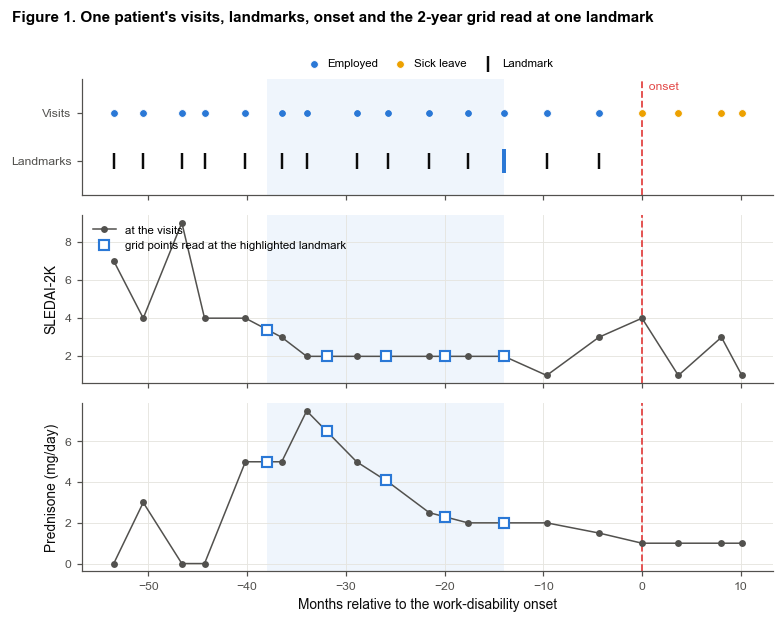

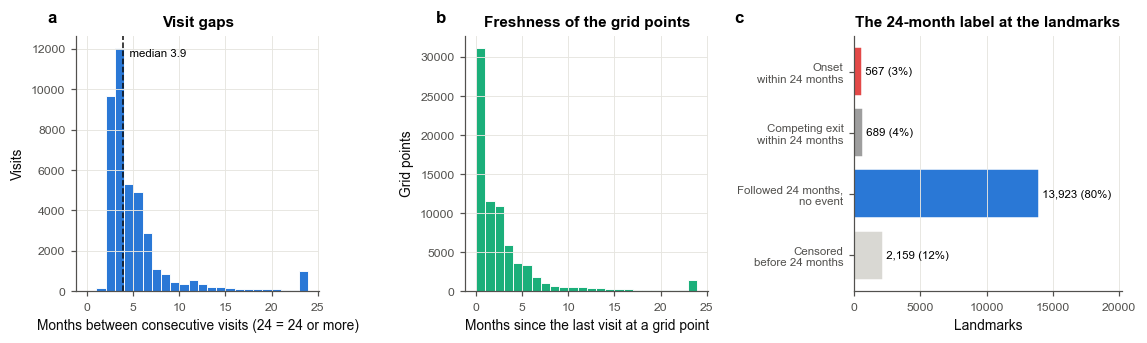

Example patient: 14 landmarks in the 6 years before the onset; highlighted landmark 14 months before the onset. Visit gaps: median 3.9 months, 90th percentile 9.0.


In [5]:
"""Figures 1-2: one patient's data handling; visit gaps, grid freshness and the 24-month label."""
_STATE_STYLE = {"W": ("Employed", "#2a78d6"), "S": ("Sick leave", "#eda100"), "D": ("Disabled", "#e34948"),
                "O": ("Other exit", "#9e9e9e"), "U": ("Not recorded", "#d9d8d3")}
_ev_pids = [p for p in FIRST_ONSET.index
            if (FIRST_ONSET[p] - visits.loc[_VIDX[p][0], "ASSDT"]).days > 4 * 365 and len(PT_ROWS.get(p, [])) >= 8]
EXAMPLE_PID = sorted(_ev_pids, key=lambda p: len(PT_ROWS[p]))[len(_ev_pids) // 2]
_vr = _VIDX[EXAMPLE_PID]
_pv = visits.iloc[_vr]
_e = FIRST_ONSET[EXAMPLE_PID]
_t0 = _e - pd.DateOffset(years=6)
_keep = (_pv["ASSDT"] >= _t0) & (_pv["ASSDT"] <= _e + pd.DateOffset(years=1))
_pv = _pv[_keep]
_li = PT_ROWS[EXAMPLE_PID]
_li = _li[(land["visit_date"].values[_li] >= np.datetime64(_t0)) & (land["visit_date"].values[_li] < np.datetime64(_e))]
_lshow = _li[np.argmin(np.abs((land["visit_date"].values[_li] - np.datetime64(_e - pd.DateOffset(months=12)))
                              / np.timedelta64(1, "D")))]                  # the landmark about a year before the onset
_gst, _gln = grid_window("24")
_gpts = GRID_RAW[_gst[_lshow]:_gst[_lshow] + _gln[_lshow]]
_gdates = land["visit_date"].values[_lshow] - (np.arange(_gln[_lshow])[::-1] * GRID_STEP_DAYS).astype("timedelta64[D]")

_rel = lambda d: (pd.to_datetime(np.asarray(d)) - _e).days.values / MONTH_DAYS if np.ndim(d) else \
    (pd.Timestamp(d) - _e).days / MONTH_DAYS                               # months relative to the onset (no dates shown)
_xl = _rel(land["visit_date"].values[_lshow])
fig, axes = plt.subplots(3, 1, figsize=(7.2, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.1, 1.6, 1.6]})
ax = axes[0]
for st_, (lab_, col_) in _STATE_STYLE.items():
    k = np.array([_state_of(e_) == st_ for e_ in _pv["EMP"].values])
    if k.any():
        ax.scatter(_rel(_pv["ASSDT"].values[k]), np.full(k.sum(), 1.0), s=26, color=col_, label=lab_, zorder=3,
                   edgecolor="white", linewidth=0.6)
ax.scatter(_rel(land["visit_date"].values[_li]), np.full(len(_li), 0.0), marker="|", s=120, color="#0b0b0b",
           label="Landmark", zorder=3)
ax.scatter([_xl], [0.0], marker="|", s=260, linewidths=2.6, color="#2a78d6", zorder=4)
ax.set_yticks([0, 1]); ax.set_yticklabels(["Landmarks", "Visits"]); ax.set_ylim(-0.7, 1.7); ax.grid(False)
ax.legend(ncol=6, loc="lower center", bbox_to_anchor=(0.5, 1.0), handletextpad=0.2, columnspacing=0.9)
for a_ in axes:
    a_.axvline(0, color="#e34948", lw=1.2, ls="--")
    a_.axvspan(_rel(_gdates[0]), _xl, color="#2a78d6", alpha=0.07, lw=0)
axes[0].text(0, 1.55, "  onset", color="#e34948", fontsize=8, va="center")
for ax, col, lab_ in [(axes[1], "SLEDAI2_I", "SLEDAI-2K"), (axes[2], "STERAVER_0", "Prednisone (mg/day)")]:
    ax.plot(_rel(_pv["ASSDT"].values), _pv[col].values.astype(float), "-o", color=INK_2, ms=3.5, lw=1,
            label="at the visits")
    ax.plot(_rel(_gdates), _gpts[:, GRID_COLS.index(col)], "s", mfc="white", mec="#2a78d6", mew=1.4, ms=6,
            label="grid points read at the highlighted landmark")
    ax.set_ylabel(lab_)
axes[1].legend(loc="upper left")
axes[2].set_xlabel("Months relative to the work-disability onset")
fig.suptitle("Figure 1. One patient's visits, landmarks, onset and the 2-year grid read at one landmark", x=0.02,
             ha="left", fontsize=10, fontweight="bold", y=1.0)
plt.tight_layout()
save_fig("fig01_data_handling_example")

_gap = (visits.groupby("PTNO")["ASSDT"].diff().dt.days / MONTH_DAYS).dropna()
_stale_pts = GRID_RAW[np.concatenate([np.arange(s_, s_ + l_) for s_, l_ in zip(*grid_window("24"))]),
                      GRID_COLS.index("GRID_STALE_MONTHS")]
rows_, y_, w_ = IPCW_H[H]
_lab_parts = {f"Onset\nwithin {H} months": int(((C_ALL == 1) & (T_ALL <= HORIZON_DAYS)).sum()),
              f"Competing exit\nwithin {H} months": int(((C_ALL >= 2) & (T_ALL <= HORIZON_DAYS)).sum()),
              f"Followed {H} months,\nno event": int((T_ALL > HORIZON_DAYS).sum()),
              f"Censored\nbefore {H} months": int(((C_ALL == 0) & (T_ALL <= HORIZON_DAYS)).sum())}
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2), gridspec_kw={"width_ratios": [1, 1, 1.1]})
ax = axes[0]
ax.hist(np.clip(_gap, 0, 24), bins=np.arange(0, 24.5, 1), color="#2a78d6", edgecolor="white", linewidth=0.6)
ax.axvline(np.median(_gap), color="#0b0b0b", lw=1, ls="--")
ax.text(np.median(_gap), ax.get_ylim()[1] * 0.92, f"  median {np.median(_gap):.1f}", fontsize=7.5)
ax.set_xlabel("Months between consecutive visits (24 = 24 or more)"); ax.set_ylabel("Visits"); ax.set_title("Visit gaps")
ax = axes[1]
ax.hist(np.clip(_stale_pts, 0, 24), bins=np.arange(0, 24.5, 1), color="#1baf7a", edgecolor="white", linewidth=0.6)
ax.set_xlabel("Months since the last visit at a grid point"); ax.set_ylabel("Grid points")
ax.set_title("Freshness of the grid points")
ax = axes[2]
_cols = ["#e34948", "#9e9e9e", "#2a78d6", "#d9d8d3"]
_vals = np.array(list(_lab_parts.values()))
ax.barh(range(4), _vals, color=_cols, edgecolor="white")
for i_, v_ in enumerate(_vals):
    ax.text(v_, i_, f" {v_:,} ({v_ / _vals.sum():.0%})", va="center", fontsize=7.5)
ax.set_yticks(range(4)); ax.set_yticklabels(list(_lab_parts), fontsize=7.5); ax.invert_yaxis()
ax.set_xlim(0, _vals.max() * 1.45); ax.set_xlabel("Landmarks"); ax.set_title(f"The {H}-month label at the landmarks")
ax.grid(axis="y", visible=False)
for a_, l_, dx in zip(axes, "abc", [-0.12, -0.12, -0.45]):
    panel_label(a_, l_, dx)
plt.tight_layout()
save_fig("fig02_visits_grid_label")
print(f"Example patient: {len(_li)} landmarks in the 6 years before the onset; highlighted landmark {-_xl:.0f} months "
      f"before the onset. Visit gaps: median {np.median(_gap):.1f} months, 90th percentile "
      f"{np.percentile(_gap, 90):.1f}.")

## 11.4 Preprocessing and the models

Fitted on the training patients of each fold only (Section 5). Tabular inputs (the regressions): signed log1p of
skewed variables, median imputation with a missing-value indicator, standardisation (the year-adjusted sensitivity
model also clips the calendar year to the training years). Grid inputs (the LSTM): the same at every grid point,
fitted on the grid points of the training landmarks.

* **Grid LSTM** (DYN): a one-layer LSTM over the landmark's window of grid points (the
  last 2 years); its last hidden state plus a skip connection of the landmark point's inputs give two log-hazards
  (onset, competing exit), fitted on the intervals between landmarks. (The code also holds band-hazard, pooled and
  offset forms; none of them is fitted here.)
* **Logistic regression** (LogReg): ridge logistic regression of the complete-case 24-month
  label (competing exit = 0, so the target is the cumulative incidence).
* **Poisson regressions** (the ladder, HazReg and its variants): ridge-penalised one-hazard models for onset and for a competing
  exit, fitted on the interval events with the exposure time as weight, so they also learn from the landmarks whose
  24-month label is unresolved (mostly the most recent ones).
* **Spline terms**: for the inputs in SPLINE_VARS, the nonlinear term of a 3-knot restricted cubic spline, with
  knots from the training fold (TabPrep).
* Risk at horizon *h* from the hazards (Section 4); an exclusive interval (a, b] uses the bands in it, starting from
  the patients still at risk at *a* (for the one-hazard models the ranking is nearly the same at every horizon; it
  is not identical because the competing hazard differs between patients).

In [6]:
"""Preprocessing, the cumulative incidence at any horizon, recalibration, thresholds and the model fit functions."""
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pack_sequence
from joblib import Parallel, delayed

torch.set_num_threads(max(1, (os.cpu_count() or 2) // 2))


def _expit(z):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, float)))


def _logit(p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def _slog1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


def cif(eta, months):
    """Cumulative incidence of onset by `months` under constant cause-specific hazards exp(eta[:, 0]), exp(eta[:, 1])
    (per year)."""
    l1, l2 = np.exp(np.clip(eta[:, 0], -30, 5)), np.exp(np.clip(eta[:, 1], -30, 5))
    tot = l1 + l2
    return l1 / tot * -np.expm1(-tot * months / 12.0)


def cif_band(eta, a, b):
    """Cumulative incidence of onset in (a, b] months among those at risk at a, piecewise-constant hazards per 6-month
    band: eta[:, :N_BANDS] onset, eta[:, N_BANDS:] competing exit (log per year)."""
    l1 = np.exp(np.clip(eta[:, :N_BANDS], -30, 5)); l2 = np.exp(np.clip(eta[:, N_BANDS:], -30, 5))
    tot = l1 + l2
    out, S = np.zeros(len(eta)), np.ones(len(eta))
    for k in range(N_BANDS):
        dt = (min((k + 1) * BAND_MONTHS, b) - max(k * BAND_MONTHS, a)) / 12.0
        if dt <= 0:
            continue
        out += S * l1[:, k] / tot[:, k] * -np.expm1(-tot[:, k] * dt)
        S *= np.exp(-tot[:, k] * dt)
    return out


def raw_logit(eta, months):
    """Logit of a model's uncalibrated risk at `months` (cumulative incidence)."""
    if eta.shape[1] == 2 * N_BANDS:
        return _logit(cif_band(eta, 0, months))
    return _logit(cif(eta, months)) if eta.shape[1] == 2 else eta[:, 0].astype(float)


def raw_logit_iv(eta, a, b):
    """Logit of the uncalibrated risk of onset in (a, b] months among those at risk at a."""
    if eta.shape[1] == 2 * N_BANDS:
        return _logit(cif_band(eta, a, b))
    return raw_logit(eta, b - a)


NO_YEAR_CLIP = False                           # True: the calendar year is not clipped at prediction (not used)


class TabPrep:
    """Training-fold preprocessing of the landmark matrix for `cols`; `spline` inputs also get the nonlinear term of a
    3-knot restricted cubic spline (knots at the training fold's 10th, 50th and 90th percentiles, after the log
    transform; the percentiles of the distinct values when ties make them coincide)."""

    def __init__(self, cols, spline=()):
        self.cols = list(cols)
        self.spline = [c for c in spline if c in self.cols]

    def _raw(self, X):
        Z = X[self.cols].astype(float).copy()
        for c in self.cols:
            if c in LOG1P_VARS:
                Z[c] = _slog1p(Z[c])
        return Z

    def _add_nl(self, Z):
        for c, kn in self.knots.items():
            Z[f"{c}__NL"] = cal_year_nl(Z[c].values, kn)
        return Z

    def fit(self, X):
        Z = self._raw(X)
        self.clip = {} if NO_YEAR_CLIP else {c: (Z[c].min(), Z[c].max()) for c in YEAR_COLS if c in self.cols}
        self.ind = [c for c in self.cols if LAND_X[c].isna().any()]
        self.med = Z.median()
        Zf = self._fill(Z)
        self.knots = {}
        for c in self.spline:
            x = Zf[c].values
            kn = np.percentile(x, [10, 50, 90])
            if not np.all(np.diff(kn) > 1e-9):
                kn = np.percentile(np.unique(x), [10, 50, 90])
            if np.all(np.diff(kn) > 1e-9):
                self.knots[c] = tuple(kn)
        Zf = self._add_nl(Zf)
        self.mu, self.sd = Zf.mean(), Zf.std().replace(0, 1.0).fillna(1.0)
        return self

    def _fill(self, Z):
        for c, (lo, hi) in self.clip.items():
            Z[c] = Z[c].clip(lo, hi)
        return Z.fillna(self.med)

    def transform(self, X):
        Z = self._raw(X)
        miss = Z[self.ind].isna().astype(float).values
        Z = self._add_nl(self._fill(Z))
        Z = ((Z - self.mu) / self.sd).clip(-CLIP_Z, CLIP_Z).values
        return np.hstack([Z, miss]).astype(np.float32)

    @property
    def names(self):
        return self.cols + [f"{c}__NL" for c in self.knots] + [f"{c}__MISSING" for c in self.ind]


class VisPrep:
    """Training-fold preprocessing of the visit table (fitted on the training patients' visits)."""

    def __init__(self, cols):
        self.cols = list(cols)
        self.ci = [SEQ_ALL_COLS.index(c) for c in self.cols]
        self.log = np.array([c in LOG1P_VARS for c in self.cols])
        self.miss = [k for k, c in enumerate(self.cols) if np.isnan(VIS_RAW[:, self.ci[k]]).any()]

    def _raw(self, A):
        Z = A[:, self.ci].astype(np.float32)
        Z[:, self.log] = _slog1p(Z[:, self.log])
        return Z

    def fit(self, pids, max_day=None):
        rows = np.concatenate([_VIDX[p] for p in pids])
        if max_day is not None:
            rows = rows[_VDAYS[rows] < max_day]
        Z = self._raw(VIS_RAW[rows])
        self.yr = {k: (np.nanmin(Z[:, k]), np.nanmax(Z[:, k])) for k, c in enumerate(self.cols) if c in YEAR_COLS}
        for k, (lo, hi) in self.yr.items():
            Z[:, k] = np.clip(Z[:, k], lo, hi)
        self.med = np.nan_to_num(np.nanmedian(Z, 0))
        Zf = np.where(np.isnan(Z), self.med, Z)
        self.mu, self.sd = Zf.mean(0), Zf.std(0)
        self.sd[self.sd == 0] = 1.0
        return self

    def transform(self, A):
        Z = self._raw(A)
        miss = np.isnan(Z[:, self.miss]).astype(np.float32)
        for k, (lo, hi) in self.yr.items():
            Z[:, k] = np.clip(Z[:, k], lo, hi)
        Z = np.where(np.isnan(Z), self.med, Z)
        Z = np.clip((Z - self.mu) / self.sd, -CLIP_Z, CLIP_Z)
        return np.hstack([Z, miss]).astype(np.float32)


class Recalibrator:
    """Logistic recalibration (intercept + slope on the logit)."""

    def fit(self, z, y, w=None):
        lr = LogisticRegression(C=1e6, max_iter=1000).fit(np.asarray(z, float)[:, None], np.asarray(y).astype(int),
                                                          sample_weight=w)
        self.a, self.b = float(lr.intercept_[0]), float(lr.coef_[0, 0])
        return self

    def transform_logit(self, z):
        return self.a + self.b * np.asarray(z, float)


def threshold_candidates(y, p):
    o = np.argsort(-p, kind="stable")
    ps, ys = p[o], y[o]
    tp, fp = np.cumsum(ys == 1), np.cumsum(ys == 0)
    last = np.r_[ps[1:] != ps[:-1], True]
    return np.r_[np.inf, ps[last]], np.r_[0, tp[last]], np.r_[0, fp[last]]


def choose_thresholds(y, p):
    """cost: max cost-weighted net benefit TP - FP / R with R = (1 - pi) / pi, which is the maximum of Youden's J
    (sensitivity + specificity - 1); ppv: the highest PPV among thresholds with sensitivity >= PPV_MIN_SENS."""
    y, p = np.asarray(y, int), np.asarray(p, float)
    cut, tp, fp = threshold_candidates(y, p)
    P, N = max(tp[-1], 1), max(fp[-1], 1)
    R = N / P
    out = {"cost": float(cut[int(np.argmax(tp - fp / R))])}
    sens = tp / P
    ppv = np.where(tp + fp > 0, tp / np.maximum(tp + fp, 1), 0.0)
    ok = np.flatnonzero(sens >= PPV_MIN_SENS)
    out["ppv"] = float(cut[ok[np.argmax(ppv[ok])]]) if len(ok) else float(cut[-1])
    return out


# ---------------------------------------------------------------- the LSTM
class PatNet(nn.Module):
    """LSTM over a patient's visits; outputs at the landmark visits. n_out = 1 (binary logit) or 2 (log-hazards)."""

    def __init__(self, n_in, hidden, dropout, n_out):
        super().__init__()
        self.rnn = nn.LSTM(n_in, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden + n_in, n_out)

    def forward(self, x_pad, lengths, pos_b, pos_t):
        packed = pack_padded_sequence(x_pad, lengths, batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x_pad.shape[1])
        return self.head(torch.cat([self.drop(out[pos_b, pos_t]), x_pad[pos_b, pos_t]], -1))


def _patient_batch(pids, VX):
    """Padded visit tensors of `pids`, landmark positions, landmark rows and the batch's 24-month pooling matrix."""
    lens = [len(SEQ_VROWS[p]) for p in pids]
    T = max(lens)
    x = np.zeros((len(pids), T, VX.shape[1]), np.float32)
    pos_b, pos_t, rows, pi, pk, pw = [], [], [], [], [], []
    off = 0
    for b, p in enumerate(pids):
        x[b, :lens[b]] = VX[SEQ_VROWS[p]]
        lp = SEQ_LPOS[p]
        pos_b.append(np.full(len(lp), b)); pos_t.append(lp); rows.append(PT_ROWS[p])
        i_, k_, w_ = PT_POOL[p]
        pi.append(i_ + off); pk.append(k_ + off); pw.append(w_)
        off += len(lp)
    pool = torch.sparse_coo_tensor(np.vstack([np.concatenate(pi), np.concatenate(pk)]),
                                   np.concatenate(pw), (off, off)).coalesce()
    return (torch.from_numpy(x), torch.tensor(lens), torch.from_numpy(np.concatenate(pos_b)),
            torch.from_numpy(np.concatenate(pos_t)), np.concatenate(rows), pool)


def _split_patients(pids, ev, share, rng):
    pick = np.zeros(len(pids), bool)
    for g in (True, False):
        ix = np.flatnonzero(ev == g)
        if len(ix):
            pick[rng.choice(ix, max(1, int(round(share * len(ix)))), replace=False)] = True
    return pick


def default_arrays():
    """The training targets; temporal validation passes versions truncated at the end of development."""
    return {"D1": D_ONSET, "D2": D_COMP, "DT": INT_YRS, "Y": Y_ALL, "LAB": LABELLED, "USE": np.ones(N_LAND, bool)}


def fit_seq(cfg, VX, target, pooled, fit_pids, seed, pred_pids, arrs=None):
    """Train one LSTM on the patients `fit_pids`; return (landmark rows, raw scores) for `pred_pids` (scores: the two
    log-hazards for TTE, the logit for BIN; pooled over 24 months if `pooled`). Only rows with arrs['USE'] carry loss."""
    A = arrs or default_arrays()
    torch.set_num_threads(1)
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    fit_pids = np.asarray(fit_pids)
    has = (lambda p: (A["USE"][PT_ROWS[p]] & A["LAB"][PT_ROWS[p]]).any()) if target == "BIN" else \
        (lambda p: A["USE"][PT_ROWS[p]].any())
    fit_pids = np.array([p for p in fit_pids if has(p)])
    ev = np.array([(A["D1"][PT_ROWS[p]] * A["USE"][PT_ROWS[p]]).sum() > 0 for p in fit_pids])
    va_mask = _split_patients(fit_pids, ev, SEQ_TRAIN["val_share"], rng)
    tr_pts, va_pts = fit_pids[~va_mask], fit_pids[va_mask]
    n_out = 2 if target == "TTE" else 1
    net = PatNet(VX.shape[1], cfg["hidden"], cfg["dropout"], n_out)
    tr_rows = np.concatenate([PT_ROWS[p] for p in tr_pts])
    tr_rows = tr_rows[A["USE"][tr_rows]]
    with torch.no_grad():                      # start at the training patients' crude rates / onset share
        if target == "TTE":
            yrs = A["DT"][tr_rows].sum()
            net.head.bias[:] = torch.tensor([np.log(max(A["D1"][tr_rows].sum(), 1) / yrs),
                                             np.log(max(A["D2"][tr_rows].sum(), 1) / yrs)])
        else:
            net.head.bias[:] = float(_logit(np.nanmean(A["Y"][tr_rows])))
    opt = torch.optim.AdamW(net.parameters(), lr=SEQ_TRAIN["lr"], weight_decay=cfg["weight_decay"])
    use_t = torch.from_numpy(A["USE"])

    def scores(pids_b):
        x, lens, pb, pt, rows, pool = _patient_batch(pids_b, VX)
        z = net(x, lens, pb, pt)
        if pooled:
            z = torch.sparse.mm(pool, z)
        return z, rows

    def loss_of(pids_b):
        z, rows = scores(pids_b)
        use = use_t[rows]
        if target == "TTE":
            eta = z.clamp(-20, 5)
            d1, d2 = torch.from_numpy(A["D1"][rows]), torch.from_numpy(A["D2"][rows])
            dt = torch.from_numpy(A["DT"][rows])
            nll = -(d1 * eta[:, 0] + d2 * eta[:, 1] - (torch.exp(eta[:, 0]) + torch.exp(eta[:, 1])) * dt)
            return nll[use].sum(), float(use.sum())
        lab = torch.from_numpy(A["LAB"][rows]) & use
        y = torch.from_numpy(np.nan_to_num(A["Y"][rows]).astype(np.float32))
        bce = nn.functional.binary_cross_entropy_with_logits(z[:, 0][lab], y[lab], reduction="sum")
        return bce, float(lab.sum())

    def val_loss():
        l_, n_ = 0.0, 0.0
        with torch.no_grad():
            for i in range(0, len(va_pts), 128):
                l, n = loss_of(va_pts[i:i + 128]); l_ += float(l); n_ += n
        return l_ / max(n_, 1.0)

    best, best_state, bad = np.inf, None, 0
    bp = SEQ_TRAIN["batch_patients"]
    for ep in range(SEQ_TRAIN["max_epochs"]):
        net.train()
        perm = rng.permutation(tr_pts)
        for i in range(0, len(perm), bp):
            l, n = loss_of(perm[i:i + bp])
            if n == 0:
                continue
            opt.zero_grad(); (l / n).backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
        net.eval()
        vl = val_loss()
        if vl < best - 1e-6:
            best, bad = vl, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= SEQ_TRAIN["patience"]:
                break
    net.load_state_dict(best_state)
    net.eval()
    rows_out, z_out = [], []
    with torch.no_grad():
        pred_pids = np.asarray(pred_pids)
        for i in range(0, len(pred_pids), 128):
            z, rows = scores(pred_pids[i:i + 128])
            z_out.append(z.numpy().astype(float)); rows_out.append(rows)
    if return_net:
        return np.concatenate(rows_out), np.concatenate(z_out), {k: v.clone() for k, v in net.state_dict().items()}
    return np.concatenate(rows_out), np.concatenate(z_out)


# ---------------------------------------------------------------- the grid LSTM (DYN)
class GridPrep:
    """Training-fold preprocessing of the grid points: signed log1p, calendar year clipped to the training years,
    median imputation + missing-value indicator, standardisation; fitted on the grid points of the training landmarks."""

    def __init__(self, cols=GRID_COLS):
        self.cols = list(cols)
        self.ci = [GRID_COLS.index(c) for c in self.cols]
        self.log = np.array([c in LOG1P_VARS for c in self.cols])
        self.miss = [k for k, c in enumerate(self.cols) if np.isnan(GRID_RAW[:, self.ci[k]]).any()]

    def _raw(self, A):
        Z = A[:, self.ci].astype(np.float32)
        Z[:, self.log] = _slog1p(Z[:, self.log])
        return Z

    def fit(self, land_rows, max_points=150_000, seed=SEED):
        pts = np.concatenate([np.arange(LG_START[i], LG_START[i] + LG_LEN[i]) for i in land_rows])
        if len(pts) > max_points:
            pts = np.random.RandomState(seed).choice(pts, max_points, replace=False)
        Z = self._raw(GRID_RAW[pts])
        self.yr = {k: (np.nanmin(Z[:, k]), np.nanmax(Z[:, k])) for k, c in enumerate(self.cols) if c in YEAR_COLS}
        for k, (lo, hi) in self.yr.items():
            Z[:, k] = np.clip(Z[:, k], lo, hi)
        self.med = np.nan_to_num(np.nanmedian(Z, 0))
        Zf = np.where(np.isnan(Z), self.med, Z)
        self.mu, self.sd = Zf.mean(0), Zf.std(0)
        self.sd[self.sd == 0] = 1.0
        return self

    def transform(self, A):
        Z = self._raw(A)
        miss = np.isnan(Z[:, self.miss]).astype(np.float32)
        for k, (lo, hi) in self.yr.items():
            Z[:, k] = np.clip(Z[:, k], lo, hi)
        Z = np.where(np.isnan(Z), self.med, Z)
        Z = np.clip((Z - self.mu) / self.sd, -CLIP_Z, CLIP_Z)
        return np.hstack([Z, miss]).astype(np.float32)

    @property
    def names(self):
        return self.cols + [f"{self.cols[k]}__MISSING" for k in self.miss]


class GridNet(nn.Module):
    """LSTM over a landmark's window of grid points; two log-hazards from its last hidden state + the landmark point."""

    def __init__(self, n_in, hidden, dropout, n_out=2):
        super().__init__()
        self.rnn = nn.LSTM(n_in, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden + n_in, n_out)

    def forward(self, packed, x_last):
        _, (h, _) = self.rnn(packed)
        return self.head(torch.cat([self.drop(h[-1]), x_last], -1))


def _grid_batch(pids, VX, st, ln):
    """Packed grid windows of every landmark of `pids`, the landmark points, the landmark rows and the batch's
    24-month pooling matrix."""
    rows, pi, pk, pw = [], [], [], []
    off = 0
    for p in pids:
        r = PT_ROWS[p]
        i_, k_, w_ = PT_POOL[p]
        rows.append(r); pi.append(i_ + off); pk.append(k_ + off); pw.append(w_)
        off += len(r)
    rows = np.concatenate(rows)
    seqs = [torch.from_numpy(np.array(VX[st[i]:st[i] + ln[i]])) for i in rows]
    x_last = torch.from_numpy(np.array(VX[st[rows] + ln[rows] - 1]))
    pool = torch.sparse_coo_tensor(np.vstack([np.concatenate(pi), np.concatenate(pk)]),
                                   np.concatenate(pw), (off, off)).coalesce()
    return pack_sequence(seqs, enforce_sorted=False), x_last, rows, pool


def fit_grid(cfg, VX, st, ln, fit_pids, seed, pred_pids, hazard="band", pooled=False, offset=None, return_net=False,
             arrs=None):
    """Train one grid LSTM on the patients `fit_pids`, reading the window (st, ln) of each landmark; return (landmark
    rows, log-hazards incl. the offset) for `pred_pids`. hazard 'const': 2 log-hazards on the intervals between
    landmarks (pooled over 24 months if `pooled`); 'band': 2 x N_BANDS log-hazards on the landmark's follow-up to
    48 months. offset: (N_LAND, 2) fixed log-hazards added to every band (two-part model). arrs: one-hazard targets
    truncated at the end of development (temporal hold-out; only rows with arrs['USE'] carry loss)."""
    torch.set_num_threads(1)
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    A = arrs or default_arrays()
    assert arrs is None or hazard == "const", "truncated targets are implemented for the one-hazard models only"
    fit_pids = np.asarray(fit_pids)
    fit_pids = np.array([p for p in fit_pids if A["USE"][PT_ROWS[p]].any()])
    ev = np.array([(A["D1"][PT_ROWS[p]] * A["USE"][PT_ROWS[p]]).sum() > 0 for p in fit_pids])
    va_mask = _split_patients(fit_pids, ev, SEQ_TRAIN["val_share"], rng)
    tr_pts, va_pts = fit_pids[~va_mask], fit_pids[va_mask]
    band = hazard == "band"
    nb = N_BANDS if band else 1
    net = GridNet(VX.shape[1], cfg["hidden"], cfg["dropout"], n_out=2 * nb)
    tr_rows = np.concatenate([PT_ROWS[p] for p in tr_pts])
    tr_rows = tr_rows[A["USE"][tr_rows]]
    off_t = torch.from_numpy(np.zeros((N_LAND, 2), np.float32) if offset is None else offset.astype(np.float32))
    with torch.no_grad():                      # start at the training patients' crude rates (net of the offset)
        if band:
            yrs = np.maximum(BAND_DT[tr_rows].sum(0), 1e-6)
            r1 = np.log(np.maximum(BAND_D1[tr_rows].sum(0), 1) / yrs); r2 = np.log(np.maximum(BAND_D2[tr_rows].sum(0), 1) / yrs)
        else:
            yrs = A["DT"][tr_rows].sum()
            r1 = np.log([max(A["D1"][tr_rows].sum(), 1) / yrs]); r2 = np.log([max(A["D2"][tr_rows].sum(), 1) / yrs])
        if offset is not None:
            r1 = r1 - offset[tr_rows, 0].mean(); r2 = r2 - offset[tr_rows, 1].mean()
        net.head.bias[:] = torch.tensor(np.r_[r1, r2], dtype=torch.float32)
    opt = torch.optim.AdamW(net.parameters(), lr=SEQ_TRAIN["lr"], weight_decay=cfg["weight_decay"])

    def scores(pids_b):
        packed, x_last, rows, pool = _grid_batch(pids_b, VX, st, ln)
        z = net(packed, x_last)
        if pooled:
            z = torch.sparse.mm(pool, z)
        o = off_t[rows]
        z = torch.cat([z[:, :nb] + o[:, :1], z[:, nb:] + o[:, 1:]], 1)
        return z, rows

    def loss_of(pids_b):
        z, rows = scores(pids_b)
        eta = z.clamp(-20, 5)
        if band:
            d1, d2, dt = (torch.from_numpy(a_[rows]) for a_ in (BAND_D1, BAND_D2, BAND_DT))
            nll = -(d1 * eta[:, :nb] + d2 * eta[:, nb:] - (torch.exp(eta[:, :nb]) + torch.exp(eta[:, nb:])) * dt)
            return nll.sum(), float(len(rows))
        d1, d2, dt = (torch.from_numpy(np.asarray(a_[rows], np.float32)) for a_ in (A["D1"], A["D2"], A["DT"]))
        u = torch.from_numpy(A["USE"][rows].astype(np.float32))
        nll = -(d1 * eta[:, 0] + d2 * eta[:, 1] - (torch.exp(eta[:, 0]) + torch.exp(eta[:, 1])) * dt) * u
        return nll.sum(), float(u.sum())

    def val_loss():
        l_, n_ = 0.0, 0.0
        with torch.no_grad():
            for i in range(0, len(va_pts), 128):
                l, n = loss_of(va_pts[i:i + 128]); l_ += float(l); n_ += n
        return l_ / max(n_, 1.0)

    best, best_state, bad = np.inf, None, 0
    bp = SEQ_TRAIN["batch_patients"]
    for ep in range(SEQ_TRAIN["max_epochs"]):
        net.train()
        perm = rng.permutation(tr_pts)
        for i in range(0, len(perm), bp):
            l, n = loss_of(perm[i:i + bp])
            opt.zero_grad(); (l / n).backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
        net.eval()
        vl = val_loss()
        if vl < best - 1e-6:
            best, bad = vl, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= SEQ_TRAIN["patience"]:
                break
    net.load_state_dict(best_state)
    net.eval()
    rows_out, z_out = [], []
    with torch.no_grad():
        pred_pids = np.asarray(pred_pids)
        for i in range(0, len(pred_pids), 128):
            z, rows = scores(pred_pids[i:i + 128])
            z_out.append(z.numpy().astype(float)); rows_out.append(rows)
    if return_net:
        return np.concatenate(rows_out), np.concatenate(z_out), {k: v.clone() for k, v in net.state_dict().items()}
    return np.concatenate(rows_out), np.concatenate(z_out)


# ---------------------------------------------------------------- the regressions
def reg_design(model, prep, rows):
    """Standardised regression inputs at `rows` (whole patients); Pk: their k-month running mean."""
    X = prep.transform(LAND_X.iloc[rows])
    k = parse_model(model)["pool"]
    if k > 0:
        X = np.asarray(POOLS[k][rows][:, rows] @ X, np.float32)
    return X


def fit_reg(model, cfg, prep_rows, fit_rows, pred_rows, arrs=None):
    """Fit a regression on the (whole-patient) rows fit_rows; loss on the rows with arrs['USE']. Returns the raw scores
    at pred_rows (n x 2 log-hazards for TTE, n x 1 logit for BIN) and (prep, fitted models)."""
    A = arrs or default_arrays()
    t = parse_model(model)["target"]
    prep = make_prep(model).fit(LAND_X.iloc[prep_rows])
    X, Xp = reg_design(model, prep, fit_rows), reg_design(model, prep, pred_rows)
    use = A["USE"][fit_rows]
    if t == "BIN":
        k = use & A["LAB"][fit_rows]
        m = LogisticRegression(C=cfg["C"], max_iter=3000).fit(X[k], A["Y"][fit_rows][k].astype(int))
        return m.decision_function(Xp)[:, None], (prep, [m])
    if is_band(model):
        return _fit_reg_band(cfg, prep, X[use], Xp, fit_rows[use])
    dt = A["DT"][fit_rows].astype(float)
    fits = [PoissonRegressor(alpha=cfg["alpha"], max_iter=3000).fit(X[use], (d[fit_rows] / np.maximum(dt, 1e-9))[use],
                                                                    sample_weight=dt[use])
            for d in (A["D1"], A["D2"])]
    eta = np.column_stack([np.log(np.maximum(f_.predict(Xp), 1e-12)) for f_ in fits])
    return eta, (prep, fits)


BAND_SCALE = 10.0                              # band indicators scaled up so the ridge penalty barely touches them


def _fit_reg_band(cfg, prep, X, Xp, fit_rows):
    """Band-hazard ridge Poisson regressions: one row per (landmark, band) with exposure; band indicators + inputs."""
    dt = BAND_DT[fit_rows]
    li, bi = np.nonzero(dt > 0)
    E = np.eye(N_BANDS, dtype=np.float32)[bi] * BAND_SCALE
    Xe = np.hstack([X[li], E])
    w = dt[li, bi].astype(float)
    fits = []
    for D in (BAND_D1, BAND_D2):
        y = D[fit_rows][li, bi] / np.maximum(w, 1e-9)
        fits.append(PoissonRegressor(alpha=cfg["alpha"], max_iter=3000).fit(Xe, y, sample_weight=w))
    eta = np.hstack([(Xp @ f_.coef_[:-N_BANDS] + f_.intercept_)[:, None] + BAND_SCALE * f_.coef_[-N_BANDS:][None, :]
                     for f_ in fits])
    return eta, (prep, fits)


def fit_unit(model, prep_rows, pred_rows):
    """The unit-weighted score: the sum of the standardised inputs (training-fold preprocessing; nothing estimated
    from the outcome). Its scale is set by the per-fold recalibration (Section 7)."""
    prep = make_prep(model).fit(LAND_X.iloc[prep_rows])
    X = prep.transform(LAND_X.iloc[pred_rows])[:, :len(prep.cols)]
    return X.sum(1)[:, None], prep


def model_grid(model):
    if is_unit(model):
        return {"fixed": {}}
    if is_reg(model):
        if parse_model(model)["target"] == "BIN":
            return {f"C{c:g}": {"C": c} for c in LOGREG_C_GRID}
        return {f"a{a:g}": {"alpha": a} for a in POISSON_ALPHA_GRID}
    return {"fixed": SEQ_CFG}

## 11.5 Repeated cross-validation

5 × 5-fold, patient-grouped, stratified by whether the patient ever has an onset (fixed seeds, so the folds are the
same for every model). Inside each training fold, 3 patient-grouped inner folds give out-of-fold (OOF) scores at
every landmark of every training patient; they are kept for the recalibration and thresholds of Section 11.6, which
are learned per horizon on the training fold only. The regressions choose their penalty on the inner OOF log-loss
(logistic) or Poisson deviance (hazard); the LSTMs have one fixed configuration (nothing is tuned) and are refitted on the whole training fold
(5 seeds) to score the test fold. Every fit is checkpointed in `cv_state_update_v17.pkl`, so an interrupted run
resumes where it stopped.

In [7]:
"""The cross-validation engine."""
ALL_PIDS = np.array(sorted(land["pid"].unique()))
PID_EVENT = land.groupby("pid")["pt_event"].max().reindex(ALL_PIDS).values
PID_INDEX = {p: i for i, p in enumerate(ALL_PIDS)}
ROW_PIDX = np.array([PID_INDEX[p] for p in PID_ALL])


def patient_folds(pids, n_splits, seed):
    from sklearn.model_selection import StratifiedKFold
    ev = PID_EVENT[[PID_INDEX[p] for p in pids]]
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return [(pids[a], pids[b]) for a, b in skf.split(np.zeros(len(pids)), ev)]


OUTER = {r: patient_folds(ALL_PIDS, CV_N_SPLITS, SEED + 1000 * r) for r in range(CV_N_REPEATS)}


def rows_of(pids):
    return np.flatnonzero(np.isin(PID_ALL, pids))


def _load(path, empty):
    if os.path.exists(path):
        with open(path, "rb") as f:
            return pickle.load(f)
    return empty


def _save(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "wb") as f:
        pickle.dump(obj, f)
    os.replace(tmp, path)


cv_state = _load(CV_STATE_PATH, {"folds": {}})
def tune_score(model, oof, tr_rows, tr_lab):
    """The inner-fold criterion that chooses a regression's penalty (higher is better): minus the log-loss of the
    24-month label (logistic models), minus the Poisson deviance of both causes over the at-risk intervals (hazard
    models)."""
    if parse_model(model)["target"] == "BIN":
        z = oof[tr_lab, 0].astype(float)
        y = Y_ALL[tr_lab].astype(float)
        return -float(np.mean(np.logaddexp(0, z) - y * z))
    eta = np.clip(oof[tr_rows].astype(float), -30, 5)
    dt = INT_YRS[tr_rows].astype(float)
    nll = sum(np.exp(eta[:, j]) * dt - d[tr_rows] * eta[:, j] for j, d in enumerate((D_ONSET, D_COMP)))
    return -float(np.nansum(nll))


def fit_and_score(model, r, f, tr_p, te_p, tr_rows, tr_lab, te_rows, inner):
    """Tune (regression) on inner OOF scores, refit on the whole training fold and score te_rows. Returns the raw
    scores of the test rows and the OOF raw scores of the training rows."""
    t0 = time.time()
    grid = model_grid(model)
    d = parse_model(model)
    k_out = 2 * N_BANDS if d["hazard"] == "band" else 1 if d["target"] == "BIN" else 2
    oofs, coef = {}, None
    if is_grid(model):
        sets = [(a_p, b_p) for a_p, b_p in inner] + [(tr_p, te_p)]
        st, ln = grid_window(d["lookback"])
        VXs = [GridPrep(grid_cols_of(model)).fit(rows_of(a_p)).transform(GRID_RAW) for a_p, _ in sets]
        offs = [None] * len(sets)
        if d["offset"] == "trait":              # Index-3 fitted on each set's training patients
            for j, (a_p, b_p) in enumerate(sets):
                a_r, all_r = rows_of(a_p), rows_of(np.r_[a_p, b_p])
                o = np.zeros((N_LAND, 2), np.float32)
                o[all_r] = fit_reg(INDEX3, {"alpha": TRAIT_ALPHA}, a_r, a_r, all_r)[0]
                offs[j] = o
        k_out = 2 * N_BANDS if d["hazard"] == "band" else 2
        tasks = []
        for j, (a_p, b_p) in enumerate(sets):
            n = SEQ_SEEDS_FINAL if j == len(sets) - 1 else SEQ_SEEDS_INNER
            for s in range(n):
                tasks.append((j, delayed(fit_grid)(grid["fixed"], VXs[j], st, ln, a_p,
                                                   SEED + 1000 * j + 31 * s + 7 * r + f, b_p, d["hazard"],
                                                   d["pool"] > 0, offs[j])))
        res = Parallel(n_jobs=SEQ_N_JOBS, backend="loky")([t_[1] for t_ in tasks])
        z = [np.zeros((N_LAND, k_out)) for _ in sets]; cnt = [np.zeros(N_LAND) for _ in sets]
        for (j, _), (rows, zz) in zip(tasks, res):
            z[j][rows] += zz; cnt[j][rows] += 1
        oof = np.full((N_LAND, k_out), np.nan)
        for j in range(len(inner)):
            k = cnt[j] > 0
            oof[k] = z[j][k] / cnt[j][k][:, None]
        oofs["fixed"] = oof
        best = "fixed"
        eta_te = z[-1][te_rows] / np.maximum(cnt[-1][te_rows], 1)[:, None]
    elif is_unit(model):
        oof = np.full((N_LAND, 1), np.nan)
        for a_p, b_p in inner:
            oof[rows_of(b_p)] = fit_unit(model, rows_of(a_p), rows_of(b_p))[0]
        oofs["fixed"], best = oof, "fixed"
        eta_te = fit_unit(model, tr_rows, te_rows)[0]
    elif is_seq(model):
        sets = [(a_p, b_p) for a_p, b_p in inner] + [(tr_p, te_p)]
        VXs = [VisPrep(seq_cols_of(model)).fit(a_p).transform(VIS_RAW) for a_p, _ in sets]
        tasks = []
        for j, (a_p, b_p) in enumerate(sets):
            n = SEQ_SEEDS_FINAL if j == len(sets) - 1 else SEQ_SEEDS_INNER
            for s in range(n):
                tasks.append((j, delayed(fit_seq)(grid["fixed"], VXs[j], d["target"], d["pool"] > 0, a_p,
                                                  SEED + 1000 * j + 31 * s + 7 * r + f, b_p)))
        res = Parallel(n_jobs=SEQ_N_JOBS, backend="loky")([t_[1] for t_ in tasks])
        z = [np.zeros((N_LAND, k_out)) for _ in sets]; cnt = [np.zeros(N_LAND) for _ in sets]
        for (j, _), (rows, zz) in zip(tasks, res):
            z[j][rows] += zz; cnt[j][rows] += 1
        oof = np.full((N_LAND, k_out), np.nan)
        for j in range(len(inner)):
            k = cnt[j] > 0
            oof[k] = z[j][k] / cnt[j][k][:, None]
        oofs["fixed"] = oof
        best = "fixed"
        eta_te = z[-1][te_rows] / np.maximum(cnt[-1][te_rows], 1)[:, None]
    else:
        prep_rows_of = (lambda rows: rows[LABELLED[rows]]) if d["target"] == "BIN" else (lambda rows: rows)
        for name, cfg in grid.items():
            oof = np.full((N_LAND, k_out), np.nan)
            for a_p, b_p in inner:
                a, b = rows_of(a_p), rows_of(b_p)
                oof[b] = fit_reg(model, cfg, prep_rows_of(a), a, b)[0]
            oofs[name] = oof
        scores = {name: tune_score(model, o, tr_rows, tr_lab) for name, o in oofs.items()}
        best = max(scores, key=scores.get)
        eta_te, (prep, fits) = fit_reg(model, grid[best], prep_rows_of(tr_rows), tr_rows, te_rows)
        coef = {"names": prep.names, "coef": np.vstack([f_.coef_.ravel() for f_ in fits])}
    return {"model": model, "best": best, "te_rows": te_rows, "eta_te": eta_te.astype(np.float32),
            "tr_rows": tr_rows, "eta_oof": oofs[best][tr_rows].astype(np.float32), "coef": coef,
            "seconds": time.time() - t0}


def run_fold(model, r, f):
    tr_p, te_p = OUTER[r][f]
    tr_rows, te_rows = rows_of(tr_p), rows_of(te_p)
    tr_lab = tr_rows[LABELLED[tr_rows]]
    inner = patient_folds(tr_p, CV_INNER_SPLITS, SEED + 7 * r + 13 * f)
    res = fit_and_score(model, r, f, tr_p, te_p, tr_rows, tr_lab, te_rows, inner)
    res.update({"r": r, "f": f})
    return res


def run_cv(models=tuple(FIT_MODELS)):
    for model in models:
        for r in range(CV_N_REPEATS):
            for f in range(CV_N_SPLITS):
                key = (model, r, f)
                if key in cv_state["folds"]:
                    continue
                res = run_fold(model, r, f)
                cv_state["folds"][key] = res
                _save(cv_state, CV_STATE_PATH)
                print(f"  {short_label(model):<14} repeat {r + 1} fold {f + 1}: {res['best']:<8} | "
                      f"{res['seconds'] / 60:.1f} min", flush=True)


# The regressions and the unit score first (fast), then the main LSTM, then the other LSTMs
t_cv = time.time()
run_cv([m for m in FIT_MODELS if is_reg(m) or is_unit(m)] + [MAIN_MODEL]
       + [m for m in FIT_MODELS if is_grid(m) and m != MAIN_MODEL])
print(f"Cross-validation complete: {len(cv_state['folds'])} fits ({(time.time() - t_cv) / 60:.1f} min this session)")
for m in NEW_MODELS:
    sec = [cv_state["folds"][(m, r, f)]["seconds"] for r in range(CV_N_REPEATS) for f in range(CV_N_SPLITS)
           if (m, r, f) in cv_state["folds"]]
    if sec:
        print(f"  {short_label(m):<11} {len(sec)} folds, median {np.median(sec) / 60:.1f} min per fold")

  L1 Demographics repeat 1 fold 1: a0.0003  | 0.0 min
  L1 Demographics repeat 1 fold 2: a0.001   | 0.0 min
  L1 Demographics repeat 1 fold 3: a0.0001  | 0.0 min
  L1 Demographics repeat 1 fold 4: a0.0003  | 0.0 min
  L1 Demographics repeat 1 fold 5: a0.0003  | 0.0 min
  L1 Demographics repeat 2 fold 1: a0.0003  | 0.0 min
  L1 Demographics repeat 2 fold 2: a0.0003  | 0.0 min
  L1 Demographics repeat 2 fold 3: a0.0003  | 0.0 min
  L1 Demographics repeat 2 fold 4: a0.0001  | 0.0 min
  L1 Demographics repeat 2 fold 5: a0.0003  | 0.0 min
  L1 Demographics repeat 3 fold 1: a0.001   | 0.0 min
  L1 Demographics repeat 3 fold 2: a0.0003  | 0.0 min
  L1 Demographics repeat 3 fold 3: a0.0003  | 0.0 min
  L1 Demographics repeat 3 fold 4: a0.0001  | 0.0 min
  L1 Demographics repeat 3 fold 5: a0.001   | 0.0 min
  L1 Demographics repeat 4 fold 1: a0.0003  | 0.0 min
  L1 Demographics repeat 4 fold 2: a0.0003  | 0.0 min
  L1 Demographics repeat 4 fold 3: a0.0003  | 0.0 min
  L1 Demographics repeat 4 f

## 11.6 Recalibration, thresholds and patient scores at every horizon

For each fit and each horizon *h* (6-48 months), **inside the training fold**:

1. the model's raw *h*-month risk (the cumulative incidence for the survival models; the 24-month logit for LogReg) is
   recalibrated by a logistic regression of the complete-case *h*-month label on its logit, fitted on the training
   patients' OOF scores, and the same map is applied to the test fold;
2. the **visit alarm threshold** is chosen on the training patients' recalibrated OOF risks (max Youden, Section
   7; max PPV as an alternative);
3. each training patient's **patient score** (the mean logit of the recalibrated risk over the patient's window,
   Section 9) gives the **patient threshold** and a logistic map from patient score to the probability of being
   an event patient (patient-level calibration).

Exclusive intervals (a, b]: the raw risk of an onset in (a, b] among those at risk at *a* (from the bands in the
interval; for the one-hazard models the cumulative incidence over the interval's length, whose ranking is nearly,
but not exactly, the same at every horizon because the competing hazard also varies between patients) is
recalibrated on the training landmarks still at risk at *a*. LogReg has one 24-month logit, recalibrated separately
for each horizon.

In [8]:
"""Per-fold recalibration and thresholds at every horizon; pooled test-fold predictions."""
ALL_FOLDS = dict(cv_state["folds"])
COMPLETE = {m: [r for r in range(CV_N_REPEATS) if all((m, r, f) in ALL_FOLDS for f in range(CV_N_SPLITS))]
            for m in FIT_MODELS}
MODELS_RUN = [m for m in FIT_MODELS if COMPLETE[m]]
REPEATS = sorted(set.intersection(*[set(COMPLETE[m]) for m in MODELS_RUN]))
if AVG_PARTS and all(m in MODELS_RUN for m in AVG_PARTS):
    MODELS_RUN.append(AVG_MODEL)
BEST_CFG = {m: [ALL_FOLDS[(m, r, f)]["best"] for r in REPEATS for f in range(CV_N_SPLITS)] for m in FIT_MODELS
            if m in MODELS_RUN}
print(f"Models with complete repeats: {len(MODELS_RUN)} | repeats used: {len(REPEATS)}")
for m in [m for m in MODELS_RUN if m != AVG_MODEL and is_reg(m)]:
    print(f"  {short_label(m):<14} penalty chosen: " + ", ".join(
        f"{k} x{v}" for k, v in pd.Series(BEST_CFG[m]).value_counts().items()))


def label_interval(a, b):
    """Complete-case label for an onset in (a, b] among landmarks at risk at a (NaN: not at risk or unresolved)."""
    lo, hi = hdays(a), hdays(b)
    lab = np.where((C_ALL == 1) & (T_ALL <= hi), 1.0, np.where((T_ALL > hi) | (C_ALL >= 2), 0.0, np.nan))
    lab[T_ALL <= lo] = np.nan
    lab[_ADMIN < hi] = np.nan
    return lab


LABEL_INT = {iv: label_interval(*iv) for iv in INTERVALS}
TARGETS_ = [("h", h) for h in HORIZONS] + [("iv",) + iv for iv in INTERVALS]


def _target_label(tg):
    return LABEL_H[tg[1]] if tg[0] == "h" else LABEL_INT[(tg[1], tg[2])]


def _target_months(tg):
    return tg[1] if tg[0] == "h" else tg[2] - tg[1]


_FOLD_CAL = {}


def fold_cal(m, r, f, tg):
    """(training rows, recalibrated OOF logits there, test rows, recalibrated test logits) for target tg."""
    key = (m, r, f, tg)
    if key in _FOLD_CAL:
        return _FOLD_CAL[key]
    if m == AVG_MODEL:
        parts = [fold_cal(p, r, f, tg) for p in AVG_PARTS]
        out = (parts[0][0], np.mean([p_[1] for p_ in parts], 0), parts[0][2], np.mean([p_[3] for p_ in parts], 0))
    else:
        res = ALL_FOLDS[(m, r, f)]
        eo, et = res["eta_oof"].astype(float), res["eta_te"].astype(float)
        if tg[0] == "h":
            zo, zt = raw_logit(eo, tg[1]), raw_logit(et, tg[1])
        else:
            zo, zt = raw_logit_iv(eo, tg[1], tg[2]), raw_logit_iv(et, tg[1], tg[2])
        lab = _target_label(tg)[res["tr_rows"]]
        k = ~np.isnan(lab) & ~np.isnan(zo)
        cal = Recalibrator().fit(zo[k], lab[k])
        out = (res["tr_rows"], cal.transform_logit(zo), res["te_rows"], cal.transform_logit(zt))
    _FOLD_CAL[key] = out
    return out


def run2_score(z, rows_list):
    """Highest logit reached at 2 consecutive landmarks of each window (the single landmark if only one)."""
    return np.array([z[r][0] if len(r) == 1 else np.minimum(z[r][1:], z[r][:-1]).max() for r in rows_list])


PRED, THR_V, THR_P, PCAL, THR_RUN2, OOF_H = {}, {}, {}, {}, {}, {}
t0 = time.time()
for m in MODELS_RUN:
    for r in REPEATS:
        for tg in TARGETS_:
            z_full = np.full(N_LAND, np.nan)
            tv = {c: np.full(N_LAND, np.nan) for c in THRESHOLD_RULES}
            tp = {c: np.full(N_LAND, np.nan) for c in THRESHOLD_RULES}
            pa, pb = np.full(N_LAND, np.nan), np.full(N_LAND, np.nan)
            t2 = {c: np.full(N_LAND, np.nan) for c in THRESHOLD_RULES}
            for f in range(CV_N_SPLITS):
                tr, zo, te, zt = fold_cal(m, r, f, tg)
                z_full[te] = zt
                if tg == ("h", H):
                    OOF_H[(m, r, f)] = (tr, zo)
                if tg[0] != "h":
                    continue
                h = tg[1]
                lab = LABEL_H[h][tr]
                k = ~np.isnan(lab)
                thr = choose_thresholds(lab[k], zo[k])
                for c in THRESHOLD_RULES:
                    tv[c][te] = thr[c]
                # patient level: the training patients' windows, scored with their OOF risks
                W = PTW[h]
                oof = np.full(N_LAND, np.nan); oof[tr] = zo
                in_tr = np.isin(W["pids"], OUTER[r][f][0])
                s = np.asarray(W["mat"][in_tr] @ np.nan_to_num(oof)).ravel()
                ev = W["event"][in_tr]
                thr_p = choose_thresholds(ev, s)
                pc = Recalibrator().fit(s, ev)
                for c in THRESHOLD_RULES:
                    tp[c][te] = thr_p[c]
                pa[te], pb[te] = pc.a, pc.b
                if h == H:
                    s2 = run2_score(oof, [W["rows"][i] for i in np.flatnonzero(in_tr)])
                    thr2 = choose_thresholds(ev, s2)
                    for c in THRESHOLD_RULES:
                        t2[c][te] = thr2[c]
            PRED.setdefault(m, {}).setdefault(r, {})[tg] = z_full
            if tg[0] == "h":
                THR_V.setdefault(m, {}).setdefault(r, {})[tg[1]] = tv
                THR_P.setdefault(m, {}).setdefault(r, {})[tg[1]] = tp
                PCAL.setdefault(m, {}).setdefault(r, {})[tg[1]] = (pa, pb)
                if tg[1] == H:
                    THR_RUN2.setdefault(m, {})[r] = t2
_FOLD_CAL.clear()
print(f"Recalibration and thresholds at {len(HORIZONS)} horizons and {len(INTERVALS)} intervals: "
      f"{(time.time() - t0) / 60:.1f} min")


def zpred(m, r, h=H):
    return PRED[m][r][("h", h)]


def mean_z(m, h=H):
    return np.nanmean(np.vstack([zpred(m, r, h) for r in REPEATS]), 0)


def patient_score_rs(m, z):
    """Risk-set score at every landmark: the model's own score (pooled models already average 24 months; the others
    are NOT averaged, so a recent change can count)."""
    return z

Models with complete repeats: 9 | repeats used: 5
  L1 Demographics penalty chosen: a0.0003 x15, a0.001 x5, a0.0001 x5
  L2 First visit penalty chosen: a0.003 x18, a0.001 x4, a0.01 x3
  HazReg         penalty chosen: a0.001 x23, a0.0003 x2
  LogReg         penalty chosen: C0.003 x19, C0.01 x4, C0.1 x2
  HazReg linear  penalty chosen: a0.001 x20, a0.0003 x4, a0.003 x1
  HazReg + year  penalty chosen: a0.001 x25
  HazReg wide    penalty chosen: a0.003 x25
Recalibration and thresholds at 8 horizons and 4 intervals: 0.4 min


## 11.6b What the hazards look like

The survival models predict hazards, not risks (Section 4). **Figure 3** shows them on the held-out predictions
(each landmark scored by a model that never saw the patient; mean over the CV repeats):

* **(a) Hazard by time since the visit.** The observed onset and competing-exit rates (events per 100
  person-years) in each 6-month band after the landmark, pooled over all landmarks (95 % exact Poisson CI), against
  the mean hazard DYN assigns to that band (exposure-weighted): DYN assumes one constant hazard from the visit
  onwards, so a flat observed rate supports the assumption. Overlapping follow-up of successive landmarks is counted
  for each landmark.
* **(b) How spread out the hazards are.** DYN's onset hazard across landmarks (log scale), separately for landmarks
  followed by an onset within 24 months and the rest.
* **(c) From hazards to risk.** Landmarks in fifths of DYN's onset hazard: the cumulative incidence implied by the
  two constant hazards (lines; raw, before recalibration) against the observed cumulative incidence at 6-48 months
  (IPCW; points with an approximate 95 % CI that treats landmarks as independent). If the constant-hazard extrapolation holds, the points follow the lines; a systematic
  gap is what the recalibration (Section 7) corrects at the 24-month horizon.
* **(d) Within a patient.** DYN's onset hazard is a step function that changes at every visit: the hazard at each
  landmark of the example patient of Figure 1 before their onset, against a patient of similar age who stays at work.

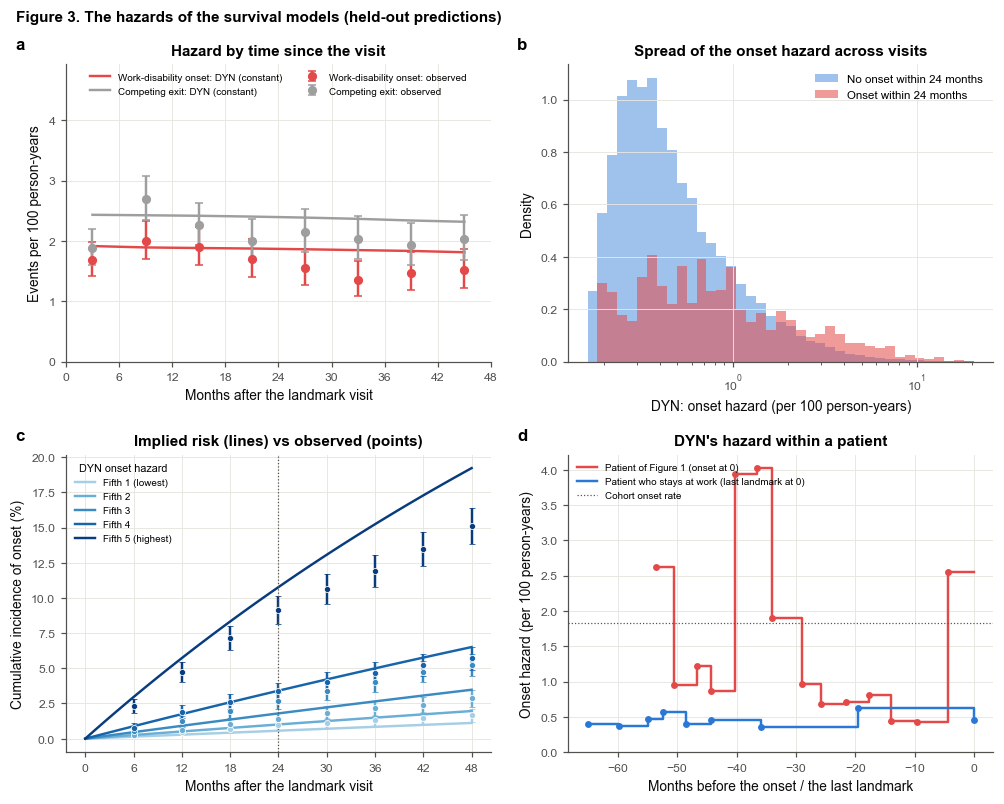

,Person-years,Onsets,Onset rate /100 py,Competing exits,Competing rate /100 py
Band (months),,,,,
0-6,8531.0,143,1.68,160,1.88
6-12,8006.0,160,2.00,216,2.70
12-18,7527.0,143,1.90,170,2.26
18-24,7130.0,121,1.70,143,2.01
24-30,6800.0,105,1.54,146,2.15
30-36,6508.0,88,1.35,132,2.03
36-42,6231.0,92,1.48,120,1.93
42-48,5922.0,90,1.52,120,2.03


DYN onset hazard per 100 person-years: median 0.92, 10th-90th percentile 0.29-4.43; competing-exit hazard median 1.40.


In [9]:
"""Figure 3: the hazards of DYN."""


def mean_eta(m):
    """Held-out log-hazards of every landmark, mean over the CV repeats (n x 2 or n x 16)."""
    acc, cnt = None, np.zeros(N_LAND)
    for r in REPEATS:
        for f in range(CV_N_SPLITS):
            res = ALL_FOLDS[(m, r, f)]
            if acc is None:
                acc = np.zeros((N_LAND, res["eta_te"].shape[1]))
            acc[res["te_rows"]] += res["eta_te"]; cnt[res["te_rows"]] += 1
    return acc / np.maximum(cnt, 1)[:, None]


ETA_MAIN = mean_eta(MAIN_MODEL)
ETA_BANDS = mean_eta(DYN_BANDS) if DYN_BANDS in MODELS_RUN else None
_bm = (np.arange(N_BANDS) + 0.5) * BAND_MONTHS
_py = BAND_DT.sum(0)


def _pois_ci(d, py):
    lo = np.where(d > 0, stats.chi2.ppf(0.025, 2 * d) / 2, 0.0) / py
    hi = stats.chi2.ppf(0.975, 2 * (d + 1)) / 2 / py
    return lo, hi


fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))
ax = axes[0, 0]
for cause, D, lab_, col_ in [(0, BAND_D1, "Work-disability onset", STATUS_COLORS["onset"]),
                             (1, BAND_D2, "Competing exit", STATUS_COLORS["other exit"])]:
    d = D.sum(0); rate = d / _py; lo, hi = _pois_ci(d, _py)
    ax.errorbar(_bm, 100 * rate, yerr=[100 * (rate - lo), 100 * (hi - rate)], fmt="o", color=col_, capsize=2.5,
                ms=5, label=f"{lab_}: observed")
    lam_c = np.exp(np.clip(ETA_MAIN[:, cause], -30, 5))
    ax.plot(_bm, 100 * (BAND_DT * lam_c[:, None]).sum(0) / _py, "-", color=col_, lw=1.6,
            label=f"{lab_}: {short_label(MAIN_MODEL)} (constant)")
    if ETA_BANDS is not None:
        lam_b = np.exp(np.clip(ETA_BANDS[:, cause * N_BANDS:(cause + 1) * N_BANDS], -30, 5))
        ax.plot(_bm, 100 * (BAND_DT * lam_b).sum(0) / _py, "--", color=col_, lw=1.4,
                label=f"{lab_}: {short_label(DYN_BANDS)}")
ax.set_xticks(np.arange(0, 49, 6)); ax.set_xlabel("Months after the landmark visit")
ax.set_ylabel("Events per 100 person-years"); ax.set_title("Hazard by time since the visit")
ax.set_ylim(0, ax.get_ylim()[1] * 1.55); ax.legend(fontsize=6.5, loc="upper center", ncol=2)

ax = axes[0, 1]
lam1 = 100 * np.exp(ETA_MAIN[:, 0])
_on24 = (C_ALL == 1) & (T_ALL <= HORIZON_DAYS)
_bins = np.logspace(np.log10(np.percentile(lam1, 0.5)), np.log10(np.percentile(lam1, 99.5)), 40)
ax.hist(lam1[~_on24], bins=_bins, density=True, color=STATUS_COLORS["working"], alpha=0.45,
        label=f"No onset within {H} months")
ax.hist(lam1[_on24], bins=_bins, density=True, color=STATUS_COLORS["onset"], alpha=0.55,
        label=f"Onset within {H} months")
ax.set_xscale("log"); ax.set_xlabel(f"{short_label(MAIN_MODEL)}: onset hazard (per 100 person-years)")
ax.set_ylabel("Density"); ax.set_title("Spread of the onset hazard across visits"); ax.legend()

ax = axes[1, 0]
_q = pd.qcut(ETA_MAIN[:, 0], 5, labels=False)
_cmap = plt.get_cmap("Blues")
_mo = np.linspace(0, 48, 97)
for g in range(5):
    k = _q == g
    col_ = _cmap(0.35 + 0.15 * g)
    pred = np.array([cif(ETA_MAIN[k], mm).mean() for mm in _mo])
    ax.plot(_mo, 100 * pred, "-", color=col_, lw=1.6, label=f"Fifth {g + 1}" + (" (lowest)" if g == 0 else
                                                                                   " (highest)" if g == 4 else ""))
    obs = []
    for h in HORIZONS:
        rr, yy, ww = IPCW_H[h]
        kk = k[rr]
        n_g = k.sum()
        o = np.sum(ww[kk] * yy[kk]) / n_g
        se = np.sqrt(np.sum((ww[kk] * yy[kk] - o) ** 2) + (n_g - kk.sum()) * o ** 2) / n_g   # landmarks independent
        obs.append((o, se))
    obs = np.array(obs)
    ax.errorbar(HORIZONS, 100 * obs[:, 0], yerr=196 * obs[:, 1], fmt="o", color=col_, ms=4, capsize=2,
                mec="white", mew=0.5)
ax.axvline(H, color=INK_2, lw=0.8, ls=":")
ax.set_xticks(np.arange(0, 49, 6)); ax.set_xlabel("Months after the landmark visit")
ax.set_ylabel("Cumulative incidence of onset (%)"); ax.set_title("Implied risk (lines) vs observed (points)")
ax.legend(title=f"{short_label(MAIN_MODEL)} onset hazard", fontsize=6.5, title_fontsize=7)

ax = axes[1, 1]
_li_e = PT_ROWS[EXAMPLE_PID]
_li_e = _li_e[land["visit_date"].values[_li_e] < np.datetime64(FIRST_ONSET[EXAMPLE_PID])]
_age_e = land["age_at_record"].values[_li_e[-1]]
_ctrl_pids = [p for p in PT_ROWS if p not in EVER_ONSET and len(PT_ROWS[p]) >= len(_li_e)
              and abs(land["age_at_record"].values[PT_ROWS[p][-1]] - _age_e) < 5]
CTRL_PID = sorted(_ctrl_pids, key=lambda p: len(PT_ROWS[p]))[len(_ctrl_pids) // 2] if _ctrl_pids else None
for pid, lab_, col_, li in [(EXAMPLE_PID, "Patient of Figure 1 (onset at 0)", STATUS_COLORS["onset"], _li_e),
                            (CTRL_PID, "Patient who stays at work (last landmark at 0)", STATUS_COLORS["working"],
                             PT_ROWS.get(CTRL_PID, np.array([], int)))]:
    if pid is None or len(li) == 0:
        continue
    anchor = FIRST_ONSET[pid] if pid in EVER_ONSET else pd.Timestamp(land["visit_date"].values[li[-1]])
    x = (pd.to_datetime(land["visit_date"].values[li]) - anchor).days.values / MONTH_DAYS
    k = x >= -72
    ax.step(np.r_[x[k], 0], 100 * np.exp(np.r_[ETA_MAIN[li[k], 0], ETA_MAIN[li[k][-1], 0]]), where="post", color=col_,
            lw=1.6, label=lab_)
    ax.plot(x[k], 100 * np.exp(ETA_MAIN[li[k], 0]), "o", color=col_, ms=3.5)
ax.axhline(100 * D_ONSET.sum() / INT_YRS.sum(), color=INK_2, lw=0.8, ls=":", label="Cohort onset rate")
ax.set_xlabel("Months before the onset / the last landmark")
ax.set_ylabel("Onset hazard (per 100 person-years)"); ax.set_title(f"{short_label(MAIN_MODEL)}'s hazard within a patient")
ax.set_ylim(0, None); ax.legend(fontsize=6.5, loc="upper left")
for a_, l_ in zip(axes.ravel(), "abcd"):
    panel_label(a_, l_)
fig.suptitle("Figure 3. The hazards of the survival models (held-out predictions)", x=0.02, ha="left", fontsize=10,
             fontweight="bold")
plt.tight_layout()
save_fig("fig03_hazards")
_band_tab = pd.DataFrame({"Band (months)": [f"{b * BAND_MONTHS}-{(b + 1) * BAND_MONTHS}" for b in range(N_BANDS)],
                          "Person-years": _py.round(0), "Onsets": BAND_D1.sum(0).astype(int),
                          "Onset rate /100 py": (100 * BAND_D1.sum(0) / _py).round(2),
                          "Competing exits": BAND_D2.sum(0).astype(int),
                          "Competing rate /100 py": (100 * BAND_D2.sum(0) / _py).round(2)}).set_index("Band (months)")
display(_band_tab)
print(f"{short_label(MAIN_MODEL)} onset hazard per 100 person-years: median {np.median(lam1):.2f}, 10th-90th percentile "
      f"{np.percentile(lam1, 10):.2f}-{np.percentile(lam1, 90):.2f}; competing-exit hazard median "
      f"{np.median(100 * np.exp(ETA_MAIN[:, 1])):.2f}.")

## 11.7 The metric engine

Within each repeat the 5 test folds cover every landmark once; each metric is computed on that pooled set and
averaged over the repeats. **95 % CIs: patient-cluster bootstrap**, 1,000 resamples of patients (all their landmarks
together), the **same resamples for every model, repeat and horizon**, so every difference is paired.

* **Visit level** (every landmark with a known *h*-month status, censoring weights 1/G): AUROC; calibration slope
  and intercept; O/E (IPCW observed cumulative incidence over the mean predicted risk); sensitivity, specificity,
  PPV, NPV, balanced accuracy and share flagged at the fold's threshold; net benefit; risk tiers.
* **Patient level** (the windows of Section 9.2): **AUROC of the patient score (primary patient metric)**;
  sensitivity, specificity, PPV, NPV, balanced accuracy at the fold's patient threshold; lead time; patient-level
  calibration slope, intercept and O/E. Also the 2-consecutive-alarms rule.
* **Risk-set C** (robustness): each onset against every patient at risk on the onset date.

In [10]:
"""Bootstrap weights and every metric of every model."""
P_ = len(ALL_PIDS)
_rng = np.random.RandomState(SEED + 99)
W_BOOT = _rng.multinomial(P_, np.full(P_, 1 / P_), size=BOOT_N).astype(np.float32)
_BOTH = np.vstack([np.ones((1, P_), np.float32), W_BOOT])
_W_ALL = _BOTH[:, ROW_PIDX]
RS_PC, RS_PK = ROW_PIDX[RS_CASE], ROW_PIDX[RS_CTRL]


def _pair_sum_fast(Wp, M):
    return ((Wp @ M.astype(np.float32)) * Wp).sum(1)


_RS_A = sparse.coo_matrix((np.ones(len(RS_CASE)), (RS_PC, RS_PK)), shape=(P_, P_)).toarray()
_RS_DEN = _pair_sum_fast(_BOTH, _RS_A)
PTW_PIDX = {h: np.array([PID_INDEX[p] for p in PTW[h]["pids"]]) for h in HORIZONS}
_STAYED = set(patients_df.index[(patients_df["final_emp"] == "employed")]) - EVER_ONSET \
    - set(land.loc[land["cause"] >= 2, "pid"])
STAYED_ROWS = np.isin(PID_ALL, list(_STAYED))
PT_SUB = {}                                        # patient subgroups at the window's last landmark
for name, mask in SUBGROUPS.items():
    if name.split(":")[0] in ("Sex", "Race", "Age", "Era"):
        PT_SUB[name] = mask[PTW[H]["last_row"]]


def _chunks(n, size=250):
    return [slice(i, min(i + size, n)) for i in range(0, n, size)]


def wauc(y, p, Wr):
    """Weighted AUROC for every row of the weight matrix Wr (B, n); ties count 1/2."""
    o = np.argsort(p, kind="mergesort")
    ps, ys = p[o], y[o]
    starts = np.r_[0, np.flatnonzero(np.diff(ps)) + 1]
    out = np.empty(Wr.shape[0])
    for sl in _chunks(Wr.shape[0]):
        Ws = Wr[sl][:, o]
        pos = np.add.reduceat(Ws * (ys == 1), starts, axis=1)
        neg = np.add.reduceat(Ws * (ys == 0), starts, axis=1)
        cneg = np.cumsum(neg, 1) - neg
        with np.errstate(invalid="ignore", divide="ignore"):
            out[sl] = (pos * (cneg + 0.5 * neg)).sum(1) / (pos.sum(1) * neg.sum(1))
    return out


def wcalibration(y, z, w):
    """Calibration slope and intercept (offset logistic, calibration-in-the-large) of logits z, weights w."""
    k = w > 0
    if len(np.unique(y[k])) < 2:
        return np.nan, np.nan
    slope = LogisticRegression(C=1e6, max_iter=1000).fit(z[k, None], y[k], sample_weight=w[k]).coef_[0, 0]
    f = lambda a: np.average(_expit(a + z[k]), weights=w[k]) - np.average(y[k], weights=w[k])
    try:
        icpt = brentq(f, -20, 20)
    except ValueError:
        icpt = np.nan
    return float(slope), float(icpt)


def _ratio(a, b):
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(b > 0, a / b, np.nan)


def confusion_stats(y, a, Wr):
    y1, a1 = (y == 1).astype(np.float32), np.asarray(a, bool).astype(np.float32)
    tp, fn = Wr @ (y1 * a1), Wr @ (y1 * (1 - a1))
    fp, tn = Wr @ ((1 - y1) * a1), Wr @ ((1 - y1) * (1 - a1))
    sens, spec = _ratio(tp, tp + fn), _ratio(tn, tn + fp)
    return {"sensitivity": sens, "specificity": spec, "ppv": _ratio(tp, tp + fp), "npv": _ratio(tn, tn + fn),
            "balanced_accuracy": (sens + spec) / 2, "flagged": _ratio(tp + fp, tp + fp + fn + tn)}


def wmedian(x, Wr):
    if len(x) == 0:
        return np.full(Wr.shape[0], np.nan)
    o = np.argsort(x)
    cw = np.cumsum(Wr[:, o], 1)
    tot = cw[:, -1:]
    idx = (cw < 0.5 * tot).sum(1)
    out = x[o][np.minimum(idx, len(x) - 1)].astype(float)
    out[tot[:, 0] == 0] = np.nan
    return out


def fire_dates(z, thr_row, W):
    """Date at which each window's running mean logit first reaches the patient threshold (NaT if never)."""
    out = np.full(len(W["rows"]), np.datetime64("NaT"), dtype="datetime64[ns]")
    for k, r in enumerate(W["rows"]):
        run = np.cumsum(z[r]) / np.arange(1, len(r) + 1)
        hit = np.flatnonzero(run >= thr_row[r[-1]])
        if len(hit):
            out[k] = VISIT_DATE[r[hit[0]]]
    return out


CONF_METRICS = ["sensitivity", "specificity", "ppv", "npv", "balanced_accuracy", "flagged"]
METRIC_LABELS = {"auroc": "AUROC", "riskset_c": "Risk-set C", "cal_slope": "Calibration slope",
                 "cal_intercept": "Calibration intercept", "oe": "O/E", "sensitivity": "Sensitivity",
                 "specificity": "Specificity", "ppv": "PPV", "npv": "NPV", "balanced_accuracy": "Balanced accuracy",
                 "flagged": "Share flagged", "lead_median": "Median lead time (months)",
                 "lead_ge6": f"Onsets flagged >= {LEAD_TIME_MIN_MONTHS} months ahead", "nb": "Net benefit"}


def stats_one_repeat(m, r):
    """{key: (point, bootstrap array or None)} for model m, repeat r."""
    out = {}
    put = lambda key, a: out.__setitem__(key, (float(a[0]), np.asarray(a[1:], float)))
    point = lambda key, v: out.__setitem__(key, (float(v), None))
    for h in HORIZONS:
        z_all = zpred(m, r, h)
        rows, y, w = IPCW_H[h]
        z = z_all[rows]
        Wr = _BOTH[:, ROW_PIDX[rows]] * w[None, :]
        put(("visit", h, "auroc"), wauc(y, z, Wr))
        w_full = np.zeros(N_LAND); w_full[rows] = w
        y_full = np.zeros(N_LAND); y_full[rows] = y
        put(("visit", h, "oe"), (_W_ALL @ (w_full * y_full)) / (_W_ALL @ _expit(z_all)))
        nb_ = N_CAL_BOOT if h == H else 0
        cal = [wcalibration(y, z, (Wr[b] if b else w)) for b in range(nb_ + 1)]
        out[("visit", h, "cal_slope")] = (cal[0][0], np.array([c[0] for c in cal[1:]]) if nb_ else None)
        out[("visit", h, "cal_intercept")] = (cal[0][1], np.array([c[1] for c in cal[1:]]) if nb_ else None)
        for c in (THRESHOLD_RULES if h == H else [MAIN_THRESHOLD]):
            thr = THR_V[m][r][h][c]
            for k_, v_ in confusion_stats(y, z >= thr[rows], Wr).items():
                put(("visit", h, c, k_), v_)
            point(("visit", h, c, "threshold"), np.nanmedian(_expit(np.unique(thr[~np.isnan(thr)]))))
        # patient level
        W = PTW[h]
        s = np.asarray(W["mat"] @ np.nan_to_num(z_all)).ravel()
        ev = W["event"]
        Wp = _BOTH[:, PTW_PIDX[h]]
        put(("patient", h, "auroc"), wauc(ev, s, Wp))
        for c in (THRESHOLD_RULES if h == H else [MAIN_THRESHOLD]):
            thr_pt = THR_P[m][r][h][c][W["last_row"]]
            for k_, v_ in confusion_stats(ev, s >= thr_pt, Wp).items():
                put(("patient", h, c, k_), v_)
        if h != H:
            continue
        # ---- primary horizon only
        y1 = (y == 1).astype(np.float32)
        for t in FIXED_RISKS:
            for k_, v_ in confusion_stats(y, z >= _logit(t), Wr).items():
                put(("visit", h, "fixed", t, k_), v_)
        p = _expit(z)
        tot = Wr.sum(1)
        for t in NB_GRID:
            a = (p >= t).astype(np.float32)
            put(("visit", h, "nb", t), (Wr @ (y1 * a) - Wr @ ((1 - y1) * a) * t / (1 - t)) / tot)
            put(("visit", h, "nb_all", t), (Wr @ y1 - Wr @ (1 - y1) * t / (1 - t)) / tot)
        rec = (land["CAL_YEAR"].values >= TIER_RECENT_FROM)
        for lo, hi, name in RISK_TIERS + RULE_OUT_TIERS:
            inn = ((p >= lo) & (p < hi)).astype(np.float32)
            put(("visit", h, "tier", name, "observed"), _ratio(Wr @ (y1 * inn), Wr @ inn))
            put(("visit", h, "tier", name, "share_onsets"), _ratio(Wr @ (y1 * inn), Wr @ y1))
            inr, y1r = inn * rec[rows], y1 * rec[rows]                 # recent era only
            put(("visit", h, "tier_recent", name, "observed"), _ratio(Wr @ (y1r * inr), Wr @ inr))
            put(("visit", h, "tier_recent", name, "share_onsets"), _ratio(Wr @ (y1r * inr), Wr @ y1r))
            put(("visit", h, "tier_recent", name, "share_visits"), _ratio(Wr @ inr, Wr @ rec[rows].astype(np.float32)))
            inn_all = (_expit(z_all) >= lo) & (_expit(z_all) < hi)
            point(("visit", h, "tier", name, "share_visits"), inn_all.mean())
            point(("visit", h, "tier", name, "share_patients"), np.mean(
                pd.Series(inn_all).groupby(PID_ALL).max().values))
            point(("visit", h, "tier", name, "mean_pred"), _expit(z_all)[inn_all].mean() if inn_all.any() else np.nan)
        alarm = z_all >= THR_V[m][r][h][MAIN_THRESHOLD]
        point(("visit", h, "alerts_per_100"), 100 * alarm.mean())
        point(("visit", h, "alerts_per_py"), alarm.sum() / INT_YRS.sum())
        never = pd.Series(alarm[STAYED_ROWS]).groupby(PID_ALL[STAYED_ROWS]).max()
        point(("visit", h, "stayed_never_alerted"), 1 - never.mean())
        point(("visit", h, "stayed_alerts_per_py"), alarm[STAYED_ROWS].sum() / INT_YRS[STAYED_ROWS].sum())
        for name, mask in SUBGROUPS.items():
            k = mask[rows]
            if y[k].sum() >= 3 and (1 - y[k]).sum() >= 3:
                put(("visit", h, "sub", name, "auroc"), wauc(y[k], z[k], Wr[:, k]))
                point(("visit", h, "sub", name, "oe"), np.sum(w[k] * y[k]) / np.sum(w[k] * p[k]))
        # patient level, primary horizon: run2, lead time, calibration, subgroups
        s2 = run2_score(z_all, W["rows"])
        put(("patient", h, "run2", "auroc"), wauc(ev, s2, Wp))
        for k_, v_ in confusion_stats(ev, s2 >= THR_RUN2[m][r][MAIN_THRESHOLD][W["last_row"]], Wp).items():
            put(("patient", h, "run2", k_), v_)
        thr_row = THR_P[m][r][h][MAIN_THRESHOLD]
        fire = fire_dates(z_all, thr_row, W)
        ok = (ev == 1) & ~np.isnat(fire)
        lead = ((W["event_date"][ok] - fire[ok]) / np.timedelta64(1, "D")).astype(float) / MONTH_DAYS
        put(("patient", h, "lead_median"), wmedian(lead, Wp[:, ok]))
        ge6 = np.zeros(len(ev)); ge6[np.flatnonzero(ok)[lead >= LEAD_TIME_MIN_MONTHS]] = 1
        put(("patient", h, "lead_ge6"), _ratio(Wp @ ge6, Wp @ ev.astype(float)))
        out[("patient", h, "lead_values")] = (lead, None)
        a_, b_ = PCAL[m][r][h]
        zp = a_[W["last_row"]] + b_[W["last_row"]] * s
        put(("patient", h, "oe"), (Wp @ ev.astype(float)) / (Wp @ _expit(zp)))
        cal = [wcalibration(ev, zp, (Wp[b] if b else np.ones(len(ev)))) for b in range(N_CAL_BOOT + 1)]
        out[("patient", h, "cal_slope")] = (cal[0][0], np.array([c[0] for c in cal[1:]]))
        out[("patient", h, "cal_intercept")] = (cal[0][1], np.array([c[1] for c in cal[1:]]))
        for name, mask in PT_SUB.items():
            if ev[mask].sum() >= 3 and (1 - ev[mask]).sum() >= 3:
                put(("patient", h, "sub", name, "auroc"), wauc(ev[mask], s[mask], Wp[:, mask]))
        # risk-set C
        ps = patient_score_rs(m, z_all)
        a, b = ps[RS_CASE], ps[RS_CTRL]
        K = sparse.coo_matrix(((a > b) + 0.5 * (a == b), (RS_PC, RS_PK)), shape=(P_, P_)).toarray()
        put(("riskset", "riskset_c"), _pair_sum_fast(_BOTH, K) / _RS_DEN)
    for iv in INTERVALS:
        rows, y, w = IPCW_INT[iv]
        Wr = _BOTH[:, ROW_PIDX[rows]] * w[None, :]
        put(("interval", iv, "auroc"), wauc(y, PRED[m][r][("iv",) + iv][rows], Wr))
    return out


STATS_CACHE_PATH = f"stats_cache_{TAG}{'_smoke' if SMOKE else ''}.pkl"
_stats_cache = _load(STATS_CACHE_PATH, {})
_METRIC_VERSION = "v13.1"


def _signature(m):
    return (_METRIC_VERSION, tuple(REPEATS), BOOT_N,
            float(np.nansum([np.nansum(zpred(m, r)) for r in REPEATS])),
            float(np.nansum([np.nansum(THR_V[m][r][H]["cost"]) for r in REPEATS])))


STATS = {}
for m in MODELS_RUN:
    t0 = time.time()
    sig = _signature(m)
    if m in _stats_cache and _stats_cache[m][0] == sig:
        STATS.update(_stats_cache[m][1])
        continue
    per = [stats_one_repeat(m, r) for r in REPEATS]
    res = {}
    for key in per[0]:
        if key[-1] == "lead_values":
            res[(m,) + key] = (np.concatenate([d[key][0] for d in per if key in d]), None)
            continue
        pts = [d[key][0] for d in per if key in d]
        bts = [d[key][1] for d in per if key in d]
        res[(m,) + key] = (float(np.nanmean(pts)), None if bts[0] is None else np.nanmean(np.vstack(bts), 0))
    _stats_cache[m] = (sig, res)
    _save(_stats_cache, STATS_CACHE_PATH)
    STATS.update(res)
    print(f"  metrics of {short_label(m)} ({time.time() - t0:.0f} s)", flush=True)


def ci(key):
    if key not in STATS:
        return np.nan, np.nan, np.nan
    pt, bt = STATS[key]
    if bt is None:
        return pt, np.nan, np.nan
    return pt, float(np.nanpercentile(bt, 2.5)), float(np.nanpercentile(bt, 97.5))


def _diff_summary(pt, d, n_comp=1):
    a = 2.5 / n_comp
    pval = 2 * min(np.nanmean(d <= 0), np.nanmean(d >= 0))
    return pt, float(np.nanpercentile(d, a)), float(np.nanpercentile(d, 100 - a)), min(1.0, pval)


def diff(m1, m2, key, n_comp=1):
    """Paired difference m1 - m2: point, 95 % CI (Bonferroni-widened for n_comp), two-sided bootstrap p."""
    if (m1,) + key not in STATS or (m2,) + key not in STATS or STATS[(m1,) + key][1] is None:
        return np.nan, np.nan, np.nan, np.nan
    p1, b1 = STATS[(m1,) + key]; p2, b2 = STATS[(m2,) + key]
    return _diff_summary(p1 - p2, b1 - b2, n_comp)


def fmt(pt, lo=np.nan, hi=np.nan, nd=3):
    if pt is None or np.isnan(pt):
        return "-"
    if np.isnan(lo):
        return f"{pt:.{nd}f}"
    return f"{pt:.{nd}f} ({lo:.{nd}f} to {hi:.{nd}f})"


def fmtk(key, nd=3):
    return fmt(*ci(key), nd=nd)


def verdict_superiority(lo, hi, margin=None):
    if lo > 0:
        return "superior"
    if hi < 0:
        return "inferior"
    if margin is not None and lo > -margin and hi < margin:
        return "equivalent"
    return "inconclusive"


K_VIS = ("visit", H, "auroc")
K_PT = ("patient", H, "auroc")
K_RS = ("riskset", "riskset_c")
OBJ_CONCLUSIONS, HYP_ROWS = {}, []
print(f"Reported model {short_label(REPORTED)}: visit AUROC {H} months {fmtk((REPORTED,) + K_VIS)} | 12 months "
      f"{fmtk((REPORTED, 'visit', 12, 'auroc'))}")

  metrics of L1 Demographics (108 s)
  metrics of L2 First visit (128 s)
  metrics of HazReg (130 s)
  metrics of LogReg (130 s)
  metrics of Unit score (126 s)
  metrics of DYN (123 s)
  metrics of HazReg linear (76 s)
  metrics of HazReg + year (65 s)
  metrics of HazReg wide (64 s)
Reported model HazReg: visit AUROC 24 months 0.726 (0.682 to 0.769) | 12 months 0.736 (0.693 to 0.777)


## 11.8 Time-matched patient-level metrics (the primary metric)

For each onset (on date *E*), the **case** is the patient's mean 24-month risk logit over their landmarks in a
window before *E*; the **controls** are every other patient at risk on *E* (still working and followed), each scored
over their own landmarks **in the same calendar window** (if a patient has no landmark in the window, their latest
landmark before the window's end). AUROC = the share of case-control pairs in which the case scores higher (ties
1/2), pooled over onsets; 95 % CI from the same patient-cluster bootstrap as everything else.

* **Primary**: the window is the 24 months before the onset (every landmark in it has the onset within 24 months).
* **By time before the onset** (Section 16.1): windows 0-6, 6-12, 12-24, 24-36 and 36-48 months before the onset (the same controls, the same
  calendar window): discrimination by time before the onset. Here the case must have a landmark inside the window
  (no fallback), so each window uses only the onsets observed at that distance.
* Patient-level sensitivity (cases whose window score is above their fold's **time-matched threshold**), specificity
  (the same for controls, each onset's controls weighted equally) and balanced accuracy. The threshold of each fold
  is the max-Youden cut-off over the training patients' time-matched pairs, scored with their out-of-fold risks
  (the same rule as the visit threshold, applied to the patient comparison it is used for).

In [11]:
"""Time-matched patient AUROC: entities, pairs and metrics for every model."""
_PT_T = {pid: _LAND_T[li] for pid, li in PT_ROWS.items()}


def _window_rows(pid, lo_day, hi_day, fallback=True):
    """The patient's landmark rows with lo_day <= date < hi_day; else (fallback) the latest before hi_day; else empty."""
    li, t = PT_ROWS[pid], _PT_T[pid]
    a, b = np.searchsorted(t, lo_day, side="left"), np.searchsorted(t, hi_day, side="left")
    if b > a:
        return li[a:b]
    return li[b - 1:b] if (b > 0 and fallback) else li[:0]


def build_tm(lo_m, hi_m, case_fallback=True):
    """Entities (rows to average) and case-control pairs for the window [E - hi, E - lo) months before each onset."""
    ent_rows, ent_pid = [], []
    case_ent, pairs_c, pairs_k, pairs_w = {}, [], [], []
    for e in RS_EVENTS:
        E = INT_END[e]
        lo_day, hi_day = E - hi_m * MONTH_DAYS, E - lo_m * MONTH_DAYS
        pc = PID_ALL[e]
        rc = _window_rows(pc, lo_day, min(hi_day, E), case_fallback)
        if len(rc) == 0:
            continue
        ci_ = len(ent_rows); ent_rows.append(rc); ent_pid.append(PID_INDEX[pc])
        ctrl = np.unique(PID_ALL[RS_CTRL[RS_CASE == e]])
        ks = []
        for pk in ctrl:
            rk = _window_rows(pk, lo_day, hi_day)
            if len(rk):
                ks.append(len(ent_rows)); ent_rows.append(rk); ent_pid.append(PID_INDEX[pk])
        if ks:
            pairs_c += [ci_] * len(ks); pairs_k += ks; pairs_w += [1.0 / len(ks)] * len(ks)
            case_ent[e] = ci_
    n = np.array([len(r) for r in ent_rows])
    mat = sparse.csr_matrix((np.concatenate([np.full(len(r), 1.0 / len(r)) for r in ent_rows]),
                             (np.repeat(np.arange(len(ent_rows)), n), np.concatenate(ent_rows))),
                            shape=(len(ent_rows), N_LAND))
    last = np.array([r[-1] for r in ent_rows])
    pc, pk = np.array(pairs_c), np.array(pairs_k)
    ep = np.array(ent_pid)
    cases = np.array(sorted(set(pairs_c)))
    return {"mat": mat, "last": last, "pc": pc, "pk": pk, "w": np.array(pairs_w), "ppc": ep[pc], "ppk": ep[pk],
            "cases": cases, "case_pid": ep[cases], "n_onsets": len(cases), "ent_pid": ep}


TM_WINDOWS = {"main": (0, TM_WINDOW_MONTHS)} | {f"{a}-{b}": (a, b) for a, b in TTO_BINS}
TM = {k: build_tm(*v, case_fallback=(k == "main")) for k, v in TM_WINDOWS.items()}
for k, d in TM.items():
    d["den"] = _pair_sum_fast(_BOTH, sparse.coo_matrix((np.ones(len(d["pc"])), (d["ppc"], d["ppk"])),
                                                         shape=(P_, P_)).toarray())
    d["wden"] = _pair_sum_fast(_BOTH, sparse.coo_matrix((d["w"], (d["ppc"], d["ppk"])), shape=(P_, P_)).toarray())
print("Time-matched pairs: " + ", ".join(f"{k}: {d['n_onsets']} onsets, {len(d['pc']):,} pairs" for k, d in TM.items()))


TEST_FOLD = {r: np.zeros(len(ALL_PIDS), int) for r in REPEATS}     # each patient's test fold in each repeat
for r in REPEATS:
    for f in range(CV_N_SPLITS):
        TEST_FOLD[r][[PID_INDEX[p] for p in OUTER[r][f][1]]] = f
_THR_TM = {}


def tm_fold_thresholds(m, r):
    """One time-matched threshold per fold: max Youden over the TRAINING patients' time-matched pairs (main 24-month
    window), each scored with its out-of-fold recalibrated logits; each onset's training controls weighted equally."""
    if (m, r) in _THR_TM:
        return _THR_TM[(m, r)]
    d = TM["main"]
    out = np.full(CV_N_SPLITS, np.nan)
    for f in range(CV_N_SPLITS):
        tr, zo = OOF_H[(m, r, f)]
        oof = np.full(N_LAND, np.nan); oof[tr] = zo
        s = np.asarray(d["mat"] @ np.nan_to_num(oof)).ravel()
        in_tr = TEST_FOLD[r][d["ent_pid"]] != f
        k = in_tr[d["pc"]] & in_tr[d["pk"]]
        pc, pk = d["pc"][k], d["pk"][k]
        if len(pc) == 0:
            continue
        cases, inv, n_per = np.unique(pc, return_inverse=True, return_counts=True)
        w = 1.0 / n_per[inv]
        sc, order = np.sort(s[cases]), np.argsort(s[pk])
        sk, cw = s[pk][order], np.r_[0.0, np.cumsum(w[order])]
        cand = np.unique(sc)
        sens = 1.0 - np.searchsorted(sc, cand, side="left") / len(sc)
        spec = cw[np.searchsorted(sk, cand, side="left")] / cw[-1]
        out[f] = cand[np.argmax(sens + spec)]
    _THR_TM[(m, r)] = out
    return out


def tm_stats_one(m, r, d):
    z = zpred(m, r)
    s = np.asarray(d["mat"] @ np.nan_to_num(z)).ravel()
    a, b = s[d["pc"]], s[d["pk"]]
    K = sparse.coo_matrix(((a > b) + 0.5 * (a == b), (d["ppc"], d["ppk"])), shape=(P_, P_)).toarray()
    out = {"auroc": _pair_sum_fast(_BOTH, K) / d["den"]}
    thr = tm_fold_thresholds(m, r)[TEST_FOLD[r][d["ent_pid"]]]       # the entity's test fold's threshold
    flag = s >= thr
    Wc = _BOTH[:, d["case_pid"]]
    out["sensitivity"] = (Wc @ flag[d["cases"]].astype(np.float32)) / Wc.sum(1)
    Ks = sparse.coo_matrix((d["w"] * ~flag[d["pk"]], (d["ppc"], d["ppk"])), shape=(P_, P_)).toarray()
    out["specificity"] = _pair_sum_fast(_BOTH, Ks) / d["wden"]
    out["balanced_accuracy"] = (out["sensitivity"] + out["specificity"]) / 2
    return out


TM_CACHE_KEY = ("tm", _METRIC_VERSION, tuple(REPEATS), BOOT_N)
for m in MODELS_RUN:
    sig = _signature(m)
    hit = m in _stats_cache and len(_stats_cache[m]) > 2 and _stats_cache[m][2][0] == sig
    if hit:
        STATS.update(_stats_cache[m][2][1]); continue
    res = {}
    for k, d in TM.items():
        per = [tm_stats_one(m, r, d) for r in REPEATS]
        for met in per[0]:
            v = np.mean([p_[met] for p_ in per], 0)
            res[(m, "tm", k, met)] = (float(v[0]), v[1:])
    _stats_cache[m] = (_stats_cache[m][0], _stats_cache[m][1], (sig, res))
    _save(_stats_cache, STATS_CACHE_PATH)
    STATS.update(res)
K_TM = ("tm", "main", "auroc")
print(f"Time-matched patient AUROC: {short_label(REPORTED)} {fmtk((REPORTED,) + K_TM)} | DYN {fmtk((SEQ_MAIN,) + K_TM)}")

Time-matched pairs: main: 158 onsets, 43,991 pairs, 0-6: 117 onsets, 32,834 pairs, 6-12: 109 onsets, 28,880 pairs, 12-24: 104 onsets, 26,792 pairs, 24-36: 86 onsets, 19,422 pairs, 36-48: 77 onsets, 16,514 pairs
Time-matched patient AUROC: HazReg 0.745 (0.707 to 0.784) | DYN 0.731 (0.693 to 0.771)


## 11.9 The Brier score, the index of prediction accuracy and shared helpers

**IPCW Brier score** at horizon *h* (Graf et al. 1999; for competing risks, the cumulative incidence of onset):
the censoring-weighted mean of (outcome − predicted risk)² over the landmarks with a known *h*-month status, with the
same weights as the AUROC (Section 3; normalised by the sum of the weights). **IPA** (index of prediction accuracy,
Kattan & Gerds 2018): 1 − Brier / Brier of the null model that gives every landmark the cohort's observed
cumulative incidence (IPCW). IPA > 0 means the model predicts better than knowing the overall risk; it combines
discrimination and calibration in one number. The null risk is the evaluation sample's own observed risk (in each
bootstrap resample too), which slightly favours the null. Both from the same paired patient bootstrap.

In [12]:
"""IPCW Brier score and IPA at every horizon; subgroup helper; the 'healthy-looking' and outcome groups."""


def _pt_agg(rows, v):
    """Sum of v over each patient's rows (bootstrap weights act per patient, so W @ v = _BOTH @ this)."""
    return np.bincount(ROW_PIDX[rows], weights=v, minlength=P_)


def brier_ipa(z_all, h):
    """(Brier, IPA) arrays (point + bootstrap) of the logits z_all at horizon h."""
    rows, y, w = IPCW_H[h]
    p = _expit(z_all[rows])
    den = _BOTH @ _pt_agg(rows, w)
    p0 = (_BOTH @ _pt_agg(rows, w * y)) / den
    b = (_BOTH @ _pt_agg(rows, w * (y - p) ** 2)) / den
    return b, 1 - b / (p0 * (1 - p0))


for m in MODELS_RUN:
    for h in HORIZONS:
        per = [brier_ipa(zpred(m, r, h), h) for r in REPEATS]
        for j, k_ in enumerate(["brier", "ipa"]):
            v = np.mean([p_[j] for p_ in per], 0)
            STATS[(m, "visit", h, k_)] = (float(v[0]), v[1:])
K_VIS12 = ("visit", 12, "auroc")
K_BRIER, K_IPA = ("visit", H, "brier"), ("visit", H, "ipa")


def sub_visit(m, mask, h=H, zs=None):
    """Visit AUROC, Brier and O/E (point + bootstrap, mean over the repeats) of model m on the landmarks in mask;
    zs: logits to use instead of the model's CV predictions (one array per repeat)."""
    rows, y, w = IPCW_H[h]
    k = mask[rows]
    rows, y, w = rows[k], y[k], w[k]
    Wr = _BOTH[:, ROW_PIDX[rows]] * w[None, :]
    out = {"auroc": [], "brier": [], "oe": []}
    for z_all in (zs if zs is not None else [zpred(m, r, h) for r in REPEATS]):
        z = z_all[rows]
        p = _expit(z)
        ok = y.sum() >= 3 and (1 - y).sum() >= 3
        out["auroc"].append(wauc(y, z, Wr) if ok else np.full(Wr.shape[0], np.nan))
        out["brier"].append((Wr @ ((y - p) ** 2)) / Wr.sum(1))
        out["oe"].append((Wr @ y) / (Wr @ p))
    return {k_: np.nanmean(np.vstack(v), 0) for k_, v in out.items()}, int(y.sum())


def fci(a, nd=3):
    """Point (95 % CI) of an array whose first entry is the point estimate and the rest the bootstrap."""
    a = np.asarray(a, float)
    return fmt(a[0], *np.nanpercentile(a[1:], [2.5, 97.5]), nd=nd) if len(a) > 1 else fmt(a[0], nd=nd)


# "healthy-looking" at a visit (Section 9) and the outcome groups used by the stratification analyses and Appendix A
_v = visits.loc[LAND_VROW]
HEALTHY = ((_v["LLDAS_NOW"].values == 1) & (_v["score_n"].fillna(0).values == 0)
           & (_v["STERAVER_0"].values <= HEALTHY_PRED_MAX)
           & ~(_v[["FATIGUE", "ARTHRALGIA", "DYSPNOEA", "FIBROMYALGIA"]].fillna(0).values > 0).any(1))
NEVER = ~np.isin(PID_ALL, list(EVER_ONSET))
NEAR = (C_ALL == 1) & (T_ALL <= HORIZON_DAYS)
print("IPCW Brier / IPA at 24 months: " + ", ".join(
    f"{short_label(m)} {ci((m,) + K_BRIER)[0]:.4f} / {ci((m,) + K_IPA)[0]:.3f}" for m in MODELS_RUN))

IPCW Brier / IPA at 24 months: L1 Demographics 0.0338 / -0.001, L2 First visit 0.0336 / 0.003, HazReg 0.0330 / 0.023, LogReg 0.0329 / 0.025, Unit score 0.0331 / 0.018, DYN 0.0329 / 0.025, HazReg linear 0.0329 / 0.024, HazReg + year 0.0329 / 0.024, HazReg wide 0.0329 / 0.025


## 11.10 The reported model and the regression beside it

HazReg is the reported model by design (Section 6): the estimand is a cumulative incidence with a competing event,
and the hazard model learns from every at-risk interval, including the partial follow-up of the most recent visits,
which a 24-month label must leave out. LogReg, the logistic regression of the 24-month label on the same inputs, is
reported beside it in every table that lists the key models.

In [13]:
"""HazReg (reported) and LogReg (beside it) on every metric."""
SEL_KEYS = [(f"Visit AUROC {H} mo (primary)", K_VIS), ("Visit AUROC 12 mo", K_VIS12), ("Time-matched AUROC", K_TM),
            (f"IPA {H} mo", K_IPA), (f"Brier {H} mo", K_BRIER), ("Calibration slope", ("visit", H, "cal_slope")),
            ("O/E", ("visit", H, "oe"))]
if OTHER in MODELS_RUN:
    SELECTION = pd.DataFrame(
        [{"Metric": lab_, short_label(REPORTED): fmtk((REPORTED,) + k_, nd=4 if "Brier" in lab_ else 3),
          short_label(OTHER): fmtk((OTHER,) + k_, nd=4 if "Brier" in lab_ else 3),
          f"{short_label(OTHER)} - {short_label(REPORTED)}": fmt(*diff(OTHER, REPORTED, k_)[:3],
                                                                 nd=4 if "Brier" in lab_ else 3)}
         for lab_, k_ in SEL_KEYS]).set_index("Metric")
    display(SELECTION)
    SELECTION.to_csv(f"aim2_reported_and_logreg_{TAG}.csv")
    _d = diff(OTHER, REPORTED, K_VIS)
    SELECTION_TEXT = (f"Reported model: {short_label(REPORTED)}, visit AUROC {fmtk((REPORTED,) + K_VIS)}, IPA "
                      f"{fmtk((REPORTED,) + K_IPA)}. Beside it, {short_label(OTHER)}: AUROC {fmtk((OTHER,) + K_VIS)} "
                      f"(difference {fmt(*_d[:3])}), IPA {fmtk((OTHER,) + K_IPA)}.")
else:
    SELECTION_TEXT = f"Reported model: {short_label(REPORTED)}."
print(textwrap.fill(SELECTION_TEXT, 118))

,HazReg,LogReg,LogReg - HazReg
Metric,,,
Visit AUROC 24 mo (primary),0.726 (0.682 to 0.769),0.724 (0.679 to 0.769),-0.001 (-0.016 to 0.014)
Visit AUROC 12 mo,0.736 (0.693 to 0.777),0.727 (0.684 to 0.772),-0.008 (-0.023 to 0.007)
Time-matched AUROC,0.745 (0.707 to 0.784),0.733 (0.692 to 0.774),-0.012 (-0.026 to 0.003)
IPA 24 mo,0.023 (0.005 to 0.038),0.025 (0.006 to 0.041),0.002 (-0.007 to 0.011)
Brier 24 mo,0.0330 (0.0275 to 0.0389),0.0329 (0.0274 to 0.0387),-0.0001 (-0.0004 to 0.0002)
Calibration slope,1.069 (0.860 to 1.270),0.964 (0.759 to 1.166),-0.106 (-0.186 to -0.016)
O/E,0.969 (0.802 to 1.145),0.967 (0.801 to 1.151),-0.003 (-0.022 to 0.020)


Reported model: HazReg, visit AUROC 0.726 (0.682 to 0.769), IPA 0.023 (0.005 to 0.038). Beside it, LogReg: AUROC 0.724
(0.679 to 0.769) (difference -0.001 (-0.016 to 0.014)), IPA 0.025 (0.006 to 0.041).


In [14]:
"""VARIANT_END: the key metrics of this run, saved for the outcome-variant comparison (Section 17.2)."""
VAR_KEYS = [(f"Visit AUROC {H} mo", K_VIS), ("Visit AUROC 12 mo", K_VIS12), (f"Brier {H} mo", K_BRIER),
            (f"IPA {H} mo", K_IPA), ("Calibration slope", ("visit", H, "cal_slope")), ("O/E", ("visit", H, "oe")),
            ("Time-matched AUROC", K_TM)]
rows = []
for m in [x for x in (L1_DEMO, REPORTED, OTHER, SEQ_MAIN) if x in MODELS_RUN]:
    for lab_, key in VAR_KEYS:
        rows.append({"Run": VARIANT or "main", "Model": short_label(m), "Metric": lab_, "Value": fmtk((m,) + key)})
for a, b in [(SEQ_MAIN, REPORTED), (REPORTED, L1_DEMO), (OTHER, REPORTED)]:
    if a in MODELS_RUN and b in MODELS_RUN:
        for lab_, key in VAR_KEYS[:4] + VAR_KEYS[-1:]:
            rows.append({"Run": VARIANT or "main", "Model": f"{short_label(a)} - {short_label(b)}", "Metric": lab_,
                         "Value": fmt(*diff(a, b, key)[:3])})
VARIANT_N = {"Run": VARIANT or "main", "Onsets (at-risk intervals)": int(D_ONSET.sum()),
             "Patients with an onset": len(EVER_ONSET), "Landmarks": N_LAND,
             f"{H}-month label rate": round(float(np.nanmean(Y_ALL)), 4),
             "Competing exits": int(D_COMP.sum())}
VARIANT_SUMMARY = pd.DataFrame(rows)
VARIANT_SUMMARY.to_csv(f"variant_summary_{TAG}.csv", index=False)
pd.DataFrame([VARIANT_N]).to_csv(f"variant_counts_{TAG}.csv", index=False)
display(pd.DataFrame([VARIANT_N]).set_index("Run"))
display(VARIANT_SUMMARY.pivot(index="Model", columns="Metric", values="Value"))

,Onsets (at-risk intervals),Patients with an onset,Landmarks,24-month label rate,Competing exits
Run,,,,,
main,158,150,17338,0.0367,237


Metric,Brier 24 mo,Calibration slope,IPA 24 mo,O/E,Time-matched AUROC,Visit AUROC 12 mo,Visit AUROC 24 mo
Model,,,,,,,
DYN,0.033 (0.027 to 0.039),1.054 (0.872 to 1.285),0.025 (0.011 to 0.038),1.026 (0.850 to 1.220),0.731 (0.693 to 0.771),0.728 (0.685 to 0.770),0.714 (0.670 to 0.756)
DYN - HazReg,-0.000 (-0.000 to 0.000),NaN,0.002 (-0.006 to 0.013),NaN,-0.013 (-0.034 to 0.006),-0.008 (-0.027 to 0.012),-0.012 (-0.030 to 0.005)
HazReg,0.033 (0.027 to 0.039),1.069 (0.860 to 1.270),0.023 (0.005 to 0.038),0.969 (0.802 to 1.145),0.745 (0.707 to 0.784),0.736 (0.693 to 0.777),0.726 (0.682 to 0.769)
HazReg - L1 Demographics,-0.001 (-0.001 to -0.000),NaN,0.024 (0.006 to 0.038),NaN,0.204 (0.149 to 0.257),0.232 (0.174 to 0.287),0.200 (0.143 to 0.256)
L1 Demographics,0.034 (0.028 to 0.040),0.249 (-0.615 to 1.175),-0.001 (-0.004 to 0.001),0.949 (0.781 to 1.127),0.540 (0.494 to 0.586),0.503 (0.457 to 0.552),0.525 (0.475 to 0.573)
LogReg,0.033 (0.027 to 0.039),0.964 (0.759 to 1.166),0.025 (0.006 to 0.041),0.967 (0.801 to 1.151),0.733 (0.692 to 0.774),0.727 (0.684 to 0.772),0.724 (0.679 to 0.769)
LogReg - HazReg,-0.000 (-0.000 to 0.000),NaN,0.002 (-0.007 to 0.011),NaN,-0.012 (-0.026 to 0.003),-0.008 (-0.023 to 0.007),-0.001 (-0.016 to 0.014)


## 11.11 Tables, figures and paired comparisons (helpers)

**Per-model tables and figures**, on the held-out predictions of the five CV repeats stacked:

* **Calibration** (visit level; patient windows alongside, descriptive). Each **dot is one tenth of the
  predictions** (deciles of the predicted risk): mean predicted against observed (IPCW at the visit level), with a
  95 % patient-bootstrap CI. The black curve is a smoothed calibration curve (logistic regression on a restricted
  cubic spline of the logit, knots at the 5th/35th/65th/95th percentiles) with its 95 % patient-bootstrap band; the
  dashed line is the **logistic calibration line** whose slope is the calibration slope; the dotted diagonal is
  perfect calibration. The box gives the calibration slope, the calibration intercept (calibration-in-the-large) and
  O/E with 95 % CIs. Underneath, the distribution of the predictions by outcome. The x-axis stops at the 97.5th
  percentile of the predictions.
* **Performance** (four panels per level): (a) ROC with the AUROC (95 % CI) and the fold threshold's operating point,
  (b) precision-recall, (c) sensitivity and specificity and (d) PPV and NPV against the risk threshold.

**Paired comparisons**: the difference between two models on the same bootstrap resamples (95 % CI, two-sided
bootstrap p); forest plots show them (filled = the CI excludes 0; dotted = ±0.02, the equivalence margin).

In [15]:
"""Per-model tables and figures, paired comparisons and forest plots (helpers)."""
from sklearn.metrics import precision_recall_curve
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

SMOOTH_BOOT = 50 if SMOKE else 200
CAL_DECILES = 10
HIST_FRAC = 0.28                                   # the tallest histogram bar reaches this share of the panel height


def patient_z(m, r, h=H):
    return np.asarray(PTW[h]["mat"] @ np.nan_to_num(zpred(m, r, h))).ravel()


def patient_prob(m, r):
    a, b = PCAL[m][r][H]
    lr = PTW[H]["last_row"]
    return _expit(a[lr] + b[lr] * patient_z(m, r))


def model_table(m):
    """One row per metric, visit level and patient level."""
    v, p = ("visit", H), ("patient", H)
    c = MAIN_THRESHOLD
    rows = [(f"AUROC, {H} months (IPCW; primary)", fmtk((m,) + v + ("auroc",)), fmtk((m,) + p + ("auroc",))),
            ("AUROC, 12 months (IPCW)", fmtk((m,) + K_VIS12), fmtk((m, "patient", 12, "auroc"))),
            (f"Brier score, {H} months (IPCW)", fmtk((m,) + K_BRIER, 4), "-"),
            (f"IPA, {H} months (1 - Brier / null Brier)", fmtk((m,) + K_IPA), "-"),
            ("Time-matched patient AUROC (secondary: calendar-time check)", "-", fmtk((m,) + K_TM)),
            ("Time-matched patient sensitivity / specificity", "-",
             f"{ci((m, 'tm', 'main', 'sensitivity'))[0]:.3f} / {ci((m, 'tm', 'main', 'specificity'))[0]:.3f}"),
            ("Risk-set C (calendar-time risk sets)", "-", fmtk((m,) + K_RS)),
            ("Calibration slope", fmtk((m,) + v + ("cal_slope",)), fmtk((m,) + p + ("cal_slope",))),
            ("Calibration intercept", fmtk((m,) + v + ("cal_intercept",)), fmtk((m,) + p + ("cal_intercept",))),
            ("Observed / expected", fmtk((m,) + v + ("oe",)), fmtk((m,) + p + ("oe",))),
            (f"Threshold ({H}-month risk, median over folds)", f"{100 * ci((m,) + v + (c, 'threshold'))[0]:.1f} %",
             "fold patient threshold")]
    for x in CONF_METRICS:
        rows.append((METRIC_LABELS[x], fmtk((m,) + v + (c, x)), fmtk((m,) + p + (c, x))))
    rows += [("Median lead time (months), flagged event patients", "-", fmtk((m,) + p + ("lead_median",), 1)),
             (METRIC_LABELS["lead_ge6"] + " (share of event patients)", "-", fmtk((m,) + p + ("lead_ge6",))),
             ("Alerts per 100 landmark visits", f"{ci((m,) + v + ('alerts_per_100',))[0]:.1f}", "-"),
             ("Alerts per patient-year of employed follow-up", f"{ci((m,) + v + ('alerts_per_py',))[0]:.2f}", "-"),
             ("Stayed employed: never alerted / alerts per patient-year",
              f"{ci((m,) + v + ('stayed_never_alerted',))[0]:.2f} / {ci((m,) + v + ('stayed_alerts_per_py',))[0]:.2f}",
              "-"),
             ("Patient rule: 2 consecutive alarms, AUROC / sensitivity / specificity", "-",
              f"{ci((m,) + p + ('run2', 'auroc'))[0]:.3f} / {ci((m,) + p + ('run2', 'sensitivity'))[0]:.3f} / "
              f"{ci((m,) + p + ('run2', 'specificity'))[0]:.3f}")]
    return pd.DataFrame(rows, columns=["Metric", "Visit level", "Patient windows (descriptive)"]).set_index("Metric")


# ---------------------------------------------------------------- held-out predictions, CV repeats stacked
_ROWS_V, _Y_V, _W_V = IPCW_H[H]
_STATUS_V = np.where(_Y_V == 1, "onset", np.where((C_ALL[_ROWS_V] >= 2) & (T_ALL[_ROWS_V] <= HORIZON_DAYS),
                                                   "other exit", "working"))
_STATUS_V_LABELS = {"onset": f"Onset within {H} months", "other exit": f"Other exit within {H} months",
                    "working": f"Still working at {H} months"}


def level_data(m, level):
    """Stacked over repeats: y, predicted probability, weight, patient index, outcome group, n repeats."""
    if level == "visit":
        ps = [_expit(zpred(m, r)[_ROWS_V]) for r in REPEATS]
        n = len(ps)
        return (np.tile(_Y_V, n).astype(float), np.concatenate(ps), np.tile(_W_V, n).astype(float),
                np.tile(ROW_PIDX[_ROWS_V], n), np.tile(_STATUS_V, n), n)
    ev = PTW[H]["event"].astype(float)
    ps = [patient_prob(m, r) for r in REPEATS]
    n = len(ps)
    return (np.tile(ev, n), np.concatenate(ps), np.ones(n * len(ev)), np.tile(PTW_PIDX[H], n),
            np.tile(np.where(ev == 1, "onset", "working"), n), n)


def rcs_basis(x, knots):
    """Restricted cubic spline basis (Harrell), linear beyond the outer knots: x and len(knots) - 2 terms."""
    k = np.asarray(knots, float)
    p3 = lambda u: np.maximum(u, 0.0) ** 3
    d = (k[-1] - k[0]) ** 2
    cols = [x] + [(p3(x - k[j]) - p3(x - k[-2]) * (k[-1] - k[j]) / (k[-1] - k[-2])
                   + p3(x - k[-1]) * (k[-2] - k[j]) / (k[-1] - k[-2])) / d for j in range(len(k) - 2)]
    return np.column_stack(cols)


_CAL_CACHE = {}


def calibration_curves(m, level):
    """Decile dots (mean predicted, observed, 95 % CI), the smoothed curve with its band, the logistic line."""
    if (m, level) in _CAL_CACHE:
        return _CAL_CACHE[(m, level)]
    y, p, w, pid, grp, n_rep = level_data(m, level)
    x = _logit(p)
    # decile dots: bins over every stacked prediction, CIs from the patient bootstrap (the same resamples throughout)
    cuts = np.quantile(p, np.linspace(0, 1, CAL_DECILES + 1))
    b = np.clip(np.searchsorted(cuts, p, side="right") - 1, 0, CAL_DECILES - 1)
    oh = np.zeros((len(p), CAL_DECILES), np.float32); oh[np.arange(len(p)), b] = 1
    L = len(p) // n_rep                                                 # the repeats are stacked blocks of L rows
    Wb = _BOTH[:, pid[:L]]                                              # (1 + B) x L, the same for every block
    num = sum(Wb @ (oh[i:i + L] * (w * y)[i:i + L, None]) for i in range(0, len(p), L))
    den = sum(Wb @ (oh[i:i + L] * w[i:i + L, None]) for i in range(0, len(p), L))
    obs = num / np.where(den > 0, den, np.nan)
    pred = (oh * (w * p)[:, None]).sum(0) / (oh * w[:, None]).sum(0)
    dec = {"pred": pred, "obs": obs[0], "lo": np.nanpercentile(obs[1:], 2.5, 0), "hi": np.nanpercentile(obs[1:], 97.5, 0)}
    # smoothed curve and its bootstrap band
    hi_x = float(np.percentile(p, 97.5))
    grid = np.linspace(max(float(np.percentile(p, 0.5)), 1e-4), max(hi_x, pred[-1]), 120)
    knots = np.percentile(x, [5, 35, 65, 95])
    B, Bg = rcs_basis(x, knots), rcs_basis(_logit(grid), knots)
    fit = lambda ww: LogisticRegression(C=1e4, max_iter=3000).fit(B, y, sample_weight=ww).predict_proba(Bg)[:, 1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        curve = fit(w)
        boots = [fit(w * np.tile(Wb[1 + k_], n_rep)) for k_ in range(SMOOTH_BOOT)]
        lr = LogisticRegression(C=1e6, max_iter=1000).fit(x[:, None], y, sample_weight=w)
    out = {"dec": dec, "grid": grid, "curve": curve, "band": np.percentile(boots, [2.5, 97.5], 0),
           "line": _expit(lr.intercept_[0] + lr.coef_[0, 0] * _logit(grid)), "x_max": hi_x,
           "p": p, "w": w, "grp": grp, "n_rep": n_rep}
    _CAL_CACHE[(m, level)] = out
    return out


def plot_calibration(ax, m, level, title=None, legend=True):
    """The calibration panel described at the top of Section 12."""
    c = calibration_curves(m, level)
    d = c["dec"]
    x_max = max(c["x_max"], float(d["pred"][-1])) * 1.06
    y_top = max(x_max, float(np.nanmax(d["hi"])), float(np.nanmax(c["band"][1]))) * 1.04
    ax.fill_between(c["grid"], np.clip(c["band"][0], 0, 1), np.clip(c["band"][1], 0, 1), color="#0b0b0b", alpha=0.12,
                    lw=0, zorder=2)
    ax.plot(c["grid"], c["curve"], color="#0b0b0b", lw=1.8, zorder=3)
    ax.plot(c["grid"], c["line"], color=model_color(m), lw=1.4, ls="--", zorder=3)
    ax.plot([0, y_top], [0, y_top], ":", color=INK_2, lw=1, zorder=2)
    ax.errorbar(d["pred"], d["obs"], yerr=[np.clip(d["obs"] - d["lo"], 0, None), np.clip(d["hi"] - d["obs"], 0, None)],
                fmt="o", color=model_color(m), ms=5.5, mec="white", mew=0.8, capsize=2.5, elinewidth=1, zorder=4)
    # histograms of the predictions by outcome, underneath
    ins = ax.inset_axes([0, 0, 1, HIST_FRAC], sharex=ax)
    ins.set_zorder(0.5); ins.patch.set_alpha(0)
    labels = _STATUS_V_LABELS if level == "visit" else {"onset": "Patients with an onset",
                                                        "working": "Patients without an onset"}
    top = 0.0
    for g, lab_ in labels.items():
        k = c["grp"] == g
        if k.any():
            hh, _, _ = ins.hist(c["p"][k], bins=40, range=(0, x_max), weights=c["w"][k], density=True,
                                color=STATUS_COLORS[g], alpha=0.35, histtype="stepfilled", lw=0)
            top = max(top, float(hh.max()))
    if top > 0:
        ins.set_ylim(0, top)
    ins.axis("off")
    ax.set_xlim(0, x_max); ax.set_ylim(0, y_top)
    v = (m, level, H)
    txt = "\n".join([f"Slope {fmtk(v + ('cal_slope',), 2)}", f"Intercept {fmtk(v + ('cal_intercept',), 2)}",
                     f"O/E {fmtk(v + ('oe',), 2)}"])
    ax.text(0.97, HIST_FRAC + 0.03, txt, transform=ax.transAxes, ha="right", va="bottom", fontsize=7.2,
            bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#d9d8d3", lw=0.6))
    if level == "visit":
        ax.set_xlabel(f"Predicted {H}-month risk"); ax.set_ylabel(f"Observed {H}-month risk (IPCW)")
    else:
        ax.set_xlabel("Predicted probability of an onset (patient)"); ax.set_ylabel("Observed share with an onset")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{100 * t:.0f}%"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{100 * t:.0f}%"))
    ax.set_title(title or ("Visit level" if level == "visit" else "Patient level"))
    if legend:
        h_ = [Line2D([], [], color=model_color(m), marker="o", ls="", ms=5, mec="white"),
              Line2D([], [], color="#0b0b0b", lw=1.8), Patch(color="#0b0b0b", alpha=0.12),
              Line2D([], [], color=model_color(m), lw=1.4, ls="--"), Line2D([], [], color=INK_2, ls=":")]
        l_ = ["Deciles of predicted risk (95 % CI)", "Smoothed calibration", "95 % band",
              "Logistic calibration line (slope)", "Perfect calibration"]
        h_ += [Patch(color=STATUS_COLORS[g], alpha=0.45) for g in labels]
        l_ += list(labels.values())
        ax.legend(h_, l_, loc="upper left", fontsize=6.5, handlelength=1.6)


def weighted_rates(y, p, w, ts):
    """Sensitivity, specificity, PPV and NPV of p >= t for every t in ts (weights w)."""
    o = np.argsort(p)
    ps, ys, ws = p[o], y[o], w[o]
    c1 = np.r_[0, np.cumsum(ws * ys)]; c0 = np.r_[0, np.cumsum(ws * (1 - ys))]
    i = np.searchsorted(ps, ts, side="left")                          # rows below t
    fn, tn = c1[i], c0[i]
    tp, fp = c1[-1] - fn, c0[-1] - tn
    with np.errstate(invalid="ignore", divide="ignore"):
        return {"sens": tp / (tp + fn), "spec": tn / (tn + fp), "ppv": tp / (tp + fp), "npv": tn / (tn + fn)}


def plot_performance_row(axes, m, level, row_label):
    """(a) ROC, (b) precision-recall, (c) sensitivity / specificity and (d) PPV / NPV against the threshold."""
    y, p, w, _, _, n_rep = level_data(m, level)
    col = model_color(m)
    op = {k_: ci((m, level, H, MAIN_THRESHOLD, k_))[0] for k_ in ("sensitivity", "specificity", "ppv", "npv")}
    auc = ci((m, level, H, "auroc"))
    fpr, tpr, _ = roc_curve(y, p, sample_weight=w)
    ax = axes[0]
    ax.plot(fpr, tpr, color=col, lw=1.8, label=f"AUROC {auc[0]:.3f} ({auc[1]:.3f}-{auc[2]:.3f})")
    ax.plot([0, 1], [0, 1], ":", color=INK_2, lw=1)
    ax.plot(1 - op["specificity"], op["sensitivity"], "o", color="#0b0b0b", ms=6, mec="white",
            label=f"Fold threshold: sens {op['sensitivity']:.2f}, spec {op['specificity']:.2f}")
    ax.set_xlabel("1 - specificity"); ax.set_ylabel(f"{row_label}\nSensitivity"); ax.set_title("ROC")
    ax.legend(loc="lower right"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
    ax = axes[1]
    prec, rec, _ = precision_recall_curve(y, p, sample_weight=w)
    prev = float(np.sum(w * y) / np.sum(w))
    ax.plot(rec, prec, color=col, lw=1.8, label="Model")
    ax.axhline(prev, color=INK_2, ls=":", lw=1, label=f"Event share {prev:.3f}")
    ax.plot(op["sensitivity"], op["ppv"], "o", color="#0b0b0b", ms=6, mec="white", label="Fold threshold")
    ax.set_xlabel("Recall (sensitivity)"); ax.set_ylabel("Precision (PPV)"); ax.set_title("Precision-recall")
    ax.set_xlim(0, 1); ax.set_ylim(0, min(1.0, max(0.25, float(np.percentile(prec[rec > 0.05], 99)) * 1.1)))
    ax.legend(loc="upper right")
    ts = np.linspace(0, float(np.quantile(p, 0.99)), 150)
    r_ = weighted_rates(y, p, w, ts)
    thr = ci((m, level, H, MAIN_THRESHOLD, "threshold"))[0] if level == "visit" else np.nan
    for ax, pair, title in [(axes[2], [("sens", "Sensitivity", "#2a78d6", "sensitivity"),
                                       ("spec", "Specificity", "#eb6834", "specificity")], "Sensitivity and specificity"),
                            (axes[3], [("ppv", "PPV", "#4a3aa7", "ppv"), ("npv", "NPV", "#1baf7a", "npv")],
                             "PPV and NPV")]:
        for k_, lab_, c_, opk in pair:
            ax.plot(ts, r_[k_], color=c_, lw=1.8, label=lab_)
            ax.axhline(op[opk], color=c_, ls=":", lw=1)
        if np.isfinite(thr):
            ax.axvline(thr, color="#0b0b0b", lw=0.8, ls="--")
        ax.set_ylim(0, 1.02); ax.set_title(title); ax.legend(loc="center right")
        ax.set_xlabel(f"Threshold: predicted {H}-month risk" if level == "visit" else "Threshold: patient probability")
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{100 * t:.0f}%"))


def model_figures(m):
    fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.4))
    plot_calibration(axes[0], m, "visit", f"Visit level: {H}-month risk")
    plot_calibration(axes[1], m, "patient", "Patient windows (descriptive)", legend=True)
    for a_, l_ in zip(axes, "ab"):
        panel_label(a_, l_)
    fig.suptitle(f"{short_label(m)}: calibration (held-out predictions, {len(REPEATS)} CV repeat{'s' if len(REPEATS) > 1 else ''})", x=0.02,
                 ha="left", fontsize=10, fontweight="bold")
    plt.tight_layout()
    save_fig(f"calibration_{short_label(m).replace(' ', '_')}")
    fig, axes = plt.subplots(2, 4, figsize=(13, 6.4))
    plot_performance_row(axes[0], m, "visit", "Visits")
    plot_performance_row(axes[1], m, "patient", "Patient windows")
    for a_, l_ in zip(axes.ravel(), "abcdefgh"):
        panel_label(a_, l_)
    n_ev = int(PTW[H]["event"].sum())
    fig.suptitle(f"{short_label(m)}: discrimination and classification ({len(_ROWS_V):,} visits with a known {H}-month "
                 f"status; {len(PTW[H]['event'])} patients, {n_ev} with an onset)", x=0.02, ha="left", fontsize=10,
                 fontweight="bold")
    plt.tight_layout()
    save_fig(f"performance_{short_label(m).replace(' ', '_')}")


def model_section(m):
    if m not in MODELS_RUN:
        print(f"{m} was not fitted."); return
    print(model_label(m))
    display(model_table(m))
    model_figures(m)




def forest(D, ycol, metrics, title, fname, color_of=None, ref=0.0, margin=None):
    """Forest plot of paired differences (filled = CI excludes 0), one panel per metric."""
    labs = list(dict.fromkeys(D[ycol]))
    yy = np.arange(len(labs))[::-1]
    fig, axes = plt.subplots(1, len(metrics), figsize=(2.4 * len(metrics), 0.3 * len(labs) + 1.6), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, met in zip(axes, metrics):
        d = D[D["Metric"] == met].set_index(ycol).reindex(labs)
        for y_, (lab_, r_) in zip(yy, d.iterrows()):
            if np.isnan(r_["Difference"]):
                continue
            col = color_of(lab_) if color_of else "k"
            sig = r_["Lower"] > ref or r_["Upper"] < ref
            ax.errorbar(r_["Difference"], y_, xerr=[[r_["Difference"] - r_["Lower"]], [r_["Upper"] - r_["Difference"]]],
                        fmt="o", color=col, mfc=col if sig else "white", capsize=3)
        ax.axvline(ref, color="k", lw=1)
        if margin:
            for s_ in (-margin, margin):
                ax.axvline(s_, color="grey", ls=":", lw=1)
        ax.grid(axis="x", alpha=0.3); ax.set_yticks(yy); ax.set_yticklabels(labs, fontsize=8)
        ax.set_title(met, fontsize=9); ax.tick_params(axis="x", labelsize=7)
    fig.suptitle(title, y=1.02, fontsize=12)
    plt.tight_layout(); save_fig(f"{fname}")


CMP_KEYS = [("Patient AUROC", K_PT), ("Visit AUROC", K_VIS), ("Risk-set C", K_RS),
            ("Patient balanced accuracy", ("patient", H, MAIN_THRESHOLD, "balanced_accuracy")),
            ("Visit balanced accuracy", ("visit", H, MAIN_THRESHOLD, "balanced_accuracy"))]


def compare(pairs, keys=CMP_KEYS, n_comp=1):
    rows = []
    for a, b in pairs:
        if a not in MODELS_RUN or b not in MODELS_RUN:
            continue
        for lab_, key in keys:
            d = diff(a, b, key, n_comp)
            rows.append({"Comparison": f"{short_label(a)} - {short_label(b)}", "Metric": lab_,
                         "First": ci((a,) + key)[0], "Second": ci((b,) + key)[0], "Difference": d[0],
                         "Lower": d[1], "Upper": d[2], "p (bootstrap)": d[3]})
    return pd.DataFrame(rows)


def show_cmp(D):
    s = D.copy()
    s["Difference (95% CI)"] = [fmt(a, b, c) for a, b, c in zip(s["Difference"], s["Lower"], s["Upper"])]
    display(s.pivot(index="Comparison", columns="Metric", values="Difference (95% CI)")
            .reindex(list(dict.fromkeys(s["Comparison"])))[list(dict.fromkeys(s["Metric"]))])





def hyp(label, estimand, d, criterion, met, verdict=None):
    """Add one row to the hypothesis table (Section 19)."""
    HYP_ROWS.append({"Hypothesis": label, "Estimand": estimand, "Estimate (95% CI)": d if isinstance(d, str)
                     else fmt(*d[:3]), "Criterion": criterion, "Met": bool(met), "Verdict": verdict or ""})


def sh_display_any(c):
    """Display name of an input column (a missing-value indicator reads '...: missing')."""
    if c.endswith("__MISSING"):
        return f"{DISPLAY_NAMES.get(c[:-9], c[:-9])}: missing"
    if c.endswith("__NL"):
        return f"{DISPLAY_NAMES.get(c[:-4], c[:-4])}: spline term"
    return DISPLAY_NAMES.get(c, c)


MODEL_TABLES = {m: model_table(m) for m in MODELS_RUN}
pd.concat({short_label(m): t_ for m, t_ in MODEL_TABLES.items()}).to_csv(f"metric_tables_model_{TAG}.csv")
LADDER_RUN = [m for m in LADDER if m in MODELS_RUN]

---
# 12. Results

Sections 13-18 answer the aims in turn: **13** the model ladder (do routine visits carry a signal?); **14** the
stratification tool (performance, risk factors, calibration, decision curves, risk tiers, instability); **15** the
deep-learning comparator; **16** whether the tiers are stable strata or also warn of an onset; **17** the refitted
sensitivity analyses and outcome variants; **18** transportability over calendar time and the deployment
recalibration. Section 19 collects every hypothesis.

---
# 13. Aim 1 — Do routine clinic visits carry a signal? The model ladder

Three hazard regressions that each add one kind of information (Section 6), scored the same way (Section 9):

| Rung | Model | Information | Question it answers |
|---|---|---|---|
| L1 | Demographics | age, education, race | how far does who the patient is go? |
| L2 | First visit | every variable at the first employed visit, held fixed, + years since it | does one clinical assessment add to demographics? |
| L3 | **Current visit (HazReg, reported)** | the compact set at the landmark visit: 20 variables, splines for prednisone, SDI, SLEDAI-2K and age | does reassessing at every visit beat the first one? |

Beside L3: **LogReg** (logistic regression of the 24-month label on the same inputs), **DYN** (the deep-learning
comparator, Section 15), the **unit-weighted core score** (the sum of standardised SLEDAI-2K, SDI, prednisone,
fatigue, fibromyalgia and age, with no weights estimated: Hand's "flat maximum") and **HazReg wide** (current visit +
change from own baseline, race, care-process and work-history inputs).

**H1 (primary)**: L3 − L1, visit AUROC at 24 months (IPCW), lower 95 % bound > 0: the clinical data carry a signal
beyond demographics. **H1a** L2 − L1 and **H1b** L3 − L2 (same criterion); **H1c** L3 − HazReg wide, equivalence
within ±0.02 (the compact set loses nothing); **H1d** L3 − the unit-weighted score.

No model reads the calendar year, so the pooled AUROC also rewards ranking the higher-risk early eras above the later
ones. Three columns guard against this: the **within-era AUROC** (cases compared only with controls of the same era:
the era-specific AUROCs of Section 14.7 averaged with weights equal to their onset landmarks), the time-matched AUROC
(secondary) and the recent era (landmarks from 2012, the period closest to use).

## 13.1 The ladder

,AUROC 24 mo (primary),AUROC 12 mo,Brier 24 mo,IPA 24 mo,Calibration slope,O/E,Time-matched AUROC (secondary),Within-era AUROC 24 mo,Recent era (>= 2012): AUROC,Recent era: O/E
Rung,,,,,,,,,,
L1 Demographics,0.525 (0.475 to 0.573),0.503 (0.457 to 0.552),0.0338 (0.0281 to 0.0398),-0.001 (-0.004 to 0.001),0.249 (-0.615 to 1.175),0.949 (0.781 to 1.127),0.540 (0.494 to 0.586),0.527 (0.479 to 0.579),0.560 (0.478 to 0.641),0.55 (0.37 to 0.74)
L2 First visit,0.627 (0.572 to 0.681),0.646 (0.593 to 0.697),0.0336 (0.0279 to 0.0396),0.003 (-0.011 to 0.013),1.029 (0.643 to 1.635),0.953 (0.790 to 1.140),0.634 (0.587 to 0.684),0.607 (0.550 to 0.666),0.641 (0.526 to 0.750),0.59 (0.40 to 0.81)
L3 Current visit: HazReg (reported),0.726 (0.682 to 0.769),0.736 (0.693 to 0.777),0.0330 (0.0275 to 0.0389),0.023 (0.005 to 0.038),1.069 (0.860 to 1.270),0.969 (0.802 to 1.145),0.745 (0.707 to 0.784),0.708 (0.666 to 0.752),0.715 (0.622 to 0.812),0.67 (0.45 to 0.91)
L3 Current visit: LogReg (beside),0.724 (0.679 to 0.769),0.727 (0.684 to 0.772),0.0329 (0.0274 to 0.0387),0.025 (0.006 to 0.041),0.964 (0.759 to 1.166),0.967 (0.801 to 1.151),0.733 (0.692 to 0.774),0.708 (0.668 to 0.754),0.684 (0.580 to 0.790),0.68 (0.46 to 0.94)
Deep learning: DYN (LSTM),0.714 (0.670 to 0.756),0.728 (0.685 to 0.770),0.0329 (0.0274 to 0.0387),0.025 (0.011 to 0.038),1.054 (0.872 to 1.285),1.026 (0.850 to 1.220),0.731 (0.693 to 0.771),0.697 (0.657 to 0.740),0.698 (0.593 to 0.802),0.70 (0.47 to 0.95)
Unit-weighted core score,0.708 (0.665 to 0.753),0.708 (0.664 to 0.755),0.0331 (0.0277 to 0.0389),0.018 (0.001 to 0.032),0.955 (0.746 to 1.149),0.965 (0.797 to 1.152),0.724 (0.682 to 0.769),0.696 (0.654 to 0.740),0.698 (0.606 to 0.790),0.62 (0.42 to 0.85)
Wide input set (HazReg),0.706 (0.663 to 0.746),0.713 (0.669 to 0.753),0.0329 (0.0274 to 0.0387),0.025 (0.010 to 0.039),1.069 (0.894 to 1.267),0.970 (0.807 to 1.148),0.724 (0.688 to 0.767),0.690 (0.651 to 0.732),0.687 (0.580 to 0.785),0.64 (0.43 to 0.87)


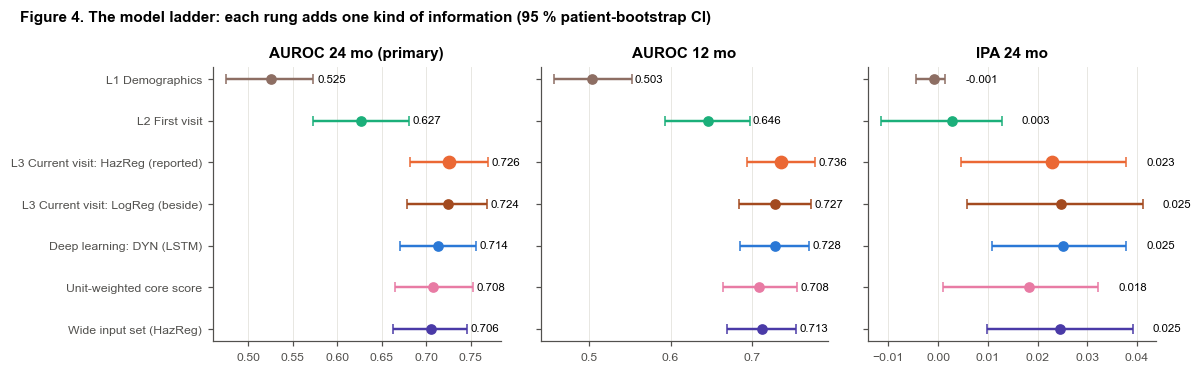

In [16]:
"""The model ladder: every rung on the primary and secondary metrics."""
LADDER_KEYS = [(f"AUROC {H} mo (primary)", K_VIS), ("AUROC 12 mo", K_VIS12), (f"Brier {H} mo", K_BRIER),
               (f"IPA {H} mo", K_IPA), ("Calibration slope", ("visit", H, "cal_slope")), ("O/E", ("visit", H, "oe")),
               ("Time-matched AUROC (secondary)", K_TM)]
_recent = land["CAL_YEAR"].values >= TIER_RECENT_FROM
LADDER_SHOW = LADDER_RUN + [m for m in (OTHER, SEQ_MAIN, UNIT, HZ_FULL) if m in MODELS_RUN]
LAD_RECENT = {m: sub_visit(m, _recent)[0] for m in LADDER_SHOW}


def within_era_auroc(m):
    """Era-specific visit AUROCs (point + bootstrap) averaged with weights = onset landmarks of each era."""
    parts = [sub_visit(m, LAND_SUB["era"].values == e) for _, _, e in ERA_BANDS]
    w = np.array([n_ for _, n_ in parts], float)
    return np.nansum(np.vstack([p_["auroc"] for p_, _ in parts]) * (w / w.sum())[:, None], 0)


WITHIN_ERA = {m: within_era_auroc(m) for m in LADDER_SHOW}
LADDER_TABLE = pd.DataFrame([{"Rung": LADDER_LABELS[m], **{lab_: fmtk((m,) + k, 4 if "Brier" in lab_ else 3)
                                                          for lab_, k in LADDER_KEYS},
                              f"Within-era AUROC {H} mo": fci(WITHIN_ERA[m]),
                              f"Recent era (>= {TIER_RECENT_FROM}): AUROC": fci(LAD_RECENT[m]["auroc"]),
                              f"Recent era: O/E": fci(LAD_RECENT[m]["oe"], 2)} for m in LADDER_SHOW]).set_index("Rung")
display(LADDER_TABLE)
LADDER_TABLE.to_csv(f"aim1_ladder_{TAG}.csv")
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
yy = np.arange(len(LADDER_SHOW))[::-1]
for ax, (lab_, key) in zip(axes, [LADDER_KEYS[0], LADDER_KEYS[1], LADDER_KEYS[3]]):
    for y_, m in zip(yy, LADDER_SHOW):
        a = ci((m,) + key)
        ax.errorbar(a[0], y_, xerr=[[a[0] - a[1]], [a[2] - a[0]]], fmt="o", color=model_color(m), capsize=3,
                    ms=8 if m == REPORTED else 6)
        ax.text(a[2] + 0.004, y_, f"{a[0]:.3f}", va="center", fontsize=7.5)
    ax.set_title(lab_); ax.grid(axis="y", visible=False)
axes[0].set_yticks(yy); axes[0].set_yticklabels([LADDER_LABELS[m] for m in LADDER_SHOW])
fig.suptitle("Figure 4. The model ladder: each rung adds one kind of information (95 % patient-bootstrap CI)",
             x=0.02, ha="left", fontsize=10, fontweight="bold")
plt.tight_layout(); save_fig("fig04_ladder")

## 13.2 What each step adds (H1, H1a-d)

Metric,AUROC 24 mo,AUROC 12 mo,IPA 24 mo,Time-matched AUROC
Comparison,,,,
HazReg - L1 Demographics,0.200 (0.143 to 0.256),0.232 (0.174 to 0.287),0.024 (0.006 to 0.038),0.204 (0.149 to 0.257)
L2 First visit - L1 Demographics,0.102 (0.046 to 0.163),0.143 (0.090 to 0.200),0.003 (-0.011 to 0.014),0.093 (0.044 to 0.145)
HazReg - L2 First visit,0.099 (0.053 to 0.144),0.090 (0.043 to 0.135),0.020 (0.002 to 0.037),0.111 (0.067 to 0.153)
HazReg - HazReg wide,0.020 (0.001 to 0.039),0.023 (0.003 to 0.043),-0.002 (-0.012 to 0.008),0.020 (-0.001 to 0.041)
HazReg - Unit score,0.018 (-0.013 to 0.047),0.027 (-0.004 to 0.058),0.005 (-0.008 to 0.018),0.020 (-0.010 to 0.051)
LogReg - HazReg,-0.001 (-0.016 to 0.014),-0.008 (-0.023 to 0.007),0.002 (-0.007 to 0.011),-0.012 (-0.026 to 0.003)
DYN - HazReg,-0.012 (-0.030 to 0.005),-0.008 (-0.027 to 0.012),0.002 (-0.006 to 0.013),-0.013 (-0.034 to 0.006)


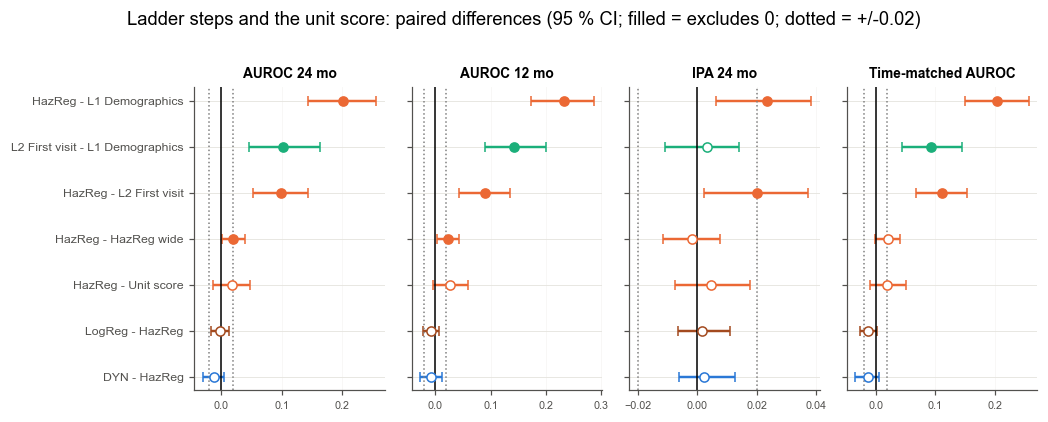

,Within-era AUROC difference,Pooled AUROC difference
Comparison,,
HazReg - L1 Demographics,0.181 (0.125 to 0.235),0.200 (0.143 to 0.256)
L2 First visit - L1 Demographics,0.080 (0.024 to 0.143),0.102 (0.046 to 0.163)
HazReg - L2 First visit,0.101 (0.053 to 0.148),0.099 (0.053 to 0.144)
HazReg - HazReg wide,0.018 (-0.002 to 0.038),0.020 (0.001 to 0.039)
HazReg - Unit score,0.012 (-0.018 to 0.041),0.018 (-0.013 to 0.047)
LogReg - HazReg,0.000 (-0.015 to 0.016),-0.001 (-0.016 to 0.014)
DYN - HazReg,-0.011 (-0.031 to 0.009),-0.012 (-0.030 to 0.005)


In [17]:
"""Paired differences between the rungs."""
STEP_PAIRS = [(a, b) for a, b in [(REPORTED, L1_DEMO), (L2_FIRST, L1_DEMO), (REPORTED, L2_FIRST), (REPORTED, HZ_FULL),
                                   (REPORTED, UNIT), (OTHER, REPORTED), (SEQ_MAIN, REPORTED)]
              if a in MODELS_RUN and b in MODELS_RUN]
STEP_KEYS = [(f"AUROC {H} mo", K_VIS), ("AUROC 12 mo", K_VIS12), (f"IPA {H} mo", K_IPA), ("Time-matched AUROC", K_TM)]
STEPS = compare(STEP_PAIRS, keys=STEP_KEYS)
show_cmp(STEPS)
STEPS.to_csv(f"aim1_ladder_steps_{TAG}.csv", index=False)
forest(STEPS, "Comparison", [k for k, _ in STEP_KEYS], "Ladder steps and the unit score: paired differences (95 % CI; filled = excludes "
       "0; dotted = +/-0.02)", "fig05_ladder_steps", color_of={f"{short_label(a)} - {short_label(b)}": model_color(a)
                                                              for a, b in STEP_PAIRS}.get, margin=EQUIV_MARGIN)
_EQ = f"equivalence (CI within +/-{EQUIV_MARGIN})"
WITHIN_ERA_STEPS = pd.DataFrame([{"Comparison": f"{short_label(a)} - {short_label(b)}",
                                  "Within-era AUROC difference": fci(WITHIN_ERA[a] - WITHIN_ERA[b]),
                                  "Pooled AUROC difference": fmt(*diff(a, b, K_VIS)[:3])}
                                 for a, b in STEP_PAIRS if a in WITHIN_ERA and b in WITHIN_ERA]).set_index("Comparison")
display(WITHIN_ERA_STEPS)
WITHIN_ERA_STEPS.to_csv(f"aim1_ladder_steps_within_era_{TAG}.csv")
for lab_, (a, b), crit in [("H1 (primary)", (REPORTED, L1_DEMO), "sup"), ("H1a", (L2_FIRST, L1_DEMO), "sup"),
                           ("H1b", (REPORTED, L2_FIRST), "sup"), ("H1c", (REPORTED, HZ_FULL), "eq"),
                           ("H1d", (REPORTED, UNIT), "sup")]:
    if a in MODELS_RUN and b in MODELS_RUN:
        d = diff(a, b, K_VIS)
        met = d[1] > 0 if crit == "sup" else (d[1] > -EQUIV_MARGIN and d[2] < EQUIV_MARGIN)
        hyp(lab_, f"{short_label(a)} - {short_label(b)}, visit AUROC {H} months", d,
            "lower bound > 0" if crit == "sup" else _EQ, met, verdict_superiority(d[1], d[2], EQUIV_MARGIN))

## 13.3 Is the first-visit rung a fair comparator? The ladder by time in clinic

A risk frozen at the first employed visit must lose accuracy as the years pass, so "updating beats the first visit"
partly means "recent information beats old information". The visit AUROC of every rung by years since the first
clinic visit at the landmark shows where reassessment matters: if L3 − L2 is near 0 early and grows later, the
advantage of updating is mostly about staleness. L3 − L1 shows where the clinical data add to demographics.

,Landmarks,Onset landmarks,L1 Demographics,L2 First visit,HazReg,L3 - L2,L3 - L1
Years in clinic,,,,,,,
< 2 years in clinic,4007,182,0.496 (0.423 to 0.575),0.661 (0.587 to 0.733),0.730 (0.677 to 0.784),0.069 (0.015 to 0.125),0.234 (0.154 to 0.309)
2-5 years,3925,116,0.604 (0.498 to 0.708),0.710 (0.603 to 0.805),0.825 (0.747 to 0.898),0.116 (0.056 to 0.188),0.221 (0.125 to 0.326)
5-10 years,4421,158,0.498 (0.413 to 0.575),0.585 (0.477 to 0.686),0.662 (0.567 to 0.751),0.077 (-0.039 to 0.182),0.165 (0.057 to 0.274)
>= 10 years,4985,111,0.558 (0.449 to 0.670),0.484 (0.369 to 0.615),0.676 (0.553 to 0.782),0.191 (0.052 to 0.314),0.118 (-0.044 to 0.263)


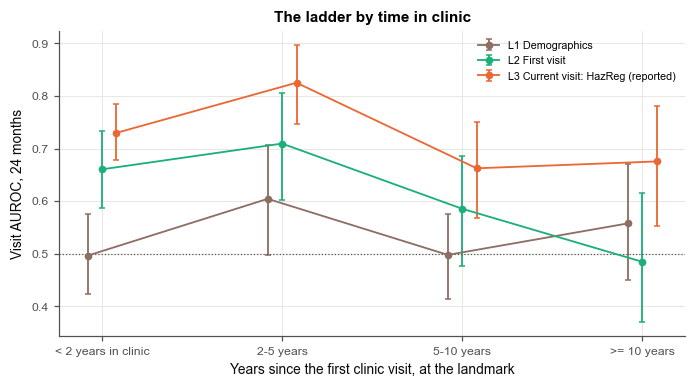

In [18]:
"""The ladder by years in clinic."""
_yic = land["YRS_IN_CLINIC"].values
rows, LAD_SUB = [], {}
for lo, hi, name in CLINIC_YEAR_BANDS:
    mask = (_yic >= lo) & (_yic < hi)
    for m in LADDER_RUN:
        LAD_SUB[(m, name)], n_ev = sub_visit(m, mask)
    row = {"Years in clinic": name, "Landmarks": int(mask.sum()), "Onset landmarks": n_ev}
    row.update({short_label(m): fci(LAD_SUB[(m, name)]["auroc"]) for m in LADDER_RUN})
    if REPORTED in MODELS_RUN and L2_FIRST in MODELS_RUN:
        row["L3 - L2"] = fci(LAD_SUB[(REPORTED, name)]["auroc"] - LAD_SUB[(L2_FIRST, name)]["auroc"])
    if REPORTED in MODELS_RUN and L1_DEMO in MODELS_RUN:
        row["L3 - L1"] = fci(LAD_SUB[(REPORTED, name)]["auroc"] - LAD_SUB[(L1_DEMO, name)]["auroc"])
    rows.append(row)
LADDER_CLINIC = pd.DataFrame(rows).set_index("Years in clinic")
display(LADDER_CLINIC)
LADDER_CLINIC.to_csv(f"aim1_ladder_by_years_in_clinic_{TAG}.csv")
fig, ax = plt.subplots(figsize=(6.4, 3.6))
xx = np.arange(len(CLINIC_YEAR_BANDS))
for j, m in enumerate(LADDER_RUN):
    v = np.array([[LAD_SUB[(m, n)]["auroc"][0], *np.nanpercentile(LAD_SUB[(m, n)]["auroc"][1:], [2.5, 97.5])]
                  for _, _, n in CLINIC_YEAR_BANDS])
    off = (j - (len(LADDER_RUN) - 1) / 2) * 0.08
    ax.errorbar(xx + off, v[:, 0], yerr=[v[:, 0] - v[:, 1], v[:, 2] - v[:, 0]], fmt="o-", ms=4, capsize=2, lw=1.2,
                color=model_color(m), label=LADDER_LABELS[m])
ax.axhline(0.5, color=INK_2, lw=0.8, ls=":")
ax.set_xticks(xx); ax.set_xticklabels([n for _, _, n in CLINIC_YEAR_BANDS])
ax.set_xlabel("Years since the first clinic visit, at the landmark"); ax.set_ylabel(f"Visit AUROC, {H} months")
ax.legend(fontsize=7); ax.set_title("The ladder by time in clinic")
plt.tight_layout(); save_fig("fig06_ladder_by_time_in_clinic")

## 13.4 Conclusion — Aim 1

In [19]:
"""Aim 1 conclusion."""
_h1 = [r_ for r_ in HYP_ROWS if r_["Hypothesis"].startswith("H1")]
txt = ("Visit AUROC at 24 months by rung: " + "; ".join(f"{LADDER_LABELS[m]} {fmtk((m,) + K_VIS)}" for m in LADDER_RUN)
       + ". Within-era AUROC: " + ", ".join(f"{short_label(m)} {fci(WITHIN_ERA[m])}" for m in LADDER_RUN)
       + ". IPA: " + ", ".join(f"{short_label(m)} {ci((m,) + K_IPA)[0]:.3f}" for m in LADDER_RUN) + ". Steps: "
       + "; ".join(f"{r_['Hypothesis']} {r_['Estimand']} {r_['Estimate (95% CI)']} ({r_['Verdict']})" for r_ in _h1)
       + ".")
OBJ_CONCLUSIONS["Aim 1 (signal: the ladder)"] = txt
print(textwrap.fill(txt, 118))

Visit AUROC at 24 months by rung: L1 Demographics 0.525 (0.475 to 0.573); L2 First visit 0.627 (0.572 to 0.681); L3
Current visit: HazReg (reported) 0.726 (0.682 to 0.769). Within-era AUROC: L1 Demographics 0.527 (0.479 to 0.579), L2
First visit 0.607 (0.550 to 0.666), HazReg 0.708 (0.666 to 0.752). IPA: L1 Demographics -0.001, L2 First visit 0.003,
HazReg 0.023. Steps: H1 (primary) HazReg - L1 Demographics, visit AUROC 24 months 0.200 (0.143 to 0.256) (superior);
H1a L2 First visit - L1 Demographics, visit AUROC 24 months 0.102 (0.046 to 0.163) (superior); H1b HazReg - L2 First
visit, visit AUROC 24 months 0.099 (0.053 to 0.144) (superior); H1c HazReg - HazReg wide, visit AUROC 24 months 0.020
(0.001 to 0.039) (superior); H1d HazReg - Unit score, visit AUROC 24 months 0.018 (-0.013 to 0.047) (inconclusive).


---
# 14. Aim 2 — The stratification tool: the reported model

The reported model, **HazReg**, reads the **compact current-visit inputs** (20 variables at the landmark visit;
3-knot restricted cubic splines for prednisone dose, SDI, SLEDAI-2K and age; Section 5): two ridge Poisson
regressions, the cause-specific hazards of onset and of a competing exit (retirement, other exits), constant over the
interval from one landmark to the next and fitted on **every** at-risk interval, so recent visits with partial
follow-up also count. The 24-month risk is the cumulative incidence of onset, λ₁/(λ₁+λ₂)·(1 − exp(−2(λ₁+λ₂))) with
λ per year. Coefficients are hazard ratios. Its output is a **risk tier** at every visit (Section 14.5).

Beside it throughout, **LogReg**: a ridge logistic regression of the 24-month label on the same inputs (a competing
exit within 24 months counts as no onset; landmarks whose 24-month status is unresolved are left out of the fit).
Both choose their ridge penalty on the inner-fold Poisson deviance / log-loss (Section 11.5).

In [20]:
print(textwrap.fill(SELECTION_TEXT, 118))
if "SELECTION" in globals():
    display(SELECTION)

Reported model: HazReg, visit AUROC 0.726 (0.682 to 0.769), IPA 0.023 (0.005 to 0.038). Beside it, LogReg: AUROC 0.724
(0.679 to 0.769) (difference -0.001 (-0.016 to 0.014)), IPA 0.025 (0.006 to 0.041).


,HazReg,LogReg,LogReg - HazReg
Metric,,,
Visit AUROC 24 mo (primary),0.726 (0.682 to 0.769),0.724 (0.679 to 0.769),-0.001 (-0.016 to 0.014)
Visit AUROC 12 mo,0.736 (0.693 to 0.777),0.727 (0.684 to 0.772),-0.008 (-0.023 to 0.007)
Time-matched AUROC,0.745 (0.707 to 0.784),0.733 (0.692 to 0.774),-0.012 (-0.026 to 0.003)
IPA 24 mo,0.023 (0.005 to 0.038),0.025 (0.006 to 0.041),0.002 (-0.007 to 0.011)
Brier 24 mo,0.0330 (0.0275 to 0.0389),0.0329 (0.0274 to 0.0387),-0.0001 (-0.0004 to 0.0002)
Calibration slope,1.069 (0.860 to 1.270),0.964 (0.759 to 1.166),-0.106 (-0.186 to -0.016)
O/E,0.969 (0.802 to 1.145),0.967 (0.801 to 1.151),-0.003 (-0.022 to 0.020)


## 14.1 Performance: tables and figures

HazReg: cause-specific Poisson hazard regression on the current visit (compact set, splines) [reported model]


,Visit level,Patient windows (descriptive)
Metric,,
"AUROC, 24 months (IPCW; primary)",0.726 (0.682 to 0.769),0.791 (0.751 to 0.833)
"AUROC, 12 months (IPCW)",0.736 (0.693 to 0.777),0.790 (0.750 to 0.833)
"Brier score, 24 months (IPCW)",0.0330 (0.0275 to 0.0389),-
"IPA, 24 months (1 - Brier / null Brier)",0.023 (0.005 to 0.038),-
Time-matched patient AUROC (secondary: calendar-time check),-,0.745 (0.707 to 0.784)
Time-matched patient sensitivity / specificity,-,0.710 / 0.654
Risk-set C (calendar-time risk sets),-,0.745 (0.706 to 0.784)
Calibration slope,1.069 (0.860 to 1.270),1.113 (0.933 to 1.323)
Calibration intercept,-0.049 (-0.221 to 0.129),-0.010 (-0.190 to 0.194)


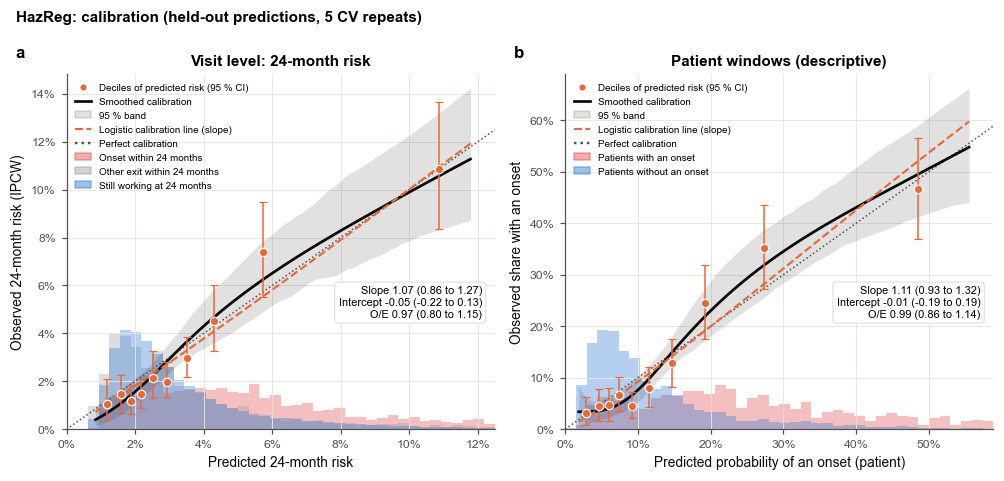

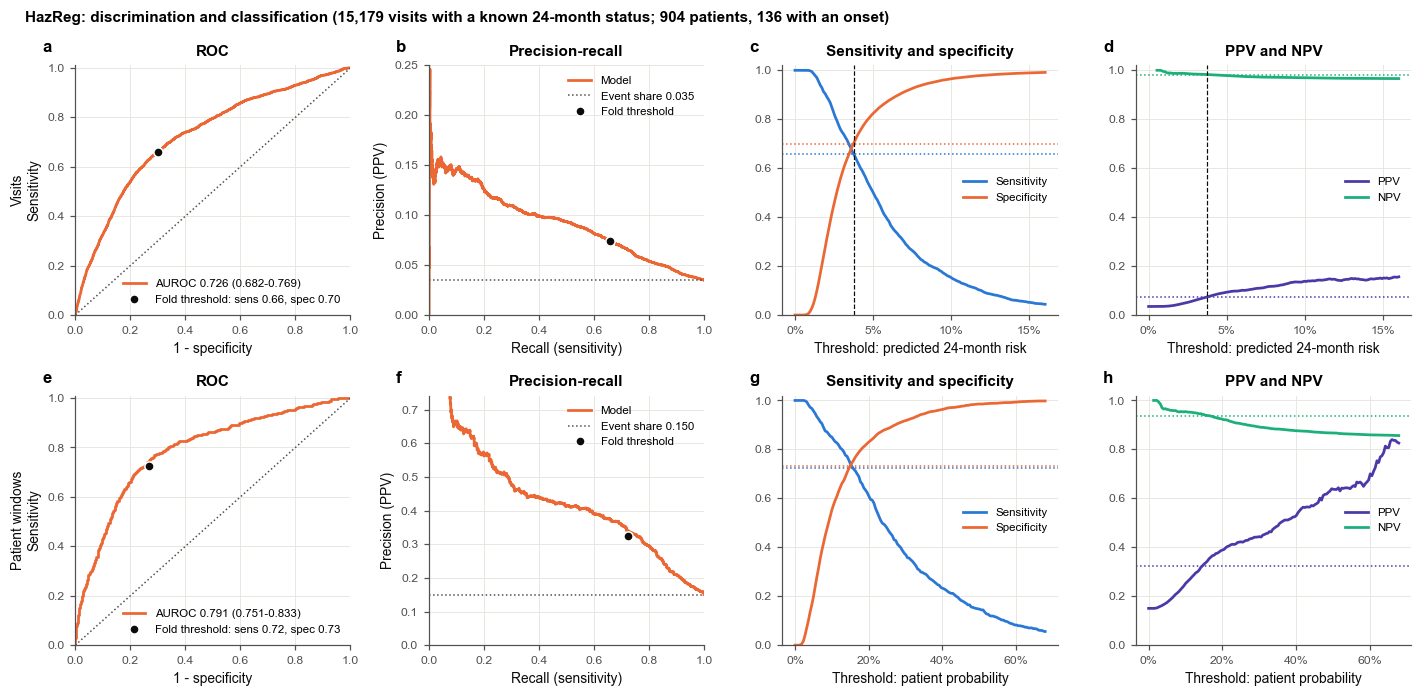

In [21]:
model_section(REPORTED)

## 14.2 The fitted model: coefficients, specification and bootstrap refits

HazReg and LogReg refitted on **every patient** with their most-chosen CV penalty: the models one would publish and
use. Coefficients are on the standardised scale (per SD of each input after the signed log transform; Section
11.4), so their sizes are comparable; the ratio per SD is exp(coefficient): an odds ratio for LogReg, a hazard ratio
for HazReg (onset; the competing-exit hazard ratios alongside). A spline term has no meaning on its own: read it
through the risk curves of Section 14.2b. The table `aim2_reported_model_specification_*.csv` holds every number
needed to apply the reported model to a new visit (transform, clipping, imputation median, spline knots, mean, SD,
coefficients, intercepts, and the recalibration map of the 24-month logit; TRIPOD+AI item 22).

**Bootstrap refits** (Riley & Collins 2023): the same procedure (preprocessing + fit, the penalty held at the
chosen value) repeated on 200 bootstrap samples of patients, for each model. They give the coefficients' 95 %
percentile intervals, the bands of Section 14.2b and the prediction-instability analysis of Section 14.6. The penalty
is not re-tuned in each bootstrap sample (a simplification: re-tuning would add instability).

In [22]:
"""HazReg and LogReg on every patient; bootstrap refits (coefficient intervals and prediction instability)."""
_ALL_ROWS = np.arange(N_LAND)


def _prep_rows(m, rows):
    return rows[LABELLED[rows]] if parse_model(m)["target"] == "BIN" else rows


def fit_full(m, cfg, rows):
    """Fit regression m on the landmark rows `rows` (whole patients, repeats allowed). Returns the raw 24-month logit at
    every landmark, the preprocessing, and the parameters [(intercept, coefficients)] (one pair per cause)."""
    eta, (prep, fits) = fit_reg(m, cfg, _prep_rows(m, rows), rows, _ALL_ROWS)
    return raw_logit(eta, H), prep, [(float(np.ravel(f_.intercept_)[0]), f_.coef_.ravel().copy()) for f_ in fits]


def logit_of(params, Z):
    """Raw 24-month logit from preprocessed inputs Z and parameters (LogReg: the logit; HazReg: the CIF's logit)."""
    return raw_logit(np.column_stack([b0 + Z @ b for b0, b in params]), H)


def fold_recal_map(m):
    """The recalibration map of the 24-month logit: the mean over the CV folds of the per-fold maps (Section 7)."""
    ab = []
    for (m_, r_, f_), res_ in ALL_FOLDS.items():
        if m_ == m and r_ in REPEATS:
            zo_ = raw_logit(res_["eta_oof"].astype(float), H)
            lab_ = LABEL_H[H][res_["tr_rows"]]
            k_ = ~np.isnan(lab_) & ~np.isnan(zo_)
            rc_ = Recalibrator().fit(zo_[k_], lab_[k_])
            ab.append((rc_.a, rc_.b))
    return tuple(np.mean(ab, 0))


INSTAB_PATH = f"instability_{TAG}{'_smoke' if SMOKE else ''}.pkl"
INSTAB_ALL = _load(INSTAB_PATH, {})
FINAL = {}
for m in [c for c in (REPORTED, OTHER) if c in MODELS_RUN]:
    cfg_name = pd.Series(BEST_CFG[m]).value_counts().index[0]
    cfg = model_grid(m)[cfg_name]
    z_f, prep_f, par_f = fit_full(m, cfg, _ALL_ROWS)
    st = INSTAB_ALL.get(m, {})
    if st.get("B") != INSTAB_B or st.get("cfg") != cfg_name:
        t0 = time.time()
        rng_ = np.random.RandomState(SEED + 2024)
        zb, pb = [], []
        for b in range(INSTAB_B):
            pids_b = rng_.choice(ALL_PIDS, len(ALL_PIDS), replace=True)
            z_b, _, p_b = fit_full(m, cfg, np.concatenate([PT_ROWS[p] for p in pids_b]))
            zb.append(z_b.astype(np.float32)); pb.append(p_b)
        st = {"B": INSTAB_B, "cfg": cfg_name, "z": np.vstack(zb), "params": pb}
        INSTAB_ALL[m] = st
        _save(INSTAB_ALL, INSTAB_PATH)
        print(f"{short_label(m)}: {INSTAB_B} bootstrap refits in {(time.time() - t0) / 60:.1f} min")
    FINAL[m] = {"cfg": cfg_name, "z": z_f, "prep": prep_f, "params": par_f, "recal": fold_recal_map(m),
                "boot_z": st["z"], "boot_params": st["params"]}


def coef_table(m):
    """Coefficients of regression m on all patients, with bootstrap intervals (onset; competing exit for HazReg)."""
    F = FINAL[m]
    names = F["prep"].names
    hz = len(F["params"]) == 2
    ratio = "Hazard ratio per SD (onset)" if hz else "Odds ratio per SD"
    c1 = F["params"][0][1]
    b1 = np.vstack([p_[0][1] for p_ in F["boot_params"]])
    lo, hi = np.percentile(b1, [2.5, 97.5], 0)
    t = pd.DataFrame({"Input": [sh_display_any(c) for c in names],
                      "Domain": [FEATURE_GROUP.get(c, FEATURE_GROUP.get(c.split("__")[0], "Other"))
                                 if not c.endswith("__MISSING") else "Missing-value indicators" for c in names],
                      "Coefficient (per SD)": c1, ratio: np.exp(c1),
                      "95 % bootstrap interval": [f"{np.exp(a):.2f}-{np.exp(b):.2f}" for a, b in zip(lo, hi)],
                      "Interval excludes 1": (lo > 0) | (hi < 0)}, index=names)
    if hz:
        c2 = F["params"][1][1]
        lo2, hi2 = np.percentile(np.vstack([p_[1][1] for p_ in F["boot_params"]]), [2.5, 97.5], 0)
        t["Competing exit: HR per SD"] = np.exp(c2)
        t["Competing exit: 95 % interval"] = [f"{np.exp(a):.2f}-{np.exp(b):.2f}" for a, b in zip(lo2, hi2)]
    return t.reindex(t["Coefficient (per SD)"].abs().sort_values(ascending=False).index), ratio


F_REP = FINAL[REPORTED]
Z_FINAL, PREP_FINAL, PARAMS_FINAL, RECAL_FINAL = F_REP["z"], F_REP["prep"], F_REP["params"], F_REP["recal"]
Z_BOOT, PARAMS_BOOT = F_REP["boot_z"], F_REP["boot_params"]
COEF_TABLE, RATIO_COL = coef_table(REPORTED)
_names = PREP_FINAL.names
_coef = PARAMS_FINAL[0][1]
print(f"Reported model ({short_label(REPORTED)}) on all {N_LAND:,} landmarks ({int(LABELLED.sum()):,} with a known "
      f"{H}-month status): penalty {F_REP['cfg']}, {len(_names)} columns (spline knots: " + ", ".join(
          f"{sh_display_any(c)} {', '.join(f'{k:.2f}' for k in kn)}" for c, kn in PREP_FINAL.knots.items())
      + f"); {int(COEF_TABLE['Interval excludes 1'].sum())} coefficients with a bootstrap interval excluding 1. "
      f"Recalibration of the {H}-month logit (mean over CV folds): {RECAL_FINAL[0]:.3f} + {RECAL_FINAL[1]:.3f} x logit.")
display(COEF_TABLE.round(3))
COEF_TABLE.to_csv(f"aim2_reported_model_coefficients_{TAG}.csv")
_nc = len(PREP_FINAL.cols)
_ncol = [f"coefficient ({lab_})" for lab_ in (["onset", "competing exit"] if len(PARAMS_FINAL) == 2 else ["logit"])]
_spec = pd.DataFrame({"column": PREP_FINAL.cols, "signed log1p": [c in LOG1P_VARS for c in PREP_FINAL.cols],
                      "clip low": [PREP_FINAL.clip.get(c, (np.nan, np.nan))[0] for c in PREP_FINAL.cols],
                      "clip high": [PREP_FINAL.clip.get(c, (np.nan, np.nan))[1] for c in PREP_FINAL.cols],
                      "imputation median": PREP_FINAL.med.reindex(PREP_FINAL.cols).values,
                      "spline knots (transformed scale)": [", ".join(f"{k:.4f}" for k in PREP_FINAL.knots[c])
                                                           if c in PREP_FINAL.knots else "" for c in PREP_FINAL.cols],
                      "mean": PREP_FINAL.mu.reindex(PREP_FINAL.cols).values,
                      "sd": PREP_FINAL.sd.reindex(PREP_FINAL.cols).values,
                      **{lab_: p_[1][:_nc] for lab_, p_ in zip(_ncol, PARAMS_FINAL)}})
_nl = [c for c in _names[_nc:] if c.endswith("__NL")]
_spec = pd.concat([_spec,
                   pd.DataFrame({"column": list(_names[_nc:]),
                                 "mean": [PREP_FINAL.mu.get(c, np.nan) for c in _names[_nc:]],
                                 "sd": [PREP_FINAL.sd.get(c, np.nan) for c in _names[_nc:]],
                                 **{lab_: p_[1][_nc:] for lab_, p_ in zip(_ncol, PARAMS_FINAL)}}),
                   pd.DataFrame({"column": ["(intercept)", "(recalibration: intercept)", "(recalibration: slope)"],
                                 **{lab_: [p_[0], RECAL_FINAL[0] if j == 0 else np.nan,
                                           RECAL_FINAL[1] if j == 0 else np.nan]
                                    for j, (lab_, p_) in enumerate(zip(_ncol, PARAMS_FINAL))}})])
_spec.to_csv(f"aim2_reported_model_specification_{TAG}.csv", index=False)
# linear attributions of the (onset) linear predictor (coefficient x centred standardised input), for 14.2b
_X_ALL = PREP_FINAL.transform(LAND_X)
LIN_ATTR = _coef[None, :] * (_X_ALL - _X_ALL.mean(0))
LIN_IMP = pd.Series(np.abs(LIN_ATTR).mean(0), index=_names)

HazReg: 200 bootstrap refits in 0.7 min
LogReg: 200 bootstrap refits in 0.3 min
Reported model (HazReg) on all 17,338 landmarks (15,148 with a known 24-month status): penalty a0.001, 34 columns (spline knots: Prednisone, average dose since last visit (mg/day) 1.18, 2.47, 3.73, SDI damage score 0.00, 0.69, 1.79, SLEDAI-2K 0.00, 1.10, 2.20, Age 27.87, 41.68, 56.40); 10 coefficients with a bootstrap interval excluding 1. Recalibration of the 24-month logit (mean over CV folds): -1.046 + 0.660 x logit.


,Input,Domain,Coefficient (per SD),Hazard ratio per SD (onset),95 % bootstrap interval,Interval excludes 1,Competing exit: HR per SD,Competing exit: 95 % interval
EDU_HIGHER__MISSING,Education: higher: missing,Missing-value indicators,-0.506,0.603,0.46-0.90,True,5.646,4.44-7.82
age_at_record__NL,Age: spline term,Demographics,0.321,1.379,1.07-1.75,True,2.015,1.50-2.54
YRS_IN_CLINIC,Years since the first clinic visit,Care pattern,-0.308,0.735,0.60-0.91,True,0.968,0.83-1.17
SLEDAI2_I__NL,SLEDAI-2K: spline term,Disease activity,0.261,1.298,1.01-1.59,True,0.826,0.65-1.03
score_n,SDI damage score,Damage,0.257,1.293,1.04-1.66,True,0.874,0.69-1.12
TREAT_STEP,EULAR treatment step (0-4),Treatment,0.210,1.233,0.98-1.50,False,1.125,0.87-1.39
TENDER_POINTS__MISSING,Fibromyalgia tender points (0-18): missing,Missing-value indicators,-0.207,0.813,0.61-1.16,False,0.730,0.55-1.01
TENDER_POINTS,Fibromyalgia tender points (0-18),Pain,0.206,1.229,1.00-1.51,False,1.055,0.89-1.23
STERAVER_0,"Prednisone, average dose since last visit (mg/...",Treatment,0.198,1.219,0.99-1.66,False,1.539,1.22-2.15
FIBROMYALGIA,Fibromyalgia,Symptoms,0.177,1.193,1.02-1.39,True,0.923,0.78-1.08


## 14.2b Risk factors: what drives the reported model's risk

The regression's coefficients are the explanation; no post-hoc attribution method is needed. Three views, from the
model fitted on all patients (95 % intervals from the 200 bootstrap refits):

* **(a) Ratios per SD** (odds ratios for LogReg; onset hazard ratios for HazReg), grouped by domain: the inputs whose
  bootstrap interval excludes 1, and the largest others. Spline terms are left out of this panel (see (c)).
* **(b) How much each domain moves the risk**: the mean absolute contribution of each domain's inputs (spline terms
  included) to the linear predictor, as a share of the total.
* **(c) The risk across each factor's range**: the average predicted 24-month risk (recalibrated) when one
  continuous input is set to each value between its 5th and 95th percentile at every landmark of a random sample,
  the other inputs left as observed (an average marginal effect), with a bootstrap band; this is where the splines
  show. For binary inputs, the average risk with the factor present vs absent.

These are **associations within a prediction model**, adjusted for the other inputs: they say which recorded
characteristics mark patients at risk, not what would change the risk if altered.

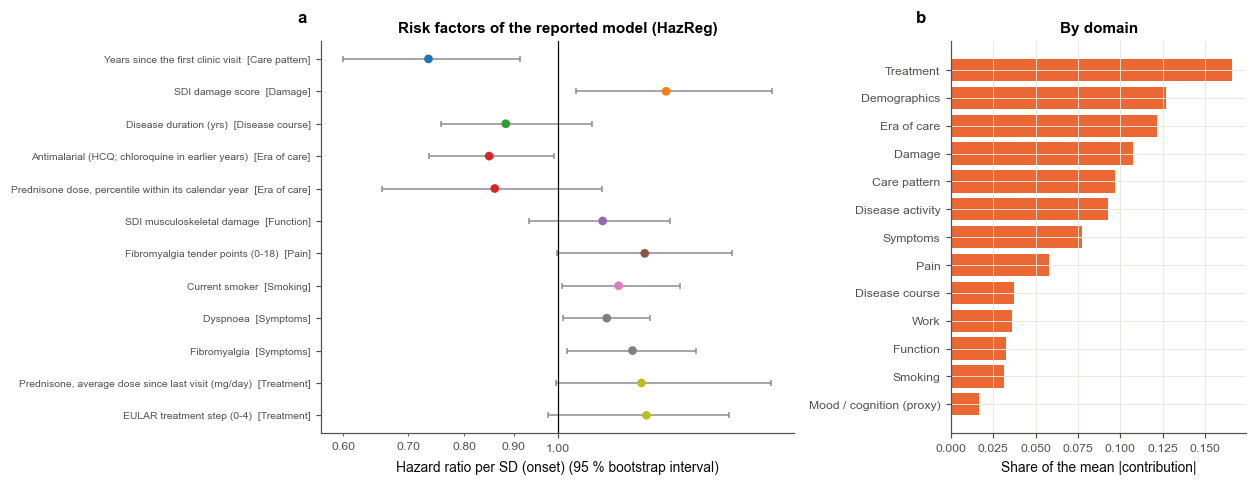

,Share of the linear predictor's mean |contribution|
Treatment,0.166
Demographics,0.127
Era of care,0.122
Damage,0.107
Care pattern,0.097
Disease activity,0.093
Symptoms,0.077
Pain,0.058
Disease course,0.037
Work,0.036


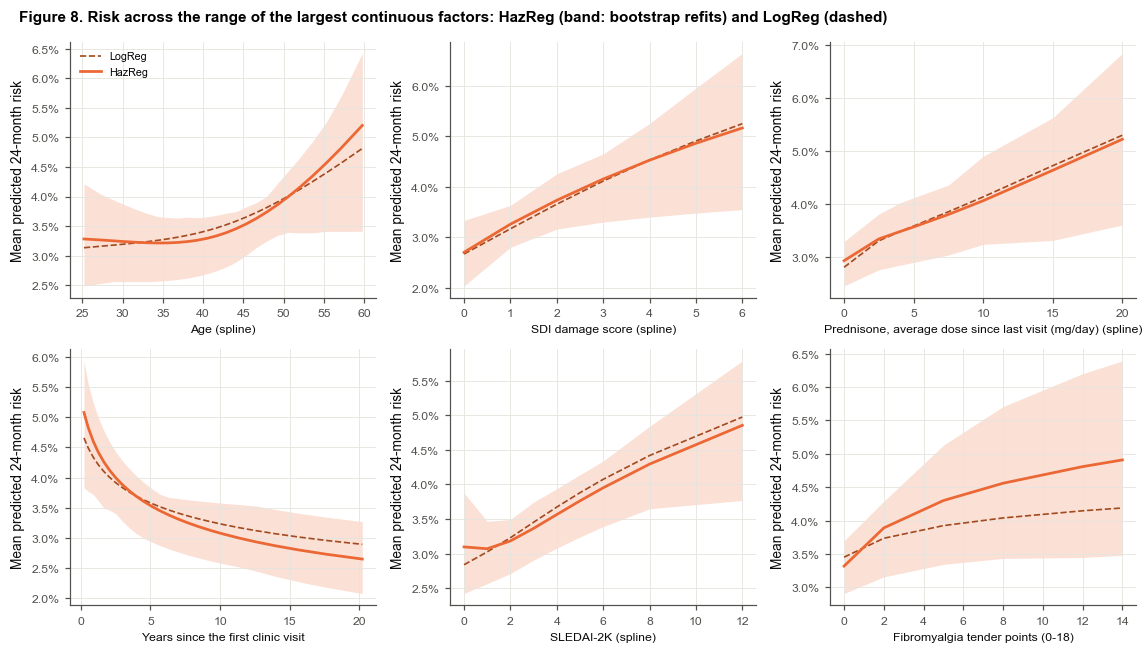

,Share of landmarks with it,"Mean 24-month risk, present",absent,Risk ratio
Factor,,,,
Fibromyalgia,11%,5.0%,3.4%,1.47 (1.07-1.99)
Antimalarial (HCQ; chloroquine in earlier years),74%,3.4%,4.3%,0.79 (0.70-0.92)
Current smoker,9%,4.8%,3.5%,1.38 (1.03-1.73)
Dyspnoea,3%,5.2%,3.5%,1.47 (1.05-2.29)
Fatigue,10%,4.3%,3.5%,1.24 (1.01-1.67)
Education: higher,48%,3.5%,4.0%,0.89 (0.69-1.02)
Advanced therapy (IV CYC; later biologics),3%,3.1%,3.6%,0.86 (0.47-1.32)
"Conventional immunosuppressant (AZA, MTX, MMF)",46%,3.5%,3.7%,0.96 (0.78-1.21)


Largest risk factors of the reported model (hazard ratio per sd (onset)): Years since the first clinic visit 0.73, SDI
damage score 1.29, EULAR treatment step (0-4) 1.23, Fibromyalgia tender points (0-18) 1.23, Prednisone, average dose
since last visit (mg/day) 1.22, Fibromyalgia 1.19. Domains: Treatment 17%, Demographics 13%, Era of care 12%, Damage
11%, Care pattern 10%.


In [23]:
"""Risk factors of the reported model: ratios by domain, domain shares, average marginal effects."""
_show = COEF_TABLE[~COEF_TABLE["Domain"].isin(["Calendar year", "Missing-value indicators"])
                   & ~COEF_TABLE.index.str.endswith("__NL")]
_show = pd.concat([_show[_show["Interval excludes 1"]], _show[~_show["Interval excludes 1"]].head(6)])
_show = _show.sort_values(["Domain", "Coefficient (per SD)"])
_b1 = np.vstack([p_[0][1] for p_ in PARAMS_BOOT])
_ci = np.exp(np.percentile(_b1, [2.5, 97.5], 0))
_ix = [_names.index(c) for c in _show.index]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 0.24 * len(_show) + 1.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
yy = np.arange(len(_show))[::-1]
_dom_col = {d: plt.get_cmap("tab10")(i % 10) for i, d in enumerate(sorted(_show["Domain"].unique()))}
ax.errorbar(_show[RATIO_COL], yy, xerr=[_show[RATIO_COL] - _ci[0, _ix], _ci[1, _ix] - _show[RATIO_COL]],
            fmt="none", ecolor="#8d8d8d", capsize=2, lw=1)
ax.scatter(_show[RATIO_COL], yy, c=[_dom_col[d] for d in _show["Domain"]], s=22, zorder=3)
ax.axvline(1, color="k", lw=0.8); ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{t:.2f}"))
ax.xaxis.set_minor_formatter(plt.FuncFormatter(lambda t, _: f"{t:.2f}"))
ax.set_yticks(yy); ax.set_yticklabels([f"{i}  [{d}]" for i, d in zip(_show["Input"], _show["Domain"])], fontsize=6.8)
ax.set_xlabel(f"{RATIO_COL} (95 % bootstrap interval)"); ax.grid(axis="y", visible=False)
ax.set_title(f"Risk factors of the reported model ({short_label(REPORTED)})")
_dom = pd.Series(LIN_IMP.values, index=[COEF_TABLE.loc[c, "Domain"] for c in LIN_IMP.index]).groupby(level=0).sum()
_cal = float(_dom.get("Calendar year", 0.0))
_dom = _dom.drop(["Calendar year", "Missing-value indicators"], errors="ignore").sort_values()
DOMAIN_SHARE = (_dom / _dom.sum()).rename("Share of the linear predictor's mean |contribution|")
ax = axes[1]
ax.barh(DOMAIN_SHARE.index, DOMAIN_SHARE.values, color=model_color(REPORTED))
ax.set_xlabel("Share of the mean |contribution|"); ax.set_title("By domain")
for a_, l_ in zip(axes, "ab"):
    panel_label(a_, l_, dx=-0.05 if l_ == "a" else -0.12)
plt.tight_layout(); save_fig("fig07_risk_factors")
display(DOMAIN_SHARE.sort_values(ascending=False).to_frame().round(3))


def risk_with(rows, col, value, params=None, F=None):
    """Mean recalibrated 24-month risk over `rows` with input `col` set to `value` (raw scale)."""
    F = F or F_REP
    X = LAND_X.iloc[rows].copy()
    X[col] = value
    lg = logit_of(F["params"] if params is None else params, F["prep"].transform(X))
    return _expit(F["recal"][0] + F["recal"][1] * lg).mean()


_samp = np.random.RandomState(SEED + 5).choice(np.flatnonzero(LABELLED), min(PARTIAL_N_SAMPLE, int(LABELLED.sum())),
                                               replace=False)
_bsel = np.random.RandomState(SEED + 6).choice(len(PARAMS_BOOT), min(40, len(PARAMS_BOOT)), replace=False)
_var_imp = pd.Series({c: LIN_IMP[c] + LIN_IMP.get(f"{c}__NL", 0.0) for c in PREP_FINAL.cols})
_cont = [c for c in _var_imp.sort_values(ascending=False).index if LAND_X[c].nunique() > 6
         and not c.startswith("CAL_YEAR")][:6]
_bin = [c for c in COEF_TABLE.index if c in V2_VARS and set(pd.unique(LAND_X[c].dropna())) <= {0.0, 1.0}][:8]
RISK_CURVES = {}
fig, axes = plt.subplots(2, 3, figsize=(10.5, 6))
for ax, c in zip(axes.ravel(), _cont):
    grid = np.unique(np.nanpercentile(LAND_X[c].astype(float), np.linspace(5, 95, PARTIAL_N_POINTS)))
    for m in [x for x in (OTHER, REPORTED) if x in FINAL]:
        pts = np.array([risk_with(_samp, c, v, F=FINAL[m]) for v in grid])
        RISK_CURVES[(m, c)] = (grid, pts)
        if m == REPORTED:
            bands = np.array([[risk_with(_samp, c, v, PARAMS_BOOT[b]) for v in grid] for b in _bsel])
            ax.fill_between(grid, *np.percentile(bands, [2.5, 97.5], 0), color=model_color(m), alpha=0.2, lw=0)
        ax.plot(grid, pts, color=model_color(m), lw=1.8 if m == REPORTED else 1.1, ls="-" if m == REPORTED else "--",
                label=short_label(m))
    ax.set_xlabel(sh_display_any(c) + (" (spline)" if c in PREP_FINAL.knots else ""), fontsize=8)
    ax.set_ylabel(f"Mean predicted {H}-month risk")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{100 * t:.1f}%"))
axes.ravel()[0].legend(fontsize=7)
fig.suptitle(f"Figure 8. Risk across the range of the largest continuous factors: {short_label(REPORTED)} (band: "
             f"bootstrap refits) and {short_label(OTHER)} (dashed)", x=0.02, ha="left", fontsize=10, fontweight="bold")
plt.tight_layout(); save_fig("fig08_risk_factor_effects")
rows = []
for c in _bin:
    p1, p0 = risk_with(_samp, c, 1.0), risk_with(_samp, c, 0.0)
    bs = np.array([(risk_with(_samp, c, 1.0, PARAMS_BOOT[b]), risk_with(_samp, c, 0.0, PARAMS_BOOT[b])) for b in _bsel])
    rr = bs[:, 0] / bs[:, 1]
    rows.append({"Factor": sh_display_any(c), "Share of landmarks with it": f"{np.nanmean(LAND_X[c].astype(float)):.0%}",
                 f"Mean {H}-month risk, present": f"{p1:.1%}", "absent": f"{p0:.1%}",
                 "Risk ratio": f"{p1 / p0:.2f} ({np.percentile(rr, 2.5):.2f}-{np.percentile(rr, 97.5):.2f})"})
BIN_EFFECTS = pd.DataFrame(rows).set_index("Factor")
display(BIN_EFFECTS)
BIN_EFFECTS.to_csv(f"aim2_binary_risk_factors_{TAG}.csv")
_rf = COEF_TABLE[~COEF_TABLE["Domain"].isin(["Calendar year", "Missing-value indicators"])
                 & ~COEF_TABLE.index.str.endswith("__NL")]
RISK_FACTOR_SUMMARY = (f"Largest risk factors of the reported model ({RATIO_COL.lower()}): " + ", ".join(
    f"{r_['Input']} {r_[RATIO_COL]:.2f}" for _, r_ in _rf.head(6).iterrows()) + ". Domains: " + ", ".join(
    f"{d} {v:.0%}" for d, v in DOMAIN_SHARE.sort_values(ascending=False).head(5).items()) + ".")
print(textwrap.fill(RISK_FACTOR_SUMMARY, 118))

## 14.2c HazReg and LogReg side by side

LogReg and HazReg read the same inputs but handle follow-up differently, so agreement between them is a robustness
check on both the risk factors and the predictions:

* **(a) Coefficients**: the odds ratio (LogReg) and the onset hazard ratio (HazReg) per SD of each input, with
  bootstrap intervals; the competing-exit hazard ratios show which inputs mark leaving work for other reasons.
* **(b) Predictions**: the Spearman correlation of the two models' held-out 24-month risks (each CV repeat), and how
  often they put a visit in the same risk tier (cross-tabulation of the tiers).
* **(c) Every metric of both**, from Section 11.10, repeated here for the reader.

,Domain,HazReg: Hazard ratio per SD (onset),HazReg: competing exit HR per SD,LogReg: Odds ratio per SD
Input,,,,
Age: spline term,Demographics,1.38 (1.07-1.75),2.02 (1.50-2.54),1.10 (1.00-1.20)
Years since the first clinic visit,Care pattern,0.73 (0.60-0.91),0.97 (0.83-1.17),0.86 (0.79-0.97)
SLEDAI-2K: spline term,Disease activity,1.30 (1.01-1.59),0.83 (0.65-1.03),1.13 (1.05-1.21)
SDI damage score,Damage,1.29 (1.04-1.66),0.87 (0.69-1.12),1.16 (1.08-1.24)
EULAR treatment step (0-4),Treatment,1.23 (0.98-1.50),1.12 (0.87-1.39),1.05 (0.98-1.13)
Fibromyalgia tender points (0-18),Pain,1.23 (1.00-1.51),1.05 (0.89-1.23),1.07 (0.99-1.15)
"Prednisone, average dose since last visit (mg/day)",Treatment,1.22 (0.99-1.66),1.54 (1.22-2.15),1.17 (1.08-1.25)
Fibromyalgia,Symptoms,1.19 (1.02-1.39),0.92 (0.78-1.08),1.09 (1.00-1.17)
Antimalarial (HCQ; chloroquine in earlier years),Era of care,0.85 (0.74-0.99),0.91 (0.79-1.04),0.86 (0.78-0.95)


LogReg tier,< 2 %,2-4 %,4-10 %,>= 10 %
HazReg tier,,,,
< 2 %,4746,501,1,0
2-4 %,1860,4754,788,0
4-10 %,9,831,2888,353
>= 10 %,0,0,102,505


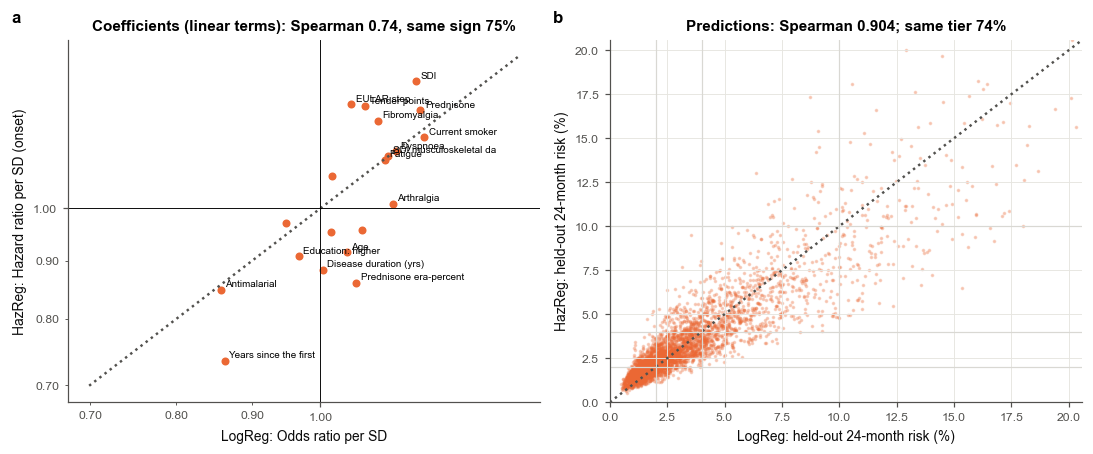

HazReg vs LogReg: linear-term coefficients Spearman 0.74, same sign for 75% of inputs; held-out predictions Spearman
0.904 (mean over repeats); same risk tier at 74% of visits.


,HazReg,LogReg,LogReg - HazReg
Metric,,,
Visit AUROC 24 mo (primary),0.726 (0.682 to 0.769),0.724 (0.679 to 0.769),-0.001 (-0.016 to 0.014)
Visit AUROC 12 mo,0.736 (0.693 to 0.777),0.727 (0.684 to 0.772),-0.008 (-0.023 to 0.007)
Time-matched AUROC,0.745 (0.707 to 0.784),0.733 (0.692 to 0.774),-0.012 (-0.026 to 0.003)
IPA 24 mo,0.023 (0.005 to 0.038),0.025 (0.006 to 0.041),0.002 (-0.007 to 0.011)
Brier 24 mo,0.0330 (0.0275 to 0.0389),0.0329 (0.0274 to 0.0387),-0.0001 (-0.0004 to 0.0002)
Calibration slope,1.069 (0.860 to 1.270),0.964 (0.759 to 1.166),-0.106 (-0.186 to -0.016)
O/E,0.969 (0.802 to 1.145),0.967 (0.801 to 1.151),-0.003 (-0.022 to 0.020)


In [24]:
"""HazReg and LogReg side by side: coefficients, agreement of the predictions, every metric."""
if len(FINAL) == 2:
    _tabs = {m: coef_table(m) for m in FINAL}
    _lr_m = [m for m in FINAL if len(FINAL[m]["params"]) == 1]
    _hz_m = [m for m in FINAL if len(FINAL[m]["params"]) == 2]
    _order = [c for c in COEF_TABLE.index if not c.endswith("__MISSING")]
    rows = []
    for c in _order:
        row = {"Input": sh_display_any(c), "Domain": COEF_TABLE.loc[c, "Domain"]}
        for m in [REPORTED, OTHER]:
            t_, rc_ = _tabs[m]
            if c in t_.index:
                row[f"{short_label(m)}: {rc_}"] = f"{t_.loc[c, rc_]:.2f} ({t_.loc[c, '95 % bootstrap interval']})"
                if "Competing exit: HR per SD" in t_.columns:
                    row[f"{short_label(m)}: competing exit HR per SD"] = (
                        f"{t_.loc[c, 'Competing exit: HR per SD']:.2f} ({t_.loc[c, 'Competing exit: 95 % interval']})")
        rows.append(row)
    BOTH_COEF = pd.DataFrame(rows).set_index("Input")
    display(BOTH_COEF)
    BOTH_COEF.to_csv(f"aim2_hazreg_logreg_coefficients_{TAG}.csv")
    _c1 = pd.Series(FINAL[REPORTED]["params"][0][1], index=FINAL[REPORTED]["prep"].names)
    _c2 = pd.Series(FINAL[OTHER]["params"][0][1], index=FINAL[OTHER]["prep"].names)
    _cc = [c for c in _c1.index if c in _c2.index and not c.endswith(("__MISSING", "__NL"))
           and FEATURE_GROUP.get(c) != "Calendar year"]
    _sign = float(np.mean(np.sign(_c1[_cc]) == np.sign(_c2[_cc])))
    _rho_c = stats.spearmanr(_c1[_cc], _c2[_cc]).correlation
    _rho = [stats.spearmanr(zpred(REPORTED, r)[_rows_ok], zpred(OTHER, r)[_rows_ok]).correlation
            for r in REPEATS for _rows_ok in [np.flatnonzero(~np.isnan(zpred(REPORTED, r)) & ~np.isnan(zpred(OTHER, r)))]]
    _tier_of = lambda p_: np.digitize(p_, [lo for lo, _, _ in RISK_TIERS[1:]])
    _ta, _tb = _tier_of(_expit(mean_z(REPORTED))), _tier_of(_expit(mean_z(OTHER)))
    TIER_AGREE = pd.crosstab(pd.Categorical(np.array([n for _, _, n in RISK_TIERS])[_ta], [n for _, _, n in RISK_TIERS]),
                             pd.Categorical(np.array([n for _, _, n in RISK_TIERS])[_tb], [n for _, _, n in RISK_TIERS]),
                             rownames=[f"{short_label(REPORTED)} tier"], colnames=[f"{short_label(OTHER)} tier"])
    display(TIER_AGREE)
    TIER_AGREE.to_csv(f"aim2_hazreg_logreg_tier_agreement_{TAG}.csv")
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
    ax = axes[0]
    ax.scatter(np.exp(_c2[_cc]), np.exp(_c1[_cc]), s=18, color=model_color(REPORTED))
    for c in _cc:
        if abs(_c1[c]) > 0.08 or abs(_c2[c]) > 0.08:
            ax.annotate(SHORT_NAMES.get(c, sh_display_any(c))[:22], (np.exp(_c2[c]), np.exp(_c1[c])), fontsize=6.5,
                        xytext=(3, 2), textcoords="offset points")
    _lim = np.exp([min(_c1[_cc].min(), _c2[_cc].min()) - 0.05, max(_c1[_cc].max(), _c2[_cc].max()) + 0.05])
    ax.plot(_lim, _lim, ":", color=INK_2); ax.axhline(1, color="k", lw=0.6); ax.axvline(1, color="k", lw=0.6)
    ax.set_xscale("log"); ax.set_yscale("log")
    for _ax_ in (ax.xaxis, ax.yaxis):
        _ax_.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{t:.2f}"))
        _ax_.set_minor_formatter(plt.FuncFormatter(lambda t, _: f"{t:.2f}"))
    ax.set_xlabel(f"{short_label(OTHER)}: {_tabs[OTHER][1]}"); ax.set_ylabel(f"{short_label(REPORTED)}: {RATIO_COL}")
    ax.set_title(f"Coefficients (linear terms): Spearman {_rho_c:.2f}, same sign {_sign:.0%}")
    ax = axes[1]
    _r0 = REPEATS[0]
    _sel = np.random.RandomState(SEED).choice(N_LAND, min(4000, N_LAND), replace=False)
    ax.scatter(100 * _expit(zpred(OTHER, _r0)[_sel]), 100 * _expit(zpred(REPORTED, _r0)[_sel]), s=2, alpha=0.25,
               color=model_color(REPORTED), rasterized=True)
    _t = float(np.nanpercentile(100 * _expit(zpred(REPORTED, _r0)), 99.5))
    ax.plot([0, _t], [0, _t], ":", color=INK_2); ax.set_xlim(0, _t); ax.set_ylim(0, _t)
    for lo_, _, _ in RISK_TIERS[1:]:
        ax.axhline(100 * lo_, color="#d9d8d3", lw=0.8); ax.axvline(100 * lo_, color="#d9d8d3", lw=0.8)
    ax.set_xlabel(f"{short_label(OTHER)}: held-out {H}-month risk (%)")
    ax.set_ylabel(f"{short_label(REPORTED)}: held-out {H}-month risk (%)")
    ax.set_title(f"Predictions: Spearman {np.mean(_rho):.3f}; same tier {np.trace(TIER_AGREE.values) / TIER_AGREE.values.sum():.0%}")
    for a_, l_ in zip(axes, "ab"):
        panel_label(a_, l_)
    plt.tight_layout(); save_fig("hazreg_vs_logreg")
    BOTH_SUMMARY = (f"{short_label(REPORTED)} vs {short_label(OTHER)}: linear-term coefficients Spearman {_rho_c:.2f}, "
                    f"same sign for {_sign:.0%} of inputs; held-out predictions Spearman {np.mean(_rho):.3f} (mean over "
                    f"repeats); same risk tier at {np.trace(TIER_AGREE.values) / TIER_AGREE.values.sum():.0%} of "
                    f"visits.")
    print(textwrap.fill(BOTH_SUMMARY, 118))
    display(SELECTION)
else:
    BOTH_SUMMARY = ""

## 14.3 Calibration and accuracy (H2a, H2b)

**H2a**: the reported model's visit-level calibration slope lies in 0.8-1.2 and the calibration intercept's 95 %
CI includes 0. **H2b**: IPA > 0 (lower 95 % bound): it predicts better than the cohort's overall risk. Every rung and
DYN for comparison; then the calibration plots of the reported model, LogReg, DYN and the first-visit
rung.

,Visit slope,Visit intercept,Visit O/E,Slope and intercept criterion met,Brier 24 mo,IPA 24 mo,IPA 12 mo
Model,,,,,,,
L1 Demographics,0.249 (-0.615 to 1.175),-0.055 (-0.232 to 0.117),0.949 (0.781 to 1.127),False,0.0338 (0.0281 to 0.0398),-0.001 (-0.004 to 0.001),-0.001 (-0.002 to 0.000)
L2 First visit,1.029 (0.643 to 1.635),-0.065 (-0.256 to 0.124),0.953 (0.790 to 1.140),True,0.0336 (0.0279 to 0.0396),0.003 (-0.011 to 0.013),0.002 (-0.007 to 0.009)
HazReg,1.069 (0.860 to 1.270),-0.049 (-0.221 to 0.129),0.969 (0.802 to 1.145),True,0.0330 (0.0275 to 0.0389),0.023 (0.005 to 0.038),0.017 (0.004 to 0.028)
LogReg,0.964 (0.759 to 1.166),-0.052 (-0.224 to 0.130),0.967 (0.801 to 1.151),True,0.0329 (0.0274 to 0.0387),0.025 (0.006 to 0.041),0.019 (0.006 to 0.030)
DYN,1.054 (0.872 to 1.285),0.001 (-0.179 to 0.173),1.026 (0.850 to 1.220),True,0.0329 (0.0274 to 0.0387),0.025 (0.011 to 0.038),0.018 (0.009 to 0.027)
Unit score,0.955 (0.746 to 1.149),-0.050 (-0.230 to 0.124),0.965 (0.797 to 1.152),True,0.0331 (0.0277 to 0.0389),0.018 (0.001 to 0.032),0.012 (0.003 to 0.021)
HazReg wide,1.069 (0.894 to 1.267),-0.053 (-0.229 to 0.119),0.970 (0.807 to 1.148),True,0.0329 (0.0274 to 0.0387),0.025 (0.010 to 0.039),0.019 (0.008 to 0.030)


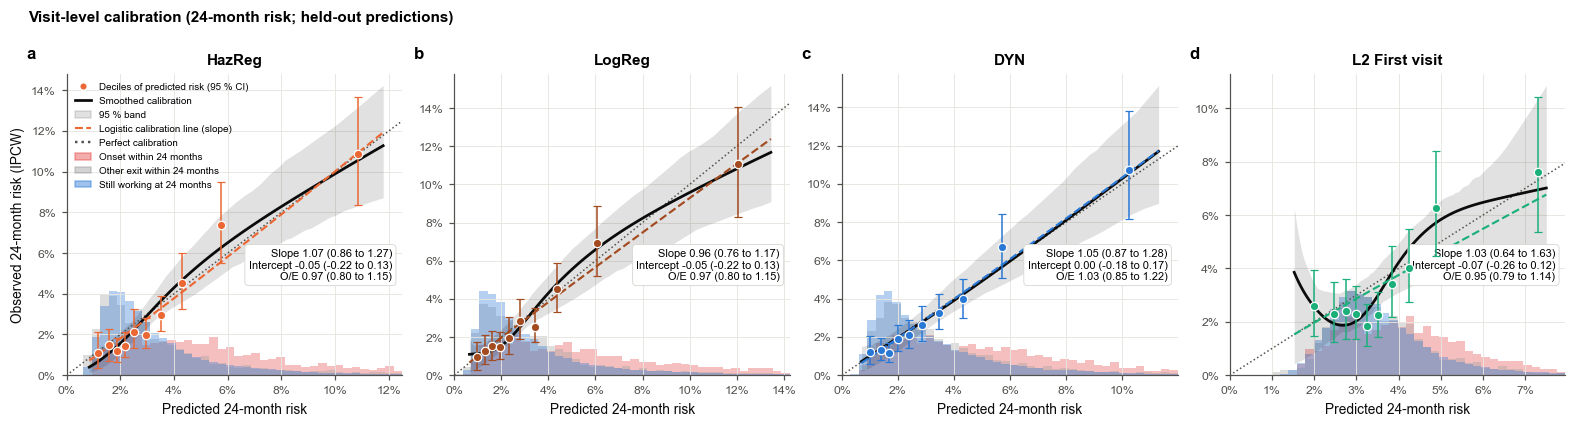

In [25]:
"""H2a, H2b: calibration and IPA of every rung; calibration plots of the key models."""
rows = []
for m in LADDER_RUN + [x for x in (OTHER, SEQ_MAIN, UNIT, HZ_FULL) if x in MODELS_RUN]:
    sl, ic = ci((m, "visit", H, "cal_slope")), ci((m, "visit", H, "cal_intercept"))
    met = CAL_SLOPE_RANGE[0] <= sl[0] <= CAL_SLOPE_RANGE[1] and ic[1] <= 0 <= ic[2]
    rows.append({"Model": short_label(m), "Visit slope": fmt(*sl), "Visit intercept": fmt(*ic),
                 "Visit O/E": fmtk((m, "visit", H, "oe")), "Slope and intercept criterion met": met,
                 f"Brier {H} mo": fmtk((m,) + K_BRIER, 4), f"IPA {H} mo": fmtk((m,) + K_IPA),
                 "IPA 12 mo": fmtk((m, "visit", 12, "ipa"))})
    if m == REPORTED:
        hyp("H2a", f"{short_label(REPORTED)}: visit calibration slope / intercept", f"{fmt(*sl)} / {fmt(*ic)}",
            "slope in [0.8, 1.2], intercept CI includes 0", met)
        d = ci((m,) + K_IPA)
        hyp("H2b", f"{short_label(REPORTED)}: IPA, {H} months", d, "lower bound > 0", d[1] > 0)
CAL_TABLE = pd.DataFrame(rows).set_index("Model")
display(CAL_TABLE)
CAL_TABLE.to_csv(f"aim2_calibration_{TAG}.csv")
_cal_models = [m for m in [REPORTED, OTHER, SEQ_MAIN, L2_FIRST] if m in MODELS_RUN]
fig, axes = plt.subplots(1, len(_cal_models), figsize=(3.6 * len(_cal_models), 3.9), squeeze=False)
for k_, (ax, m) in enumerate(zip(axes[0], _cal_models)):
    plot_calibration(ax, m, "visit", short_label(m), legend=(k_ == 0))
    if k_:
        ax.set_ylabel("")
    panel_label(ax, "abcd"[k_])
fig.suptitle(f"Visit-level calibration ({H}-month risk; held-out predictions)", x=0.02, ha="left", fontsize=10,
             fontweight="bold")
plt.tight_layout()
save_fig("calibration_key_models_visit")

## 14.4 Decision curves: what action, at what threshold? (H2c)

**The action** the model would support is a **referral for vocational support** (occupational therapy, workplace
adjustment, social work, vocational rehabilitation). It is low-harm and low-cost, so a **low risk threshold** is
justified: at a 24-month risk threshold *t*, a clinician accepts (1 − *t*)/*t* unnecessary referrals per onset
reached (24 at 4 %). Net benefit per visit (IPCW) of referring when the risk ≥ *t*, against referring at every
visit and at none, over 1-16 % (shaded: 2-10 %, the range of interest). **H2c**: at *t* = 4 %, the reported model's
net benefit exceeds that of referring at every visit and of referring at none (lower 95 % bound of the difference
> 0). Then the operating characteristics at fixed 24-month risks of 5 % and 10 %.

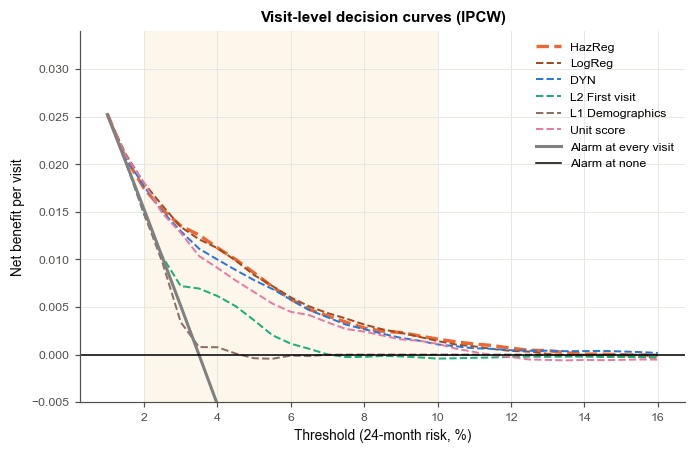

,Thresholds 2-10 % with NB above both (point),... (lower 95 % bound),NB at 2%,NB at 4%,NB at 6%,NB at 10%
Model,,,,,,
L1 Demographics,3/17,0/17,0.0148 (0.0087 to 0.0218),0.0008 (-0.0019 to 0.0038),-0.0001 (-0.0006 to 0.0004),0.0000 (0.0000 to 0.0000)
L2 First visit,10/17,4/17,0.0147 (0.0085 to 0.0213),0.0062 (0.0022 to 0.0108),0.0011 (-0.0007 to 0.0033),-0.0004 (-0.0013 to 0.0003)
HazReg,17/17,13/17,0.0175 (0.0117 to 0.0237),0.0112 (0.0067 to 0.0157),0.0058 (0.0027 to 0.0091),0.0016 (-0.0002 to 0.0034)
LogReg,17/17,13/17,0.0180 (0.0123 to 0.0242),0.0112 (0.0066 to 0.0160),0.0060 (0.0025 to 0.0096),0.0014 (-0.0006 to 0.0036)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1409: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


,Model,24-month risk >=,Sensitivity,Specificity,PPV,NPV,Balanced accuracy,Share flagged
0,L1 Demographics,5%,0.040 (0.020 to 0.063),0.965 (0.952 to 0.976),0.040 (0.020 to 0.071),0.965 (0.959 to 0.971),0.502 (0.493 to 0.514),0.035 (0.024 to 0.048)
1,L1 Demographics,10%,0.000 (0.000 to 0.000),1.000 (1.000 to 1.000),-,0.965 (0.958 to 0.971),0.500 (0.500 to 0.500),0.000 (0.000 to 0.000)
2,L2 First visit,5%,0.287 (0.221 to 0.362),0.873 (0.851 to 0.895),0.076 (0.056 to 0.101),0.971 (0.965 to 0.977),0.580 (0.546 to 0.617),0.133 (0.110 to 0.155)
3,L2 First visit,10%,0.013 (0.004 to 0.024),0.992 (0.983 to 0.997),0.054 (0.014 to 0.320),0.965 (0.959 to 0.971),0.502 (0.497 to 0.509),0.008 (0.003 to 0.017)
4,HazReg,5%,0.502 (0.436 to 0.570),0.823 (0.799 to 0.845),0.093 (0.074 to 0.114),0.979 (0.973 to 0.983),0.663 (0.628 to 0.696),0.188 (0.166 to 0.213)
5,HazReg,10%,0.154 (0.108 to 0.201),0.965 (0.957 to 0.973),0.139 (0.095 to 0.182),0.969 (0.963 to 0.975),0.559 (0.537 to 0.583),0.039 (0.031 to 0.048)
6,LogReg,5%,0.511 (0.442 to 0.580),0.813 (0.788 to 0.835),0.090 (0.071 to 0.110),0.979 (0.973 to 0.983),0.662 (0.626 to 0.698),0.199 (0.176 to 0.223)
7,LogReg,10%,0.190 (0.134 to 0.245),0.951 (0.939 to 0.961),0.124 (0.090 to 0.161),0.970 (0.964 to 0.976),0.571 (0.544 to 0.598),0.054 (0.043 to 0.066)


In [26]:
"""Decision curves; fixed risk thresholds."""
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for m in FIG_MODELS:
    if m in MODELS_RUN:
        ax.plot(NB_GRID * 100, [ci((m, "visit", H, "nb", t))[0] for t in NB_GRID], color=model_color(m),
                ls=model_ls(m), lw=2.2 if m == REPORTED else 1.3, label=short_label(m))
ax.plot(NB_GRID * 100, [ci((REPORTED, "visit", H, "nb_all", t))[0] for t in NB_GRID], color="grey", lw=2,
        label="Alarm at every visit")
ax.axhline(0, color="k", lw=1, label="Alarm at none")
ax.axvspan(NB_RANGE[0] * 100, NB_RANGE[1] * 100, color="#eda100", alpha=0.08, lw=0)
ax.set_ylim(-0.005, None); ax.set_xlabel(f"Threshold ({H}-month risk, %)"); ax.set_ylabel("Net benefit per visit")
ax.set_title("Visit-level decision curves (IPCW)"); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("fig09_decision_curves")

_ts = [t for t in NB_GRID if NB_RANGE[0] - 1e-9 <= t <= NB_RANGE[1] + 1e-9]
rows = []
for m in [m for m in LADDER_RUN + [OTHER] if m in MODELS_RUN]:
    above, above_lo = 0, 0
    for t in _ts:
        nb = ci((m, "visit", H, "nb", t)); nba = ci((m, "visit", H, "nb_all", t))[0]
        above += nb[0] > max(nba, 0); above_lo += nb[1] > max(nba, 0)
    rows.append({"Model": short_label(m), "Thresholds 2-10 % with NB above both (point)": f"{above}/{len(_ts)}",
                 "... (lower 95 % bound)": f"{above_lo}/{len(_ts)}",
                 **{f"NB at {t:.0%}": fmtk((m, "visit", H, "nb", t), 4) for t in NB_SHOW}})
NB_TABLE = pd.DataFrame(rows).set_index("Model")
display(NB_TABLE)
NB_TABLE.to_csv(f"aim2_h1d_net_benefit_{TAG}.csv")
rows = []
for m in [m for m in LADDER_RUN + [OTHER] if m in MODELS_RUN]:
    for t in FIXED_RISKS:
        rows.append({"Model": short_label(m), f"{H}-month risk >=": f"{t:.0%}",
                     **{METRIC_LABELS[x]: fmtk((m, "visit", H, "fixed", t, x)) for x in CONF_METRICS}})
FIXED_TABLE = pd.DataFrame(rows)
display(FIXED_TABLE)
FIXED_TABLE.to_csv(f"aim2_fixed_thresholds_{TAG}.csv", index=False)


_t4 = float(NB_GRID[np.argmin(np.abs(NB_GRID - 0.04))])
_nb, _nba = STATS[(REPORTED, "visit", H, "nb", _t4)], STATS[(REPORTED, "visit", H, "nb_all", _t4)]
_d_all = _diff_summary(_nb[0] - _nba[0], _nb[1] - _nba[1])
_d_none = ci((REPORTED, "visit", H, "nb", _t4))
hyp("H2c", f"{short_label(REPORTED)}: net benefit at 4 % minus referring at every visit / at none",
    f"{fmt(*_d_all[:3], nd=4)} / {fmt(*_d_none, nd=4)}", "both lower bounds > 0", _d_all[1] > 0 and _d_none[1] > 0)

## 14.5 Risk tiers: the clinical output

A yes/no alarm has a low PPV because onsets are rare; the output is a **risk tier** of the recalibrated 24-month
risk (< 2 %, 2-4 %, 4-10 %, ≥ 10 %; fixed in advance):

* **< 2 % — low**: routine follow-up; the **rule-out** tier (what share of visits it covers and of onsets it misses);
* **2-4 % — average**; **4-10 % — raised**: ask about work at the visit;
* **≥ 10 % — high**: discuss work and refer.

Views: by visit (share of visits, mean predicted vs observed risk, share of onsets); the cumulative rule-out tiers;
by patient on the same dates (time-matched); tier movement between consecutive visits; and the recent era.

**Relative tiers.** The onset rate fell about 5-fold over the decades (Section 18.1), so a fixed absolute threshold
flags fewer patients every year. Ranking within the patients currently at risk does not drift in the same way:
the second table puts each visit in a tier of its **percentile among the same calendar year's landmarks**
(bottom 40 %, 40-80th, 80-95th, top 5 %) and reports, by era, the likelihood ratio of each tier (share of onsets /
share of non-onset visits) and its observed risk. A clinic could use the relative tier for whom to discuss and the
locally recalibrated absolute risk (Section 18.5) for how high the risk is.

Cohort 24-month onset risk (IPCW): 3.5 %


Share of visits Share of patients ever in tier Mean predicted         Observed (IPCW)         Share of onsets
Model          Tier                                                                                                                 
HazReg         < 2 %             30.1%                          49.5%          0.015  0.013 (0.007 to 0.019)  0.105 (0.060 to 0.154)
               2-4 %             42.7%                          76.7%          0.028  0.022 (0.016 to 0.028)  0.268 (0.217 to 0.324)
               4-10 %            23.4%                          58.5%          0.059  0.069 (0.054 to 0.085)  0.474 (0.411 to 0.530)
               >= 10 %            3.7%                          19.5%          0.151  0.139 (0.095 to 0.182)  0.154 (0.108 to 0.201)
LogReg         < 2 %             38.0%                          61.1%          0.014  0.013 (0.007 to 0.018)  0.136 (0.083 to 0.190)
               2-4 %             34.9%                          72.7%          0.028  0.024 (0.018 to 0.032)  0.238 (0.185 to 0.297)
               4-10 %            21.9%                          57.8%          0.060  0.068 (0.053 to 0.086)  0.435 (0.376 to 0.497)
               >= 10 %            5.2%                          23.6%          0.151  0.124 (0.090 to 0.161)  0.190 (0.134 to 0.245)
DYN            < 2 %             36.9%                          60.5%          0.014  0.013 (0.008 to 0.019)  0.135 (0.092 to 0.182)
               2-4 %             36.2%                          80.7%          0.028  0.026 (0.020 to 0.033)  0.268 (0.223 to 0.314)
               4-10 %            23.6%                          64.7%          0.059  0.066 (0.052 to 0.082)  0.467 (0.407 to 0.529)
               >= 10 %            3.3%                          16.7%          0.139  0.127 (0.087 to 0.175)  0.129 (0.091 to 0.172)
L2 First visit < 2 %              4.7%                           8.3%          0.018  0.039 (0.015 to 0.075)  0.039 (0.018 to 0.065)
               2-4 %             65.9%                          73.8%          0.030  0.024 (0.018 to 0.030)  0.444 (0.368 to 0.521)
               4-10 %            28.6%                          50.7%          0.052  0.060 (0.047 to 0.075)  0.504 (0.424 to 0.582)
               >= 10 %            0.8%                           1.5%          0.152  0.054 (0.014 to 0.320)  0.013 (0.004 to 0.024)

Visits covered Observed 24-month risk (1 - NPV) Onsets missed (share of all)
Model          Rule-out tier                                                                             
HazReg         below 2 %              30.1%           0.013 (0.007 to 0.019)       0.105 (0.060 to 0.154)
               below 4 %              72.8%           0.018 (0.014 to 0.023)       0.373 (0.308 to 0.439)
LogReg         below 2 %              38.0%           0.013 (0.007 to 0.018)       0.136 (0.083 to 0.190)
               below 4 %              72.9%           0.018 (0.014 to 0.023)       0.375 (0.304 to 0.442)
DYN            below 2 %              36.9%           0.013 (0.008 to 0.019)       0.135 (0.092 to 0.182)
               below 4 %              73.0%           0.020 (0.015 to 0.025)       0.403 (0.332 to 0.474)
L2 First visit below 2 %               4.7%           0.039 (0.015 to 0.075)       0.039 (0.018 to 0.065)
               below 4 %              70.6%           0.024 (0.019 to 0.031)       0.483 (0.402 to 0.567)

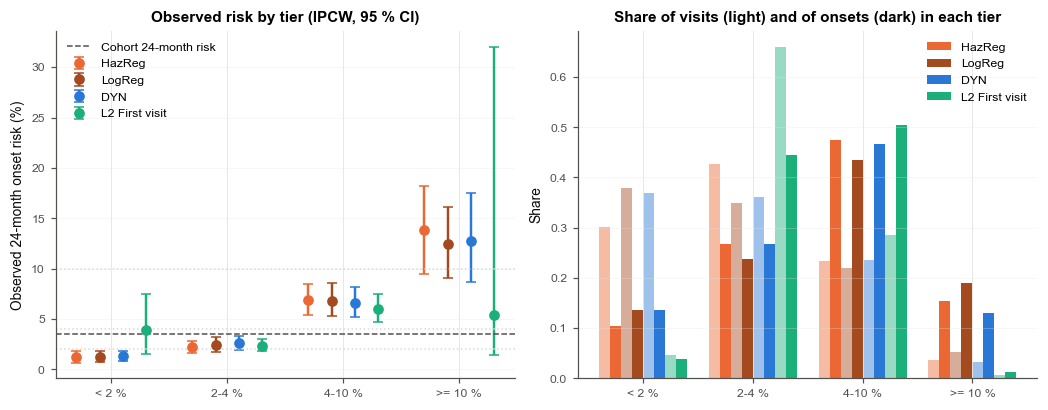

In [27]:
"""Risk tiers by visit and the rule-out tiers."""
TIER_MODELS = [m for m in [REPORTED, OTHER, SEQ_MAIN, L2_FIRST] if m in MODELS_RUN]
TIER_NAMES = [n for _, _, n in RISK_TIERS]
print(f"Cohort {H}-month onset risk (IPCW): {100 * CIF_IPCW[H]:.1f} %")
rows = []
for m in TIER_MODELS:
    for name in TIER_NAMES:
        k = (m, "visit", H, "tier", name)
        rows.append({"Model": short_label(m), "Tier": name, "Share of visits": f"{ci(k + ('share_visits',))[0]:.1%}",
                     "Share of patients ever in tier": f"{ci(k + ('share_patients',))[0]:.1%}",
                     "Mean predicted": f"{ci(k + ('mean_pred',))[0]:.3f}",
                     "Observed (IPCW)": fmtk(k + ("observed",)), "Share of onsets": fmtk(k + ("share_onsets",))})
TIERS = pd.DataFrame(rows)
display(TIERS.set_index(["Model", "Tier"]))
TIERS.to_csv(f"aim2_risk_tiers_{TAG}.csv", index=False)

rows = []
for m in TIER_MODELS:
    for _, _, name in RULE_OUT_TIERS:
        k = (m, "visit", H, "tier", name)
        rows.append({"Model": short_label(m), "Rule-out tier": name,
                     "Visits covered": f"{ci(k + ('share_visits',))[0]:.1%}",
                     f"Observed {H}-month risk (1 - NPV)": fmtk(k + ("observed",)),
                     "Onsets missed (share of all)": fmtk(k + ("share_onsets",))})
RULE_OUT = pd.DataFrame(rows)
display(RULE_OUT.set_index(["Model", "Rule-out tier"]))
RULE_OUT.to_csv(f"aim2_rule_out_{TAG}.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))
xx = np.arange(len(TIER_NAMES))
wd = 0.8 / len(TIER_MODELS)
for j, m in enumerate(TIER_MODELS):
    obs = np.array([ci((m, "visit", H, "tier", n, "observed")) for n in TIER_NAMES])
    shv = [ci((m, "visit", H, "tier", n, "share_visits"))[0] for n in TIER_NAMES]
    sho = np.array([ci((m, "visit", H, "tier", n, "share_onsets")) for n in TIER_NAMES])
    off = (j - (len(TIER_MODELS) - 1) / 2) * wd
    axes[0].errorbar(xx + off, 100 * obs[:, 0], yerr=[100 * (obs[:, 0] - obs[:, 1]), 100 * (obs[:, 2] - obs[:, 0])],
                     fmt="o", color=model_color(m), capsize=3, label=short_label(m))
    axes[1].bar(xx + off - wd / 4, shv, wd / 2, color=model_color(m), alpha=0.45)
    axes[1].bar(xx + off + wd / 4, sho[:, 0], wd / 2, color=model_color(m), label=short_label(m))
for lo_, _, _ in RISK_TIERS[1:]:
    axes[0].axhline(100 * lo_, color="#d9d8d3", ls=":", lw=1)
axes[0].axhline(100 * CIF_IPCW[H], color=INK_2, ls="--", lw=1, label=f"Cohort {H}-month risk")
axes[0].set_xticks(xx); axes[0].set_xticklabels(TIER_NAMES); axes[0].set_ylabel(f"Observed {H}-month onset risk (%)")
axes[0].set_title("Observed risk by tier (IPCW, 95 % CI)"); axes[0].legend(fontsize=8); axes[0].grid(axis="y", alpha=0.3)
axes[1].set_xticks(xx); axes[1].set_xticklabels(TIER_NAMES); axes[1].set_ylabel("Share")
axes[1].set_title("Share of visits (light) and of onsets (dark) in each tier"); axes[1].legend(fontsize=8)
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); save_fig("risk_tiers")

Onset patients (24 mo before onset) Patients still working, same dates     Likelihood ratio
Model          Tier                                                                                               
HazReg         < 2 %                0.077 (0.042 to 0.116)             0.275 (0.241 to 0.311)  0.28 (0.16 to 0.42)
               2-4 %                0.254 (0.200 to 0.316)             0.424 (0.398 to 0.451)  0.60 (0.47 to 0.75)
               4-10 %               0.513 (0.447 to 0.576)             0.264 (0.233 to 0.293)  1.94 (1.66 to 2.25)
               >= 10 %              0.156 (0.104 to 0.207)             0.037 (0.026 to 0.050)  4.22 (2.82 to 6.10)
LogReg         < 2 %                0.113 (0.067 to 0.161)             0.336 (0.298 to 0.377)  0.33 (0.21 to 0.47)
               2-4 %                0.233 (0.178 to 0.289)             0.360 (0.336 to 0.385)  0.65 (0.49 to 0.81)
               4-10 %               0.465 (0.400 to 0.529)             0.255 (0.226 to 0.284)  1.82 (1.51 to 2.14)
               >= 10 %              0.190 (0.135 to 0.248)             0.048 (0.036 to 0.061)  3.98 (2.86 to 5.49)
DYN            < 2 %                0.097 (0.061 to 0.140)             0.322 (0.287 to 0.358)  0.30 (0.19 to 0.43)
               2-4 %                0.262 (0.206 to 0.317)             0.383 (0.363 to 0.404)  0.68 (0.53 to 0.83)
               4-10 %               0.525 (0.460 to 0.590)             0.268 (0.239 to 0.297)  1.96 (1.70 to 2.26)
               >= 10 %              0.115 (0.072 to 0.165)             0.026 (0.018 to 0.035)  4.41 (2.78 to 6.91)
L2 First visit < 2 %                0.032 (0.016 to 0.052)             0.035 (0.027 to 0.043)  0.92 (0.46 to 1.50)
               2-4 %                0.439 (0.368 to 0.509)             0.626 (0.589 to 0.662)  0.70 (0.59 to 0.81)
               4-10 %               0.506 (0.437 to 0.576)             0.331 (0.294 to 0.370)  1.53 (1.31 to 1.78)
               >= 10 %              0.023 (0.008 to 0.044)             0.008 (0.004 to 0.015)  2.70 (0.92 to 6.63)

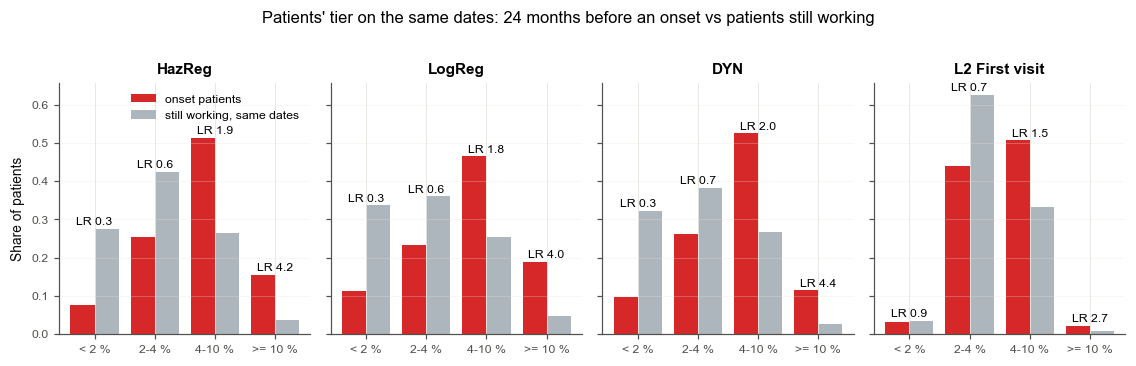

In [28]:
"""Risk tiers by patient on the same dates (time-matched), tier movement and the recent era."""


def tm_tiers(m):
    """Per tier: share of onset patients and of time-matched controls (each onset's controls weighted equally), and
    the likelihood ratio; repeat means of the bootstrap arrays (point = first entry)."""
    d = TM["main"]
    Wc = _BOTH[:, d["case_pid"]]
    acc = {n: [] for n in TIER_NAMES}
    for r in REPEATS:
        p_ = _expit(np.asarray(d["mat"] @ np.nan_to_num(zpred(m, r))).ravel())
        for lo, hi, n in RISK_TIERS:
            inn = (p_ >= lo) & (p_ < hi)
            case = (Wc @ inn[d["cases"]].astype(np.float32)) / Wc.sum(1)
            Kc = sparse.coo_matrix((d["w"] * inn[d["pk"]], (d["ppc"], d["ppk"])), shape=(P_, P_)).toarray()
            ctrl = _pair_sum_fast(_BOTH, Kc) / d["wden"]
            acc[n].append((case, ctrl))
    out = {}
    for n in TIER_NAMES:
        case = np.mean([a for a, _ in acc[n]], 0); ctrl = np.mean([b for _, b in acc[n]], 0)
        lr = case / np.where(ctrl > 0, ctrl, np.nan)
        out[n] = {k_: (v[0], np.nanpercentile(v[1:], 2.5), np.nanpercentile(v[1:], 97.5))
                  for k_, v in [("case", case), ("ctrl", ctrl), ("lr", lr)]}
    return out


TM_TIERS = {m: tm_tiers(m) for m in TIER_MODELS}
rows = [{"Model": short_label(m), "Tier": n, f"Onset patients ({H} mo before onset)": fmt(*v["case"]),
         "Patients still working, same dates": fmt(*v["ctrl"]), "Likelihood ratio": fmt(*v["lr"], nd=2)}
        for m, t_ in TM_TIERS.items() for n, v in t_.items()]
TM_TIER_TABLE = pd.DataFrame(rows)
display(TM_TIER_TABLE.set_index(["Model", "Tier"]))
TM_TIER_TABLE.to_csv(f"aim2_tiers_time_matched_{TAG}.csv", index=False)

fig, axes = plt.subplots(1, len(TIER_MODELS), figsize=(2.6 * len(TIER_MODELS), 3.2), sharey=True)
for ax, m in zip(np.atleast_1d(axes), TIER_MODELS):
    t_ = TM_TIERS[m]
    ax.bar(xx - 0.2, [t_[n]["case"][0] for n in TIER_NAMES], 0.4, color="#d62828", label="onset patients")
    ax.bar(xx + 0.2, [t_[n]["ctrl"][0] for n in TIER_NAMES], 0.4, color="#adb5bd", label="still working, same dates")
    for x_, n in zip(xx, TIER_NAMES):
        ax.text(x_, max(t_[n]["case"][0], t_[n]["ctrl"][0]) + 0.01, f"LR {t_[n]['lr'][0]:.1f}", ha="center", fontsize=8)
    ax.set_xticks(xx); ax.set_xticklabels(TIER_NAMES); ax.set_title(short_label(m)); ax.grid(axis="y", alpha=0.3)
np.atleast_1d(axes)[0].set_ylabel("Share of patients"); np.atleast_1d(axes)[0].legend(fontsize=8)
fig.suptitle(f"Patients' tier on the same dates: {H} months before an onset vs patients still working", y=1.02)
plt.tight_layout(); save_fig("risk_tiers_time_matched")

## 14.5b Risk-tier transitions between visits

How a patient's tier changes from one employed visit to the next (the held-out risk, mean over the CV repeats): the
share of visits in each tier whose next visit is in each tier (rows sum to 1), for the reported model,
LogReg and DYN. A model that mostly keeps patients in their tier is stratifying a stable trait; moves of more
than one tier are where a change in the patient's status shows. Beside the matrix: for each tier at a visit, the
observed 24-month onset risk (IPCW) of the visits that stay in it, move up, or move down at the next visit.

HazReg:


Tier at the next visit,< 2 %,2-4 %,4-10 %,>= 10 %
HazReg: tier at a visit,,,,
< 2 %,0.894,0.098,0.007,0.000
2-4 %,0.106,0.803,0.088,0.003
4-10 %,0.007,0.219,0.730,0.044
>= 10 %,0.000,0.023,0.404,0.573


HazReg: the tier stays the same at 80% of consecutive visits and moves by more than one tier at 0.6%. Patients ever in the >= 10 % tier: 19%; of them, 33% have an onset (vs 10% of the others).
LogReg:


Tier at the next visit,< 2 %,2-4 %,4-10 %,>= 10 %
LogReg: tier at a visit,,,,
< 2 %,0.880,0.109,0.010,0.001
2-4 %,0.151,0.724,0.120,0.005
4-10 %,0.018,0.236,0.677,0.069
>= 10 %,0.005,0.035,0.375,0.585


LogReg: the tier stays the same at 77% of consecutive visits and moves by more than one tier at 1.2%. Patients ever in the >= 10 % tier: 23%; of them, 30% have an onset (vs 9% of the others).
DYN:


Tier at the next visit,< 2 %,2-4 %,4-10 %,>= 10 %
DYN: tier at a visit,,,,
< 2 %,0.890,0.101,0.009,0.000
2-4 %,0.173,0.702,0.121,0.003
4-10 %,0.013,0.260,0.672,0.056
>= 10 %,0.002,0.034,0.453,0.511


DYN: the tier stays the same at 76% of consecutive visits and moves by more than one tier at 0.9%. Patients ever in the >= 10 % tier: 16%; of them, 34% have an onset (vs 11% of the others).


Visits Observed 24-month risk after the next visit (IPCW)
Tier at a visit Next visit                                                           
< 2 %           moves down       0                                                  -
                stays         4336                                              0.013
                moves up       512                                              0.023
2-4 %           moves down     746                                              0.012
                stays         5624                                              0.018
                moves up       636                                              0.059
4-10 %          moves down     872                                              0.039
                stays         2818                                              0.071
                moves up       170                                              0.106
>= 10 %         moves down     241                                              0.084
                stays          324                                              0.167
                moves up         0                                                  -

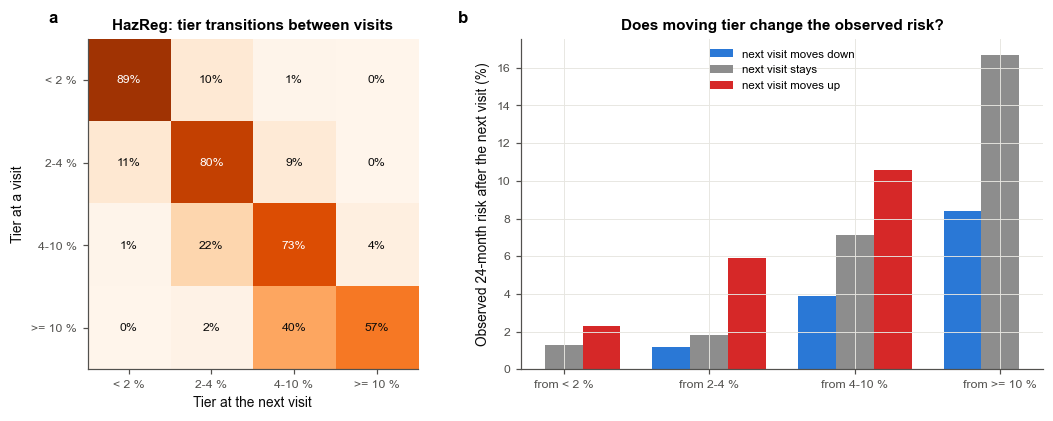

In [29]:
"""Risk-tier transitions between consecutive visits: the reported model, LogReg and DYN."""
_tier_of = lambda p_: np.digitize(p_, [lo for lo, _, _ in RISK_TIERS[1:]])
TIER_STAY, TRANS = {}, {}
_rows_h, _y_h, _w_h = IPCW_H[H]
_yh_full, _wh_full = np.full(N_LAND, np.nan), np.zeros(N_LAND)
_yh_full[_rows_h], _wh_full[_rows_h] = _y_h, _w_h
for m in [x for x in (REPORTED, OTHER, SEQ_MAIN) if x in MODELS_RUN]:
    _tz = _tier_of(_expit(mean_z(m)))
    _a, _b, _r = [], [], []
    for pid, li in PT_ROWS.items():
        if len(li) > 1:
            _a.append(_tz[li[:-1]]); _b.append(_tz[li[1:]]); _r.append(li[1:])
    _a, _b, _r = np.concatenate(_a), np.concatenate(_b), np.concatenate(_r)
    MOVE = pd.crosstab(pd.Categorical(np.array(TIER_NAMES)[_a], TIER_NAMES),
                       pd.Categorical(np.array(TIER_NAMES)[_b], TIER_NAMES), normalize="index",
                       rownames=[f"{short_label(m)}: tier at a visit"], colnames=["Tier at the next visit"])
    TRANS[m] = (MOVE, _a, _b, _r)
    print(f"{short_label(m)}:"); display(MOVE.round(3))
    MOVE.to_csv(f"aim2_tier_movement_{short_label(m).replace(' ', '_')}_{TAG}.csv")
    _ever_hi = pd.Series(_tz == 3).groupby(PID_ALL).max()
    _ev_pt = pd.Series(land["pt_event"].values).groupby(PID_ALL).max()
    TIER_STAY[m] = float(np.mean(_a == _b))
    print(f"{short_label(m)}: the tier stays the same at {np.mean(_a == _b):.0%} of consecutive visits and moves by "
          f"more than one tier at {np.mean(np.abs(_a - _b) > 1):.1%}. Patients ever in the {TIER_HIGH} tier: "
          f"{_ever_hi.mean():.0%}; of them, {_ev_pt[_ever_hi].mean():.0%} have an onset (vs "
          f"{_ev_pt[~_ever_hi].mean():.0%} of the others).")

# the reported model: transition matrix and the observed risk after staying / moving up / moving down
MOVE, _a, _b, _r = TRANS[REPORTED]
rows = []
for k, n in enumerate(TIER_NAMES):
    for lab_, sel in [("moves down", (_a == k) & (_b < k)), ("stays", (_a == k) & (_b == k)),
                      ("moves up", (_a == k) & (_b > k))]:
        rr = _r[sel]
        rr = rr[~np.isnan(_yh_full[rr])]
        ok = len(rr) > 0 and _wh_full[rr].sum() > 0
        rows.append({"Tier at a visit": n, "Next visit": lab_, "Visits": int(sel.sum()),
                     f"Observed {H}-month risk after the next visit (IPCW)":
                         f"{np.sum(_wh_full[rr] * _yh_full[rr]) / _wh_full[rr].sum():.3f}" if ok else "-"})
TRANS_RISK = pd.DataFrame(rows).set_index(["Tier at a visit", "Next visit"])
display(TRANS_RISK)
TRANS_RISK.to_csv(f"aim2_tier_transitions_risk_{TAG}.csv")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
im = ax.imshow(MOVE.values, cmap="Oranges", vmin=0, vmax=1)
for i in range(len(TIER_NAMES)):
    for j in range(len(TIER_NAMES)):
        ax.text(j, i, f"{MOVE.values[i, j]:.0%}", ha="center", va="center", fontsize=8,
                color="white" if MOVE.values[i, j] > 0.6 else "#0b0b0b")
ax.set_xticks(range(len(TIER_NAMES))); ax.set_xticklabels(TIER_NAMES)
ax.set_yticks(range(len(TIER_NAMES))); ax.set_yticklabels(TIER_NAMES); ax.grid(False)
ax.set_xlabel("Tier at the next visit"); ax.set_ylabel("Tier at a visit")
ax.set_title(f"{short_label(REPORTED)}: tier transitions between visits")
ax = axes[1]
xx = np.arange(len(TIER_NAMES))
for j, (lab_, col_) in enumerate([("moves down", "#2a78d6"), ("stays", "#8d8d8d"), ("moves up", "#d62828")]):
    v = [TRANS_RISK.loc[(n, lab_)].iloc[1] for n in TIER_NAMES]
    v = [100 * float(x) if x != "-" else np.nan for x in v]
    ax.bar(xx + (j - 1) * 0.26, v, 0.26, color=col_, label=f"next visit {lab_}")
ax.set_xticks(xx); ax.set_xticklabels([f"from {n}" for n in TIER_NAMES])
ax.set_ylabel(f"Observed {H}-month risk after the next visit (%)"); ax.legend(fontsize=7.5)
ax.set_title("Does moving tier change the observed risk?")
for a_, l_ in zip(axes, "ab"):
    panel_label(a_, l_)
plt.tight_layout(); save_fig("tier_transitions")

In [30]:
"""Risk tiers in the recent era; tier summary."""
rows = []
for m in TIER_MODELS:
    for _, _, name in RISK_TIERS + RULE_OUT_TIERS:
        k = (m, "visit", H, "tier_recent", name)
        rows.append({"Model": short_label(m), "Tier": name, "Share of visits (labelled, IPCW)": fmtk(k + ("share_visits",)),
                     "Observed (IPCW)": fmtk(k + ("observed",)), "Share of onsets": fmtk(k + ("share_onsets",))})
TIERS_RECENT = pd.DataFrame(rows)
print(f"Recent era (landmarks from {TIER_RECENT_FROM} on):")
display(TIERS_RECENT.set_index(["Model", "Tier"]))
TIERS_RECENT.to_csv(f"aim2_risk_tiers_recent_{TAG}.csv", index=False)
_T = lambda k_: ci((REPORTED, "visit", H, "tier") + k_)
_lo, _lo_m = _T((RULE_OUT_MAIN, "observed")), _T((RULE_OUT_MAIN, "share_onsets"))
_hi, _hi_o = _T((TIER_HIGH, "observed")), _T((TIER_HIGH, "share_onsets"))
_tmt = TM_TIERS[REPORTED]
TIER_SUMMARY = (f"Risk tiers ({short_label(REPORTED)}): the {TIER_LOW} tier covers "
                f"{_T((RULE_OUT_MAIN, 'share_visits'))[0]:.0%} of visits with an observed {H}-month risk of "
                f"{fmt(*_lo)} and misses {fmt(*_lo_m)} of the onsets; the {TIER_HIGH} tier covers "
                f"{_T((TIER_HIGH, 'share_visits'))[0]:.0%} of visits with an observed risk of {fmt(*_hi)} and holds "
                f"{fmt(*_hi_o)} of the onsets. On the same dates, onset patients are in the {TIER_HIGH} tier "
                f"{_tmt[TIER_HIGH]['case'][0]:.0%} of the time vs {_tmt[TIER_HIGH]['ctrl'][0]:.0%} of patients still "
                f"working (LR {_tmt[TIER_HIGH]['lr'][0]:.1f}); in the {TIER_LOW} tier {_tmt[TIER_LOW]['case'][0]:.0%} vs "
                f"{_tmt[TIER_LOW]['ctrl'][0]:.0%} (LR {_tmt[TIER_LOW]['lr'][0]:.2f}).")
print(textwrap.fill(TIER_SUMMARY, 118))

Recent era (landmarks from 2012 on):


Share of visits (labelled, IPCW)         Observed (IPCW)         Share of onsets
Model          Tier                                                                                      
HazReg         < 2 %               0.362 (0.324 to 0.397)  0.010 (0.003 to 0.018)  0.180 (0.074 to 0.282)
               2-4 %               0.446 (0.415 to 0.476)  0.013 (0.007 to 0.019)  0.281 (0.193 to 0.371)
               4-10 %              0.174 (0.149 to 0.201)  0.052 (0.032 to 0.076)  0.446 (0.321 to 0.569)
               >= 10 %             0.018 (0.011 to 0.028)  0.105 (0.038 to 0.193)  0.094 (0.040 to 0.160)
               below 2 %           0.362 (0.324 to 0.397)  0.010 (0.003 to 0.018)  0.180 (0.074 to 0.282)
               below 4 %           0.808 (0.778 to 0.835)  0.012 (0.007 to 0.017)  0.461 (0.314 to 0.609)
LogReg         < 2 %               0.468 (0.430 to 0.507)  0.011 (0.004 to 0.018)  0.250 (0.114 to 0.393)
               2-4 %               0.344 (0.316 to 0.370)  0.014 (0.008 to 0.021)  0.235 (0.160 to 0.320)
               4-10 %              0.159 (0.136 to 0.182)  0.050 (0.030 to 0.075)  0.394 (0.286 to 0.520)
               >= 10 %             0.029 (0.020 to 0.039)  0.086 (0.040 to 0.151)  0.121 (0.063 to 0.197)
               below 2 %           0.468 (0.430 to 0.507)  0.011 (0.004 to 0.018)  0.250 (0.114 to 0.393)
               below 4 %           0.812 (0.784 to 0.840)  0.012 (0.007 to 0.018)  0.484 (0.341 to 0.621)
DYN            < 2 %               0.447 (0.411 to 0.481)  0.010 (0.004 to 0.017)  0.228 (0.100 to 0.354)
               2-4 %               0.354 (0.331 to 0.378)  0.014 (0.008 to 0.021)  0.246 (0.167 to 0.338)
               4-10 %              0.181 (0.159 to 0.204)  0.046 (0.026 to 0.068)  0.406 (0.287 to 0.533)
               >= 10 %             0.019 (0.012 to 0.026)  0.135 (0.051 to 0.240)  0.121 (0.053 to 0.202)
               below 2 %           0.447 (0.411 to 0.481)  0.010 (0.004 to 0.017)  0.228 (0.100 to 0.354)
               below 4 %           0.800 (0.773 to 0.826)  0.012 (0.007 to 0.017)  0.474 (0.326 to 0.631)
L2 First visit < 2 %               0.065 (0.050 to 0.080)  0.043 (0.012 to 0.089)  0.102 (0.040 to 0.173)
               2-4 %               0.708 (0.676 to 0.742)  0.011 (0.007 to 0.017)  0.400 (0.293 to 0.501)
               4-10 %              0.221 (0.189 to 0.255)  0.045 (0.027 to 0.068)  0.494 (0.359 to 0.640)
               >= 10 %             0.006 (0.001 to 0.015)  0.009 (0.000 to 0.119)  0.004 (0.000 to 0.012)
               below 2 %           0.065 (0.050 to 0.080)  0.043 (0.012 to 0.089)  0.102 (0.040 to 0.173)
               below 4 %           0.773 (0.739 to 0.807)  0.013 (0.007 to 0.019)  0.502 (0.355 to 0.639)

Risk tiers (HazReg): the < 2 % tier covers 30% of visits with an observed 24-month risk of 0.013 (0.007 to 0.019) and
misses 0.105 (0.060 to 0.154) of the onsets; the >= 10 % tier covers 4% of visits with an observed risk of 0.139
(0.095 to 0.182) and holds 0.154 (0.108 to 0.201) of the onsets. On the same dates, onset patients are in the >= 10 %
tier 16% of the time vs 4% of patients still working (LR 4.2); in the < 2 % tier 8% vs 28% (LR 0.28).


In [31]:
"""Relative risk tiers: percentile within the same calendar year's landmarks, by era."""
REL_TIERS = [(0, 40, "bottom 40 %"), (40, 80, "40-80th"), (80, 95, "80-95th"), (95, 101, "top 5 %")]
_yr_int = np.floor(land["CAL_YEAR"].values)
_rows_h, _y_h, _w_h = IPCW_H[H]


def rel_tiers(m):
    """Per era and relative tier: share of visits, observed risk, share of onsets and LR (point + bootstrap)."""
    out = {}
    for _, _, era in ERA_BANDS + [(None, None, "All eras")]:
        e_mask = (LAND_SUB["era"].values[_rows_h] == era) if era != "All eras" else np.ones(len(_rows_h), bool)
        acc = {}
        for r in REPEATS:
            pct = 100 * pd.Series(zpred(m, r)).groupby(_yr_int).rank(pct=True).values[_rows_h]
            y1, w_ = _y_h * e_mask, _w_h * e_mask
            tot_on, tot_off = _BOTH @ _pt_agg(_rows_h, w_ * y1), _BOTH @ _pt_agg(_rows_h, w_ * (1 - _y_h))
            tot = _BOTH @ _pt_agg(_rows_h, w_)
            for lo, hi, name in REL_TIERS:
                inn = ((pct > lo) & (pct <= hi)).astype(float) if lo else (pct <= hi).astype(float)
                on, off = _BOTH @ _pt_agg(_rows_h, w_ * y1 * inn), _BOTH @ _pt_agg(_rows_h, w_ * (1 - _y_h) * inn)
                v = {"share": (on + off) / tot, "observed": _ratio(on, on + off), "share_onsets": _ratio(on, tot_on),
                     "lr": _ratio(_ratio(on, tot_on), _ratio(off, tot_off))}
                for k_, a_ in v.items():
                    acc.setdefault((name, k_), []).append(a_)
        for (name, k_), v in acc.items():
            out[(era, name, k_)] = np.nanmean(np.vstack(v), 0)
    return out


REL = {m: rel_tiers(m) for m in [REPORTED, SEQ_MAIN] if m in MODELS_RUN}
rows = []
for m, d in REL.items():
    for _, _, era in ERA_BANDS + [(None, None, "All eras")]:
        for _, _, name in REL_TIERS:
            rows.append({"Model": short_label(m), "Era": era, "Relative tier (within-year percentile)": name,
                         "Observed risk": fci(d[(era, name, "observed")]),
                         "Share of onsets": fci(d[(era, name, "share_onsets")]),
                         "Likelihood ratio": fci(d[(era, name, "lr")], 2)})
REL_TABLE = pd.DataFrame(rows).set_index(["Model", "Era", "Relative tier (within-year percentile)"])
display(REL_TABLE.loc[short_label(REPORTED)])
REL_TABLE.to_csv(f"aim2_relative_tiers_{TAG}.csv")
_d = REL[REPORTED]
print(f"{short_label(REPORTED)}, likelihood ratio of the top 5 % / bottom 40 % by era: " + "; ".join(
    f"{era} {_d[(era, 'top 5 %', 'lr')][0]:.1f} / {_d[(era, 'bottom 40 %', 'lr')][0]:.2f}" for _, _, era in ERA_BANDS)
      + ". Observed risk of the top 5 % by era: " + ", ".join(
    f"{era} {_d[(era, 'top 5 %', 'observed')][0]:.1%}" for _, _, era in ERA_BANDS))

Observed risk         Share of onsets     Likelihood ratio
Era      Relative tier (within-year percentile)                                                                     
< 2000   bottom 40 %                             0.006 (0.001 to 0.011)  0.044 (0.013 to 0.089)  0.10 (0.03 to 0.21)
         40-80th                                 0.051 (0.028 to 0.081)  0.403 (0.263 to 0.564)  1.01 (0.66 to 1.44)
         80-95th                                 0.130 (0.070 to 0.192)  0.376 (0.258 to 0.473)  2.80 (1.92 to 3.73)
         top 5 %                                 0.170 (0.066 to 0.298)  0.177 (0.073 to 0.296)  3.86 (1.50 to 7.56)
2000-05  bottom 40 %                             0.029 (0.013 to 0.050)  0.239 (0.123 to 0.383)  0.57 (0.30 to 0.93)
         40-80th                                 0.054 (0.031 to 0.081)  0.424 (0.301 to 0.530)  1.08 (0.77 to 1.38)
         80-95th                                 0.086 (0.048 to 0.133)  0.251 (0.176 to 0.344)  1.78 (1.20 to 2.56)
         top 5 %                                 0.089 (0.034 to 0.168)  0.086 (0.038 to 0.151)  1.87 (0.72 to 3.78)
2006-11  bottom 40 %                             0.020 (0.008 to 0.035)  0.193 (0.085 to 0.315)  0.47 (0.20 to 0.76)
         40-80th                                 0.034 (0.019 to 0.054)  0.332 (0.225 to 0.446)  0.83 (0.56 to 1.12)
         80-95th                                 0.080 (0.046 to 0.118)  0.286 (0.198 to 0.381)  2.03 (1.37 to 2.82)
         top 5 %                                 0.155 (0.081 to 0.246)  0.188 (0.104 to 0.285)  4.29 (2.34 to 7.02)
>= 2012  bottom 40 %                             0.010 (0.003 to 0.018)  0.198 (0.081 to 0.312)  0.49 (0.20 to 0.77)
         40-80th                                 0.014 (0.008 to 0.020)  0.268 (0.187 to 0.360)  0.66 (0.45 to 0.89)
         80-95th                                 0.046 (0.028 to 0.068)  0.330 (0.234 to 0.437)  2.30 (1.60 to 3.22)
         top 5 %                                 0.081 (0.042 to 0.132)  0.204 (0.121 to 0.301)  4.23 (2.32 to 6.97)
All eras bottom 40 %                             0.015 (0.010 to 0.021)  0.178 (0.121 to 0.235)  0.43 (0.29 to 0.57)
         40-80th                                 0.031 (0.024 to 0.040)  0.353 (0.298 to 0.412)  0.88 (0.74 to 1.03)
         80-95th                                 0.073 (0.056 to 0.090)  0.305 (0.256 to 0.352)  2.16 (1.77 to 2.59)
         top 5 %                                 0.113 (0.081 to 0.152)  0.164 (0.118 to 0.211)  3.53 (2.52 to 4.92)

HazReg, likelihood ratio of the top 5 % / bottom 40 % by era: < 2000 3.9 / 0.10; 2000-05 1.9 / 0.57; 2006-11 4.3 / 0.47; >= 2012 4.2 / 0.49. Observed risk of the top 5 % by era: < 2000 17.0%, 2000-05 8.9%, 2006-11 15.5%, >= 2012 8.1%


## 14.6 Prediction instability

How much would an individual's predicted risk change if the model were developed on another sample of the same
size (Riley & Collins 2023)? From the 200 bootstrap refits of Section 14.2, each applied to every landmark (the
models' own 24-month risks, before recalibration, for the original and the bootstrap models alike):

* **(a) Instability plot**: each landmark's risk from the bootstrap models against its risk from the model fitted on
  all patients (a sample of points; lines: the 2.5th and 97.5th percentiles of the bootstrap risks in bins of the
  original risk).
* **(b) Mean absolute prediction error** (MAPE) per landmark: the mean over the bootstrap models of |bootstrap risk −
  original risk|.
* **(c) Calibration instability**: each bootstrap model's decile calibration on the original data (IPCW).
* **(d) Across the CV repeats**: each landmark is predicted by 5 models trained on different 80 % splits; the SD of
  its logit across the repeats, for the reported model and for DYN (the same comparison for both, at no extra cost).

Tier instability: the share of bootstrap models that put a landmark in a different risk tier than the original model.

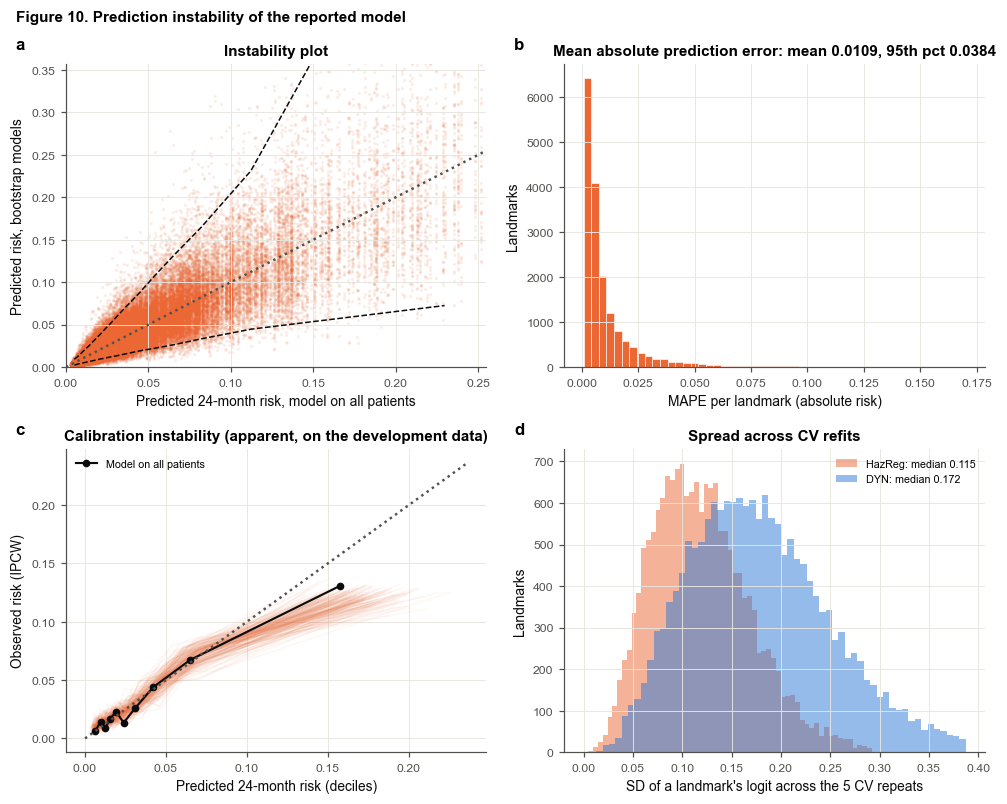

Prediction instability (200 bootstrap refits): MAPE mean 0.0109 (absolute 24-month risk; 95th percentile 0.0384); a
landmark's risk tier changes in 24% of bootstrap models on average (56% of landmarks change tier in > 20 % of them).
Across CV repeats, the median SD of a landmark's logit is HazReg 0.115, DYN 0.172.


In [32]:
"""Prediction instability of the reported model; spread across CV repeats for the reported model and DYN."""
P_FINAL, P_BOOT = _expit(Z_FINAL), _expit(Z_BOOT)
MAPE = np.abs(P_BOOT - P_FINAL[None, :]).mean(0)
_tier_f = _tier_of(P_FINAL)
TIER_FLIP = (_tier_of(P_BOOT) != _tier_f[None, :]).mean(0)
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))
ax = axes[0, 0]
rng_ = np.random.RandomState(SEED)
_sel = rng_.choice(N_LAND, min(3000, N_LAND), replace=False)
_bs = rng_.choice(len(P_BOOT), min(40, len(P_BOOT)), replace=False)
ax.scatter(np.repeat(P_FINAL[_sel][None, :], len(_bs), 0).ravel(), P_BOOT[np.ix_(_bs, _sel)].ravel(), s=1.5,
           alpha=0.08, color=model_color(REPORTED), rasterized=True)
_edges = np.quantile(P_FINAL, np.linspace(0, 1, 26))
_bin = np.clip(np.searchsorted(_edges, P_FINAL, side="right") - 1, 0, 24)
_cx = [P_FINAL[_bin == k].mean() for k in range(25)]
for q in (2.5, 97.5):
    ax.plot(_cx, [np.percentile(P_BOOT[:, _bin == k], q) for k in range(25)], "--", color="#0b0b0b", lw=1)
_top_ = float(np.percentile(P_FINAL, 99))
ax.plot([0, _top_], [0, _top_], ":", color=INK_2)
ax.set_xlim(0, _top_); ax.set_ylim(0, _top_ * 1.4)
ax.set_xlabel(f"Predicted {H}-month risk, model on all patients"); ax.set_ylabel("Predicted risk, bootstrap models")
ax.set_title("Instability plot")
ax = axes[0, 1]
ax.hist(MAPE, bins=50, color=model_color(REPORTED), edgecolor="white", linewidth=0.4)
ax.set_xlabel("MAPE per landmark (absolute risk)"); ax.set_ylabel("Landmarks")
ax.set_title(f"Mean absolute prediction error: mean {MAPE.mean():.4f}, 95th pct {np.percentile(MAPE, 95):.4f}")
ax = axes[1, 0]
_Wv = _w_h
for b in range(len(P_BOOT)):
    p_ = P_BOOT[b, _rows_h]
    cuts = np.quantile(p_, np.linspace(0, 1, CAL_DECILES + 1))
    bb = np.clip(np.searchsorted(cuts, p_, side="right") - 1, 0, CAL_DECILES - 1)
    obs = np.bincount(bb, _Wv * _y_h, CAL_DECILES) / np.bincount(bb, _Wv, CAL_DECILES)
    prd = np.bincount(bb, _Wv * p_, CAL_DECILES) / np.bincount(bb, _Wv, CAL_DECILES)
    ax.plot(prd, obs, "-", color=model_color(REPORTED), alpha=0.06, lw=0.8)
p_ = P_FINAL[_rows_h]
cuts = np.quantile(p_, np.linspace(0, 1, CAL_DECILES + 1))
bb = np.clip(np.searchsorted(cuts, p_, side="right") - 1, 0, CAL_DECILES - 1)
ax.plot(np.bincount(bb, _Wv * p_, CAL_DECILES) / np.bincount(bb, _Wv, CAL_DECILES),
        np.bincount(bb, _Wv * _y_h, CAL_DECILES) / np.bincount(bb, _Wv, CAL_DECILES), "o-", color="#0b0b0b", ms=4,
        lw=1.4, label="Model on all patients")
_t = ax.get_xlim()[1]; ax.plot([0, _t], [0, _t], ":", color=INK_2)
ax.set_xlabel(f"Predicted {H}-month risk (deciles)"); ax.set_ylabel("Observed risk (IPCW)")
ax.set_title("Calibration instability (apparent, on the development data)"); ax.legend(fontsize=7)
ax = axes[1, 1]
CV_SD = {}
for m in [REPORTED, SEQ_MAIN]:
    if m in MODELS_RUN:
        CV_SD[m] = np.nanstd(np.vstack([zpred(m, r) for r in REPEATS]), 0)
        ax.hist(CV_SD[m], bins=60, range=(0, np.nanpercentile(np.r_[tuple(CV_SD.values())], 99.5)), alpha=0.5,
                color=model_color(m), label=f"{short_label(m)}: median {np.nanmedian(CV_SD[m]):.3f}")
ax.set_xlabel("SD of a landmark's logit across the 5 CV repeats"); ax.set_ylabel("Landmarks")
ax.set_title("Spread across CV refits"); ax.legend(fontsize=7)
for a_, l_ in zip(axes.ravel(), "abcd"):
    panel_label(a_, l_)
fig.suptitle("Figure 10. Prediction instability of the reported model", x=0.02, ha="left", fontsize=10,
             fontweight="bold")
plt.tight_layout(); save_fig("fig10_instability")
INSTAB_SUMMARY = (f"Prediction instability ({INSTAB_B} bootstrap refits): MAPE mean {MAPE.mean():.4f} (absolute "
                  f"24-month risk; 95th percentile {np.percentile(MAPE, 95):.4f}); a landmark's risk tier changes in "
                  f"{TIER_FLIP.mean():.0%} of bootstrap models on average ({np.mean(TIER_FLIP > 0.2):.0%} of landmarks "
                  f"change tier in > 20 % of them). Across CV repeats, the median SD of a landmark's logit is "
                  + ", ".join(f"{short_label(m)} {np.nanmedian(v):.3f}" for m, v in CV_SD.items()) + ".")
print(textwrap.fill(INSTAB_SUMMARY, 118))

## 14.7 By calendar era and by subgroup

Visit AUROC, patient-window AUROC (descriptive) and visit O/E within each calendar era, for every rung and DYN; then
the subgroup forest of the key models (visit and patient-window AUROC).

In [33]:
"""Discrimination and calibration by era."""
rows = []
for m in [m for m in LADDER_RUN + [SEQ_MAIN] if m in MODELS_RUN]:
    row = {"Model": short_label(m)}
    for _, _, e in ERA_BANDS:
        row[f"Visit AUROC {e}"] = fmtk((m, "visit", H, "sub", f"Era: {e}", "auroc"))
    for _, _, e in ERA_BANDS:
        row[f"Patient AUROC {e}"] = fmtk((m, "patient", H, "sub", f"Era: {e}", "auroc"))
    for _, _, e in ERA_BANDS:
        row[f"Visit O/E {e}"] = f"{ci((m, 'visit', H, 'sub', f'Era: {e}', 'oe'))[0]:.2f}"
    rows.append(row)
ERA_TABLE = pd.DataFrame(rows).set_index("Model")
_era = ERA_TABLE.columns.str.startswith("Visit AUROC") | ERA_TABLE.columns.str.startswith("Patient AUROC")
display(ERA_TABLE.loc[:, _era]); display(ERA_TABLE.loc[:, ~_era])
ERA_TABLE.to_csv(f"aim2_by_era_{TAG}.csv")
_ey = LAND_SUB["era"].values
print(f"Landmarks with a known {H}-month status / onsets by era: " + ", ".join(
    f"{e} {int((_ey[ROWS_IPCW] == e).sum()):,} / {int(Y_IPCW[_ey[ROWS_IPCW] == e].sum())}" for _, _, e in ERA_BANDS))

,Visit AUROC < 2000,Visit AUROC 2000-05,Visit AUROC 2006-11,Visit AUROC >= 2012,Patient AUROC < 2000,Patient AUROC 2000-05,Patient AUROC 2006-11,Patient AUROC >= 2012
Model,,,,,,,,
L1 Demographics,0.558 (0.444 to 0.660),0.472 (0.374 to 0.575),0.526 (0.423 to 0.633),0.560 (0.478 to 0.641),0.577 (0.458 to 0.689),0.580 (0.485 to 0.670),0.576 (0.474 to 0.678),0.569 (0.487 to 0.656)
L2 First visit,0.651 (0.521 to 0.775),0.548 (0.448 to 0.656),0.600 (0.497 to 0.706),0.641 (0.526 to 0.750),0.610 (0.472 to 0.743),0.620 (0.505 to 0.728),0.619 (0.496 to 0.736),0.686 (0.589 to 0.788)
HazReg,0.796 (0.732 to 0.852),0.659 (0.571 to 0.740),0.690 (0.599 to 0.774),0.715 (0.622 to 0.812),0.764 (0.649 to 0.860),0.696 (0.581 to 0.787),0.672 (0.562 to 0.779),0.788 (0.706 to 0.865)
DYN,0.798 (0.740 to 0.854),0.647 (0.565 to 0.724),0.677 (0.593 to 0.760),0.698 (0.593 to 0.802),0.764 (0.648 to 0.867),0.685 (0.573 to 0.773),0.650 (0.544 to 0.753),0.764 (0.681 to 0.846)


,Visit O/E < 2000,Visit O/E 2000-05,Visit O/E 2006-11,Visit O/E >= 2012
Model,,,,
L1 Demographics,1.39,1.36,1.11,0.55
L2 First visit,1.10,1.27,1.13,0.59
HazReg,1.02,1.08,1.22,0.67
DYN,1.07,1.15,1.26,0.70


Landmarks with a known 24-month status / onsets by era: < 2000 1,967 / 106, 2000-05 2,698 / 144, 2006-11 3,989 / 174, >= 2012 6,525 / 143


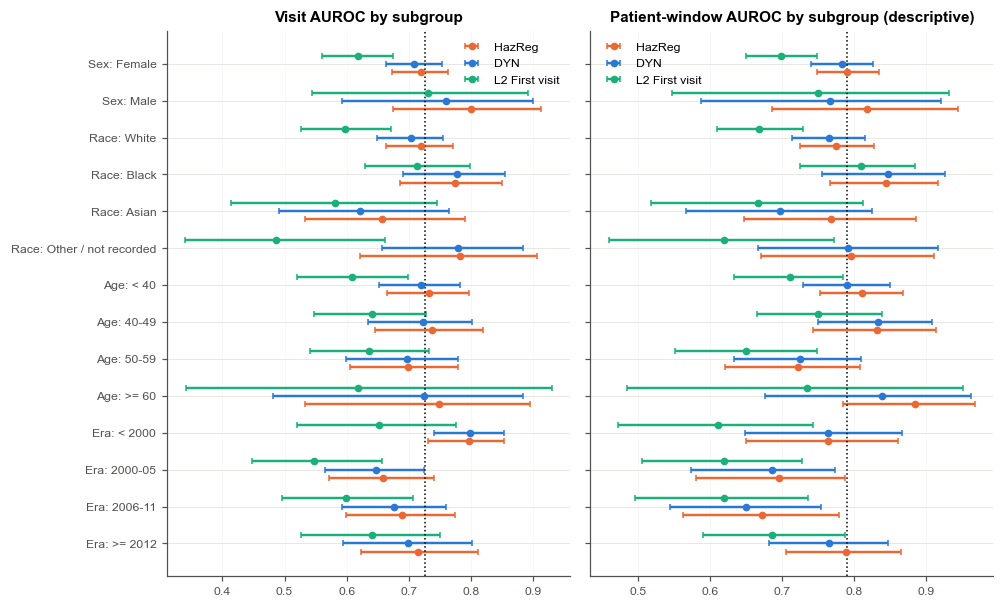

,HazReg visit,HazReg patient,DYN visit,DYN patient,L2 First visit visit,L2 First visit patient
Subgroup,,,,,,
Sex: Female,0.719 (0.672 to 0.763),0.790 (0.748 to 0.834),0.709 (0.663 to 0.753),0.783 (0.740 to 0.826),0.618 (0.561 to 0.674),0.698 (0.650 to 0.748)
Sex: Male,0.800 (0.675 to 0.912),0.817 (0.685 to 0.944),0.760 (0.593 to 0.900),0.766 (0.587 to 0.920),0.732 (0.544 to 0.891),0.750 (0.546 to 0.932)
Race: White,0.720 (0.664 to 0.772),0.774 (0.725 to 0.827),0.704 (0.649 to 0.755),0.764 (0.714 to 0.815),0.597 (0.527 to 0.671),0.668 (0.609 to 0.729)
Race: Black,0.774 (0.685 to 0.849),0.844 (0.766 to 0.917),0.777 (0.691 to 0.855),0.847 (0.755 to 0.926),0.713 (0.630 to 0.798),0.809 (0.725 to 0.884)
Race: Asian,0.656 (0.533 to 0.790),0.768 (0.647 to 0.886),0.621 (0.492 to 0.765),0.697 (0.566 to 0.824),0.581 (0.413 to 0.745),0.667 (0.517 to 0.812)
Race: Other / not recorded,0.782 (0.621 to 0.906),0.796 (0.671 to 0.911),0.779 (0.658 to 0.883),0.792 (0.667 to 0.916),0.487 (0.341 to 0.662),0.619 (0.459 to 0.772)
Age: < 40,0.732 (0.665 to 0.797),0.811 (0.753 to 0.868),0.719 (0.652 to 0.783),0.790 (0.729 to 0.849),0.608 (0.519 to 0.698),0.710 (0.633 to 0.784)
Age: 40-49,0.737 (0.646 to 0.820),0.831 (0.742 to 0.913),0.723 (0.634 to 0.802),0.833 (0.750 to 0.908),0.641 (0.547 to 0.727),0.750 (0.665 to 0.839)
Age: 50-59,0.698 (0.605 to 0.778),0.722 (0.621 to 0.808),0.696 (0.598 to 0.780),0.725 (0.633 to 0.810),0.636 (0.541 to 0.732),0.650 (0.552 to 0.749)


In [34]:
"""Subgroup AUROC forest."""
_sub_names = [n for n in SUBGROUPS if n.split(":")[0] in ("Sex", "Race", "Age", "Era")]
fig, axes = plt.subplots(1, 2, figsize=(9.2, 0.3 * len(_sub_names) + 1.4), sharey=True)
yy = np.arange(len(_sub_names))[::-1]
for ax, lev in zip(axes, ["visit", "patient"]):
    for j, m in enumerate(KEY_MODELS):
        if m not in MODELS_RUN:
            continue
        for y_, n in zip(yy, _sub_names):
            a = ci((m, lev, H, "sub", n, "auroc"))
            if np.isnan(a[0]):
                continue
            ax.errorbar(a[0], y_ + (j - 1) * 0.22, xerr=[[a[0] - a[1]], [a[2] - a[0]]], fmt="o", ms=4,
                        color=model_color(m), capsize=2, label=short_label(m) if y_ == yy[0] else None)
    ax.axvline(ci((REPORTED,) + (K_VIS if lev == "visit" else K_PT))[0], color="k", ls=":", lw=1)
    ax.set_yticks(yy); ax.set_yticklabels(_sub_names, fontsize=8); ax.grid(axis="x", alpha=0.3)
    ax.set_title("Visit AUROC by subgroup" if lev == "visit" else "Patient-window AUROC by subgroup (descriptive)"); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("subgroups")
SUB_TABLE = pd.DataFrame([{"Subgroup": n, **{f"{short_label(m)} {lev}": fmtk((m, lev, H, "sub", n, "auroc"))
                                             for m in KEY_MODELS if m in MODELS_RUN
                                             for lev in ["visit", "patient"]}} for n in _sub_names]).set_index("Subgroup")
display(SUB_TABLE)
SUB_TABLE.to_csv(f"aim2_subgroups_{TAG}.csv")

## 14.8 Conclusion — Aim 2

In [35]:
"""Aim 2 conclusion."""
_h2 = [r_ for r_ in HYP_ROWS if r_["Hypothesis"].startswith("H2")]
_m = REPORTED
txt = (f"Reported model ({model_label(_m)}): visit AUROC {fmtk((_m,) + K_VIS)} at {H} months and "
       f"{fmtk((_m,) + K_VIS12)} at 12 months; Brier {fmtk((_m,) + K_BRIER, 4)}, IPA {fmtk((_m,) + K_IPA)}; "
       f"calibration slope {ci((_m, 'visit', H, 'cal_slope'))[0]:.2f}, O/E {ci((_m, 'visit', H, 'oe'))[0]:.2f}; "
       f"time-matched patient AUROC (secondary) {fmtk((_m,) + K_TM)}. " + "; ".join(
           f"{r_['Hypothesis']} ({r_['Estimand']}) {r_['Estimate (95% CI)']}: {'met' if r_['Met'] else 'not met'}"
           for r_ in _h2) + ". " + RISK_FACTOR_SUMMARY + " " + TIER_SUMMARY + " " + INSTAB_SUMMARY)
OBJ_CONCLUSIONS["Aim 2 (the reported model)"] = txt
print(textwrap.fill(txt, 118))

Reported model (HazReg: cause-specific Poisson hazard regression on the current visit (compact set, splines) [reported
model]): visit AUROC 0.726 (0.682 to 0.769) at 24 months and 0.736 (0.693 to 0.777) at 12 months; Brier 0.0330 (0.0275
to 0.0389), IPA 0.023 (0.005 to 0.038); calibration slope 1.07, O/E 0.97; time-matched patient AUROC (secondary) 0.745
(0.707 to 0.784). H2a (HazReg: visit calibration slope / intercept) 1.069 (0.860 to 1.270) / -0.049 (-0.221 to 0.129):
met; H2b (HazReg: IPA, 24 months) 0.023 (0.005 to 0.038): met; H2c (HazReg: net benefit at 4 % minus referring at
every visit / at none) 0.0165 (0.0127 to 0.0201) / 0.0112 (0.0067 to 0.0157): met. Largest risk factors of the
reported model (hazard ratio per sd (onset)): Years since the first clinic visit 0.73, SDI damage score 1.29, EULAR
treatment step (0-4) 1.23, Fibromyalgia tender points (0-18) 1.23, Prednisone, average dose since last visit (mg/day)
1.22, Fibromyalgia 1.19. Domains: Treatment 17%, Demographics 13%

---
# 15. Aim 3 — Is deep learning far off? DYN against the reported model

DYN reads the 27 variables and the change from the patient's own baseline as a 2-year history on a 6-month grid,
passed through a recurrent network (an LSTM with about 13,000 parameters, for about 150 patients with an onset). It is shown to
answer one question: **does the deep-learning model do materially better than the regression?** Machine learning
has shown no systematic advantage over logistic regression across clinical prediction studies, sequence models
rarely beat last-visit benchmarks unless the trajectories carry strong information, and when performance is similar
the simpler model is preferred.

* **H3a**: DYN − the reported model, visit AUROC at 24 months: **equivalent** if the 95 % CI lies within ±0.02.
* **H3b**: DYN − the reported model, IPA at 24 months (accuracy: discrimination and calibration together), reported.
* The 12-month AUROC and the time-matched AUROC alongside, the difference in each CV repeat, and how closely the
  two models agree visit by visit (correlation of their logits; share of visits in the same risk tier).

,DYN,HazReg,Difference,Lower,Upper,p (bootstrap),Verdict
Metric,,,,,,,
AUROC 24 mo,0.7136,0.7255,-0.0120,-0.0297,0.0055,0.188,inconclusive
AUROC 12 mo,0.7280,0.7357,-0.0077,-0.0268,0.0123,0.460,inconclusive
IPA 24 mo,0.0251,0.0229,0.0022,-0.0060,0.0128,0.638,equivalent
Time-matched AUROC,0.7314,0.7445,-0.0132,-0.0337,0.0063,0.180,inconclusive


DYN - HazReg per CV repeat (visit AUROC): -0.006, -0.019, -0.005, -0.012, -0.018


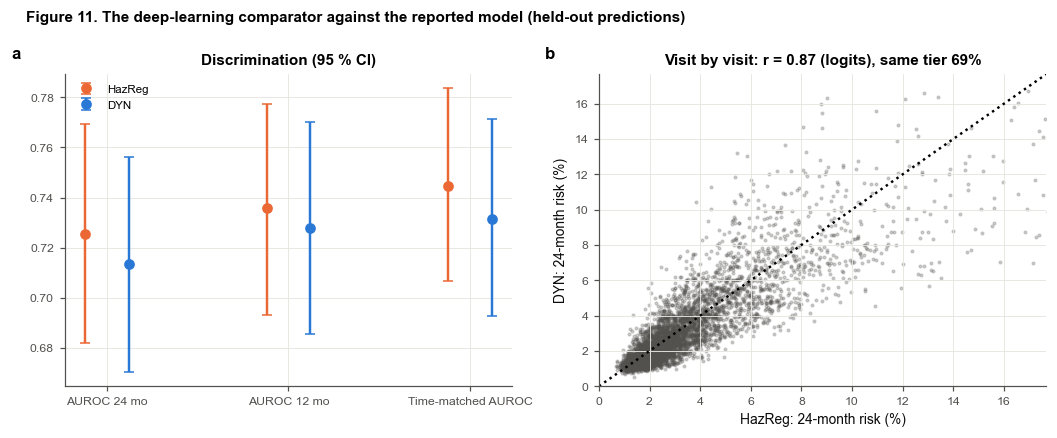

In [36]:
"""H3a-b: DYN against the reported model; agreement between their predictions."""


def repeat_diffs(a, b, key=K_VIS):
    """Point estimate of a - b in each CV repeat (visit AUROC at a horizon)."""
    rows, y, w = IPCW_H[key[1]]
    f_ = lambda m, r: wauc(y, zpred(m, r, key[1])[rows], _BOTH[:1, ROW_PIDX[rows]] * w[None, :])[0]
    return [f_(a, r) - f_(b, r) for r in REPEATS]


SEQ_KEYS = [(f"AUROC {H} mo", K_VIS), ("AUROC 12 mo", K_VIS12), (f"IPA {H} mo", K_IPA), ("Time-matched AUROC", K_TM)]
SEQ_CMP = compare([(SEQ_MAIN, REPORTED)], keys=SEQ_KEYS)
SEQ_CMP["Verdict"] = [verdict_superiority(lo, hi, EQUIV_MARGIN) for lo, hi in zip(SEQ_CMP["Lower"], SEQ_CMP["Upper"])]
display(SEQ_CMP.set_index("Metric")[["First", "Second", "Difference", "Lower", "Upper", "p (bootstrap)", "Verdict"]]
        .rename(columns={"First": short_label(SEQ_MAIN), "Second": short_label(REPORTED)}).round(4))
SEQ_CMP.to_csv(f"aim3_dyn_vs_reported_{TAG}.csv", index=False)
for lab_, key in [("H3a", K_VIS), ("H3b", K_IPA)]:
    d = diff(SEQ_MAIN, REPORTED, key)
    v = verdict_superiority(d[1], d[2], EQUIV_MARGIN)
    hyp(lab_, f"DYN - {short_label(REPORTED)}, {'IPA' if key == K_IPA else 'visit AUROC'} {H} months", d,
        f"equivalence (CI within +/-{EQUIV_MARGIN})", v == "equivalent", v)
print(f"DYN - {short_label(REPORTED)} per CV repeat (visit AUROC): " + ", ".join(f"{x:+.3f}" for x in repeat_diffs(SEQ_MAIN, REPORTED)))
_za, _zb = mean_z(REPORTED), mean_z(SEQ_MAIN)
_ok = ~np.isnan(_za) & ~np.isnan(_zb)
_tier_of = lambda p_: np.digitize(p_, [lo for lo, _, _ in RISK_TIERS[1:]])
AGREE = {"r": np.corrcoef(_za[_ok], _zb[_ok])[0, 1], "rho": stats.spearmanr(_za[_ok], _zb[_ok]).correlation,
         "same_tier": np.mean(_tier_of(_expit(_za[_ok])) == _tier_of(_expit(_zb[_ok])))}
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4))
ax = axes[0]
for m in [REPORTED, SEQ_MAIN]:
    v = np.array([ci((m,) + k) for _, k in SEQ_KEYS[:2]] + [ci((m,) + K_TM)])
    xx = np.arange(3) + (0.12 if m == SEQ_MAIN else -0.12)
    ax.errorbar(xx, v[:, 0], yerr=[v[:, 0] - v[:, 1], v[:, 2] - v[:, 0]], fmt="o", capsize=3, color=model_color(m),
                label=short_label(m))
ax.set_xticks(range(3)); ax.set_xticklabels([f"AUROC {H} mo", "AUROC 12 mo", "Time-matched AUROC"])
ax.set_title("Discrimination (95 % CI)"); ax.legend()
ax = axes[1]
_s = np.random.RandomState(SEED).choice(np.flatnonzero(_ok), min(5000, int(_ok.sum())), replace=False)
ax.scatter(100 * _expit(_za[_s]), 100 * _expit(_zb[_s]), s=3, alpha=0.25, color=INK_2, rasterized=True)
_mx = float(np.percentile(100 * _expit(np.r_[_za[_ok], _zb[_ok]]), 99.5))
ax.plot([0, _mx], [0, _mx], ":", color="k"); ax.set_xlim(0, _mx); ax.set_ylim(0, _mx)
ax.set_xlabel(f"{short_label(REPORTED)}: {H}-month risk (%)"); ax.set_ylabel(f"DYN: {H}-month risk (%)")
ax.set_title(f"Visit by visit: r = {AGREE['r']:.2f} (logits), same tier {AGREE['same_tier']:.0%}")
for a_, l_ in zip(axes, "ab"):
    panel_label(a_, l_)
fig.suptitle("Figure 11. The deep-learning comparator against the reported model (held-out predictions)", x=0.02,
             ha="left", fontsize=10, fontweight="bold")
plt.tight_layout(); save_fig("fig11_dyn_vs_logreg")

## 15.2 DYN: performance, tables and figures

DYN: grid LSTM, last 2 years, current status + change from own baseline, one hazard [comparator]


,Visit level,Patient windows (descriptive)
Metric,,
"AUROC, 24 months (IPCW; primary)",0.714 (0.670 to 0.756),0.781 (0.739 to 0.824)
"AUROC, 12 months (IPCW)",0.728 (0.685 to 0.770),0.797 (0.755 to 0.839)
"Brier score, 24 months (IPCW)",0.0329 (0.0274 to 0.0387),-
"IPA, 24 months (1 - Brier / null Brier)",0.025 (0.011 to 0.038),-
Time-matched patient AUROC (secondary: calendar-time check),-,0.731 (0.693 to 0.771)
Time-matched patient sensitivity / specificity,-,0.661 / 0.678
Risk-set C (calendar-time risk sets),-,0.745 (0.703 to 0.785)
Calibration slope,1.054 (0.872 to 1.285),1.074 (0.920 to 1.309)
Calibration intercept,0.001 (-0.179 to 0.173),0.052 (-0.158 to 0.256)


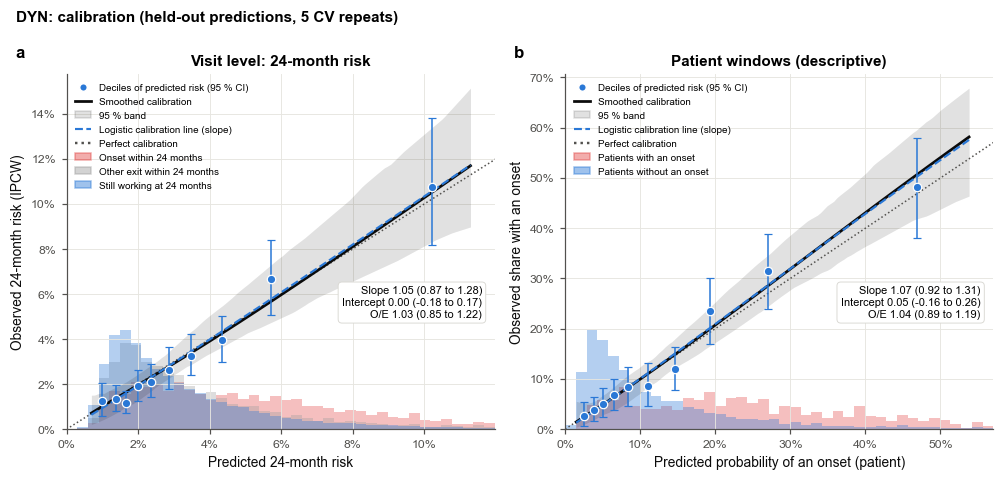

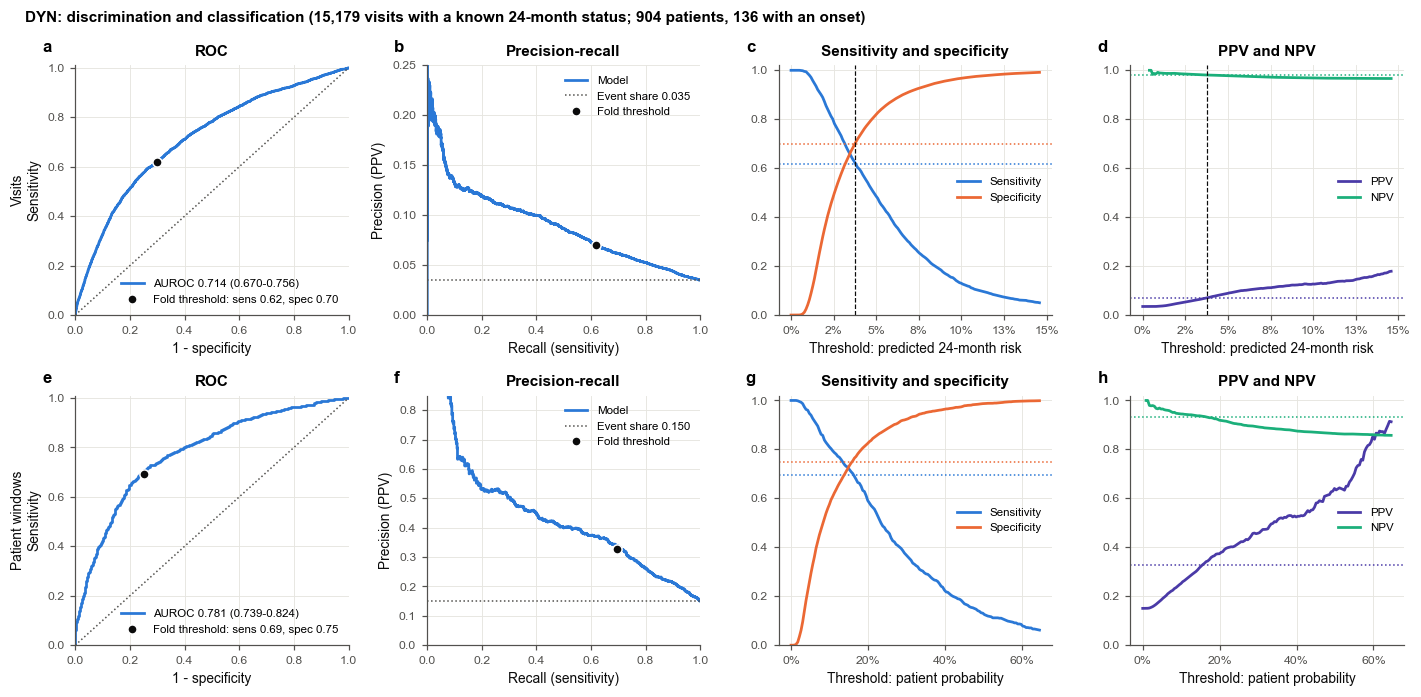

In [37]:
model_section(SEQ_MAIN)

## 15.3 Conclusion — Aim 3

In [38]:
"""Aim 3 conclusion."""
_h3 = [r_ for r_ in HYP_ROWS if r_["Hypothesis"].startswith("H3")]
_F_IN_ = len(GridPrep(grid_cols_of(SEQ_MAIN)).names)
P_LSTM_N = 4 * SEQ_CFG["hidden"] * (_F_IN_ + SEQ_CFG["hidden"]) + 8 * SEQ_CFG["hidden"] + (SEQ_CFG["hidden"] + _F_IN_) * 2 + 2
txt = ("; ".join(f"{r_['Hypothesis']} {r_['Estimand']} {r_['Estimate (95% CI)']} ({r_['Verdict']})" for r_ in _h3)
       + f". DYN has {P_LSTM_N:,} parameters; {short_label(REPORTED)} {sum(len(p_[1]) + 1 for p_ in PARAMS_FINAL)} "
       f"coefficients. Their held-out logits correlate "
       f"{AGREE['r']:.2f} (Spearman {AGREE['rho']:.2f}) and put {AGREE['same_tier']:.0%} of visits in the same risk tier.")
OBJ_CONCLUSIONS["Aim 3 (deep learning)"] = txt
print(textwrap.fill(txt, 118))

H3a DYN - HazReg, visit AUROC 24 months -0.012 (-0.030 to 0.005) (inconclusive); H3b DYN - HazReg, IPA 24 months 0.002
(-0.006 to 0.013) (equivalent). DYN has 12,868 parameters; HazReg 70 coefficients. Their held-out logits correlate
0.87 (Spearman 0.87) and put 69% of visits in the same risk tier.


---
# 16. What the risk represents: stratification, not early warning

A model updated at every visit could do two different things: **rank how sick patients are** (a stable,
patient-level risk) or **detect change** (a risk that rises before the onset). Only the second supports an
"early-warning" reading. Five checks, for the reported model and DYN:

1. **Discrimination by time before the onset** (time-matched; H4a): if the risk rises as the onset approaches, the
   AUROC is higher 0-24 months before the onset than 24-36 months before it.
2. **Within-patient change** (year-centred logits; H4b mixed model, H4c within-patient C): does the same patient's
   risk rise before their onset, more than in patients who stay at work?
3. **Tier stability** (Section 14.5): how often the risk tier changes between consecutive visits.
4. **Lead time against a constant-risk null** (H4d): the lead time of a patient-level alarm is bounded by the
   24-month window, so a persistently high-risk patient produces a long "lead time" without any rise. The null gives
   each patient a constant risk (their mean over the window); its alarm fires at the window's first landmark.

## 16.1 Discrimination by time before the onset (H4a)

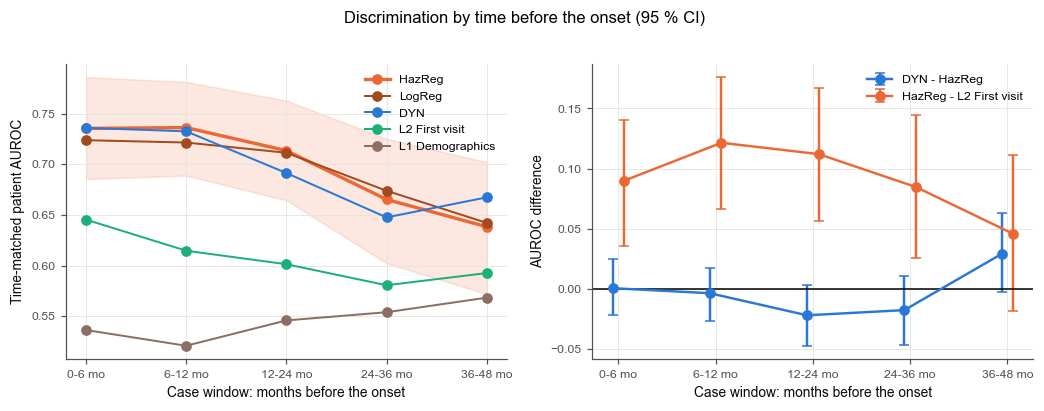

,0-6 mo before,6-12 mo before,12-24 mo before,24-36 mo before,36-48 mo before,0-24 mo (main window)
Model,,,,,,
HazReg,0.735 (0.685 to 0.786),0.736 (0.689 to 0.781),0.713 (0.664 to 0.763),0.665 (0.602 to 0.725),0.638 (0.572 to 0.702),0.745 (0.707 to 0.784)
LogReg,0.724 (0.672 to 0.775),0.721 (0.672 to 0.767),0.711 (0.662 to 0.762),0.674 (0.611 to 0.734),0.642 (0.580 to 0.707),0.733 (0.692 to 0.774)
DYN,0.736 (0.687 to 0.786),0.732 (0.683 to 0.780),0.691 (0.639 to 0.742),0.648 (0.588 to 0.702),0.667 (0.607 to 0.729),0.731 (0.693 to 0.771)
L2 First visit,0.645 (0.591 to 0.703),0.615 (0.557 to 0.673),0.601 (0.541 to 0.666),0.581 (0.512 to 0.653),0.593 (0.524 to 0.663),0.634 (0.587 to 0.684)
L1 Demographics,0.536 (0.485 to 0.585),0.521 (0.466 to 0.578),0.546 (0.494 to 0.598),0.554 (0.492 to 0.615),0.568 (0.508 to 0.624),0.540 (0.494 to 0.586)


,AUROC 0-24 mo before minus 24-36 mo before,Lower bound > 0
Model,,
HazReg,0.079 (0.034 to 0.125),True
LogReg,0.059 (0.016 to 0.104),True
DYN,0.084 (0.036 to 0.130),True
L2 First visit,0.053 (0.010 to 0.102),True
L1 Demographics,-0.014 (-0.052 to 0.027),False


Onsets / pairs per window: main: 158 / 43,991, 0-6: 117 / 32,834, 6-12: 109 / 28,880, 12-24: 104 / 26,792, 24-36: 86 / 19,422, 36-48: 77 / 16,514


In [39]:
"""Time-matched AUROC by time before the onset; H4a."""
_tto = [k for k in TM_WINDOWS if k != "main"]
_sm = [m for m in [REPORTED, OTHER, SEQ_MAIN, L2_FIRST, L1_DEMO] if m in MODELS_RUN]
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
rows = []
for m in _sm:
    v = np.array([ci((m, "tm", k, "auroc")) for k in _tto])
    axes[0].plot(range(len(_tto)), v[:, 0], "o-", color=model_color(m), lw=2.2 if m == REPORTED else 1.3,
                 label=short_label(m))
    if m == REPORTED:
        axes[0].fill_between(range(len(_tto)), v[:, 1], v[:, 2], color=model_color(m), alpha=0.15)
    rows.append({"Model": short_label(m), **{f"{k} mo before": fmt(*v_) for k, v_ in zip(_tto, v)},
                 f"0-{H} mo (main window)": fmtk((m,) + K_TM)})
for j, (a_, b_) in enumerate([(SEQ_MAIN, REPORTED), (REPORTED, L2_FIRST)]):
    d = np.array([diff(a_, b_, ("tm", k, "auroc"))[:3] for k in _tto])
    xs = np.arange(len(_tto)) + (j - 0.5) * 0.12
    axes[1].errorbar(xs, d[:, 0], yerr=[d[:, 0] - d[:, 1], d[:, 2] - d[:, 0]], fmt="o-", capsize=3,
                     color=model_color(a_), label=f"{short_label(a_)} - {short_label(b_)}")
for ax in axes:
    ax.set_xticks(range(len(_tto))); ax.set_xticklabels([f"{k} mo" for k in _tto])
    ax.set_xlabel("Case window: months before the onset"); ax.legend(fontsize=8)
axes[0].set_ylabel("Time-matched patient AUROC"); axes[1].axhline(0, color="k", lw=1)
axes[1].set_ylabel("AUROC difference")
fig.suptitle("Discrimination by time before the onset (95 % CI)", y=1.02)
plt.tight_layout(); save_fig("fig12_by_time_to_onset")
TTO_TABLE = pd.DataFrame(rows).set_index("Model")
display(TTO_TABLE)
TTO_TABLE.to_csv(f"aim3s_by_time_to_onset_{TAG}.csv")
_near, _far = ("tm", "main", "auroc"), ("tm", f"{H2A_FAR[0]}-{H2A_FAR[1]}", "auroc")
rows = []
for m in _sm:
    d = _diff_summary(STATS[(m,) + _near][0] - STATS[(m,) + _far][0], STATS[(m,) + _near][1] - STATS[(m,) + _far][1])
    rows.append({"Model": short_label(m), f"AUROC 0-{H} mo before minus {H2A_FAR[0]}-{H2A_FAR[1]} mo before": fmt(*d[:3]),
                 "Lower bound > 0": d[1] > 0})
    if m == REPORTED:
        hyp("H4a", f"{short_label(REPORTED)}: time-matched AUROC 0-{H} minus {H2A_FAR[0]}-{H2A_FAR[1]} months before onset", d,
            "lower bound > 0", d[1] > 0)
display(pd.DataFrame(rows).set_index("Model"))
print("Onsets / pairs per window: " + ", ".join(f"{k}: {TM[k]['n_onsets']} / {len(TM[k]['pc']):,}" for k in TM))

## 16.2 Does each patient's risk rise as the onset approaches? (H4b, H4c)

Each model's 24-month logit is **centred on the calendar year** (minus the mean logit of every landmark in the same
year), so the fall in the predicted risk over the decades (from the changing case mix) does not look like a fall
within patients. Onset-aligned
trajectories (mean and 95 % CI over patients) against patients who never have an onset (aligned at their last
landmark); **H4b**: a linear mixed model of the centred logit on time (years, −4 to 0 before the anchor) with a random
intercept per patient, the interaction (extra rise per year in onset patients) > 0. **H4c**: the within-patient C
(the same onset patient's landmarks ≤ 12 months before the onset against those > 24 months before; 0.5 = no rise).
Age rises within every patient and damage (SDI) can only accrue, so a model can score above 0.5 without detecting
anything about the coming onset: L1 (demographics) is the null. H4c is the reported model's within-patient C
minus L1's, lower 95 % bound > 0. L1 is also fitted in the mixed model (its interaction is what age alone produces;
the never-onset patients, who also age, are H4b's control).

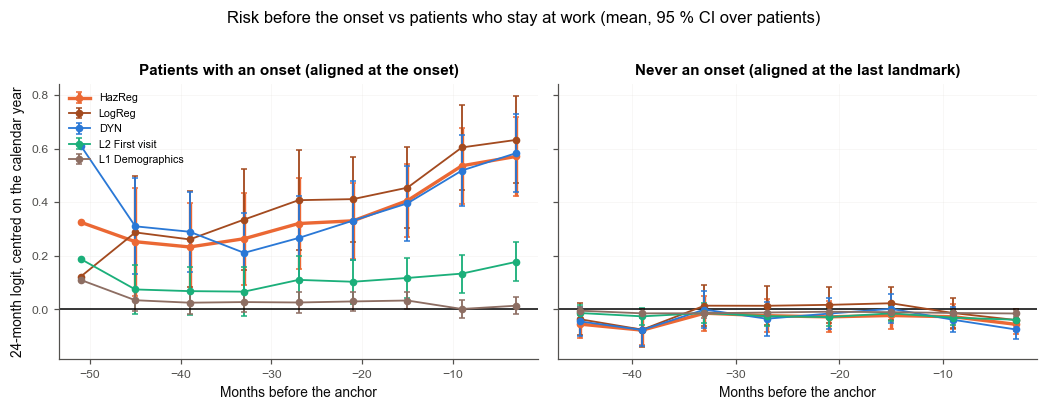

,"Slope per year, never-onset","Extra slope per year, onset patients (interaction)","Slope per year, onset patients",Level difference at the anchor (onset - never)
Model,,,,
HazReg,-0.013 (-0.019 to -0.007),0.056 (0.036 to 0.075),0.043,0.614
LogReg,-0.004 (-0.012 to 0.004),0.064 (0.039 to 0.088),0.060,0.671
DYN,-0.029 (-0.037 to -0.022),0.080 (0.057 to 0.102),0.050,0.611
L2 First visit,-0.013 (-0.014 to -0.012),0.001 (-0.001 to 0.003),-0.012,0.194
L1 Demographics,0.006 (0.006 to 0.006),-0.003 (-0.004 to -0.003),0.002,0.025


Within-patient C: 79 onset patients with landmarks <= 12 and > 24 months before the onset


,Within-patient C (year-centred),Minus L1 (demographics: the null),Minus L2 (first visit)
Model,,,
L1 Demographics,0.672 (0.623 to 0.722),0.000 (0.000 to 0.000),0.424 (0.345 to 0.501)
L2 First visit,0.248 (0.185 to 0.309),-0.424 (-0.501 to -0.345),0.000 (0.000 to 0.000)
HazReg,0.591 (0.519 to 0.661),-0.081 (-0.177 to 0.016),0.343 (0.264 to 0.429)
LogReg,0.616 (0.548 to 0.684),-0.056 (-0.153 to 0.041),0.368 (0.292 to 0.446)
Unit score,0.707 (0.641 to 0.769),0.035 (-0.054 to 0.118),0.459 (0.369 to 0.544)
DYN,0.622 (0.559 to 0.689),-0.051 (-0.137 to 0.039),0.374 (0.296 to 0.456)
HazReg linear,0.581 (0.508 to 0.651),-0.092 (-0.186 to 0.006),0.333 (0.252 to 0.420)
HazReg + year,0.599 (0.530 to 0.669),-0.073 (-0.165 to 0.022),0.352 (0.272 to 0.436)
HazReg wide,0.584 (0.520 to 0.648),-0.088 (-0.177 to 0.001),0.336 (0.255 to 0.415)


In [40]:
"""Year-centred risk: trajectories, mixed model (H4b) and within-patient C (H4c)."""
import statsmodels.formula.api as smf

_YR = np.floor(land["CAL_YEAR"].values).astype(int)


def centred(m):
    out = []
    for r in REPEATS:
        z = zpred(m, r)
        yrm = pd.Series(z).groupby(_YR).transform("mean").values
        out.append(z - yrm)
    return out                                        # one array per repeat


ZC = {m: centred(m) for m in MODELS_RUN}
_anchor = {p: FIRST_ONSET[p].value / 8.64e13 for p in EVER_ONSET}
_ctrl = [p for p in PT_ROWS if p not in EVER_ONSET]
_anchor.update({p: _LAND_T[PT_ROWS[p]].max() + 1 for p in _ctrl})


def aligned(m):
    """Long table: patient, onset patient or not, months before the anchor, centred logit (mean over repeats)."""
    zc = np.mean(ZC[m], 0)
    recs = []
    for pid, li in PT_ROWS.items():
        mo = (_anchor[pid] - _LAND_T[li]) / MONTH_DAYS
        k = (mo > 0) & (mo <= TRAJ_MAX_MONTHS)
        recs.append(pd.DataFrame({"pid": pid, "event": int(pid in EVER_ONSET), "mo": mo[k], "zc": zc[li][k]}))
    return pd.concat(recs, ignore_index=True)


ALIGNED = {m: aligned(m) for m in [REPORTED, OTHER, SEQ_MAIN, L2_FIRST, L1_DEMO] if m in MODELS_RUN}
_bins = np.arange(0, TRAJ_MAX_MONTHS + 1, 6)
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6), sharey=True)
for ax, ev, ttl in zip(axes, [1, 0], ["Patients with an onset (aligned at the onset)",
                                     "Never an onset (aligned at the last landmark)"]):
    for m, A in ALIGNED.items():
        a = A[A["event"] == ev].copy()
        a["bin"] = np.digitize(a["mo"], _bins)
        g = a.groupby(["bin", "pid"])["zc"].mean().groupby("bin").agg(["mean", "sem"])
        xs = -(_bins[g.index.values - 1] + 3)
        ax.errorbar(xs, g["mean"], yerr=1.96 * g["sem"], fmt="o-", ms=4, capsize=2, color=model_color(m),
                    lw=2.2 if m == REPORTED else 1.2, label=short_label(m))
    ax.axhline(0, color="k", lw=1); ax.grid(alpha=0.3); ax.set_title(ttl, fontsize=10)
    ax.set_xlabel("Months before the anchor")
axes[0].set_ylabel(f"{H}-month logit, centred on the calendar year"); axes[0].legend(fontsize=7)
fig.suptitle("Risk before the onset vs patients who stay at work (mean, 95 % CI over patients)", y=1.02)
plt.tight_layout(); save_fig("trajectories")

rows = []
for m, A in ALIGNED.items():
    A = A.assign(t=-A["mo"] / 12.0)
    fit = smf.mixedlm("zc ~ t * event", A, groups=A["pid"]).fit(reml=True)
    ci_ = fit.conf_int()
    sl0 = (fit.params["t"], *ci_.loc["t"])
    it = (fit.params["t:event"], *ci_.loc["t:event"])
    rows.append({"Model": short_label(m), "Slope per year, never-onset": fmt(*sl0),
                 "Extra slope per year, onset patients (interaction)": fmt(*it),
                 "Slope per year, onset patients": f"{sl0[0] + it[0]:.3f}",
                 "Level difference at the anchor (onset - never)": f"{fit.params['event']:.3f}"})
    if m == REPORTED:
        hyp("H4b", f"{short_label(REPORTED)}: extra rise per year before onset vs never-onset (mixed model, year-centred logit)", it,
            "lower bound > 0", it[1] > 0)
MIXED = pd.DataFrame(rows).set_index("Model")
display(MIXED)
MIXED.to_csv(f"aim3s_mixed_model_{TAG}.csv")

# within-patient C on the centred logits
_pn, _pf, _pp, _pw = [], [], [], []
for pid in EVER_ONSET:
    li = PT_ROWS[pid]
    mo = (_anchor[pid] - _LAND_T[li]) / MONTH_DAYS
    near, far = li[(mo > 0) & (mo <= WITHIN_NEAR_MONTHS)], li[mo > WITHIN_FAR_MONTHS]
    if len(near) and len(far):
        a_, b_ = np.meshgrid(near, far, indexing="ij")
        _pn.append(a_.ravel()); _pf.append(b_.ravel())
        _pp.append(np.full(a_.size, PID_INDEX[pid])); _pw.append(np.full(a_.size, 1.0 / a_.size))
W_NEAR, W_FAR, W_PIDX, W_WT = (np.concatenate(x) for x in (_pn, _pf, _pp, _pw))
for m in MODELS_RUN:
    vals = []
    for zc in ZC[m]:
        conc = (zc[W_NEAR] > zc[W_FAR]) + 0.5 * (zc[W_NEAR] == zc[W_FAR])
        Wb = _BOTH[:, W_PIDX] * W_WT[None, :]
        vals.append((Wb @ conc) / Wb.sum(1))
    v = np.mean(vals, 0)
    STATS[(m, "within", H, "c")] = (float(v[0]), v[1:])
WITHIN_T = pd.DataFrame([{"Model": short_label(m), "Within-patient C (year-centred)": fmtk((m, "within", H, "c")),
                          "Minus L1 (demographics: the null)": fmt(*diff(m, L1_DEMO, ("within", H, "c"))[:3]),
                          "Minus L2 (first visit)": fmt(*diff(m, L2_FIRST, ("within", H, "c"))[:3])}
                         for m in MODELS_RUN]
                        ).set_index("Model")
print(f"Within-patient C: {len(np.unique(W_PIDX))} onset patients with landmarks <= {WITHIN_NEAR_MONTHS} and > "
      f"{WITHIN_FAR_MONTHS} months before the onset")
display(WITHIN_T)
WITHIN_T.to_csv(f"aim3s_within_patient_{TAG}.csv")

_wc = diff(REPORTED, L1_DEMO, ("within", H, "c"))
hyp("H4c", f"{short_label(REPORTED)} - L1: within-patient C (year-centred), <= 12 vs > 24 months before onset "
    f"({short_label(REPORTED)} alone {fmtk((REPORTED, 'within', H, 'c'))})", _wc, "lower bound > 0", _wc[1] > 0)

## 16.3 Lead time against a constant-risk null (H4d)

For each onset patient flagged at the patient level (Section 9; running mean of the window's logits reaching the
fold's patient threshold), the lead time is the time from the alarm to the onset. The **constant-risk null** replaces
the patient's scores by their window mean: the same patients are flagged or not, but every alarm fires at the
window's first landmark, so its lead time is the longest the design allows. If the model's lead time is close to the
null's, and most alarms already fire at the first landmark, the "lead time" reflects patients who were high-risk
throughout, not a risk that rose ahead of the onset. **H4d**: fewer than half of the flagged onset patients are
already flagged at their window's first landmark (upper 95 % bound < 0.5).

In [41]:
"""Lead time vs the constant-risk null (H4d)."""


def lead_vs_null(m, r):
    W = PTW[H]
    z, thr = zpred(m, r), THR_P[m][r][H][MAIN_THRESHOLD]
    zc = z.copy()
    for rr in W["rows"]:
        zc[rr] = np.nanmean(z[rr])
    fire, fire0 = fire_dates(z, thr, W), fire_dates(zc, thr, W)
    first = VISIT_DATE[np.array([rr[0] for rr in W["rows"]])].astype("datetime64[ns]")
    mo = lambda d: ((W["event_date"] - d) / np.timedelta64(1, "D")).astype(float) / MONTH_DAYS
    ok = (W["event"] == 1) & ~np.isnat(fire)
    return {"lead": mo(fire), "lead0": mo(fire0), "span": mo(first), "ok": ok, "ok0": ok & ~np.isnat(fire0),
            "at_first": ok & (fire == first), "onset": W["event"] == 1}


Wp_ = _BOTH[:, PTW_PIDX[H]]
rows, LEADNULL = [], {}
for m in [x for x in [REPORTED, OTHER, SEQ_MAIN, L2_FIRST] if x in MODELS_RUN]:
    acc = {k_: [] for k_ in ["lead", "lead0", "span", "share_first", "flagged"]}
    for r in REPEATS:
        d = lead_vs_null(m, r)
        acc["lead"].append(wmedian(d["lead"][d["ok"]], Wp_[:, d["ok"]]))
        acc["lead0"].append(wmedian(d["lead0"][d["ok0"]], Wp_[:, d["ok0"]]))
        acc["span"].append(wmedian(d["span"][d["onset"]], Wp_[:, d["onset"]]))
        acc["share_first"].append(_ratio(Wp_ @ d["at_first"].astype(float), Wp_ @ d["ok"].astype(float)))
        acc["flagged"].append(_ratio(Wp_ @ d["ok"].astype(float), Wp_ @ d["onset"].astype(float)))
    v = {k_: np.nanmean(np.vstack(a_), 0) for k_, a_ in acc.items()}
    LEADNULL[m] = v
    rows.append({"Model": short_label(m), "Onset patients flagged": fci(v["flagged"]),
                 "Median lead time (months)": fci(v["lead"], 1),
                 "Constant-risk null: median lead time": fci(v["lead0"], 1),
                 "Median window span (first landmark to onset)": fci(v["span"], 1),
                 "Flagged already at the window's first landmark": fci(v["share_first"])})
    if m == REPORTED or m == SEQ_MAIN:
        a_ = v["share_first"]
        lo, hi = np.nanpercentile(a_[1:], [2.5, 97.5])
        hyp("H4d" if m == REPORTED else "H4d (DYN)", f"{short_label(m)}: share of flagged onset patients already "
            "flagged at the window's first landmark", (a_[0], lo, hi), "upper bound < 0.5", hi < 0.5)
LEAD_NULL = pd.DataFrame(rows).set_index("Model")
display(LEAD_NULL)
LEAD_NULL.to_csv(f"aim3s_lead_time_vs_null_{TAG}.csv")
_l = LEADNULL[REPORTED]
LEAD_SUMMARY = (f"Lead time ({short_label(REPORTED)}): median {_l['lead'][0]:.1f} months against "
                f"{_l['lead0'][0]:.1f} for the constant-risk null; the window spans a median {_l['span'][0]:.1f} "
                f"months; {_l['share_first'][0]:.0%} of flagged onset patients are flagged at their window's first "
                f"landmark.")
print(LEAD_SUMMARY)

,Onset patients flagged,Median lead time (months),Constant-risk null: median lead time,Median window span (first landmark to onset),Flagged already at the window's first landmark
Model,,,,,
HazReg,0.760 (0.696 to 0.823),17.1 (14.7 to 19.6),18.7 (14.8 to 20.2),19.8 (18.1 to 20.9),0.894 (0.846 to 0.937)
LogReg,0.741 (0.678 to 0.806),17.9 (15.3 to 20.0),19.3 (15.5 to 20.6),19.8 (18.1 to 20.9),0.891 (0.845 to 0.933)
DYN,0.721 (0.651 to 0.788),17.8 (14.4 to 19.4),19.3 (15.3 to 20.6),19.8 (18.1 to 20.9),0.857 (0.799 to 0.913)
L2 First visit,0.601 (0.532 to 0.672),18.7 (14.8 to 20.4),18.4 (14.6 to 20.3),19.8 (18.1 to 20.9),1.000 (1.000 to 1.000)


Lead time (HazReg): median 17.1 months against 18.7 for the constant-risk null; the window spans a median 19.8 months; 89% of flagged onset patients are flagged at their window's first landmark.


## 16.4 Conclusion — stratification or early warning?

In [42]:
"""Stratification conclusion."""
_h4 = [r_ for r_ in HYP_ROWS if r_["Hypothesis"].startswith("H4")]
txt = ("; ".join(f"{r_['Hypothesis']} ({r_['Estimand']}) {r_['Estimate (95% CI)']}: {'met' if r_['Met'] else 'not met'}"
                 for r_ in _h4) + ". The risk tier stays the same at " + ", ".join(
    f"{TIER_STAY[m]:.0%} ({short_label(m)})" for m in TIER_STAY) + " of consecutive visits. " + LEAD_SUMMARY)
OBJ_CONCLUSIONS["What the risk represents"] = txt
print(textwrap.fill(txt, 118))

H4a (HazReg: time-matched AUROC 0-24 minus 24-36 months before onset) 0.079 (0.034 to 0.125): met; H4b (HazReg: extra
rise per year before onset vs never-onset (mixed model, year-centred logit)) 0.056 (0.036 to 0.075): met; H4c (HazReg
- L1: within-patient C (year-centred), <= 12 vs > 24 months before onset (HazReg alone 0.591 (0.519 to 0.661))) -0.081
(-0.177 to 0.016): not met; H4d (HazReg: share of flagged onset patients already flagged at the window's first
landmark) 0.894 (0.846 to 0.937): not met; H4d (DYN) (DYN: share of flagged onset patients already flagged at the
window's first landmark) 0.857 (0.799 to 0.913): not met. The risk tier stays the same at 80% (HazReg), 77% (LogReg),
76% (DYN) of consecutive visits. Lead time (HazReg): median 17.1 months against 18.7 for the constant-risk null; the
window spans a median 19.8 months; 89% of flagged onset patients are flagged at their window's first landmark.


---
# 17. Sensitivity analyses

## 17.1 Refitted variants of the reported model

Each variant is a refitted model on the same folds, compared with HazReg on the same bootstrap resamples (equivalent
when the 95 % CI of the difference lies within ±0.02):

| Variant | What changes |
|---|---|
| LogReg | the logistic regression of the 24-month label instead of the hazards (same inputs) |
| HazReg linear | no spline terms |
| **HazReg + year** | the calendar year (linear + spline) added as an input, clipped to the training years at prediction |
| HazReg wide | the wide input set: + change from own baseline, race, care-process and work-history inputs |

**Is the model confounded by era?** The onset rate fell over the decades while treatment and case mix changed
(lower prednisone doses, more antimalarials and immunosuppressants). Without a calendar term, part of the fall in
the rate could be absorbed into the coefficients of the clinical inputs that changed over the same years. The
year-adjusted model estimates each coefficient within era; if its coefficients are close to HazReg's, the reported
coefficients are not carrying the era. Both are refitted on every patient with their most-chosen penalty and the
onset hazard ratios compared input by input (with HazReg's bootstrap intervals from Section 14.2).

In [43]:
"""Refitted variants of the reported model against it."""
SENS_KEYS = [(f"AUROC {H} mo", K_VIS), ("AUROC 12 mo", K_VIS12), (f"IPA {H} mo", K_IPA), ("Time-matched AUROC", K_TM),
             ("Calibration slope", ("visit", H, "cal_slope"))]
print("Penalty chosen (count over folds): " + "; ".join(
    f"{short_label(m)} " + ", ".join(f"{k} x{v}" for k, v in pd.Series(BEST_CFG[m]).value_counts().items())
    for m in [HZ_C, LR_C, HZ_CL, HZ_YR, HZ_FULL] if m in BEST_CFG))
rows = []
for lab_, v in SENS_VARIANTS.items():
    if v not in MODELS_RUN:
        continue
    b = SENS_BASE[v]
    row = {"Variant": lab_, "Model": short_label(v), "Visit slope": f"{ci((v, 'visit', H, 'cal_slope'))[0]:.2f}",
           "Visit O/E": fmtk((v, "visit", H, "oe"), 2)}
    for kl, key in SENS_KEYS[:4]:
        d = diff(v, b, key)
        row[kl] = fmtk((v,) + key)
        row[f"{kl}: minus {short_label(b)}"] = f"{fmt(*d[:3])} {verdict_superiority(d[1], d[2], EQUIV_MARGIN)[:5]}"
    rows.append(row)
    d = diff(v, b, K_VIS)
    hyp(f"S ({lab_})", f"{short_label(v)} - {short_label(b)}, visit AUROC {H} months", d,
        f"equivalence (CI within +/-{EQUIV_MARGIN})", verdict_superiority(d[1], d[2], EQUIV_MARGIN) == "equivalent",
        verdict_superiority(d[1], d[2], EQUIV_MARGIN))
SENS_TABLE = pd.DataFrame(rows).set_index(["Variant", "Model"])
display(SENS_TABLE)
SENS_TABLE.to_csv(f"sensitivity_inputs_{TAG}.csv")

Penalty chosen (count over folds): HazReg a0.001 x23, a0.0003 x2; LogReg C0.003 x19, C0.01 x4, C0.1 x2; HazReg linear a0.001 x20, a0.0003 x4, a0.003 x1; HazReg + year a0.001 x25; HazReg wide a0.003 x25


,,Visit slope,Visit O/E,AUROC 24 mo,AUROC 24 mo: minus HazReg,AUROC 12 mo,AUROC 12 mo: minus HazReg,IPA 24 mo,IPA 24 mo: minus HazReg,Time-matched AUROC,Time-matched AUROC: minus HazReg
Variant,Model,,,,,,,,,,
logistic 24-month label (LogReg),LogReg,0.96,0.97 (0.80 to 1.15),0.724 (0.679 to 0.769),-0.001 (-0.016 to 0.014) equiv,0.727 (0.684 to 0.772),-0.008 (-0.023 to 0.007) incon,0.025 (0.006 to 0.041),0.002 (-0.007 to 0.011) equiv,0.733 (0.692 to 0.774),-0.012 (-0.026 to 0.003) incon
linear (no splines),HazReg linear,1.05,0.97 (0.81 to 1.15),0.723 (0.678 to 0.766),-0.002 (-0.011 to 0.005) equiv,0.729 (0.687 to 0.771),-0.006 (-0.016 to 0.003) equiv,0.024 (0.007 to 0.039),0.001 (-0.003 to 0.007) equiv,0.735 (0.697 to 0.775),-0.009 (-0.020 to 0.000) equiv
calendar-year adjusted,HazReg + year,1.06,0.99 (0.82 to 1.17),0.731 (0.686 to 0.773),0.005 (-0.003 to 0.013) equiv,0.742 (0.700 to 0.783),0.006 (-0.003 to 0.014) equiv,0.024 (0.006 to 0.039),0.001 (-0.001 to 0.004) equiv,0.740 (0.703 to 0.778),-0.005 (-0.009 to -0.001) infer
wide input set,HazReg wide,1.07,0.97 (0.81 to 1.15),0.706 (0.663 to 0.746),-0.020 (-0.039 to -0.001) infer,0.713 (0.669 to 0.753),-0.023 (-0.043 to -0.003) infer,0.025 (0.010 to 0.039),0.002 (-0.008 to 0.012) equiv,0.724 (0.688 to 0.767),-0.020 (-0.041 to 0.001) incon


In [44]:
"""Year adjustment: HazReg's onset hazard ratios with and without the calendar year."""
if HZ_YR in MODELS_RUN:
    _cfg_yr = model_grid(HZ_YR)[pd.Series(BEST_CFG[HZ_YR]).value_counts().index[0]]
    _, _prep_yr, _par_yr = fit_full(HZ_YR, _cfg_yr, _ALL_ROWS)
    _cy = pd.Series(_par_yr[0][1], index=_prep_yr.names)
    _c0 = pd.Series(PARAMS_FINAL[0][1], index=PREP_FINAL.names)
    _b0 = pd.DataFrame(np.vstack([p_[0][1] for p_ in PARAMS_BOOT]), columns=PREP_FINAL.names)
    _cc = [c for c in _c0.index if c in _cy.index and not c.endswith("__MISSING")]
    YEAR_COEF = pd.DataFrame({
        "Input": [sh_display_any(c) for c in _cc],
        "HazReg: HR per SD": np.exp(_c0[_cc]).round(3).values,
        "95 % bootstrap interval": [f"{np.exp(np.percentile(_b0[c], 2.5)):.2f}-{np.exp(np.percentile(_b0[c], 97.5)):.2f}"
                                    for c in _cc],
        "HazReg + year: HR per SD": np.exp(_cy[_cc]).round(3).values,
        "Ratio (year-adjusted / reported)": np.exp(_cy[_cc] - _c0[_cc]).round(3).values,
        "Inside the bootstrap interval": [np.percentile(_b0[c], 2.5) <= _cy[c] <= np.percentile(_b0[c], 97.5)
                                          for c in _cc]}, index=_cc)
    YEAR_COEF = YEAR_COEF.reindex(_c0[_cc].abs().sort_values(ascending=False).index)
    display(YEAR_COEF)
    YEAR_COEF.to_csv(f"sensitivity_year_adjusted_coefficients_{TAG}.csv")
    _yr_terms = [c for c in _cy.index if c in YEAR_COLS]
    _lin = [c for c in _cc if not c.endswith("__NL")]
    _r = np.exp(_cy[_lin] - _c0[_lin])
    YEAR_ADJ_SUMMARY = (
        f"Calendar-year adjustment: of {len(_lin)} linear terms, {int(YEAR_COEF.loc[_lin, 'Inside the bootstrap interval'].sum())} "
        f"year-adjusted hazard ratios lie inside HazReg's bootstrap interval; the ratio of the two hazard ratios ranges "
        f"{_r.min():.2f}-{_r.max():.2f} (largest change: {sh_display_any(_r.sub(1).abs().idxmax())}). Year terms "
        "(per SD): " + ", ".join(f"{c} HR {np.exp(_cy[c]):.2f}" for c in _yr_terms) + ". HazReg + year - HazReg, "
        f"visit AUROC {fmt(*diff(HZ_YR, REPORTED, K_VIS)[:3])}, within-era AUROC "
        f"{fci(within_era_auroc(HZ_YR) - WITHIN_ERA[REPORTED])}.")
    print(textwrap.fill(YEAR_ADJ_SUMMARY, 118))
else:
    YEAR_ADJ_SUMMARY = ""

,Input,HazReg: HR per SD,95 % bootstrap interval,HazReg + year: HR per SD,Ratio (year-adjusted / reported),Inside the bootstrap interval
age_at_record__NL,Age: spline term,1.379,1.07-1.75,1.401,1.017,True
YRS_IN_CLINIC,Years since the first clinic visit,0.735,0.60-0.91,0.763,1.038,True
SLEDAI2_I__NL,SLEDAI-2K: spline term,1.298,1.01-1.59,1.290,0.994,True
score_n,SDI damage score,1.293,1.04-1.66,1.271,0.983,True
TREAT_STEP,EULAR treatment step (0-4),1.233,0.98-1.50,1.241,1.006,True
TENDER_POINTS,Fibromyalgia tender points (0-18),1.229,1.00-1.51,1.219,0.992,True
STERAVER_0,"Prednisone, average dose since last visit (mg/...",1.219,0.99-1.66,1.012,0.830,True
FIBROMYALGIA,Fibromyalgia,1.193,1.02-1.39,1.184,0.993,True
AM_CLASS,Antimalarial (HCQ; chloroquine in earlier years),0.849,0.74-0.99,0.869,1.024,True
GC_ERA_PCTL,"Prednisone dose, percentile within its calenda...",0.860,0.66-1.11,1.020,1.186,True


Calendar-year adjustment: of 20 linear terms, 20 year-adjusted hazard ratios lie inside HazReg's bootstrap interval;
the ratio of the two hazard ratios ranges 0.83-1.19 (largest change: Prednisone dose, percentile within its calendar
year). Year terms (per SD): CAL_YEAR HR 1.11, CAL_YEAR_NL HR 0.65. HazReg + year - HazReg, visit AUROC 0.005 (-0.003
to 0.013), within-era AUROC -0.003 (-0.010 to 0.003).


## 17.1b Why a hazard model: what the 24-month label leaves out, by era

The complete-case 24-month label drops every landmark whose potential follow-up is shorter than 24 months: the most
recent ones, so a logistic model's newest training data are always at least 2 years old. HazReg learns from their
observed time as well. Below: how many landmarks LogReg learns from by era, and the two models' AUROC and O/E by era
(CV predictions; the deployment version of this comparison is Section 18).

In [45]:
"""What the 24-month label drops, and the two models by era."""
_yr = np.floor(land["CAL_YEAR"].values).astype(int)
_drop_lab = ~LABELLED & (_ADMIN < HORIZON_DAYS)
print(f"Landmarks the complete-case {H}-month label leaves out because their potential follow-up is shorter than "
      f"{H} months: {int(_drop_lab.sum()):,} (median year {np.median(land['CAL_YEAR'].values[_drop_lab]):.1f}; onsets "
      f"in their follow-up: {int((C_ALL[_drop_lab] == 1).sum())}); censored before {H} months for other reasons: "
      f"{int((~LABELLED & ~_drop_lab).sum()):,}.")
rows = []
for _, _, era in ERA_BANDS:
    mask = LAND_SUB["era"].values == era
    row = {"Era": era, "Landmarks": int(mask.sum()), f"In the LogReg fit (known {H}-month label)": int((mask & LABELLED).sum())}
    for m in [HZ_C, LR_C]:
        if m in MODELS_RUN:
            a_, _ = sub_visit(m, mask)
            row[f"{short_label(m)} AUROC"], row[f"{short_label(m)} O/E"] = fci(a_["auroc"]), fci(a_["oe"], 2)
    rows.append(row)
display(pd.DataFrame(rows).set_index("Era"))

Landmarks the complete-case 24-month label leaves out because their potential follow-up is shorter than 24 months: 1,238 (median year 2022.9; onsets in their follow-up: 11); censored before 24 months for other reasons: 952.


,Landmarks,In the LogReg fit (known 24-month label),HazReg AUROC,HazReg O/E,LogReg AUROC,LogReg O/E
Era,,,,,,
< 2000,2044,1964,0.796 (0.732 to 0.852),1.02 (0.63 to 1.45),0.816 (0.754 to 0.867),0.98 (0.61 to 1.38)
2000-05,2834,2693,0.659 (0.571 to 0.740),1.08 (0.72 to 1.48),0.664 (0.587 to 0.744),1.04 (0.71 to 1.42)
2006-11,4174,3987,0.690 (0.599 to 0.774),1.22 (0.83 to 1.64),0.699 (0.618 to 0.773),1.24 (0.84 to 1.68)
>= 2012,8286,6504,0.715 (0.622 to 0.812),0.67 (0.45 to 0.91),0.684 (0.580 to 0.790),0.68 (0.46 to 0.94)


## 17.2 Outcome variants (separate runs)

Two variants change the outcome itself, so every landmark, label and weight changes; each is a separate run of this
notebook up to the metrics (`run_notebook.py --variant NAME`), refitting L1, HazReg, LogReg and DYN. They are
**different outcomes, not robustness checks**: their estimates are not paired with the main analysis.

* **broad_outcome**: early retirement (< 60), unemployment ("looking for work") and homemaking (< 60) also count as
  work disability (students and other exits stay competing exits). Some of these exits are disability under another
  name; the variant nearly doubles the events.
* **visit_dating**: every sick-leave onset dated at the visit that confirms it (the first visit ≥ 6 months into the
  spell, or the *disabled* visit), not at the start of the spell.

In [46]:
"""Outcome variants: the saved summaries of the separate runs."""
_vs = []
for var in ["", "broad_outcome", "visit_dating"]:
    tag_ = MAIN_TAG + (f"_{var}" if var else "")
    pth, pthn = f"variant_summary_{tag_}.csv", f"variant_counts_{tag_}.csv"
    if os.path.exists(pth) and os.path.exists(pthn):
        _vs.append((pd.read_csv(pth), pd.read_csv(pthn)))
    else:
        print(f"  {var or 'main'}: not run (expected {pth})")
if _vs:
    display(pd.concat([n for _, n in _vs]).set_index("Run"))
    _vt = pd.concat([v for v, _ in _vs])
    display(_vt.pivot_table(index=["Model", "Metric"], columns="Run", values="Value", aggfunc="first"))
    _vt.to_csv(f"sensitivity_outcome_variants_{TAG}.csv", index=False)

,Onsets (at-risk intervals),Patients with an onset,Landmarks,24-month label rate,Competing exits
Run,,,,,
main,158,150,17338,0.0367,237
broad_outcome,291,262,17338,0.0638,104
visit_dating,158,150,17338,0.0325,237


Run                                                      broad_outcome                       main               visit_dating
Model                    Metric                                                                                             
DYN                      Brier 24 mo            0.055 (0.048 to 0.062)     0.033 (0.027 to 0.039)     0.030 (0.025 to 0.035)
                         Calibration slope      1.076 (0.910 to 1.280)     1.054 (0.872 to 1.285)     1.044 (0.851 to 1.254)
                         IPA 24 mo              0.029 (0.016 to 0.041)     0.025 (0.011 to 0.038)     0.024 (0.010 to 0.036)
                         O/E                    1.039 (0.907 to 1.166)     1.026 (0.850 to 1.220)     1.036 (0.857 to 1.224)
                         Time-matched AUROC     0.693 (0.665 to 0.726)     0.731 (0.693 to 0.771)     0.733 (0.695 to 0.772)
                         Visit AUROC 12 mo      0.715 (0.686 to 0.745)     0.728 (0.685 to 0.770)     0.733 (0.684 to 0.781)
                         Visit AUROC 24 mo      0.699 (0.669 to 0.733)     0.714 (0.670 to 0.756)     0.716 (0.673 to 0.758)
DYN - HazReg             Brier 24 mo          -0.000 (-0.001 to 0.000)   -0.000 (-0.000 to 0.000)   -0.000 (-0.000 to 0.000)
                         IPA 24 mo             0.009 (-0.000 to 0.021)    0.002 (-0.006 to 0.013)    0.002 (-0.006 to 0.013)
                         Time-matched AUROC   -0.004 (-0.021 to 0.013)   -0.013 (-0.034 to 0.006)   -0.011 (-0.032 to 0.009)
                         Visit AUROC 12 mo     0.004 (-0.014 to 0.019)   -0.008 (-0.027 to 0.012)   -0.013 (-0.034 to 0.007)
                         Visit AUROC 24 mo    -0.005 (-0.021 to 0.011)   -0.012 (-0.030 to 0.005)   -0.012 (-0.031 to 0.005)
HazReg                   Brier 24 mo            0.056 (0.049 to 0.063)     0.033 (0.027 to 0.039)     0.030 (0.025 to 0.035)
                         Calibration slope      1.067 (0.829 to 1.349)     1.069 (0.860 to 1.270)     1.063 (0.840 to 1.264)
                         IPA 24 mo              0.020 (0.001 to 0.036)     0.023 (0.005 to 0.038)     0.022 (0.004 to 0.036)
                         O/E                    0.974 (0.849 to 1.099)     0.969 (0.802 to 1.145)     0.981 (0.810 to 1.153)
                         Time-matched AUROC     0.697 (0.669 to 0.728)     0.745 (0.707 to 0.784)     0.744 (0.706 to 0.782)
                         Visit AUROC 12 mo      0.711 (0.683 to 0.742)     0.736 (0.693 to 0.777)     0.746 (0.698 to 0.790)
                         Visit AUROC 24 mo      0.704 (0.673 to 0.736)     0.726 (0.682 to 0.769)     0.728 (0.683 to 0.771)
HazReg - L1 Demographics Brier 24 mo          -0.000 (-0.001 to 0.001)  -0.001 (-0.001 to -0.000)  -0.001 (-0.001 to -0.000)
                         IPA 24 mo             0.006 (-0.011 to 0.020)     0.024 (0.006 to 0.038)     0.022 (0.005 to 0.036)
                         Time-matched AUROC     0.081 (0.052 to 0.111)     0.204 (0.149 to 0.257)     0.197 (0.140 to 0.250)
                         Visit AUROC 12 mo      0.101 (0.066 to 0.138)     0.232 (0.174 to 0.287)     0.230 (0.159 to 0.292)
                         Visit AUROC 24 mo      0.090 (0.055 to 0.129)     0.200 (0.143 to 0.256)     0.195 (0.132 to 0.252)
L1 Demographics          Brier 24 mo            0.056 (0.049 to 0.063)     0.034 (0.028 to 0.040)     0.030 (0.025 to 0.036)
                         Calibration slope      0.998 (0.684 to 1.310)    0.249 (-0.615 to 1.175)    0.397 (-0.553 to 1.480)
                         IPA 24 mo              0.014 (0.005 to 0.022)   -0.001 (-0.004 to 0.001)   -0.000 (-0.004 to 0.002)
                         O/E                    0.968 (0.844 to 1.094)     0.949 (0.781 to 1.127)     0.960 (0.786 to 1.132)
                         Time-matched AUROC     0.616 (0.583 to 0.653)     0.540 (0.494 to 0.586)     0.547 (0.500 to 0.594)
                         Visit AUROC 12 mo      0.610 (0.572 to 0.652)     0.503 (0.457 to 0.552)     0.515 (0.455 to 0.573)


---
# 18. Aim 4 — Does the tool transport over calendar time?

A stratification tool must keep **ranking** patients correctly in later years; its **absolute** risks also need to
match the current onset rate before they are shown to clinicians. The models do not read the calendar year, so
every coefficient describes the average relation over 1996-2024 and the level is set separately (Section 18.5).
Three kinds of change matter (Hand 2006):

* **the base rate changes** (prior shift): the same patients, but onsets become rarer, or are recorded less often;
* **the case mix changes** (covariate shift): lower prednisone doses, more antimalarials and immunosuppressants,
  longer clinic histories at entry;
* **the meaning of the outcome changes** (concept drift): disability-benefit rules, how employment status is
  recorded, remote work since 2020.

The sections: **18.1** rates, case mix and how follow-up ends, by era (which drift is it?); **18.2** validation by
calendar period, the main temporal evaluation (forward-chaining, as in internal-external cross-validation: at each
origin the model is refitted on what was known then and applied to the next 2 years; results pooled over periods
with a random-effects model); **18.3** a single temporal split (develop before 2012, evaluate from 2012) as a
summary; **18.4** updating the level; **18.5** the deployment recalibration of the published model.

## 18.1 Which drift? Rates, case mix and how follow-up ends, by era

In [47]:
"""Onset and competing-exit rates per 100 person-years by era; trend; status mix; case mix."""
_d0 = pd.Timestamp("1970-01-01")
_day = lambda y: float((pd.Timestamp(f"{int(y)}-01-01") - _d0).days)
RATE_ERAS = [(1980, 2000, "< 2000"), (2000, 2005, "2000-04"), (2005, 2010, "2005-09"), (2010, 2015, "2010-14"),
             (2015, 2020, "2015-19"), (2020, 2030, "2020-")]
rows = []
for a_, b_, lab_ in RATE_ERAS:
    lo, hi = _day(a_), _day(b_)
    py = (np.clip(np.minimum(INT_END, hi) - np.maximum(INT_START, lo), 0, None) / 365.25).sum()
    inn = (INT_END > lo) & (INT_END <= hi)
    on, cp = int((D_ONSET * inn).sum()), int((D_COMP * inn).sum())
    vv = visits[(visits["ASSDT"] >= pd.Timestamp(f"{a_}-01-01")) & (visits["ASSDT"] < pd.Timestamp(f"{b_}-01-01"))]
    st = vv["EMP"].map(_state_of)
    rows.append({"Era": lab_, "Person-years at risk": round(py), "Onsets": on, "Onsets /100 py": round(100 * on / py, 2),
                 "Competing exits": cp, "Competing exits /100 py": round(100 * cp / py, 2),
                 "Visits: employed": f"{(st == 'W').mean():.0%}", "Visits: disabled": f"{(st == 'D').mean():.0%}",
                 "Visits: sick leave": f"{(st == 'S').mean():.0%}", "Visits: status not recorded": f"{(st == 'U').mean():.0%}"})
ERA_RATES = pd.DataFrame(rows).set_index("Era")
display(ERA_RATES)
ERA_RATES.to_csv(f"aim4_rates_by_era_{TAG}.csv")
# log-linear trend of the onset and competing-exit rates (Poisson regression of yearly counts, offset person-years)
import statsmodels.api as sm
_yrs = np.arange(1990, int(DATA_END_DATE.year) + 1)
_py = np.array([(np.clip(np.minimum(INT_END, _day(y + 1)) - np.maximum(INT_START, _day(y)), 0, None) / 365.25).sum()
                for y in _yrs])
TREND = {}
for lab_, D in [("onset", D_ONSET), ("competing exit", D_COMP)]:
    cnt = np.array([(D * (INT_END > _day(y)) * (INT_END <= _day(y + 1))).sum() for y in _yrs])
    k = _py > 50
    fit = sm.GLM(cnt[k], sm.add_constant(_yrs[k] - 2010.0), family=sm.families.Poisson(),
                 offset=np.log(_py[k])).fit()
    b, se = fit.params[1], fit.bse[1]
    TREND[lab_] = (b, b - 1.96 * se, b + 1.96 * se)
    print(f"Trend in the {lab_} rate, {_yrs[k].min()}-{_yrs[k].max()}: {100 * (np.exp(b) - 1):+.1f} % per year "
          f"(95 % CI {100 * (np.exp(b - 1.96 * se) - 1):+.1f} to {100 * (np.exp(b + 1.96 * se) - 1):+.1f})")
print("The most recent era is partly artificial: a sick-leave spell counts as an onset only once it has lasted "
      f"{SICK_LEAVE_MIN_MONTHS} months, so spells that started near the end of the extract cannot be confirmed yet.")

# How follow-up episodes end, by the calendar era of their end: if the fall in both exit rates were real, the share of
# episodes that end with the patient simply no longer seen would not rise; if exits are going unrecorded, it would.
_ep = pd.DataFrame({"pid": PID_ALL, "end": _END, "cause": C_ALL, "to_admin": _ADMIN - T_ALL}).drop_duplicates(["pid", "end"])
_ep["lost"] = (_ep["cause"] == 0) & (_ep["to_admin"] > 2 * 365.25)    # censored >= 2 years before the end of the extract / age 65
rows = []
for a_, b_, lab_ in RATE_ERAS:
    e_ = _ep[(_ep["end"] >= _day(a_)) & (_ep["end"] < _day(b_))]
    py = (np.clip(np.minimum(INT_END, _day(b_)) - np.maximum(INT_START, _day(a_)), 0, None) / 365.25).sum()
    rows.append({"Era (end of follow-up)": lab_, "Episodes ending": len(e_),
                 "Onset": f"{(e_['cause'] == 1).mean():.0%}", "Competing exit": f"{(e_['cause'] >= 2).mean():.0%}",
                 "No longer seen (>= 2 y before the extract end)": f"{e_['lost'].mean():.0%}",
                 "No longer seen /100 py": round(100 * e_["lost"].sum() / py, 2) if py > 0 else np.nan})
FOLLOWUP_ENDS = pd.DataFrame(rows).set_index("Era (end of follow-up)")
display(FOLLOWUP_ENDS)
FOLLOWUP_ENDS.to_csv(f"aim4_followup_ends_by_era_{TAG}.csv")

,Person-years at risk,Onsets,Onsets /100 py,Competing exits,Competing exits /100 py,Visits: employed,Visits: disabled,Visits: sick leave,Visits: status not recorded
Era,,,,,,,,,
< 2000,936,26,2.78,24,2.56,44%,20%,3%,0%
2000-04,1158,39,3.37,71,6.13,43%,20%,3%,0%
2005-09,1404,32,2.28,48,3.42,41%,19%,5%,0%
2010-14,1728,31,1.79,56,3.24,41%,20%,4%,0%
2015-19,1976,21,1.06,31,1.57,45%,18%,5%,0%
2020-,1424,9,0.63,7,0.49,52%,15%,5%,0%


Trend in the onset rate, 1995-2023: -5.4 % per year (95 % CI -7.3 to -3.5)
Trend in the competing exit rate, 1995-2023: -5.8 % per year (95 % CI -7.3 to -4.3)
The most recent era is partly artificial: a sick-leave spell counts as an onset only once it has lasted 6 months, so spells that started near the end of the extract cannot be confirmed yet.


,Episodes ending,Onset,Competing exit,No longer seen (>= 2 y before the extract end),No longer seen /100 py
Era (end of follow-up),,,,,
< 2000,74,35%,32%,24%,1.92
2000-04,153,25%,46%,24%,3.11
2005-09,120,27%,40%,30%,2.56
2010-14,144,22%,39%,31%,2.60
2015-19,222,9%,14%,68%,7.64
2020-,480,2%,1%,6%,1.97


## 18.2 Validation by calendar period (main temporal evaluation)

For each origin year *t* (2008, 2010, ..., 2020), every model is fitted on what was known on 1 January of *t*
(landmarks before *t*, follow-up truncated at *t*: partial follow-up for the hazard models, resolved 24-month labels
only for LogReg) and applied without any recalibration to the landmarks of the next 2 years, [*t*, *t* + 2).
**Refitted at every origin** is how the model would be maintained; **fitted once at the first origin** shows how fast
a model left alone decays. Discrimination (visit AUROC, IPCW) and calibration-in-the-large (O/E) in each deployment
period, then pooled over the periods (DerSimonian-Laird on the logit AUROC and log O/E, standard errors from the
patient bootstrap) with the between-period SD (tau) and a 95 % prediction interval for a new period. Each period's
fit is evaluated only on later landmarks, so this is a prospective evaluation of the modelling procedure; the
published model is the one fitted on every patient (Section 14.2).

Development: 9,052 landmarks, 660 patients, 110 onsets seen before 2012-01-01 | evaluation: 8,286 landmarks, 747 patients, 45 onsets | in both periods: 348 patients


,Development (mean),Evaluation (mean),SMD
Age,41.016,42.866,0.174
SLEDAI-2K,3.807,3.252,-0.144
SDI damage score,1.951,1.921,-0.014
"Prednisone, average dose since last visit (mg/day)",5.650,3.277,-0.312
Antimalarial (HCQ; chloroquine in earlier years),0.683,0.808,0.290
"Conventional immunosuppressant (AZA, MTX, MMF)",0.381,0.550,0.344
Fatigue,0.121,0.071,-0.171
Fibromyalgia,0.142,0.077,-0.208
Current smoker,0.119,0.064,-0.191
Education: higher,0.436,0.513,0.155


  L1 Demographics fitted on the development period (0.0 min)
  L2 First visit fitted on the development period (0.0 min)
  HazReg fitted on the development period (0.0 min)
  LogReg fitted on the development period (0.0 min)
  HazReg + year fitted on the development period (0.0 min)
  DYN fitted on the development period (0.4 min)
  HazReg fitted on what was known by 2008 (0.0 min)
  HazReg fitted on what was known by 2010 (0.0 min)
  HazReg fitted on what was known by 2012 (0.0 min)
  HazReg fitted on what was known by 2014 (0.0 min)
  HazReg fitted on what was known by 2016 (0.0 min)
  HazReg fitted on what was known by 2018 (0.0 min)
  HazReg fitted on what was known by 2020 (0.0 min)
  LogReg fitted on what was known by 2008 (0.0 min)
  LogReg fitted on what was known by 2010 (0.0 min)
  LogReg fitted on what was known by 2012 (0.0 min)
  LogReg fitted on what was known by 2014 (0.0 min)
  LogReg fitted on what was known by 2016 (0.0 min)
  LogReg fitted on what was known by 2018 (

Deployment                                                  2008-2009               2010-2011               2012-2013               2014-2015               2016-2017               2018-2019  \
Model         Strategy                                                                                                                                                                          
DYN           Fitted once at the first origin  1.056 (0.600 to 1.588)  0.843 (0.473 to 1.277)  0.660 (0.366 to 1.002)  0.626 (0.287 to 1.033)  0.360 (0.139 to 0.618)  0.176 (0.044 to 0.354)   
              Refitted at every origin         1.056 (0.600 to 1.588)  0.935 (0.535 to 1.392)  0.726 (0.407 to 1.085)  0.719 (0.333 to 1.170)  0.406 (0.159 to 0.687)  0.248 (0.063 to 0.501)   
HazReg        Fitted once at the first origin  1.186 (0.664 to 1.783)  0.938 (0.541 to 1.396)  0.719 (0.388 to 1.087)  0.689 (0.314 to 1.135)  0.368 (0.145 to 0.627)  0.177 (0.045 to 0.360)   
              Refitted at every origin         1.186 (0.664 to 1.783)  0.909 (0.518 to 1.351)  0.752 (0.405 to 1.128)  0.705 (0.324 to 1.175)  0.401 (0.158 to 0.686)  0.241 (0.062 to 0.488)   
HazReg + year Fitted once at the first origin  1.691 (0.945 to 2.554)  1.342 (0.771 to 2.002)  1.023 (0.557 to 1.566)  0.986 (0.449 to 1.629)  0.516 (0.203 to 0.875)  0.251 (0.063 to 0.509)   
              Refitted at every origin         1.691 (0.945 to 2.554)  0.771 (0.441 to 1.144)  0.788 (0.424 to 1.182)  0.826 (0.380 to 1.376)  0.449 (0.176 to 0.765)  0.349 (0.090 to 0.707)   
LogReg        Fitted once at the first origin  1.019 (0.589 to 1.519)  0.806 (0.455 to 1.226)  0.662 (0.358 to 1.002)  0.593 (0.274 to 0.987)  0.340 (0.129 to 0.592)  0.183 (0.047 to 0.378)   
              Refitted at every origin         1.019 (0.589 to 1.519)  0.845 (0.476 to 1.280)  0.703 (0.378 to 1.064)  0.663 (0.305 to 1.098)  0.398 (0.153 to 0.688)  0.226 (0.058 to 0.463)   

Deployment                                                  2020-2021  
Model         Strategy                                                 
DYN           Fitted once at the first origin  0.224 (0.041 to 0.478)  
              Refitted at every origin         0.396 (0.076 to 0.852)  
HazReg        Fitted once at the first origin  0.236 (0.045 to 0.525)  
              Refitted at every origin         0.360 (0.068 to 0.778)  
HazReg + year Fitted once at the first origin  0.332 (0.062 to 0.743)  
              Refitted at every origin         0.613 (0.116 to 1.331)  
LogReg        Fitted once at the first origin  0.256 (0.047 to 0.536)  
              Refitted at every origin         0.340 (0.063 to 0.731)

Deployment                                                  2008-2009               2010-2011               2012-2013               2014-2015               2016-2017               2018-2019  \
Model         Strategy                                                                                                                                                                          
DYN           Fitted once at the first origin  0.648 (0.529 to 0.745)  0.792 (0.706 to 0.866)  0.754 (0.626 to 0.864)  0.616 (0.440 to 0.801)  0.695 (0.508 to 0.852)  0.813 (0.513 to 0.948)   
              Refitted at every origin         0.648 (0.529 to 0.745)  0.841 (0.765 to 0.913)  0.794 (0.675 to 0.895)  0.625 (0.427 to 0.822)  0.745 (0.533 to 0.917)  0.814 (0.451 to 0.971)   
HazReg        Fitted once at the first origin  0.646 (0.512 to 0.763)  0.798 (0.685 to 0.896)  0.760 (0.612 to 0.872)  0.595 (0.425 to 0.783)  0.778 (0.627 to 0.912)  0.838 (0.532 to 0.957)   
              Refitted at every origin         0.646 (0.512 to 0.763)  0.798 (0.670 to 0.902)  0.790 (0.670 to 0.882)  0.623 (0.468 to 0.788)  0.788 (0.606 to 0.926)  0.831 (0.494 to 0.963)   
HazReg + year Fitted once at the first origin  0.641 (0.507 to 0.761)  0.797 (0.683 to 0.895)  0.758 (0.610 to 0.869)  0.594 (0.425 to 0.781)  0.778 (0.628 to 0.912)  0.837 (0.535 to 0.955)   
              Refitted at every origin         0.641 (0.507 to 0.761)  0.798 (0.668 to 0.903)  0.789 (0.668 to 0.881)  0.620 (0.464 to 0.790)  0.788 (0.603 to 0.927)  0.832 (0.499 to 0.963)   
LogReg        Fitted once at the first origin  0.648 (0.521 to 0.762)  0.778 (0.685 to 0.863)  0.768 (0.623 to 0.872)  0.556 (0.427 to 0.710)  0.713 (0.573 to 0.840)  0.783 (0.494 to 0.911)   
              Refitted at every origin         0.648 (0.521 to 0.762)  0.784 (0.688 to 0.868)  0.774 (0.635 to 0.874)  0.563 (0.414 to 0.740)  0.769 (0.561 to 0.922)  0.804 (0.462 to 0.941)   

Deployment                                                  2020-2021  
Model         Strategy                                                 
DYN           Fitted once at the first origin  0.510 (0.312 to 0.826)  
              Refitted at every origin         0.523 (0.354 to 0.849)  
HazReg        Fitted once at the first origin  0.574 (0.428 to 0.798)  
              Refitted at every origin         0.541 (0.240 to 0.899)  
HazReg + year Fitted once at the first origin  0.577 (0.432 to 0.788)  
              Refitted at every origin         0.531 (0.237 to 0.886)  
LogReg        Fitted once at the first origin  0.539 (0.377 to 0.813)  
              Refitted at every origin         0.552 (0.347 to 0.839)

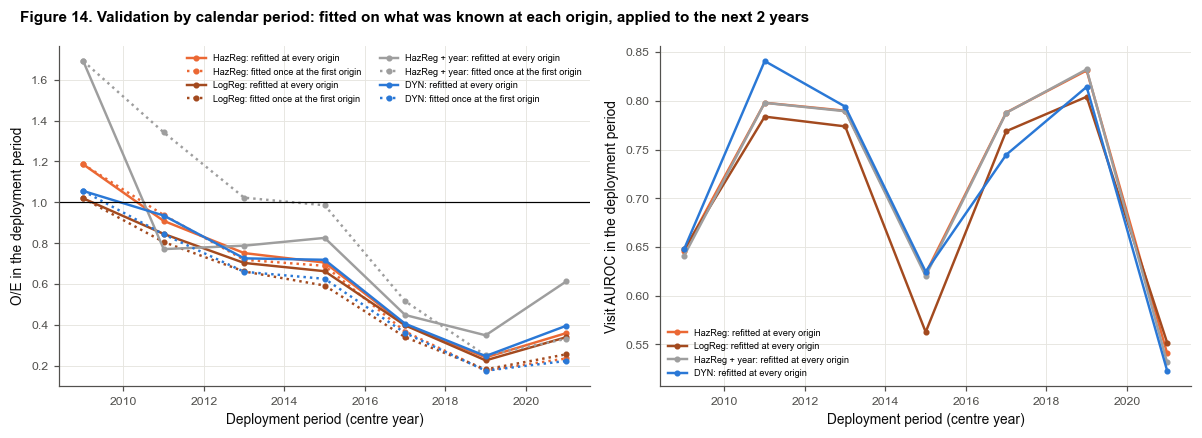

Visit AUROC: pooled (95 % CI) Visit AUROC: 95 % prediction interval  Visit AUROC: tau O/E: pooled (95 % CI) O/E: 95 % prediction interval  O/E: tau
Model         Strategy                                                                                                                                                                           
HazReg        Refitted at every origin               0.722 (0.647 to 0.786)                        0.570 to 0.836             0.192   0.69 (0.48 to 0.99)                  0.26 to 1.81     0.329
              Fitted once at the first origin        0.706 (0.627 to 0.774)                        0.517 to 0.843             0.256   0.61 (0.40 to 0.95)                  0.17 to 2.23     0.451
LogReg        Refitted at every origin               0.700 (0.618 to 0.772)                        0.489 to 0.851             0.291   0.65 (0.46 to 0.91)                  0.28 to 1.51     0.280
              Fitted once at the first origin        0.689 (0.609 to 0.758)                        0.473 to 0.845             0.302   0.57 (0.38 to 0.85)                  0.19 to 1.73     0.381
HazReg + year Refitted at every origin               0.720 (0.643 to 0.786)                        0.557 to 0.841             0.211   0.78 (0.53 to 1.15)                  0.27 to 2.26     0.365
              Fitted once at the first origin        0.704 (0.624 to 0.772)                        0.508 to 0.845             0.268   0.87 (0.56 to 1.35)                  0.24 to 3.22     0.456
DYN           Refitted at every origin               0.731 (0.635 to 0.810)                        0.453 to 0.899             0.403   0.69 (0.49 to 0.96)                  0.30 to 1.59     0.277
              Fitted once at the first origin        0.706 (0.632 to 0.771)                        0.527 to 0.838             0.244   0.58 (0.38 to 0.87)                  0.18 to 1.86     0.405

Validation by calendar period (refitted at every origin, random-effects pooled over 7 two-year deployment periods):
HazReg AUROC 0.722 (0.647 to 0.786; prediction interval 0.570 to 0.836), O/E 0.69 (0.48 to 0.99; prediction interval
0.26 to 1.81); LogReg AUROC 0.700 (0.618 to 0.772; prediction interval 0.489 to 0.851), O/E 0.65 (0.46 to 0.91;
prediction interval 0.28 to 1.51); HazReg + year AUROC 0.720 (0.643 to 0.786; prediction interval 0.557 to 0.841), O/E
0.78 (0.53 to 1.15; prediction interval 0.27 to 2.26); DYN AUROC 0.731 (0.635 to 0.810; prediction interval 0.453 to
0.899), O/E 0.69 (0.49 to 0.96; prediction interval 0.30 to 1.59).


In [48]:
"""Fitting on what was known by a date (TRIPOD+AI 12c, 16, 20c): the single split and every calendar-period origin."""
TEMPORAL_CUT = pd.Timestamp("2012-01-01")
TEMPORAL_MODELS = [m for m in [L1_DEMO, L2_FIRST, REPORTED, OTHER, HZ_YR, SEQ_MAIN] if m in MODELS_RUN]
_cut = float((TEMPORAL_CUT - _d0).days)


def dev_arrays(cut_day):
    """Training targets truncated at cut_day: landmarks before it, follow-up seen up to it."""
    dev = _LAND_T < cut_day
    seen = T_ALL <= cut_day - _LAND_T
    y = np.where((C_ALL == 1) & seen & (T_ALL <= HORIZON_DAYS), 1.0,
                 np.where((np.minimum(T_ALL, cut_day - _LAND_T) > HORIZON_DAYS)
                          | ((C_ALL >= 2) & seen & (T_ALL <= HORIZON_DAYS)), 0.0, np.nan))
    y[np.minimum(cut_day - _LAND_T, _ADMIN) < HORIZON_DAYS] = np.nan     # potential follow-up < 24 months by then
    y[~dev] = np.nan
    return {"D1": (D_ONSET * (INT_END <= cut_day)).astype(np.float32),
            "D2": (D_COMP * (INT_END <= cut_day)).astype(np.float32),
            "DT": np.clip((np.minimum(INT_END, cut_day) - INT_START) / 365.25, 1e-6, None).astype(np.float32),
            "Y": y, "LAB": ~np.isnan(y), "USE": dev}


def fit_until(m, cut_day, seed_base=500):
    """Fit model m on what was known by cut_day; raw scores (log-hazards or logit) at EVERY landmark."""
    A = dev_arrays(cut_day)
    dev_p = np.unique(PID_ALL[A["USE"]])
    if is_reg(m):
        cfg = model_grid(m)[pd.Series(BEST_CFG[m]).value_counts().index[0]]
        frows = rows_of(dev_p)
        prep_rows = frows[A["USE"][frows] & (A["LAB"][frows] if parse_model(m)["target"] == "BIN" else True)]
        return fit_reg(m, cfg, prep_rows, frows, np.arange(N_LAND), arrs=A)[0]
    d_ = parse_model(m)
    st_, ln_ = grid_window(d_["lookback"])
    VX = GridPrep(grid_cols_of(m)).fit(np.flatnonzero(A["USE"])).transform(GRID_RAW)
    res = Parallel(n_jobs=SEQ_N_JOBS, backend="loky")(
        delayed(fit_grid)(SEQ_CFG, VX, st_, ln_, dev_p, SEED + seed_base + 31 * s, ALL_PIDS, d_["hazard"], False,
                          None, False, A) for s in range(SEQ_SEEDS_FINAL))
    z = np.zeros((N_LAND, 2)); cnt = np.zeros(N_LAND)
    for rows_, zz in res:
        z[rows_] += zz; cnt[rows_] += 1
    return z / np.maximum(cnt, 1)[:, None]


DEV = _LAND_T < _cut
VAL = ~DEV
A_DEV = dev_arrays(_cut)
dev_p, val_p = np.unique(PID_ALL[DEV]), np.unique(PID_ALL[VAL])
print(f"Development: {int(DEV.sum()):,} landmarks, {len(dev_p)} patients, {int(A_DEV['D1'][DEV].sum())} onsets seen "
      f"before {TEMPORAL_CUT.date()} | evaluation: {int(VAL.sum()):,} landmarks, {len(val_p)} patients, "
      f"{int(D_ONSET[VAL].sum())} onsets | in both periods: {len(np.intersect1d(dev_p, val_p))} patients")


def _smd(a, b):
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    sd = np.sqrt((np.var(a) + np.var(b)) / 2)
    return (np.mean(a) - np.mean(b)) / sd if sd > 0 else np.nan


# the development vs evaluation case mix (item 20c): the covariate shift
_cmp_vars = ["age_at_record", "SLEDAI2_I", "score_n", "STERAVER_0", "AM_CLASS", "IS_CLASS", "FATIGUE", "FIBROMYALGIA",
             "SMOKER", "EDU_HIGHER", "VISIT_RATE_1Y", "YRS_IN_CLINIC"]
DEV_VS_VAL = pd.DataFrame({"Development (mean)": LAND_X.loc[DEV, _cmp_vars].astype(float).mean(),
                           "Evaluation (mean)": LAND_X.loc[VAL, _cmp_vars].astype(float).mean(),
                           "SMD": [_smd(LAND_X.loc[VAL, c].astype(float).values, LAND_X.loc[DEV, c].astype(float).values)
                                   for c in _cmp_vars]})
DEV_VS_VAL.index = [DISPLAY_NAMES.get(c, c) for c in DEV_VS_VAL.index]
DEV_VS_VAL.loc[f"{H}-month onset rate (resolved landmarks)"] = [np.nanmean(Y_ALL[DEV]), np.nanmean(Y_ALL[VAL]), np.nan]
display(DEV_VS_VAL.round(3))

TEMPORAL_PATH = f"temporal_state_{TAG}{'_smoke' if SMOKE else ''}.pkl"
TEMP = _load(TEMPORAL_PATH, {})
for m in TEMPORAL_MODELS:
    if m in TEMP:
        continue
    t0 = time.time()
    TEMP[m] = fit_until(m, _cut)
    _save(TEMP, TEMPORAL_PATH)
    print(f"  {short_label(m)} fitted on the development period ({(time.time() - t0) / 60:.1f} min)")

TEMP_Z = {m: np.where(VAL, raw_logit(np.nan_to_num(TEMP[m]), H), np.nan) for m in TEMPORAL_MODELS}
_rows_h, _y_h, _w_h = IPCW_H[H]
_vr = VAL[_rows_h]
_rows_v, _y_v, _w_v = _rows_h[_vr], _y_h[_vr], _w_h[_vr]
_Wv = _BOTH[:, ROW_PIDX[_rows_v]] * _w_v[None, :]
_dtm = TM["main"]
_ff = lambda a: fmt(a[0], *np.nanpercentile(a[1:], [2.5, 97.5])) if len(a) > 1 else f"{a[0]:.3f}"
_vlab = VAL & LABELLED
_pro = float((pd.Timestamp("2016-01-01") - _d0).days)
PRO_SPLIT = pd.Timestamp("2016-01-01")
TREC_FOLDS, TREC_REPEATS = 5, (3 if SMOKE else 20)
RECAL_KINDS = {"raw": "No recalibration", "intercept": "Intercept only", "logistic": "Logistic (intercept + slope)"}


def _fit_recal(z, y, kind):
    """(a, b) of the recalibrated logit a + b * z, fitted on complete-case labels y."""
    if kind == "raw":
        return 0.0, 1.0
    if kind == "intercept":
        return brentq(lambda a: _expit(a + z).mean() - y.mean(), -20, 20), 1.0
    rc = Recalibrator().fit(z, y)
    return rc.a, rc.b


def recal_crossfit(z, kind):
    """Cross-fitted recalibration within the evaluation period: logits over every landmark (NaN outside it)."""
    acc, cnt = np.zeros(N_LAND), np.zeros(N_LAND)
    for rep in range(TREC_REPEATS):
        for tr_p, te_p in patient_folds(val_p, TREC_FOLDS, SEED + 77 + 101 * rep):
            k = np.zeros(N_LAND, bool); k[rows_of(tr_p)] = True; k &= _vlab
            a, b = _fit_recal(z[k], Y_ALL[k], kind)
            te = rows_of(te_p); te = te[VAL[te]]
            acc[te] += a + b * z[te]; cnt[te] += 1
    return np.where(cnt > 0, acc / np.maximum(cnt, 1), np.nan)


def recal_prospective(z, kind):
    """Recalibration fitted on 2012-2015 landmarks, applied to the landmarks from 2016."""
    k = _vlab & (_LAND_T < _pro)
    a, b = _fit_recal(z[k], Y_ALL[k], kind)
    return np.where(VAL & (_LAND_T >= _pro), a + b * z, np.nan)


def eval_set(sub):
    """Rows, IPCW labels / weights and time-matched pairs restricted to the landmarks in `sub` (entities wholly in it);
    returns (metrics function, data)."""
    vr = sub[_rows_h]
    rows_, y_, w_ = _rows_h[vr], _y_h[vr], _w_h[vr]
    W_ = _BOTH[:, ROW_PIDX[rows_]] * w_[None, :]
    ent = np.asarray(_dtm["mat"] @ (~sub).astype(float)).ravel() == 0
    pm = ent[_dtm["pc"]] & ent[_dtm["pk"]]
    den = _pair_sum_fast(_BOTH, sparse.coo_matrix((np.ones(pm.sum()), (_dtm["ppc"][pm], _dtm["ppk"][pm])),
                                                  shape=(P_, P_)).toarray())

    def metrics(z):
        zv = z[rows_]
        out = {"Visit AUROC": wauc(y_, zv, W_), "O/E": (W_ @ y_) / (W_ @ _expit(zv))}
        sl, ic = wcalibration(y_, zv, w_)
        out["Calibration slope"], out["Calibration intercept"] = np.array([sl]), np.array([ic])
        s = np.asarray(_dtm["mat"] @ np.nan_to_num(z)).ravel()
        a, b = s[_dtm["pc"][pm]], s[_dtm["pk"][pm]]
        K = sparse.coo_matrix(((a > b) + 0.5 * (a == b), (_dtm["ppc"][pm], _dtm["ppk"][pm])), shape=(P_, P_)).toarray()
        out["Time-matched patient AUROC"] = _pair_sum_fast(_BOTH, K) / den
        return out
    return metrics, {"rows": rows_, "y": y_, "w": w_, "W": W_, "n_onsets": len(np.unique(_dtm["pc"][pm])),
                     "n_pairs": int(pm.sum())}


def tier_rows(z, D, label):
    p_ = _expit(z[D["rows"]])
    y1 = (D["y"] == 1).astype(np.float32)
    out = []
    for lo, hi, name in RISK_TIERS:
        inn = ((p_ >= lo) & (p_ < hi)).astype(np.float32)
        out.append({**label, "Tier": name, "Share of visits": f"{(D['w'] @ inn) / D['w'].sum():.1%}",
                    "Mean predicted": f"{p_[inn > 0].mean():.3f}" if inn.any() else "-",
                    "Observed (IPCW)": _ff(_ratio(D["W"] @ (y1 * inn), D["W"] @ inn)),
                    "Share of onsets": _ff(_ratio(D["W"] @ (y1 * inn), D["W"] @ y1))})
    return out


def cal_panel(ax, z, D, m, title, letter=None):
    """Decile calibration (observed IPCW risk with 95 % CI) and the logistic calibration line."""
    rows_, y_, w_ = D["rows"], D["y"], D["w"]
    p_ = _expit(z[rows_])
    Wb = _BOTH[:, ROW_PIDX[rows_]]
    cuts = np.quantile(p_, np.linspace(0, 1, CAL_DECILES + 1))
    b_ = np.clip(np.searchsorted(cuts, p_, side="right") - 1, 0, CAL_DECILES - 1)
    oh = np.eye(CAL_DECILES, dtype=np.float32)[b_]
    obs = (Wb @ (oh * (w_ * y_)[:, None])) / (Wb @ (oh * w_[:, None]))
    pr = (oh * (w_ * p_)[:, None]).sum(0) / (oh * w_[:, None]).sum(0)
    lo, hi = np.nanpercentile(obs[1:], [2.5, 97.5], 0)
    top = max(float(np.percentile(p_, 97.5)), pr[-1], float(np.nanmax(hi))) * 1.08
    lr_ = LogisticRegression(C=1e6, max_iter=1000).fit(_logit(p_)[:, None], y_, sample_weight=w_)
    g_ = np.linspace(max(p_.min(), 1e-4), top, 100)
    ax.plot([0, top], [0, top], ":", color=INK_2, lw=1)
    ax.plot(g_, _expit(lr_.intercept_[0] + lr_.coef_[0, 0] * _logit(g_)), "--", color=model_color(m), lw=1.4)
    ax.errorbar(pr, obs[0], yerr=[np.clip(obs[0] - lo, 0, None), np.clip(hi - obs[0], 0, None)], fmt="o",
                color=model_color(m), ms=5, mec="white", mew=0.8, capsize=2.5)
    oe = (D["W"] @ y_) / (D["W"] @ p_)
    sl = wcalibration(y_, z[rows_], w_)[0]
    ax.text(0.97, 0.03, f"Slope {sl:.2f}\nO/E {_ff(oe)}", transform=ax.transAxes, ha="right", va="bottom",
            fontsize=7, bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#d9d8d3", lw=0.6))
    ax.set_xlim(0, top); ax.set_ylim(0, top); ax.set_title(title, fontsize=9)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{100 * t:.0f}%"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{100 * t:.0f}%"))
    if letter:
        panel_label(ax, letter)




"""Forward-chaining validation by calendar period."""
RO_ORIGINS = [2010, 2016] if SMOKE else list(range(2008, 2021, 2))
RO_MODELS = [m for m in [REPORTED, OTHER, HZ_YR, SEQ_MAIN] if m in MODELS_RUN]
for m in RO_MODELS:
    for t in RO_ORIGINS:
        key = (m, "ro", t)
        if key in TEMP:
            continue
        t0 = time.time()
        TEMP[key] = fit_until(m, _day(t), seed_base=700 + t)
        _save(TEMP, TEMPORAL_PATH)
        print(f"  {short_label(m)} fitted on what was known by {t} ({(time.time() - t0) / 60:.1f} min)", flush=True)


def window_metrics(z, lo_y, hi_y):
    k = (_LAND_T[_rows_h] >= _day(lo_y)) & (_LAND_T[_rows_h] < _day(hi_y)) & ~np.isnan(z[_rows_h])
    rows_, y_, w_ = _rows_h[k], _y_h[k], _w_h[k]
    Wr = _BOTH[:, ROW_PIDX[rows_]] * w_[None, :]
    zz = z[rows_]
    return {"auroc": wauc(y_, zz, Wr), "oe": (Wr @ y_) / (Wr @ _expit(zz)), "slope": wcalibration(y_, zz, w_)[0],
            "onsets": int(y_.sum())}


RO_STRATS = {"refit": "Refitted at every origin", "static": "Fitted once at the first origin"}
rows, RO = [], {}
for m in RO_MODELS:
    first = TEMP[(m, "ro", RO_ORIGINS[0])]
    z_static = raw_logit(np.nan_to_num(first), H)
    for t in RO_ORIGINS:
        eta_t = TEMP[(m, "ro", t)]
        zs = {"refit": raw_logit(np.nan_to_num(eta_t), H), "static": z_static}
        for s_, z_ in zs.items():
            mt = window_metrics(z_, t, t + 2)
            RO[(m, s_, t)] = mt
            rows.append({"Model": short_label(m), "Strategy": RO_STRATS[s_], "Deployment": f"{t}-{t + 1}",
                         "Onset landmarks": mt["onsets"], "O/E": _ff(mt["oe"]), "Visit AUROC": _ff(mt["auroc"]),
                         "Calibration slope": f"{mt['slope']:.2f}"})
ROLLING_ORIGIN = pd.DataFrame(rows)
display(ROLLING_ORIGIN.pivot_table(index=["Model", "Strategy"], columns="Deployment", values="O/E", aggfunc="first"))
display(ROLLING_ORIGIN.pivot_table(index=["Model", "Strategy"], columns="Deployment", values="Visit AUROC",
                                   aggfunc="first"))
ROLLING_ORIGIN.to_csv(f"aim4_by_period_{TAG}.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
_ls = {"refit": "-", "static": ":"}
for m in RO_MODELS:
    for s_ in RO_STRATS:
        x = np.array(RO_ORIGINS) + 1
        axes[0].plot(x, [RO[(m, s_, t)]["oe"][0] for t in RO_ORIGINS], _ls[s_], marker="o", ms=3,
                     color=model_color(m), label=f"{short_label(m)}: {RO_STRATS[s_].lower()}")
        if s_ == "refit":
            axes[1].plot(x, [RO[(m, s_, t)]["auroc"][0] for t in RO_ORIGINS], _ls[s_], marker="o", ms=3,
                         color=model_color(m), label=f"{short_label(m)}: {RO_STRATS[s_].lower()}")
axes[0].axhline(1, color="k", lw=0.8); axes[0].set_ylabel("O/E in the deployment period")
axes[1].set_ylabel("Visit AUROC in the deployment period")
for ax in axes:
    ax.set_xlabel("Deployment period (centre year)")
axes[0].legend(fontsize=6, ncol=2); axes[1].legend(fontsize=6)
fig.suptitle("Figure 14. Validation by calendar period: fitted on what was known at each origin, applied to the next 2 years",
             x=0.02, ha="left", fontsize=10, fontweight="bold")
plt.tight_layout(); save_fig("fig14_rolling_origin")


def re_pool(est, se):
    """DerSimonian-Laird random-effects pooled estimate, 95 % CI, tau and 95 % prediction interval."""
    est, se = np.asarray(est, float), np.asarray(se, float)
    k = np.isfinite(est) & np.isfinite(se) & (se > 0)
    est, se = est[k], se[k]
    w = 1 / se ** 2
    mu_f = np.sum(w * est) / w.sum()
    q = np.sum(w * (est - mu_f) ** 2)
    tau2 = max(0.0, (q - (len(est) - 1)) / (w.sum() - np.sum(w ** 2) / w.sum()))
    ws = 1 / (se ** 2 + tau2)
    mu = np.sum(ws * est) / ws.sum()
    se_mu = np.sqrt(1 / ws.sum())
    t_ = stats.t.ppf(0.975, max(len(est) - 2, 1))
    half = t_ * np.sqrt(tau2 + se_mu ** 2)
    return mu, mu - 1.96 * se_mu, mu + 1.96 * se_mu, np.sqrt(tau2), mu - half, mu + half


_tr = {"auroc": (_logit, _expit), "oe": (np.log, np.exp)}
rows, RO_POOL = [], {}
for m in RO_MODELS:
    for s_ in RO_STRATS:
        row = {"Model": short_label(m), "Strategy": RO_STRATS[s_]}
        for k_, (f_, g_) in _tr.items():
            arr = [f_(np.clip(RO[(m, s_, t)][k_], 1e-6, None if k_ == "oe" else 1 - 1e-6)) for t in RO_ORIGINS]
            mu, lo, hi, tau, plo, phi = re_pool([a_[0] for a_ in arr], [np.nanstd(a_[1:]) for a_ in arr])
            RO_POOL[(m, s_, k_)] = (g_(mu), g_(lo), g_(hi), tau, g_(plo), g_(phi))
            nm = "Visit AUROC" if k_ == "auroc" else "O/E"
            row[f"{nm}: pooled (95 % CI)"] = fmt(g_(mu), g_(lo), g_(hi), nd=3 if k_ == "auroc" else 2)
            row[f"{nm}: 95 % prediction interval"] = f"{g_(plo):.{3 if k_ == 'auroc' else 2}f} to {g_(phi):.{3 if k_ == 'auroc' else 2}f}"
            row[f"{nm}: tau"] = round(tau, 3)
        rows.append(row)
RO_POOLED = pd.DataFrame(rows).set_index(["Model", "Strategy"])
display(RO_POOLED)
RO_POOLED.to_csv(f"aim4_by_period_pooled_{TAG}.csv")
_p = lambda m, k_: RO_POOL[(m, "refit", k_)]
RO_SUMMARY = ("Validation by calendar period (refitted at every origin, random-effects pooled over "
              f"{len(RO_ORIGINS)} two-year deployment periods): " + "; ".join(
                  f"{short_label(m)} AUROC {_p(m, 'auroc')[0]:.3f} ({_p(m, 'auroc')[1]:.3f} to {_p(m, 'auroc')[2]:.3f}; "
                  f"prediction interval {_p(m, 'auroc')[4]:.3f} to {_p(m, 'auroc')[5]:.3f}), O/E {_p(m, 'oe')[0]:.2f} "
                  f"({_p(m, 'oe')[1]:.2f} to {_p(m, 'oe')[2]:.2f}; prediction interval {_p(m, 'oe')[4]:.2f} to "
                  f"{_p(m, 'oe')[5]:.2f})" for m in RO_MODELS) + ".")
print(textwrap.fill(RO_SUMMARY, 118))

## 18.3 A single temporal split: develop before 2012, evaluate from 2012

* **Development**: landmarks before 1 January 2012, with every follow-up **truncated at that date** (onsets,
  competing exits and time at risk after it are not seen; the 24-month label is resolved only if known by then).
* **Evaluation**: landmarks from 1 January 2012, outcomes as in the main analysis. Patients seen in both periods
  contribute to both, with no information from after 2012 in development.
* **Models**: the ladder, HazReg, LogReg, HazReg + year and DYN, each with its most-chosen CV penalty (DYN: its fixed
  configuration, 5 seeds). Every development model also scores the development landmarks (needed by the rolling
  update of 18.4, which looks back across 2012).
* **No recalibration**: the risks are the models' own, so O/E and the calibration intercept show how the level
  transports to later years. The CV estimates on the same landmarks (recalibrated) are shown alongside.
* **H5a**: the ranking transports (HazReg − L1, temporal visit AUROC, lower bound > 0). **H5b**: the level
  transports without an update (temporal O/E, 95 % CI includes 1).

In [49]:
"""The single split: tables and contrasts."""
EVAL_ALL, D_ALL = eval_set(VAL)
rows, TEMP_MET = [], {}
for m in TEMPORAL_MODELS:
    mt = EVAL_ALL(TEMP_Z[m])
    cv = [EVAL_ALL(zpred(m, r)) for r in REPEATS]
    TEMP_MET[m] = mt
    row = {"Model": short_label(m)}
    for k_ in mt:
        row[f"{k_}: temporal"] = _ff(mt[k_])
        row[f"{k_}: CV, same landmarks"] = _ff(np.mean([c_[k_] for c_ in cv], 0))
    rows.append(row)
TEMPORAL = pd.DataFrame(rows).set_index("Model").T
print(f"Evaluation: {len(D_ALL['rows']):,} landmarks with a known {H}-month status ({int(D_ALL['y'].sum())} onset "
      f"landmarks); time-matched: {D_ALL['n_onsets']} onsets, {D_ALL['n_pairs']:,} pairs")
display(TEMPORAL)
TEMPORAL.to_csv(f"tripod_temporal_{TAG}.csv")
rows = []
for a_, b_ in [(REPORTED, L1_DEMO), (REPORTED, L2_FIRST), (OTHER, REPORTED), (HZ_YR, REPORTED), (SEQ_MAIN, REPORTED)]:
    if a_ in TEMP_MET and b_ in TEMP_MET:
        for k_ in ["Visit AUROC", "Time-matched patient AUROC"]:
            dlt = TEMP_MET[a_][k_] - TEMP_MET[b_][k_]
            lo, hi = np.nanpercentile(dlt[1:], [2.5, 97.5])
            rows.append({"Comparison": f"{short_label(a_)} - {short_label(b_)}", "Metric": k_, "Difference (95% CI)":
                         fmt(dlt[0], lo, hi), "Verdict": verdict_superiority(lo, hi, EQUIV_MARGIN)})
TEMPORAL_CMP = pd.DataFrame(rows).set_index(["Comparison", "Metric"])
display(TEMPORAL_CMP)
TEMPORAL_CMP.to_csv(f"tripod_temporal_contrasts_{TAG}.csv")
rows = []
for m in TEMPORAL_MODELS:
    rows += tier_rows(TEMP_Z[m], D_ALL, {"Model": short_label(m)})
TEMPORAL_TIERS = pd.DataFrame(rows).set_index(["Model", "Tier"])
display(TEMPORAL_TIERS.loc[[short_label(m) for m in [REPORTED, SEQ_MAIN] if m in TEMP_MET]])
TEMPORAL_TIERS.to_csv(f"tripod_temporal_tiers_{TAG}.csv")
_t = TEMP_MET[REPORTED]
TEMPORAL_SUMMARY = (f"Temporal hold-out (develop < {TEMPORAL_CUT.year}, evaluate >= {TEMPORAL_CUT.year}), "
                    f"{short_label(REPORTED)}: visit AUROC {_ff(_t['Visit AUROC'])}, time-matched patient AUROC "
                    f"{_ff(_t['Time-matched patient AUROC'])}, O/E {_ff(_t['O/E'])}, calibration slope "
                    f"{_t['Calibration slope'][0]:.2f}. " + "; ".join(
                        f"{i[0]} {i[1]}: {r_['Difference (95% CI)']} ({r_['Verdict']})"
                        for i, r_ in TEMPORAL_CMP.iterrows()) + ".")
print(textwrap.fill(TEMPORAL_SUMMARY, 118))
_dl = TEMP_MET[REPORTED]["Visit AUROC"] - TEMP_MET[L1_DEMO]["Visit AUROC"] if L1_DEMO in TEMP_MET else np.full(2, np.nan)
hyp("H5a", f"{short_label(REPORTED)} - L1, temporal visit AUROC (the ranking transports)",
    (_dl[0], *np.nanpercentile(_dl[1:], [2.5, 97.5])), "lower bound > 0", np.nanpercentile(_dl[1:], 2.5) > 0)
hyp("H5b", f"{short_label(REPORTED)}: temporal O/E without any update (the level transports)",
    (_t["O/E"][0], *np.nanpercentile(_t["O/E"][1:], [2.5, 97.5])), "95 % CI includes 1",
    np.nanpercentile(_t["O/E"][1:], 2.5) <= 1 <= np.nanpercentile(_t["O/E"][1:], 97.5))

Evaluation: 6,525 landmarks with a known 24-month status (143 onset landmarks); time-matched: 38 onsets, 12,793 pairs


Model,L1 Demographics,L2 First visit,HazReg,LogReg,HazReg + year,DYN
Visit AUROC: temporal,0.613 (0.496 to 0.728),0.648 (0.525 to 0.766),0.719 (0.631 to 0.809),0.674 (0.581 to 0.765),0.720 (0.630 to 0.811),0.691 (0.592 to 0.782)
"Visit AUROC: CV, same landmarks",0.560 (0.478 to 0.641),0.641 (0.526 to 0.750),0.715 (0.622 to 0.812),0.684 (0.580 to 0.790),0.715 (0.618 to 0.809),0.698 (0.593 to 0.802)
O/E: temporal,0.372 (0.251 to 0.502),0.439 (0.298 to 0.604),0.505 (0.342 to 0.686),0.472 (0.319 to 0.644),0.531 (0.360 to 0.721),0.481 (0.323 to 0.657)
"O/E: CV, same landmarks",0.550 (0.374 to 0.744),0.593 (0.397 to 0.813),0.668 (0.451 to 0.912),0.683 (0.464 to 0.937),0.750 (0.508 to 1.023),0.701 (0.475 to 0.953)
Calibration slope: temporal,1.217,0.711,0.793,1.026,0.798,0.969
"Calibration slope: CV, same landmarks",1.003,1.199,1.216,0.915,1.222,1.154
Calibration intercept: temporal,-1.028,-0.874,-0.745,-0.786,-0.690,-0.774
"Calibration intercept: CV, same landmarks",-0.615,-0.540,-0.421,-0.400,-0.300,-0.371
Time-matched patient AUROC: temporal,0.618 (0.509 to 0.726),0.643 (0.530 to 0.757),0.751 (0.671 to 0.830),0.686 (0.599 to 0.775),0.751 (0.670 to 0.831),0.705 (0.613 to 0.792)
"Time-matched patient AUROC: CV, same landmarks",0.556 (0.471 to 0.641),0.646 (0.540 to 0.753),0.752 (0.670 to 0.832),0.710 (0.620 to 0.798),0.744 (0.660 to 0.825),0.715 (0.623 to 0.803)


Difference (95% CI)       Verdict
Comparison               Metric                                                             
HazReg - L1 Demographics Visit AUROC                   0.106 (-0.026 to 0.241)  inconclusive
                         Time-matched patient AUROC     0.133 (0.011 to 0.264)      superior
HazReg - L2 First visit  Visit AUROC                   0.071 (-0.020 to 0.162)  inconclusive
                         Time-matched patient AUROC     0.108 (0.025 to 0.194)      superior
LogReg - HazReg          Visit AUROC                 -0.045 (-0.074 to -0.017)      inferior
                         Time-matched patient AUROC  -0.065 (-0.109 to -0.025)      inferior
HazReg + year - HazReg   Visit AUROC                   0.001 (-0.001 to 0.003)    equivalent
                         Time-matched patient AUROC   -0.000 (-0.003 to 0.003)    equivalent
DYN - HazReg             Visit AUROC                  -0.028 (-0.065 to 0.005)  inconclusive
                         Time-matched patient AUROC   -0.046 (-0.106 to 0.001)  inconclusive

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1409: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


Share of visits Mean predicted         Observed (IPCW)         Share of onsets
Model  Tier                                                                                  
HazReg < 2 %             39.2%          0.014  0.010 (0.003 to 0.018)  0.190 (0.072 to 0.301)
       2-4 %             31.8%          0.028  0.010 (0.005 to 0.016)  0.155 (0.085 to 0.233)
       4-10 %            21.5%          0.060  0.039 (0.023 to 0.059)  0.412 (0.294 to 0.544)
       >= 10 %            7.5%          0.174  0.065 (0.033 to 0.105)  0.243 (0.153 to 0.350)
DYN    < 2 %             24.1%          0.016  0.012 (0.003 to 0.023)  0.141 (0.046 to 0.258)
       2-4 %             41.8%          0.028  0.012 (0.006 to 0.019)  0.239 (0.139 to 0.344)
       4-10 %            27.4%          0.060  0.026 (0.016 to 0.040)  0.356 (0.255 to 0.476)
       >= 10 %            6.7%          0.151  0.080 (0.041 to 0.126)  0.263 (0.156 to 0.381)

Temporal hold-out (develop < 2012, evaluate >= 2012), HazReg: visit AUROC 0.719 (0.631 to 0.809), time-matched patient
AUROC 0.751 (0.671 to 0.830), O/E 0.505 (0.342 to 0.686), calibration slope 0.79. HazReg - L1 Demographics Visit
AUROC: 0.106 (-0.026 to 0.241) (inconclusive); HazReg - L1 Demographics Time-matched patient AUROC: 0.133 (0.011 to
0.264) (superior); HazReg - L2 First visit Visit AUROC: 0.071 (-0.020 to 0.162) (inconclusive); HazReg - L2 First
visit Time-matched patient AUROC: 0.108 (0.025 to 0.194) (superior); LogReg - HazReg Visit AUROC: -0.045 (-0.074 to
-0.017) (inferior); LogReg - HazReg Time-matched patient AUROC: -0.065 (-0.109 to -0.025) (inferior); HazReg + year -
HazReg Visit AUROC: 0.001 (-0.001 to 0.003) (equivalent); HazReg + year - HazReg Time-matched patient AUROC: -0.000
(-0.003 to 0.003) (equivalent); DYN - HazReg Visit AUROC: -0.028 (-0.065 to 0.005) (inconclusive); DYN - HazReg Time-
matched patient AUROC: -0.046 (-0.106 to 0.001) (inconclusive).


## 18.4 Updating the level

**One-time recalibration** (Steyerberg's updating hierarchy), using evaluation-period patients only: *cross-fitted*
(5 patient folds of the evaluation period, 20 repetitions: the best a single local recalibration can do, but it uses
outcomes from the same period, so it is not prospective) and *prospective* (fitted on the 2012-2015 landmarks,
applied from 2016; **H5c**: O/E 95 % CI includes 1). Intercept only, or intercept and slope.

**A rolling observed / expected update on the hazard scale** (prospective by construction), as an example of a
scheduled update: for a landmark on date *t*, the observed and expected onsets (and competing exits) in the 3 years
ending 1 year before *t*, from partial follow-up; the ratio of each cause, shrunk towards 1 with 5 pseudo-events,
multiplies that cause's hazard. For LogReg the 24-month risk *p* is read as a constant onset hazard −log(1 − *p*)/2.
Every update changes the level only: the ranking within a date is unchanged.

Visit AUROC                     O/E Calibration slope Calibration intercept Time-matched patient AUROC
Model         Update                                                                                                                                                               
HazReg        None (development model as is)                      0.719 (0.631 to 0.809)  0.505 (0.342 to 0.686)             0.793                -0.745     0.751 (0.671 to 0.830)
              One-time, cross-fitted: intercept only              0.714 (0.625 to 0.806)  0.987 (0.670 to 1.351)             0.770                -0.014     0.748 (0.667 to 0.827)
              One-time, cross-fitted: logistic (intercept + s...  0.707 (0.616 to 0.804)  0.987 (0.671 to 1.348)             0.887                -0.013     0.741 (0.658 to 0.824)
              One-time, prospective (2012-15): intercept [eva...  0.737 (0.594 to 0.858)  0.438 (0.242 to 0.677)             0.881                -0.892     0.782 (0.673 to 0.883)
              Rolling O/E update, rolling W=3                     0.714 (0.613 to 0.806)  0.592 (0.403 to 0.809)             0.808                -0.569     0.749 (0.667 to 0.825)
LogReg        None (development model as is)                      0.674 (0.581 to 0.765)  0.472 (0.319 to 0.644)             1.026                -0.786     0.686 (0.599 to 0.775)
              One-time, cross-fitted: intercept only              0.667 (0.574 to 0.760)  0.988 (0.667 to 1.349)             0.942                -0.013     0.683 (0.596 to 0.773)
              One-time, cross-fitted: logistic (intercept + s...  0.661 (0.565 to 0.757)  0.988 (0.664 to 1.353)             0.828                -0.013     0.677 (0.585 to 0.770)
              One-time, prospective (2012-15): intercept [eva...  0.671 (0.529 to 0.796)  0.459 (0.251 to 0.711)             1.052                -0.805     0.731 (0.601 to 0.845)
              Rolling O/E update, rolling W=3                     0.666 (0.560 to 0.759)  0.574 (0.390 to 0.783)             1.009                -0.580     0.676 (0.587 to 0.767)
HazReg + year None (development model as is)                      0.720 (0.630 to 0.811)  0.531 (0.360 to 0.721)             0.798                -0.690     0.751 (0.670 to 0.831)
              One-time, cross-fitted: intercept only              0.715 (0.624 to 0.808)  0.987 (0.670 to 1.353)             0.774                -0.014     0.749 (0.668 to 0.828)
              One-time, cross-fitted: logistic (intercept + s...  0.708 (0.616 to 0.805)  0.988 (0.672 to 1.347)             0.888                -0.013     0.742 (0.659 to 0.826)
              One-time, prospective (2012-15): intercept [eva...  0.739 (0.595 to 0.859)  0.439 (0.243 to 0.679)             0.888                -0.888     0.784 (0.674 to 0.883)
              Rolling O/E update, rolling W=3                     0.714 (0.613 to 0.807)  0.605 (0.412 to 0.827)             0.811                -0.546     0.748 (0.665 to 0.827)
DYN           None (development model as is)                      0.691 (0.592 to 0.782)  0.481 (0.323 to 0.657)             0.969                -0.774     0.705 (0.613 to 0.792)
              One-time, cross-fitted: intercept only              0.685 (0.586 to 0.776)  0.988 (0.662 to 1.352)             0.941                -0.012     0.701 (0.610 to 0.787)
              One-time, cross-fitted: logistic (intercept + s...  0.678 (0.574 to 0.774)  0.991 (0.663 to 1.352)             0.852                -0.010     0.695 (0.600 to 0.783)
              One-time, prospective (2012-15): intercept [eva...  0.673 (0.520 to 0.808)  0.457 (0.248 to 0.699)             0.951                -0.815     0.685 (0.535 to 0.813)
              Rolling O/E update, rolling W=3                     0.685 (0.578 to 0.778)  0.559 (0.378 to 0.762)             0.958                -0.614     0.698 (0.606 to 0.787)

/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_49900/827566341.py:141: RuntimeWarning: invalid value encountered in divide
  out["Time-matched patient AUROC"] = _pair_sum_fast(_BOTH, K) / den
/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_49900/827566341.py:141: RuntimeWarning: invalid value encountered in divide
  out["Time-matched patient AUROC"] = _pair_sum_fast(_BOTH, K) / den
/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_49900/827566341.py:141: RuntimeWarning: invalid value encountered in divide
  out["Time-matched patient AUROC"] = _pair_sum_fast(_BOTH, K) / den
/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_49900/827566341.py:141: RuntimeWarning: invalid value encountered in divide
  out["Time-matched patient AUROC"] = _pair_sum_fast(_BOTH, K) / den
/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_49900/827566341.py:141: RuntimeWarning: invalid value encountered in divide
  out["Time-matched patient AUROC"] = _pair_sum_f

O/E 2012-15 Intercept 2012-15             O/E 2016-19 Intercept 2016-19               O/E 2020- Intercept 2020-
Model         Update                                                                                                                                                     
HazReg        None                             0.730 (0.426 to 1.071)             -0.34  0.289 (0.125 to 0.476)             -1.34  0.677 (0.181 to 1.350)           -0.43
              One-time cross-fitted intercept  1.435 (0.827 to 2.121)              0.39  0.563 (0.245 to 0.936)             -0.61  1.315 (0.356 to 2.647)            0.30
              Rolling O/E update, rolling W=3  0.703 (0.408 to 1.030)             -0.39  0.383 (0.167 to 0.634)             -1.03  1.305 (0.350 to 2.597)            0.29
LogReg        None                             0.665 (0.389 to 0.972)             -0.43  0.273 (0.119 to 0.454)             -1.35  0.680 (0.179 to 1.341)           -0.41
              One-time cross-fitted intercept  1.393 (0.814 to 2.037)              0.34  0.571 (0.250 to 0.953)             -0.57  1.416 (0.374 to 2.796)            0.36
              Rolling O/E update, rolling W=3  0.675 (0.395 to 0.985)             -0.41  0.371 (0.162 to 0.618)             -1.02  1.393 (0.365 to 2.752)            0.35
HazReg + year None                             0.766 (0.447 to 1.122)             -0.29  0.304 (0.132 to 0.502)             -1.29  0.713 (0.191 to 1.423)           -0.38
              One-time cross-fitted intercept  1.433 (0.827 to 2.116)              0.39  0.564 (0.245 to 0.936)             -0.61  1.321 (0.358 to 2.661)            0.30
              Rolling O/E update, rolling W=3  0.725 (0.422 to 1.063)             -0.35  0.387 (0.169 to 0.640)             -1.02  1.320 (0.354 to 2.628)            0.30
DYN           None                             0.680 (0.399 to 0.989)             -0.41  0.277 (0.121 to 0.460)             -1.34  0.700 (0.184 to 1.381)           -0.38
              One-time cross-fitted intercept  1.398 (0.817 to 2.033)              0.35  0.569 (0.250 to 0.945)             -0.58  1.431 (0.374 to 2.846)            0.38
              Rolling O/E update, rolling W=3  0.662 (0.389 to 0.960)             -0.44  0.359 (0.157 to 0.594)             -1.07  1.369 (0.359 to 2.689)            0.33

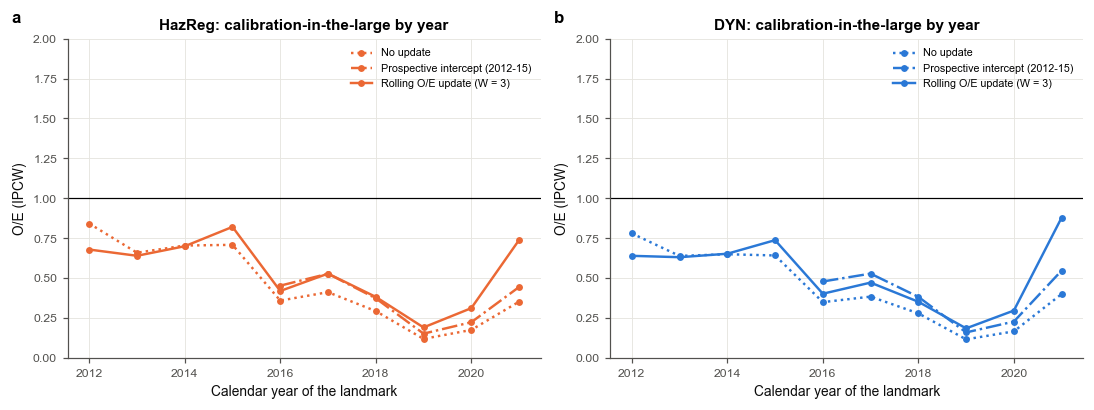

HazReg from 2012: O/E 0.505 (0.342 to 0.686) without an update; one-time cross-fitted intercept 0.987 (0.670 to 1.351)
(not prospective); prospective intercept (2012-15 -> 2016+) 0.438 (0.242 to 0.677); rolling hazard-scale update (W =
3) 0.592 (0.403 to 0.809). The ranking is unchanged by any of them.


In [50]:
"""One-time recalibration and the rolling hazard-scale update."""
ROLL_LAG_YEARS, ROLL_PRIOR = 1.0, 5.0
ROLL_VARIANTS = {"rolling W=3": (3, None)}
_MGRID = np.arange(_day(2000), INT_END[np.isfinite(INT_END)].max() + 31, 30.4375)    # monthly update dates


def hazards_of(eta):
    """(onset, competing) hazards per year; for a one-column logit, the onset hazard implied by the 24-month risk."""
    if eta.shape[1] == 2:
        return np.exp(np.clip(eta[:, 0], -30, 5)), np.exp(np.clip(eta[:, 1], -30, 5))
    p = np.clip(_expit(eta[:, 0]), 1e-9, 1 - 1e-9)
    return -np.log1p(-p) / (H / 12), None


def rolling_ratios(eta, W, half_life):
    """Shrunk observed / expected ratios of each cause on the monthly grid _MGRID."""
    l1, l2 = hazards_of(np.nan_to_num(eta))
    out = np.ones((len(_MGRID), 2))
    for g, gd in enumerate(_MGRID):
        hi = gd - ROLL_LAG_YEARS * 365.25
        lo = hi - W * 365.25 if W else -np.inf
        s, e = np.maximum(INT_START, lo), np.minimum(INT_END, hi)
        expo = np.clip(e - s, 0, None) / 365.25
        wt = 0.5 ** (np.clip(hi - (s + e) / 2, 0, None) / 365.25 / half_life) if half_life else 1.0
        ev = (INT_END > lo) & (INT_END <= hi)
        out[g, 0] = (np.sum(wt * D_ONSET * ev) + ROLL_PRIOR) / (np.sum(wt * l1 * expo) + ROLL_PRIOR)
        if l2 is not None:
            out[g, 1] = (np.sum(wt * D_COMP * ev) + ROLL_PRIOR) / (np.sum(wt * l2 * expo) + ROLL_PRIOR)
    return out


def rolling_update(eta, W, half_life):
    """24-month logits after the rolling update, at every landmark on or after the first grid date."""
    R = rolling_ratios(eta, W, half_life)
    g = np.clip(np.searchsorted(_MGRID, _LAND_T, side="right") - 1, 0, len(_MGRID) - 1)
    l1, l2 = hazards_of(np.nan_to_num(eta))
    if l2 is None:
        return _logit(-np.expm1(-R[g, 0] * l1 * H / 12))
    return raw_logit(np.column_stack([np.log(R[g, 0] * l1), np.log(R[g, 1] * l2)]), H)


TREC_Z = {}
for m in TEMPORAL_MODELS:
    for kind in RECAL_KINDS:
        TREC_Z[(m, "crossfit", kind)] = recal_crossfit(TEMP_Z[m], kind)
        TREC_Z[(m, "prospective", kind)] = recal_prospective(TEMP_Z[m], kind)
    for lab_, (W_, hl_) in ROLL_VARIANTS.items():
        TREC_Z[(m, "rolling", lab_)] = np.where(VAL, rolling_update(TEMP[m], W_, hl_), np.nan)
EVAL_LATE, D_LATE = eval_set(VAL & (_LAND_T >= _pro))
_STRATS = ([("crossfit", k_, f"One-time, cross-fitted: {v_.lower()}") for k_, v_ in RECAL_KINDS.items() if k_ != "raw"]
           + [("prospective", "intercept", "One-time, prospective (2012-15): intercept")]
           + [("rolling", k_, f"Rolling O/E update, {k_}") for k_ in ROLL_VARIANTS])
rows, TREC_MET = [], {}
for m in TEMPORAL_MODELS:
    TREC_MET[(m, "raw")] = EVAL_ALL(TEMP_Z[m])
    rows.append({"Model": short_label(m), "Update": "None (development model as is)",
                 **{k_: _ff(v_) for k_, v_ in TREC_MET[(m, "raw")].items()}})
    for design, kind, lab_ in _STRATS:
        ev = EVAL_LATE if design == "prospective" else EVAL_ALL
        mt = ev(TREC_Z[(m, design, kind)])
        TREC_MET[(m, design, kind)] = mt
        rows.append({"Model": short_label(m), "Update": lab_ + (" [evaluated from 2016]" if design == "prospective"
                                                                 else ""), **{k_: _ff(v_) for k_, v_ in mt.items()}})
TEMPORAL_RECAL = pd.DataFrame(rows).set_index(["Model", "Update"])
display(TEMPORAL_RECAL.loc[[short_label(m) for m in [REPORTED, OTHER, HZ_YR, SEQ_MAIN] if m in TEMP_MET]])
TEMPORAL_RECAL.to_csv(f"tripod_temporal_recalibrated_{TAG}.csv")
_pi = TREC_MET[(REPORTED, "prospective", "intercept")]
hyp("H5c", f"{short_label(REPORTED)}: O/E from 2016 after a one-time intercept update on 2012-2015",
    (_pi["O/E"][0], *np.nanpercentile(_pi["O/E"][1:], [2.5, 97.5])), "95 % CI includes 1",
    np.nanpercentile(_pi["O/E"][1:], 2.5) <= 1 <= np.nanpercentile(_pi["O/E"][1:], 97.5))

# O/E and the calibration intercept by era of the evaluation period
UPD_ERAS = [(2012, 2016, "2012-15"), (2016, 2020, "2016-19"), (2020, 2030, "2020-")]
_ev_era = {lab_: eval_set(VAL & (_LAND_T >= _day(a_)) & (_LAND_T < _day(b_)))[0] for a_, b_, lab_ in UPD_ERAS}
rows = []
for m in [x for x in [REPORTED, OTHER, HZ_YR, SEQ_MAIN] if x in TEMP_MET]:
    for lab_, z_ in [("None", TEMP_Z[m]), ("One-time cross-fitted intercept", TREC_Z[(m, "crossfit", "intercept")])] + \
            [(f"Rolling O/E update, {k_}", TREC_Z[(m, "rolling", k_)]) for k_ in ROLL_VARIANTS]:
        row = {"Model": short_label(m), "Update": lab_}
        for e_, ev_ in _ev_era.items():
            mt = ev_(z_)
            row[f"O/E {e_}"] = _ff(mt["O/E"])
            row[f"Intercept {e_}"] = f"{mt['Calibration intercept'][0]:.2f}"
        rows.append(row)
OE_BY_ERA = pd.DataFrame(rows).set_index(["Model", "Update"])
display(OE_BY_ERA)
OE_BY_ERA.to_csv(f"aim4_oe_by_era_{TAG}.csv")

# O/E by calendar year
_ly = np.floor(land["CAL_YEAR"].values[_rows_h]).astype(int)
_yrs_e = [y for y in range(TEMPORAL_CUT.year, int(DATA_END_DATE.year) + 1) if (VAL[_rows_h] & (_ly == y)).sum() > 50]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, m in zip(axes, [REPORTED, SEQ_MAIN]):
    if m not in TEMP_MET:
        continue
    for lab_, z_, ls in [("No update", TEMP_Z[m], ":"), ("Prospective intercept (2012-15)",
                                                          TREC_Z[(m, "prospective", "intercept")], "-."),
                         ("Rolling O/E update (W = 3)", TREC_Z[(m, "rolling", "rolling W=3")], "-")]:
        oe = []
        for y in _yrs_e:
            k = VAL[_rows_h] & (_ly == y) & ~np.isnan(z_[_rows_h])
            oe.append(np.sum(_w_h[k] * _y_h[k]) / np.sum(_w_h[k] * _expit(z_[_rows_h][k])) if k.sum() else np.nan)
        ax.plot(_yrs_e, oe, ls, marker="o", ms=3.5, color=model_color(m), label=lab_)
    ax.axhline(1, color="k", lw=0.8); ax.set_ylim(0, 2)
    ax.set_xlabel("Calendar year of the landmark"); ax.set_ylabel("O/E (IPCW)")
    ax.set_title(f"{short_label(m)}: calibration-in-the-large by year"); ax.legend(fontsize=7)
for a_, l_ in zip(axes, "ab"):
    panel_label(a_, l_)
plt.tight_layout(); save_fig("fig13_level_updating")
_r = {k_: TREC_MET[(REPORTED, "crossfit", k_)] for k_ in ["intercept", "logistic"]}
TEMPORAL_RECAL_SUMMARY = (
    f"{short_label(REPORTED)} from {TEMPORAL_CUT.year}: O/E {_ff(TREC_MET[(REPORTED, 'raw')]['O/E'])} without an "
    f"update; one-time cross-fitted intercept {_ff(_r['intercept']['O/E'])} (not prospective); prospective intercept "
    f"(2012-15 -> 2016+) {_ff(TREC_MET[(REPORTED, 'prospective', 'intercept')]['O/E'])}; rolling hazard-scale update "
    f"(W = 3) {_ff(TREC_MET[(REPORTED, 'rolling', 'rolling W=3')]['O/E'])}. The ranking is unchanged by any of them.")
print(textwrap.fill(TEMPORAL_RECAL_SUMMARY, 118))

## 18.5 The deployment recalibration

The published model (HazReg fitted on every patient, Section 14.2) gets one further number before use: an
**intercept on the logit scale of the 24-month risk, set so that the predicted onsets equal the observed onsets
(IPCW) over the landmarks of 2012-2019**. The window is the most recent one in which the 24-month outcomes can be
ascertained; it leaves out the years whose follow-up runs into the end of the extract. The shift is reported with the
model (`aim2_reported_model_deployment_intercept_*.csv`). To check it honestly, the same intercept is cross-fitted
over patients on the held-out CV predictions and the O/E is shown by era: it should be near 1 in 2012-2019 and shows
how far a fixed level carries into 2020 onwards. A clinic using the tool would repeat this step on its own recent
data, and repeat it periodically.

In [51]:
"""The deployment recalibration: one intercept for the model fitted on every patient, set on 2012-2019."""
_a_, _b_ = DEPLOY_RECAL_YEARS
_dep = (land["CAL_YEAR"].values >= _a_) & (land["CAL_YEAR"].values < _b_)
_rows_d = _rows_h[_dep[_rows_h]]
_yd, _wd = _y_h[_dep[_rows_h]], _w_h[_dep[_rows_h]]
_z_dep = RECAL_FINAL[0] + RECAL_FINAL[1] * Z_FINAL            # the published model's 24-month logit (Section 14.2)
DEPLOY_SHIFT = brentq(lambda a: np.sum(_wd * _expit(a + _z_dep[_rows_d])) - np.sum(_wd * _yd), -10, 10)
print(f"Deployment intercept: {DEPLOY_SHIFT:+.3f} on the logit scale (odds x {np.exp(DEPLOY_SHIFT):.2f}), set on the "
      f"{len(_rows_d):,} landmarks of {_a_}-{_b_ - 1} with a known {H}-month status ({int(_yd.sum())} onset landmarks).")
# the honest check: the same intercept, cross-fitted over patients on the CV (held-out) predictions, then evaluated by era
DEP_ERAS = [(1900, 2012, "< 2012"), (2012, 2016, "2012-15"), (2016, 2020, "2016-19"), (2020, 2100, "2020-")]


def deploy_crossfit(z):
    """The deployment intercept fitted on other patients' 2012-2019 landmarks, added to every landmark of a patient."""
    out = np.full(N_LAND, np.nan)
    for tr_p, te_p in patient_folds(ALL_PIDS, 5, SEED + 4242):
        k = np.isin(PID_ALL[_rows_d], tr_p)
        a = brentq(lambda a_: np.sum(_wd[k] * _expit(a_ + z[_rows_d][k])) - np.sum(_wd[k] * _yd[k]), -10, 10)
        te = rows_of(te_p)
        out[te] = z[te] + a
    return out


rows = []
for m in [x for x in (REPORTED, OTHER, SEQ_MAIN) if x in MODELS_RUN]:
    for lab_, zs in [("As developed (CV)", [zpred(m, r) for r in REPEATS]),
                     (f"+ deployment intercept ({_a_}-{_b_ - 1}, cross-fitted)",
                      [deploy_crossfit(zpred(m, r)) for r in REPEATS])]:
        row = {"Model": short_label(m), "Level": lab_}
        for lo_, hi_, e_ in DEP_ERAS:
            mk = (land["CAL_YEAR"].values >= lo_) & (land["CAL_YEAR"].values < hi_)
            r_, n_ = sub_visit(m, mk, zs=zs)
            row[f"O/E {e_}"] = fci(r_["oe"], 2)
        row["AUROC >= 2012"] = fci(sub_visit(m, land["CAL_YEAR"].values >= 2012, zs=zs)[0]["auroc"])
        rows.append(row)
DEPLOY_TABLE = pd.DataFrame(rows).set_index(["Model", "Level"])
display(DEPLOY_TABLE)
DEPLOY_TABLE.to_csv(f"aim4_deployment_recalibration_{TAG}.csv")
pd.DataFrame([{"model": short_label(REPORTED), "window": f"{_a_}-{_b_ - 1}", "recalibration intercept (CV)": RECAL_FINAL[0],
               "recalibration slope (CV)": RECAL_FINAL[1], "deployment intercept (added to the logit)": DEPLOY_SHIFT}]
             ).to_csv(f"aim2_reported_model_deployment_intercept_{TAG}.csv", index=False)
_dr = DEPLOY_TABLE.loc[(short_label(REPORTED), f"+ deployment intercept ({_a_}-{_b_ - 1}, cross-fitted)")]
DEPLOY_SUMMARY = (f"Deployment recalibration of {short_label(REPORTED)} (one intercept set on {_a_}-{_b_ - 1}): "
                  f"{DEPLOY_SHIFT:+.2f} on the logit scale; O/E after it " + ", ".join(
                      f"{e_} {_dr[f'O/E {e_}']}" for _, _, e_ in DEP_ERAS) + " (cross-fitted over patients).")
print(textwrap.fill(DEPLOY_SUMMARY, 118))

Deployment intercept: -0.460 on the logit scale (odds x 0.63), set on the 6,065 landmarks of 2012-2019 with a known 24-month status (127 onset landmarks).


O/E < 2012          O/E 2012-15          O/E 2016-19            O/E 2020-           AUROC >= 2012
Model  Level                                                                                                                                                       
HazReg As developed (CV)                                 1.12 (0.90 to 1.35)  0.92 (0.54 to 1.34)  0.39 (0.17 to 0.64)  1.03 (0.27 to 2.06)  0.715 (0.622 to 0.812)
       + deployment intercept (2012-2019, cross-fitted)  1.73 (1.40 to 2.09)  1.44 (0.84 to 2.09)  0.61 (0.26 to 1.00)  1.61 (0.43 to 3.19)  0.712 (0.618 to 0.809)
LogReg As developed (CV)                                 1.10 (0.88 to 1.33)  0.94 (0.55 to 1.37)  0.40 (0.18 to 0.66)  0.99 (0.26 to 1.99)  0.684 (0.580 to 0.790)
       + deployment intercept (2012-2019, cross-fitted)  1.66 (1.33 to 2.00)  1.42 (0.83 to 2.07)  0.61 (0.27 to 1.00)  1.50 (0.40 to 3.02)  0.683 (0.580 to 0.789)
DYN    As developed (CV)                                 1.17 (0.94 to 1.42)  0.96 (0.57 to 1.41)  0.41 (0.18 to 0.68)  1.12 (0.30 to 2.22)  0.698 (0.593 to 0.802)
       + deployment intercept (2012-2019, cross-fitted)  1.75 (1.40 to 2.12)  1.43 (0.85 to 2.09)  0.61 (0.27 to 1.01)  1.67 (0.45 to 3.30)  0.696 (0.596 to 0.798)

Deployment recalibration of HazReg (one intercept set on 2012-2019): -0.46 on the logit scale; O/E after it < 2012
1.73 (1.40 to 2.09), 2012-15 1.44 (0.84 to 2.09), 2016-19 0.61 (0.26 to 1.00), 2020- 1.61 (0.43 to 3.19) (cross-fitted
over patients).


## 18.6 Conclusion — Aim 4

In [52]:
"""Aim 4 conclusion."""
_h5 = [r_ for r_ in HYP_ROWS if r_["Hypothesis"].startswith("H5")]
txt = (f"Onset rate trend {100 * (np.exp(TREND['onset'][0]) - 1):+.1f} % per year, competing exits "
       f"{100 * (np.exp(TREND['competing exit'][0]) - 1):+.1f} % per year. " + RO_SUMMARY + " " + TEMPORAL_SUMMARY
       + " " + TEMPORAL_RECAL_SUMMARY + " " + DEPLOY_SUMMARY + " " + "; ".join(
           f"{r_['Hypothesis']} ({r_['Estimand']}) {r_['Estimate (95% CI)']}: {'met' if r_['Met'] else 'not met'}"
           for r_ in _h5) + ".")
OBJ_CONCLUSIONS["Aim 4 (transport over time)"] = txt
print(textwrap.fill(txt, 118))

Onset rate trend -5.4 % per year, competing exits -5.8 % per year. Validation by calendar period (refitted at every
origin, random-effects pooled over 7 two-year deployment periods): HazReg AUROC 0.722 (0.647 to 0.786; prediction
interval 0.570 to 0.836), O/E 0.69 (0.48 to 0.99; prediction interval 0.26 to 1.81); LogReg AUROC 0.700 (0.618 to
0.772; prediction interval 0.489 to 0.851), O/E 0.65 (0.46 to 0.91; prediction interval 0.28 to 1.51); HazReg + year
AUROC 0.720 (0.643 to 0.786; prediction interval 0.557 to 0.841), O/E 0.78 (0.53 to 1.15; prediction interval 0.27 to
2.26); DYN AUROC 0.731 (0.635 to 0.810; prediction interval 0.453 to 0.899), O/E 0.69 (0.49 to 0.96; prediction
interval 0.30 to 1.59). Temporal hold-out (develop < 2012, evaluate >= 2012), HazReg: visit AUROC 0.719 (0.631 to
0.809), time-matched patient AUROC 0.751 (0.671 to 0.830), O/E 0.505 (0.342 to 0.686), calibration slope 0.79. HazReg
- L1 Demographics Visit AUROC: 0.106 (-0.026 to 0.241) (inconclusive); HazReg

---
# 19. Summary

Every hypothesis with its estimate, 95 % CI and whether its criterion is met (H1 the ladder, H2 the reported
model, H3 the sequence model, H4 stratification vs early warning, H5 transport over time; S the refitted
sensitivity analyses). No hypothesis gatekeeps another. Then the conclusion of each aim.

In [53]:
"""Hypothesis table and conclusions."""
HYP = pd.DataFrame(HYP_ROWS)
HYP["Met"] = HYP["Met"].map({True: "yes", False: "no"})
display(HYP.set_index("Hypothesis"))
HYP.to_csv(f"hypotheses_{TAG}.csv", index=False)
for k, v in OBJ_CONCLUSIONS.items():
    print(f"\n{k}:\n" + textwrap.fill(v, 118))

,Estimand,Estimate (95% CI),Criterion,Met,Verdict
Hypothesis,,,,,
H1 (primary),"HazReg - L1 Demographics, visit AUROC 24 months",0.200 (0.143 to 0.256),lower bound > 0,yes,superior
H1a,"L2 First visit - L1 Demographics, visit AUROC ...",0.102 (0.046 to 0.163),lower bound > 0,yes,superior
H1b,"HazReg - L2 First visit, visit AUROC 24 months",0.099 (0.053 to 0.144),lower bound > 0,yes,superior
H1c,"HazReg - HazReg wide, visit AUROC 24 months",0.020 (0.001 to 0.039),equivalence (CI within +/-0.02),no,superior
H1d,"HazReg - Unit score, visit AUROC 24 months",0.018 (-0.013 to 0.047),lower bound > 0,no,inconclusive
H2a,HazReg: visit calibration slope / intercept,1.069 (0.860 to 1.270) / -0.049 (-0.221 to 0.129),"slope in [0.8, 1.2], intercept CI includes 0",yes,
H2b,"HazReg: IPA, 24 months",0.023 (0.005 to 0.038),lower bound > 0,yes,
H2c,HazReg: net benefit at 4 % minus referring at ...,0.0165 (0.0127 to 0.0201) / 0.0112 (0.0067 to ...,both lower bounds > 0,yes,
H3a,"DYN - HazReg, visit AUROC 24 months",-0.012 (-0.030 to 0.005),equivalence (CI within +/-0.02),no,inconclusive



Aim 1 (signal: the ladder):
Visit AUROC at 24 months by rung: L1 Demographics 0.525 (0.475 to 0.573); L2 First visit 0.627 (0.572 to 0.681); L3
Current visit: HazReg (reported) 0.726 (0.682 to 0.769). Within-era AUROC: L1 Demographics 0.527 (0.479 to 0.579), L2
First visit 0.607 (0.550 to 0.666), HazReg 0.708 (0.666 to 0.752). IPA: L1 Demographics -0.001, L2 First visit 0.003,
HazReg 0.023. Steps: H1 (primary) HazReg - L1 Demographics, visit AUROC 24 months 0.200 (0.143 to 0.256) (superior);
H1a L2 First visit - L1 Demographics, visit AUROC 24 months 0.102 (0.046 to 0.163) (superior); H1b HazReg - L2 First
visit, visit AUROC 24 months 0.099 (0.053 to 0.144) (superior); H1c HazReg - HazReg wide, visit AUROC 24 months 0.020
(0.001 to 0.039) (superior); H1d HazReg - Unit score, visit AUROC 24 months 0.018 (-0.013 to 0.047) (inconclusive).

Aim 2 (the reported model):
Reported model (HazReg: cause-specific Poisson hazard regression on the current visit (compact set, splines) [reported
mod

---
# 20. TRIPOD+AI reporting

The items of the TRIPOD+AI checklist (Collins et al., BMJ 2024) that need analysis, then the checklist itself with
where each item is reported (Section 20.6):

* **20.1** Data sources, dates and participant flow (items 5b, 20a); **20.1b** the outcome audit (how each onset,
  competing exit and censoring arose).
* **20.2** Participant characteristics and missing data (items 7, 11, 20b).
* **20.3** Sample size (item 10).
* **20.4** Fairness: ranking, calibration, alarms and risk tiers by sex, race, age and education (items 14, 23a).
* **20.5** Performance by length of clinic history, and what happens for a new patient (item 27a).
* The validation by calendar period, the temporal split, the level updates and the deployment recalibration (items
  12c, 12f, 16, 20c, 23a, 24) are in Section 18.

## 20.1 Data sources, dates and participant flow

One centre (the Toronto Lupus Clinic), routinely collected visit data. Dates of the first and last visits, of the
first and last landmarks and of the end of follow-up; then the flow from the extract to the analysed landmarks, with
the number of patients and landmarks at each step and the outcomes.

In [54]:
"""Dates and participant flow (TRIPOD+AI 5b, 20a)."""
_vd = visits["ASSDT"]
_ld = land["visit_date"]
DATES = pd.Series({
    "First visit in the extract": _vd.min().date(), "Last visit in the extract (end of follow-up)": _vd.max().date(),
    "First landmark": _ld.min().date(), "Last landmark": _ld.max().date(),
    "Median landmark date": _ld.sort_values().iloc[len(_ld) // 2].date()}, name="Date")
display(DATES.to_frame())
_n_ev_pt = land.loc[land["event"] == 1, "pid"].nunique()
_fu_yrs = land.groupby("pid")["time_days"].first().values / 365.25        # first landmark to the end of follow-up
_last_cause = land.groupby("pid")["cause"].last()
_ever_ev = land.groupby("pid")["pt_event"].max()
FLOW = pd.DataFrame([
    ("Patients in the extract", load_audit["raw_patients"], None, ""),
    ("Usable records (valid identifiers and dates)", load_audit["usable_patients"], None,
     f"excluded {load_audit['raw_patients'] - load_audit['usable_patients']:,}"),
    (f"Employed at >= 1 visit before age {AGE_CAP_YEARS}", int(patients_df["ever_employed"].sum()), None,
     f"excluded {load_audit['usable_patients'] - int(patients_df['ever_employed'].sum()):,} never employed before "
     f"{AGE_CAP_YEARS}"),
    (">= 1 landmark (an employed visit before 65 that is not the last visit)", land["pid"].nunique(), len(land),
     f"excluded {int(patients_df['ever_employed'].sum()) - land['pid'].nunique():,} (only one employed visit, or "
     f"their only employed visit was their last)"),
    ("  ... with a work-disability onset", _n_ev_pt, int(land["pt_event"].sum()), ""),
    ("  ... no onset, follow-up ends in a competing exit (retirement, other exit)",
     int(((_ever_ev == 0) & (_last_cause >= 2)).sum()), None, ""),
    ("  ... no onset, censored", int(((_ever_ev == 0) & (_last_cause == 0)).sum()), None, ""),
    (f"Landmarks with a known {H}-month status", int(LABELLED.sum()), None,
     f"unresolved {int((~LABELLED).sum()):,} (follow-up < {H} months without an event)"),
], columns=["Step", "Patients", "Landmarks", "Note"])
display(FLOW.set_index("Step"))
FLOW.to_csv(f"tripod_flow_{TAG}.csv", index=False)
print(f"Onsets (first per patient): {len(FIRST_ONSET)}; onsets in at-risk intervals: {int(D_ONSET.sum())}; competing "
      f"exits: {int(D_COMP.sum())}. Follow-up from the first landmark: median {np.median(_fu_yrs):.1f} years (IQR "
      f"{np.percentile(_fu_yrs, 25):.1f}-{np.percentile(_fu_yrs, 75):.1f}); landmarks per patient: median "
      f"{land.groupby('pid').size().median():.0f} (IQR {land.groupby('pid').size().quantile(.25):.0f}-"
      f"{land.groupby('pid').size().quantile(.75):.0f}).")

,Date
First visit in the extract,1973-04-04
Last visit in the extract (end of follow-up),2024-04-08
First landmark,1983-02-28
Last landmark,2024-01-22
Median landmark date,2011-06-30


,Patients,Landmarks,Note
Step,,,
Patients in the extract,1898,NaN,
Usable records (valid identifiers and dates),1898,NaN,excluded 0
Employed at >= 1 visit before age 65,1112,NaN,excluded 786 never employed before 65
>= 1 landmark (an employed visit before 65 that is not the last visit),1059,17338.0,"excluded 53 (only one employed visit, or their..."
... with a work-disability onset,150,2281.0,
"... no onset, follow-up ends in a competing exit (retirement, other exit)",133,NaN,
"... no onset, censored",776,NaN,
Landmarks with a known 24-month status,15148,NaN,"unresolved 2,190 (follow-up < 24 months withou..."


Onsets (first per patient): 150; onsets in at-risk intervals: 158; competing exits: 237. Follow-up from the first landmark: median 5.4 years (IQR 2.0-10.4); landmarks per patient: median 11 (IQR 5-24).


## 20.1b The outcome audit

How every onset, competing exit and censoring arose (Section 3), so that the outcome definition can be judged:

* **Onsets by route**: a *disabled* status; a sick-leave spell of ≥ 6 months without return to work (open at the
  last visit, or ending in *disabled* or in another exit status: the outcome already absorbs some "disability under
  another name"); a shorter spell followed by *disabled*.
* **Competing exits by status and age** (< 55, < 60, ≥ 60): retirement, homemaking, looking for work, student,
  other; directly or after a short sick-leave spell.
* **Censoring**: on an open sick-leave spell shorter than 6 months; by age 65; at the last visit. **Clinic
  dropout**: censored patients whose last visit is more than 2 years before the end of the extract (the patients who
  might "leave the clinic after losing work"). The censoring weights are a marginal Kaplan-Meier (Section 3), which
  assumes censoring is non-informative.
* Employment status has no hours or part-time field, so partial work loss cannot be identified (Section 10).

In [55]:
"""The outcome audit: onsets by route, competing exits by status and age, censoring and dropout."""
_episodes = land.assign(end_date=land["visit_date"] + pd.to_timedelta(land["time_days"], unit="D")) \
    .sort_values("visit_date").groupby(["pid", "end_date"]).tail(1)     # one row per follow-up end
_on = _episodes[_episodes["cause"] == 1]
_route = np.where(_on["exit_route"] == "direct", "Disabled status",
                  np.where(_on["exit_route"] == "long sick spell",
                           np.where(_on["exit_emp"] == "sick leave (open)", "Sick spell >= 6 months, open at last visit",
                                    np.where(_on["exit_emp"].isin(DISABLED_STATES), "Sick spell >= 6 months, then disabled",
                                             "Sick spell >= 6 months, then " + _on["exit_emp"].astype(str))),
                           "Short sick spell, then disabled"))
ONSET_AUDIT = pd.Series(_route).value_counts().rename("Onsets").to_frame()
ONSET_AUDIT["Share"] = (ONSET_AUDIT["Onsets"] / ONSET_AUDIT["Onsets"].sum()).map("{:.0%}".format)
print(f"Onsets: {len(_on)} (patients {_on['pid'].nunique()})")
display(ONSET_AUDIT)
_cp = _episodes[_episodes["cause"] >= 2]
_age_b = pd.cut(_cp["exit_age"], [0, 55, 60, 200], right=False, labels=["< 55", "55-59", ">= 60"])
COMP_AUDIT = pd.crosstab(_cp["exit_emp"], _age_b, margins=True, margins_name="All")
COMP_AUDIT.index.name = "Competing exit (status)"
print(f"Competing exits: {len(_cp)} episodes, {_cp['pid'].nunique()} patients; before 60: {int((_cp['exit_age'] < 60).sum())}"
      f"; after a short sick-leave spell: {int((_cp['exit_route'] == 'short sick spell').sum())}")
display(COMP_AUDIT)
_ce = _episodes[_episodes["cause"] == 0]
_last_visit = visits.groupby("PTNO")["ASSDT"].max()
_cens_last = _ce.sort_values("end_date").groupby("pid").tail(1)
_lv = pd.DatetimeIndex(_last_visit.reindex(_cens_last["pid"]).values)
_dropout = _cens_last[(_cens_last["exit_type"] == "end_of_follow_up").values
                      & (np.asarray((DATA_END_DATE - _lv).days) > 730)]
CENS_AUDIT = pd.Series({
    "Censored on an open sick-leave spell < 6 months: patients / landmarks":
        f"{land.loc[land['exit_type'] == 'unresolved_sick_leave', 'pid'].nunique()} / "
        f"{int((land['exit_type'] == 'unresolved_sick_leave').sum())}",
    "Censored at age 65: patients": int(_cens_last["exit_type"].eq("age_cap").sum()),
    "Censored at the last visit: patients": int(_cens_last["exit_type"].eq("end_of_follow_up").sum()),
    "... of whom last visit > 2 years before the end of the extract (clinic dropout)": len(_dropout),
    "Patients whose follow-up ends censored (any reason)": _cens_last["pid"].nunique()}, name="n")
display(CENS_AUDIT.to_frame())
pd.concat({"onsets": ONSET_AUDIT["Onsets"], "competing": COMP_AUDIT["All"]}).to_csv(f"tripod_outcome_audit_{TAG}.csv")
CENS_AUDIT.to_csv(f"tripod_censoring_audit_{TAG}.csv")

Onsets: 158 (patients 150)


,Onsets,Share
Disabled status,104,66%
"Sick spell >= 6 months, open at last visit",22,14%
"Sick spell >= 6 months, then disabled",19,12%
"Short sick spell, then disabled",5,3%
"Sick spell >= 6 months, then student",4,3%
"Sick spell >= 6 months, then homemaker",2,1%
"Sick spell >= 6 months, then retired",1,1%
"Sick spell >= 6 months, then looking for work",1,1%


Competing exits: 237 episodes, 203 patients; before 60: 218; after a short sick-leave spell: 2


exit_age,< 55,55-59,>= 60,All
Competing exit (status),,,,
homemaker,44,2,2,48
looking for work,48,5,3,56
other,33,1,0,34
retired,13,18,14,45
student,54,0,0,54
All,192,26,19,237


,n
Censored on an open sick-leave spell < 6 months: patients / landmarks,1 / 13
Censored at age 65: patients,63
Censored at the last visit: patients,734
... of whom last visit > 2 years before the end of the extract (clinic dropout),322
Patients whose follow-up ends censored (any reason),798


## 20.2 Participant characteristics (Table 1) and missing data

**Table 1**: each patient at their **first landmark**, by whether they later have a work-disability onset;
continuous variables as median (IQR), binary as n (%), with the standardised mean difference (SMD). **Missing data**
(item 11): the model inputs are not imputed before modelling; each training fold imputes the median and adds a
missing-value indicator (Section 11.4), so no landmark is dropped for missing inputs. The table below gives the share
missing per input over all landmarks, by outcome group, by sex and by race (item 7: is missingness similar across
groups?).

In [56]:
"""Table 1 and missing data (TRIPOD+AI 7, 11, 20b)."""
_first = land.groupby("pid").head(1).index.values
_T1 = LAND_X.iloc[_first].reset_index(drop=True).copy()
_T1["SEX_FEMALE"] = land["SEX_FEMALE"].values[_first]
_T1["CAL_YEAR"] = land["CAL_YEAR"].values[_first]
for g_ in ["White", "Black", "Asian", "Other / not recorded"]:
    _T1[f"Race: {g_}"] = (land["RACE_GROUP"].values[_first] == g_).astype(float)
_grp = land["pt_event"].values[_first] == 1
T1_CONT = ["age_at_record", "disease_duration_yrs", "SLEDAI2_I", "score_n", "STERAVER_0", "TENDER_POINTS",
           "CAL_YEAR"]          # years in clinic, visit rate and years employed are ~0 / not yet defined at the first one
T1_BIN = ["SEX_FEMALE", "Race: White", "Race: Black", "Race: Asian", "Race: Other / not recorded", "EDU_HIGHER",
          "SMOKER", "AM_CLASS", "IS_CLASS", "ADV_CLASS", "FATIGUE", "ARTHRALGIA", "FIBROMYALGIA", "DYSPNOEA"]
_lab = lambda c: {"SEX_FEMALE": "Female", "CAL_YEAR": "Calendar year of the first landmark"}.get(c, DISPLAY_NAMES.get(c, c))


def _smd(a, b):
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    sd = np.sqrt((np.var(a) + np.var(b)) / 2)
    return (np.mean(a) - np.mean(b)) / sd if sd > 0 else np.nan


rows = []
for c in T1_CONT + T1_BIN:
    if c not in _T1:
        continue
    x = _T1[c].astype(float).values
    row = {"Variable": _lab(c)}
    for nm, k in [("All", np.ones(len(x), bool)), ("Later onset", _grp), ("No onset", ~_grp)]:
        v = x[k]
        if c in T1_CONT:
            row[f"{nm} (n={k.sum()})"] = (f"{np.nanmedian(v):.1f} ({np.nanpercentile(v, 25):.1f}-"
                                          f"{np.nanpercentile(v, 75):.1f})")
        else:
            row[f"{nm} (n={k.sum()})"] = f"{int(np.nansum(v))} ({np.nanmean(v):.0%})"
    row["SMD"] = round(_smd(x[_grp], x[~_grp]), 2)
    row["Missing"] = f"{np.mean(np.isnan(x)):.0%}"
    rows.append(row)
TABLE1 = pd.DataFrame(rows).set_index("Variable")
display(TABLE1)
TABLE1.to_csv(f"tripod_table1_{TAG}.csv")

_MX = LAND_X[[c for c in V2_VARS if c in LAND_X]].astype(float).isna()
_ev_l = land["pt_event"].values == 1
_sex = LAND_SUB["sex"].values; _race = LAND_SUB["race"].values
MISS = pd.DataFrame({"All landmarks": _MX.mean(), "Later onset": _MX[_ev_l].mean(), "No onset": _MX[~_ev_l].mean(),
                     "Female": _MX[_sex == "Female"].mean(), "Male": _MX[_sex == "Male"].mean(),
                     **{f"Race: {g_}": _MX[_race == g_].mean() for g_ in ["White", "Black", "Asian",
                                                                           "Other / not recorded"]}})
MISS.index = [DISPLAY_NAMES.get(c, c) for c in MISS.index]
MISS = MISS[MISS["All landmarks"] > 0].sort_values("All landmarks", ascending=False)
print(f"Model inputs with any missing value at the landmark visit: {len(MISS)} of {_MX.shape[1]} "
      f"(the others are complete). Landmarks with >= 1 missing input: {_MX.any(axis=1).mean():.0%}.")
display((100 * MISS).round(1))
MISS.to_csv(f"tripod_missing_{TAG}.csv")
_maxdiff = (MISS.drop(columns=["All landmarks"]).max(1) - MISS.drop(columns=["All landmarks"]).min(1)).max()
print(f"Largest difference in the share missing between any two groups, over the inputs: {100 * _maxdiff:.1f} "
      f"percentage points.")

,All (n=1059),Later onset (n=150),No onset (n=909),SMD,Missing
Variable,,,,,
Age,34.5 (27.3-43.8),38.8 (29.3-47.0),33.9 (27.2-43.0),0.25,0%
Disease duration (yrs),5.3 (0.8-11.3),6.5 (0.8-14.2),5.2 (0.8-11.1),0.19,0%
SLEDAI-2K,4.0 (2.0-8.0),6.0 (2.0-10.0),4.0 (2.0-8.0),0.21,0%
SDI damage score,1.0 (0.0-2.0),1.0 (0.0-2.0),1.0 (0.0-1.0),0.39,0%
"Prednisone, average dose since last visit (mg/day)",0.0 (0.0-7.5),2.8 (0.0-10.0),0.0 (0.0-7.5),0.22,0%
Fibromyalgia tender points (0-18),0.0 (0.0-2.0),0.0 (0.0-8.0),0.0 (0.0-0.0),0.31,44%
Calendar year of the first landmark,2008.2 (1999.8-2016.0),2001.4 (1995.6-2007.7),2009.7 (2001.0-2016.7),-0.74,0%
Female,933 (88%),138 (92%),795 (88%),0.15,0%
Race: White,611 (58%),99 (66%),512 (56%),0.20,0%


Model inputs with any missing value at the landmark visit: 10 of 27 (the others are complete). Landmarks with >= 1 missing input: 28%.


,All landmarks,Later onset,No onset,Female,Male,Race: White,Race: Black,Race: Asian,Race: Other / not recorded
Fibromyalgia tender points (0-18),12.5,6.5,13.4,12.4,13.5,8.9,17.8,13.3,27.7
Education: higher,12.1,7.2,12.9,12.1,12.4,15.1,10.3,5.6,5.4
Fibromyalgia,6.4,13.2,5.4,6.4,6.3,7.0,6.9,5.3,3.2
Current smoker,0.5,0.1,0.6,0.5,0.9,0.7,0.3,0.3,0.1
Fatigue,0.2,0.3,0.2,0.3,0.1,0.1,0.1,0.8,0.4
Arthralgia,0.0,0.0,0.0,0.0,0.1,0.0,0.0,0.1,0.1
Dyspnoea,0.0,0.0,0.0,0.0,0.0,0.0,0.1,0.0,0.0
SLEDAI-2K,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Age,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1
Disease duration (yrs),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1


Largest difference in the share missing between any two groups, over the inputs: 21.2 percentage points.


## 20.3 Sample size

Riley et al.'s criteria (BMJ 2020; Stat Med 2019) for a model of a binary outcome (here the 24-month onset at a
visit, an approximation for the hazard model), for the **reported model** (the number of parameters P = its
columns, per cause):
(i) expected shrinkage ≥ 0.9; (ii) optimism in Nagelkerke R² ≤ 0.05; (iii) the overall risk estimated within ± 0.05.
The anticipated Cox-Snell R² is derived from the observed AUROC and outcome rate (binormal model with equal
variances, Riley et al., Stat Med 2021). Calculated at two units, because landmarks are clustered within patients:
**landmarks** (optimistic: they are not independent) and **patients** (conservative: each patient's onset or not).
The effective sample size is about 150 patients with an onset. For the **LSTM**, whose parameters are not
regression coefficients, these criteria do not apply directly; its number
of parameters is reported, and overfitting is controlled by a fixed configuration (nothing tuned), dropout, weight
decay, early stopping on held-out patients and recalibration inside each training fold; the CV calibration slope
(H2a) is the empirical check.

In [57]:
"""Sample size (TRIPOD+AI 10): Riley et al.'s criteria."""
from scipy.stats import norm as _norm


def r2cs_from_c(c, phi, n_sim=2_000_000, seed=SEED):
    """Cox-Snell R2 of a model with AUROC c at outcome rate phi (binormal, equal variances; exact log-odds)."""
    rng_ = np.random.RandomState(seed)
    mu = np.sqrt(2) * _norm.ppf(c)
    y = rng_.rand(n_sim) < phi
    x = rng_.randn(n_sim) + mu * y
    lp = np.log(phi / (1 - phi)) + mu * x - mu ** 2 / 2
    ll1 = np.sum(y * -np.logaddexp(0, -lp) + (~y) * -np.logaddexp(0, lp))
    ll0 = n_sim * (phi * np.log(phi) + (1 - phi) * np.log(1 - phi))
    return 1 - np.exp(2 * (ll0 - ll1) / n_sim)


def riley(P, phi, r2, S=0.9, delta=0.05, margin=0.05):
    maxr2 = 1 - np.exp(2 * (phi * np.log(phi) + (1 - phi) * np.log(1 - phi)))
    n1 = P / ((S - 1) * np.log(1 - r2 / S))
    s2 = r2 / (r2 + delta * maxr2)
    n2 = P / ((s2 - 1) * np.log(1 - r2 / s2))
    n3 = (1.96 / margin) ** 2 * phi * (1 - phi)
    return {"max R2 (Cox-Snell)": maxr2, "n (i) shrinkage >= 0.9": n1, "n (ii) optimism <= 0.05": n2,
            "n (iii) overall risk +/- 0.05": n3, "n required": max(n1, n2, n3)}


_coefss = next(v["coef"] for k, v in ALL_FOLDS.items() if k[0] == REPORTED and v.get("coef"))
P_LOGREG = len(_coefss["names"])
_F_IN = len(GridPrep(grid_cols_of(SEQ_MAIN)).names)                  # inputs per grid point, incl. indicators
_h = SEQ_CFG["hidden"]
P_LSTM = 4 * _h * (_F_IN + _h) + 8 * _h + (_h + _F_IN) * 2 + 2
_lab12 = LABELLED
_phi_l = float(np.nanmean(Y_ALL[_lab12]))
_n_l = int(_lab12.sum())
_pt_ev = land.loc[_lab12].groupby("pid")["pt_event"].max()
_phi_p, _n_p = float(_pt_ev.mean()), len(_pt_ev)
rows = []
for unit, n_avail, phi, c_obs in [("Landmarks", _n_l, _phi_l, ci((REPORTED,) + K_VIS)[0]),
                                  ("Patients", _n_p, _phi_p, ci((REPORTED,) + K_PT)[0])]:
    r2 = r2cs_from_c(c_obs, phi)
    rr = riley(P_LOGREG, phi, r2)
    p_max = n_avail * (0.9 - 1) * np.log(1 - r2 / 0.9)
    rows.append({"Unit": unit, "Available n": n_avail, "Outcome rate": round(phi, 4), "Events": int(round(phi * n_avail)),
                 "Observed AUROC (reported model, CV)": round(c_obs, 3), "Anticipated R2 (Cox-Snell)": round(r2, 4),
                 **{k: (round(v, 4) if k.startswith("max") else int(np.ceil(v))) for k, v in rr.items()},
                 "Parameters P (reported model, per cause)": P_LOGREG, "Events per parameter": round(phi * n_avail / P_LOGREG, 1),
                 "Max P for shrinkage >= 0.9": int(np.floor(p_max)), "Criteria met": n_avail >= rr["n required"]})
SAMPLE_SIZE = pd.DataFrame(rows).set_index("Unit").T
display(SAMPLE_SIZE)
SAMPLE_SIZE.to_csv(f"tripod_sample_size_{TAG}.csv")
print(f"LSTM (DYN): {P_LSTM:,} parameters ({_F_IN} inputs per grid point, {_h} hidden units, a linear head on "
      f"the hidden state and the landmark point); {int(D_ONSET.sum())} onsets. CV calibration slope "
      f"{fmtk((SEQ_MAIN, 'visit', H, 'cal_slope'))} (a slope well below 1 would show overfitting).")

Unit,Landmarks,Patients
Available n,15148,917
Outcome rate,0.0367,0.1625
Events,556,149
"Observed AUROC (reported model, CV)",0.726,0.791
Anticipated R2 (Cox-Snell),0.0256,0.1493
max R2 (Cox-Snell),0.27,0.5883
n (i) shrinkage >= 0.9,11802,1875
n (ii) optimism <= 0.05,2470,1050
n (iii) overall risk +/- 0.05,55,210
n required,11802,1875


LSTM (DYN): 12,868 parameters (65 inputs per grid point, 32 hidden units, a linear head on the hidden state and the landmark point); 158 onsets. CV calibration slope 1.054 (0.872 to 1.285) (a slope well below 1 would show overfitting).


## 20.4 Fairness: performance by sex, race, age and education

A model can look unfair for three different reasons, and they need different responses: it **ranks** a group's
patients less well (lower AUROC), its risks are **off in level** for the group (O/E away from 1, calibration slope
away from 1), or the group simply has a **lower (or higher) risk**, so that one shared alarm threshold flags fewer
(or more) of its patients even when ranking and calibration are fine. The tables separate the three.

For the reported model and DYN, by group (24 months, mean over the CV repeats, 95 % CI from the patient bootstrap):

* **Size**: patients, patients with an onset, landmarks and onset landmarks in the group.
* **Ranking**: visit AUROC, and the **time-matched patient AUROC within the group** (cases and their same-date
  controls both from the group; the primary metric restricted to the group).
* **Calibration**: the group's **observed** 24-month onset risk (IPCW) next to the **mean predicted** risk, O/E
  (> 1 = the model under-predicts the group) and the calibration slope.
* **Alarms at the shared threshold**: the share of onset visits alarmed (sensitivity) and of stayers' visits alarmed
  (false-alarm rate); then the **risk tiers**: the share of the group's visits in the < 2 % and ≥ 10 % tiers and the
  share of the group's onsets that fall in the < 2 % rule-out tier (missed by the rule-out).

**Reading.** A group whose AUROC and O/E are in line with the whole cohort but whose sensitivity is lower is a group
with a **lower observed risk**: the model is ranking and calibrating it correctly and the shared threshold flags
fewer of its patients because fewer are at high risk. Group-specific thresholds would raise the group's sensitivity
only by raising its false alarms; the tiers report risk on the same absolute scale for everyone, which is the
recommended clinical use. Groups with fewer than 10 onset landmarks are shown but not interpreted. Education is a
model input (a social determinant of work disability); race is not (it is only in the wide input set, Section 17.1).

/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_49900/1882748445.py:63: RuntimeWarning: invalid value encountered in divide
  out["auroc"].append(_pair_sum_fast(_BOTH, K) / den)
/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_49900/1882748445.py:65: RuntimeWarning: invalid value encountered in divide
  out["sens"].append((Wc @ flag[cases].astype(np.float32)) / Wc.sum(1))
/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_49900/1882748445.py:67: RuntimeWarning: invalid value encountered in divide
  out["spec"].append(_pair_sum_fast(_BOTH, Ks) / wden)
/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_49900/1882748445.py:63: RuntimeWarning: invalid value encountered in divide
  out["auroc"].append(_pair_sum_fast(_BOTH, K) / den)
/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_49900/1882748445.py:65: RuntimeWarning: invalid value encountered in divide
  out["sens"].append((Wc @ flag[cases].astype(np.float32)) / Wc.sum(1))
/var/folders/x9/3z

Ranking:


Patients  Onset patients  Landmarks  Onset landmarks             Visit AUROC Time-matched AUROC (within group)
Model  Group                                                                                                                                     
HazReg All patients                    1059             150      15179              567  0.726 (0.682 to 0.769)            0.745 (0.707 to 0.784)
       Sex: Female                      934             138      13608              521  0.719 (0.672 to 0.763)            0.742 (0.701 to 0.783)
       Sex: Male                        125              12       1571               46  0.800 (0.675 to 0.912)            0.814 (0.677 to 0.933)
       Race: White                      611              99       9494              348  0.720 (0.664 to 0.772)            0.727 (0.677 to 0.776)
       Race: Black                      151              29       2293              125  0.774 (0.685 to 0.849)            0.795 (0.704 to 0.879)
       Race: Asian                      165              16       2352               78  0.656 (0.533 to 0.790)            0.732 (0.602 to 0.853)
       Race: Other / not recorded       132               6       1040               16  0.782 (0.621 to 0.906)                                 -
       Age: < 40                        698              81       6800              245  0.732 (0.665 to 0.797)            0.755 (0.701 to 0.806)
       Age: 40-49                       468              62       4700              129  0.737 (0.646 to 0.820)            0.740 (0.650 to 0.824)
       Age: 50-59                       340              52       3178              168  0.698 (0.605 to 0.778)            0.718 (0.635 to 0.794)
       Age: >= 60                       129               8        501               25  0.748 (0.532 to 0.894)                                 -
       Education: higher                423              50       6229              199  0.754 (0.678 to 0.824)            0.747 (0.671 to 0.814)
       Education: not higher            473              84       6948              319  0.704 (0.648 to 0.763)            0.727 (0.673 to 0.784)
DYN    All patients                    1059             150      15179              567  0.714 (0.670 to 0.756)            0.731 (0.693 to 0.771)
       Sex: Female                      934             138      13608              521  0.709 (0.663 to 0.753)            0.731 (0.692 to 0.773)
       Sex: Male                        125              12       1571               46  0.760 (0.593 to 0.900)            0.756 (0.610 to 0.909)
       Race: White                      611              99       9494              348  0.704 (0.649 to 0.755)            0.720 (0.671 to 0.768)
       Race: Black                      151              29       2293              125  0.777 (0.691 to 0.855)            0.776 (0.658 to 0.871)
       Race: Asian                      165              16       2352               78  0.621 (0.492 to 0.765)            0.680 (0.547 to 0.807)
       Race: Other / not recorded       132               6       1040               16  0.779 (0.658 to 0.883)                                 -
       Age: < 40                        698              81       6800              245  0.719 (0.652 to 0.783)            0.748 (0.691 to 0.801)
       Age: 40-49                       468              62       4700              129  0.723 (0.634 to 0.802)            0.737 (0.646 to 0.823)
       Age: 50-59                       340              52       3178              168  0.696 (0.598 to 0.780)            0.703 (0.617 to 0.782)
       Age: >= 60                       129               8        501               25  0.724 (0.481 to 0.884)                                 -
       Education: higher                423              50       6229              199  0.725 (0.651 to 0.796)            0.725 (0.649 to 0.796)
       Education: not higher            473              84       6948              319  0.71

Calibration (observed vs predicted risk):


Observed 24-mo risk Mean predicted 24-mo risk                     O/E Calibration slope
Model  Group                                                                                                             
HazReg All patients                   3.5 % (2.9-4.2)           3.7 % (3.5-3.9)  0.955 (0.791 to 1.130)              1.07
       Sex: Female                    3.6 % (2.9-4.3)           3.7 % (3.5-3.9)  0.979 (0.805 to 1.173)              1.03
       Sex: Male                      2.7 % (1.0-4.8)           3.6 % (3.2-4.2)  0.748 (0.302 to 1.262)              1.55
       Race: White                    3.4 % (2.7-4.3)           3.7 % (3.4-4.0)  0.937 (0.736 to 1.161)              1.03
       Race: Black                    5.1 % (3.2-7.3)           4.0 % (3.5-4.5)  1.286 (0.834 to 1.793)              1.40
       Race: Asian                    3.1 % (1.5-5.2)           3.4 % (3.0-3.9)  0.909 (0.446 to 1.517)              0.74
       Race: Other / not recorded     1.4 % (0.4-2.8)           3.5 % (3.0-4.1)  0.408 (0.099 to 0.832)              1.14
       Age: < 40                      3.4 % (2.5-4.3)           3.5 % (3.3-3.8)  0.964 (0.710 to 1.240)              1.00
       Age: 40-49                     2.6 % (1.7-3.7)           3.6 % (3.3-3.8)  0.722 (0.473 to 1.018)              1.29
       Age: 50-59                     5.0 % (3.5-6.7)           4.0 % (3.6-4.4)  1.245 (0.886 to 1.669)              0.95
       Age: >= 60                     4.6 % (1.4-8.4)           4.8 % (4.1-5.6)  0.969 (0.306 to 1.763)              1.28
       Education: higher              3.0 % (2.1-4.0)           3.1 % (2.9-3.4)  0.946 (0.683 to 1.258)              1.32
       Education: not higher          4.3 % (3.3-5.5)           4.2 % (3.9-4.5)  1.023 (0.785 to 1.283)              0.96
DYN    All patients                   3.5 % (2.9-4.2)           3.5 % (3.3-3.7)  1.001 (0.828 to 1.187)              1.05
       Sex: Female                    3.6 % (2.9-4.3)           3.5 % (3.3-3.7)  1.024 (0.844 to 1.229)              1.03
       Sex: Male                      2.7 % (1.0-4.8)           3.4 % (3.0-4.0)  0.796 (0.313 to 1.343)              1.32
       Race: White                    3.4 % (2.7-4.3)           3.6 % (3.3-3.8)  0.966 (0.761 to 1.211)              0.99
       Race: Black                    5.1 % (3.2-7.3)           4.2 % (3.7-4.7)  1.227 (0.801 to 1.718)              1.43
       Race: Asian                    3.1 % (1.5-5.2)           3.0 % (2.7-3.4)  1.027 (0.498 to 1.707)              0.65
       Race: Other / not recorded     1.4 % (0.4-2.8)           2.5 % (2.2-2.9)  0.560 (0.138 to 1.103)              1.20
       Age: < 40                      3.4 % (2.5-4.3)           3.3 % (3.1-3.6)  1.008 (0.747 to 1.301)              1.05
       Age: 40-49                     2.6 % (1.7-3.7)           3.5 % (3.3-3.8)  0.726 (0.479 to 1.033)              1.14
       Age: 50-59                     5.0 % (3.5-6.7)           3.7 % (3.3-4.0)  1.350 (0.960 to 1.791)              0.97
       Age: >= 60                     4.6 % (1.4-8.4)           3.9 % (3.3-4.5)  1.190 (0.378 to 2.207)              1.20
       Education: higher              3.0 % (2.1-4.0)           2.9 % (2.8-3.1)  1.016 (0.733 to 1.359)              1.22
       Education: not higher          4.3 % (3.3-5.5)           3.8 % (3.6-4.1)  1.120 (0.864 to 1.407)              1.06

Alarms at the shared threshold and risk tiers:


Onset visits alarmed Stayers' visits alarmed        Visits < 2 %    Visits >= 10 % Onsets in < 2 % (missed by rule-out)
Model  Group                                                                                                                                                
HazReg All patients                0.659 (0.590 to 0.724)  0.299 (0.272 to 0.327)  29.2 % (26.5-32.2)   3.9 % (3.1-4.8)                    10.5 % (6.0-15.4)
       Sex: Female                 0.650 (0.578 to 0.719)  0.298 (0.270 to 0.329)  29.1 % (26.2-32.3)   3.9 % (3.0-4.8)                    11.3 % (6.5-16.6)
       Sex: Male                   0.755 (0.477 to 0.964)  0.306 (0.231 to 0.399)  29.9 % (20.2-38.6)   3.8 % (2.0-6.1)                      1.3 % (0.0-5.2)
       Race: White                 0.644 (0.562 to 0.724)  0.300 (0.262 to 0.334)  30.5 % (26.9-34.4)   3.9 % (3.0-5.0)                    11.3 % (5.7-18.0)
       Race: Black                 0.789 (0.661 to 0.891)  0.336 (0.267 to 0.407)  21.2 % (14.6-27.5)   5.0 % (2.5-8.2)                     5.5 % (0.0-13.9)
       Race: Asian                 0.517 (0.313 to 0.748)  0.264 (0.190 to 0.338)  31.8 % (25.0-39.6)   3.3 % (1.6-5.6)                    16.2 % (0.0-32.6)
       Race: Other / not recorded  0.644 (0.322 to 0.902)  0.289 (0.210 to 0.379)  28.8 % (20.3-37.3)   2.5 % (0.8-4.7)                     4.9 % (0.0-16.0)
       Age: < 40                   0.608 (0.500 to 0.710)  0.264 (0.233 to 0.295)  33.1 % (29.7-36.6)   3.6 % (2.6-5.0)                    10.6 % (3.9-18.3)
       Age: 40-49                  0.680 (0.542 to 0.807)  0.302 (0.257 to 0.345)  29.7 % (25.4-34.0)   3.4 % (2.4-4.4)                     9.9 % (1.7-20.1)
       Age: 50-59                  0.682 (0.541 to 0.805)  0.348 (0.296 to 0.401)  22.7 % (18.2-27.4)   4.7 % (3.1-6.7)                    11.2 % (3.2-21.8)
       Age: >= 60                  0.889 (0.673 to 1.000)  0.445 (0.343 to 0.547)   12.0 % (7.4-17.6)  7.3 % (3.1-11.9)                     7.9 % (0.0-28.5)
       Education: higher           0.586 (0.460 to 0.712)  0.214 (0.182 to 0.250)  35.6 % (31.1-40.0)   2.2 % (1.5-3.2)                    10.3 % (3.8-18.4)
       Education: not higher       0.713 (0.632 to 0.794)  0.386 (0.341 to 0.432)  20.9 % (17.2-24.8)   5.4 % (4.1-6.9)                     8.9 % (3.5-14.6)
DYN    All patients                0.619 (0.550 to 0.690)  0.299 (0.275 to 0.324)  35.5 % (32.8-38.2)   3.6 % (2.9-4.4)                    13.5 % (9.2-18.2)
       Sex: Female                 0.614 (0.542 to 0.686)  0.302 (0.276 to 0.328)  35.2 % (32.4-38.1)   3.5 % (2.8-4.3)                    13.8 % (9.0-18.9)
       Sex: Male                   0.679 (0.383 to 0.916)  0.277 (0.215 to 0.359)  38.7 % (30.1-45.5)   4.0 % (1.9-6.9)                    10.6 % (0.0-27.4)
       Race: White                 0.611 (0.524 to 0.692)  0.308 (0.276 to 0.341)  34.7 % (31.1-38.2)   3.7 % (2.9-4.8)                    13.2 % (7.9-19.6)
       Race: Black                 0.820 (0.695 to 0.920)  0.373 (0.312 to 0.443)  23.2 % (18.0-29.4)   5.6 % (3.4-8.4)                     6.6 % (1.0-14.4)
       Race: Asian                 0.382 (0.202 to 0.596)  0.248 (0.187 to 0.312)  43.3 % (36.5-50.3)   1.8 % (0.9-2.9)                   27.7 % (12.3-43.6)
       Race: Other / not recorded  0.368 (0.066 to 0.696)  0.180 (0.128 to 0.238)  52.2 % (43.2-60.0)   1.4 % (0.5-2.6)                     4.9 % (0.0-12.4)
       Age: < 40                   0.578 (0.479 to 0.677)  0.283 (0.252 to 0.313)  37.5 % (34.2-40.7)   3.1 % (2.3-4.2)                    11.9 % (5.4-18.9)
       Age: 40-49                  0.639 (0.500 to 0.768)  0.313 (0.273 to 0.356)  35.0 % (30.7-39.2)   3.6 % (2.6-4.7)                    12.4 % (4.5-21.8)
       Age: 50-59                  0.642 (0.498 to 0.770)  0.312 (0.265 to 0.363)  33.6 % (28.7-38.3)   4.3 % (2.9-5.8)                    17.4 % (8.5-28.1)
       Age: >= 60                  0.760 (0.420 to 0.973)  0.315 (0.229 to 0.411)  25.7 % (18.5-33.7)   4.9 % (1

How to read each group (HazReg): is a lower sensitivity due to ranking, calibration or a lower risk?


,Onset landmarks,AUROC - all patients,O/E,Observed risk / all patients,Onset visits alarmed,Reading
Group,,,,,,
Sex: Female,521,-0.007 (-0.019 to 0.005),0.979 (0.805 to 1.173),1.025 (0.964 to 1.081),0.650 (0.578 to 0.719),ranks as well; calibrated; risk similar to the...
Sex: Male,46,0.074 (-0.054 to 0.188),0.748 (0.302 to 1.262),0.780 (0.320 to 1.335),0.755 (0.477 to 0.964),ranks as well; calibrated; risk similar to the...
Race: White,348,-0.005 (-0.038 to 0.029),0.937 (0.736 to 1.161),0.981 (0.835 to 1.129),0.644 (0.562 to 0.724),ranks as well; calibrated; risk similar to the...
Race: Black,125,0.049 (-0.037 to 0.130),1.286 (0.834 to 1.793),1.462 (0.972 to 2.021),0.789 (0.661 to 0.891),ranks as well; calibrated; risk similar to the...
Race: Asian,78,-0.069 (-0.188 to 0.057),0.909 (0.446 to 1.517),0.887 (0.454 to 1.397),0.517 (0.313 to 0.748),ranks as well; calibrated; risk similar to the...
Race: Other / not recorded,16,0.056 (-0.111 to 0.180),0.408 (0.099 to 0.832),0.407 (0.097 to 0.816),0.644 (0.322 to 0.902),ranks as well; over-predicts; lower risk than ...
Age: < 40,245,0.007 (-0.041 to 0.056),0.964 (0.710 to 1.240),0.964 (0.769 to 1.155),0.608 (0.500 to 0.710),ranks as well; calibrated; risk similar to the...
Age: 40-49,129,0.012 (-0.063 to 0.089),0.722 (0.473 to 1.018),0.736 (0.526 to 0.979),0.680 (0.542 to 0.807),ranks as well; calibrated; lower risk than the...
Age: 50-59,168,-0.027 (-0.109 to 0.040),1.245 (0.886 to 1.669),1.418 (1.044 to 1.808),0.682 (0.541 to 0.805),ranks as well; calibrated; higher risk than th...


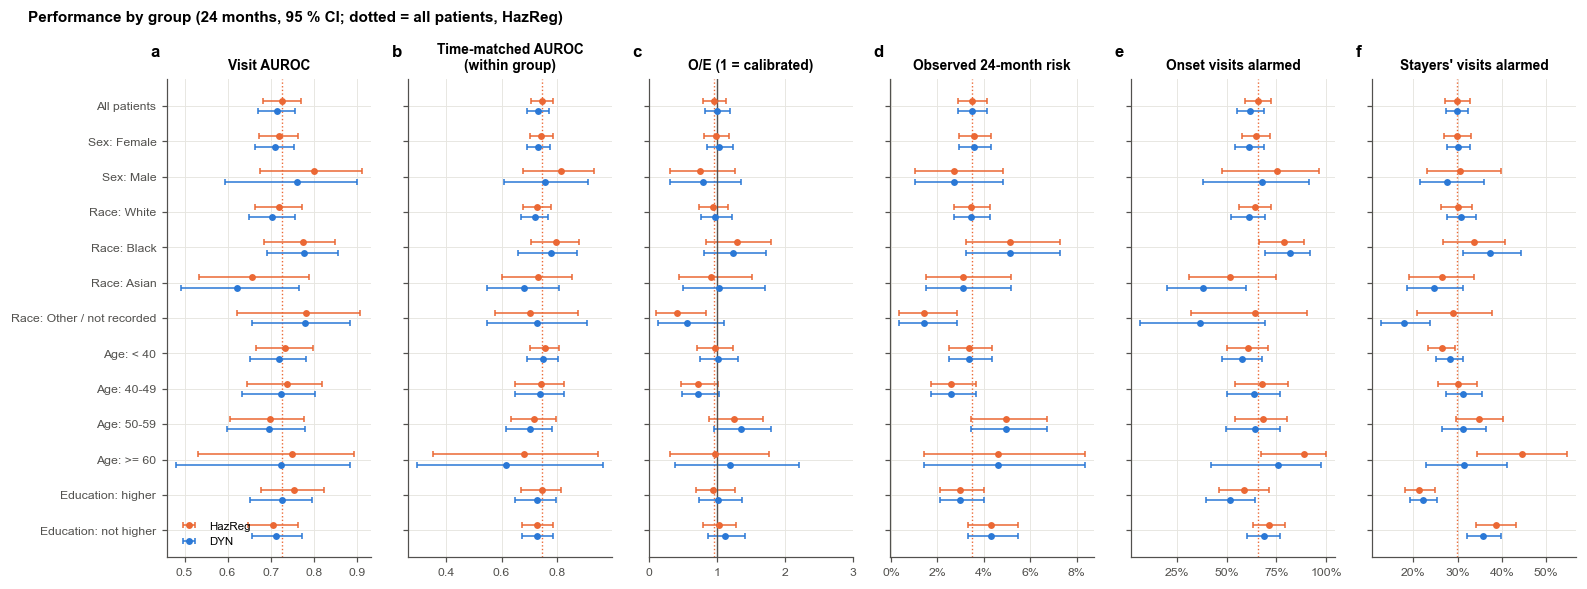

Tier,"Observed risk, < 2 %","Observed risk, 2-4 %","Observed risk, 4-10 %","Observed risk, >= 10 %"
Group,,,,
Age: 40-49,0.9 % (0.1-1.7),1.5 % (0.7-2.6),4.8 % (2.7-7.5),15.1 % (6.9-24.3)
Age: 50-59,2.4 % (0.7-4.9),2.7 % (1.5-4.3),9.1 % (5.9-12.7),13.5 % (6.7-22.7)
Age: < 40,1.1 % (0.4-1.9),2.6 % (1.7-3.5),6.9 % (4.6-9.3),13.4 % (7.1-21.2)
Age: >= 60,3.1 % (0.0-11.4),0.5 % (0.0-1.2),9.1 % (1.8-18.5),13.4 % (0.0-42.2)
All patients,1.3 % (0.7-1.9),2.2 % (1.6-2.8),6.9 % (5.4-8.5),13.9 % (9.5-18.2)
Education: higher,0.9 % (0.3-1.6),2.2 % (1.3-3.4),7.2 % (4.6-10.3),18.3 % (9.4-27.6)
Education: not higher,1.8 % (0.7-3.1),2.3 % (1.5-3.4),7.0 % (5.0-9.2),14.5 % (9.3-20.8)
Race: Asian,1.6 % (0.0-3.6),2.6 % (0.9-5.0),5.9 % (2.5-11.5),7.0 % (1.7-17.1)
Race: Black,1.4 % (0.0-3.8),2.1 % (1.0-3.5),10.9 % (6.5-16.7),17.5 % (7.7-31.9)


Fairness (HazReg): groups whose O/E 95 % CI excludes 1: Race: Other / not recorded; groups ranked worse than the
cohort: none; groups with a lower observed risk than the cohort: Race: Other / not recorded, Age: 40-49.


In [58]:
"""Fairness (TRIPOD+AI 14, 23a): ranking, calibration and alarms by group."""
_rows_h, _y_h, _w_h = IPCW_H[H]
_Wr_h = _BOTH[:, ROW_PIDX[_rows_h]] * _w_h[None, :]
_edu = LAND_X["EDU_HIGHER"].values
FAIR_GROUPS = {"All patients": np.ones(N_LAND, bool)}
FAIR_GROUPS.update({f"Sex: {v_}": LAND_SUB["sex"].values == v_ for v_ in ["Female", "Male"]})
FAIR_GROUPS.update({f"Race: {v_}": LAND_SUB["race"].values == v_ for v_ in ["White", "Black", "Asian",
                                                                             "Other / not recorded"]})
FAIR_GROUPS.update({f"Age: {v_}": LAND_SUB["age_band"].values == v_ for _, _, v_ in AGE_BANDS})
FAIR_GROUPS.update({"Education: higher": _edu == 1, "Education: not higher": _edu == 0})
FAIR_MODELS = [m for m in [REPORTED, SEQ_MAIN] if m in MODELS_RUN]
_t_lo, _t_hi = RISK_TIERS[0][1], RISK_TIERS[-1][0]


def _rmean(arrs):
    return np.nanmean(np.vstack(arrs), 0)


def group_metrics(m, mask_rows):
    """Visit-level metrics of model m on the landmarks in mask_rows (24 months, IPCW); arrays = point + bootstrap."""
    k = mask_rows[_rows_h]
    y, w, Wr = _y_h[k], _w_h[k], _Wr_h[:, k]
    y1 = (y == 1).astype(np.float32)
    out = {x: [] for x in ["auroc", "oe", "sens", "fpr", "obs", "pred", "low", "high", "miss_low"]}
    slopes = []
    for r in REPEATS:
        z = zpred(m, r)[_rows_h][k]
        p = _expit(z)
        out["auroc"].append(wauc(y, z, Wr))
        out["oe"].append((Wr @ y) / (Wr @ p))
        out["obs"].append((Wr @ y) / Wr.sum(1)); out["pred"].append((Wr @ p) / Wr.sum(1))
        cs = confusion_stats(y, z >= THR_V[m][r][H][MAIN_THRESHOLD][_rows_h][k], Wr)
        out["sens"].append(cs["sensitivity"]); out["fpr"].append(1 - cs["specificity"])
        lo_, hi_ = (p < _t_lo).astype(np.float32), (p >= _t_hi).astype(np.float32)
        out["low"].append((Wr @ lo_) / Wr.sum(1)); out["high"].append((Wr @ hi_) / Wr.sum(1))
        out["miss_low"].append(_ratio(Wr @ (y1 * lo_), Wr @ y1))
        slopes.append(wcalibration(y, z, w)[0])
    res = {k_: _rmean(v) for k_, v in out.items()}
    res["slope"] = np.array([np.nanmean(slopes)])
    return res, int(y.sum()), int(k.sum())


def tm_group(m, mask_rows):
    """Time-matched patient AUROC within the group: the onset's case and its same-date controls both from the group
    (an entity belongs to the group if most of its window's landmarks do). Sensitivity / specificity at the fold's
    time-matched threshold, each onset's in-group controls weighted equally."""
    d = TM["main"]
    g = np.asarray(d["mat"] @ mask_rows.astype(float)).ravel() >= 0.5
    pm = g[d["pc"]] & g[d["pk"]]
    if pm.sum() == 0:
        return None, 0
    pc, pk, ppc, ppk = d["pc"][pm], d["pk"][pm], d["ppc"][pm], d["ppk"][pm]
    den = _pair_sum_fast(_BOTH, sparse.coo_matrix((np.ones(len(pc)), (ppc, ppk)), shape=(P_, P_)).toarray())
    cases, inv, n_per = np.unique(pc, return_inverse=True, return_counts=True)
    wq = 1.0 / n_per[inv]
    wden = _pair_sum_fast(_BOTH, sparse.coo_matrix((wq, (ppc, ppk)), shape=(P_, P_)).toarray())
    Wc = _BOTH[:, d["ent_pid"][cases]]
    out = {"auroc": [], "sens": [], "spec": []}
    for r in REPEATS:
        s = np.asarray(d["mat"] @ np.nan_to_num(zpred(m, r))).ravel()
        a, b = s[pc], s[pk]
        K = sparse.coo_matrix(((a > b) + 0.5 * (a == b), (ppc, ppk)), shape=(P_, P_)).toarray()
        out["auroc"].append(_pair_sum_fast(_BOTH, K) / den)
        flag = s >= tm_fold_thresholds(m, r)[TEST_FOLD[r][d["ent_pid"]]]
        out["sens"].append((Wc @ flag[cases].astype(np.float32)) / Wc.sum(1))
        Ks = sparse.coo_matrix((wq * ~flag[pk], (ppc, ppk)), shape=(P_, P_)).toarray()
        out["spec"].append(_pair_sum_fast(_BOTH, Ks) / wden)
    return {k_: _rmean(v) for k_, v in out.items()}, len(cases)


_f = lambda a: fmt(a[0], *np.nanpercentile(a[1:], [2.5, 97.5]))
_fp = lambda a: f"{100 * a[0]:.1f} % ({100 * np.nanpercentile(a[1:], 2.5):.1f}-{100 * np.nanpercentile(a[1:], 97.5):.1f})"
rows, FAIR_RAW, FAIR_TM = [], {}, {}
for m in FAIR_MODELS:
    for g_, mask in FAIR_GROUPS.items():
        res_, n_ev, n_l = group_metrics(m, mask)
        tm_, n_on = tm_group(m, mask)
        FAIR_RAW[(m, g_)], FAIR_TM[(m, g_)] = res_, tm_
        rows.append({"Model": short_label(m), "Group": g_, "Patients": len(np.unique(PID_ALL[mask])),
                     "Onset patients": len(np.unique(PID_ALL[mask & (C_ALL == 1)])), "Landmarks": n_l,
                     "Onset landmarks": n_ev,
                     "Visit AUROC": _f(res_["auroc"]),
                     "Time-matched AUROC (within group)": _f(tm_["auroc"]) if tm_ is not None and n_on >= 10 else "-",
                     f"Observed {H}-mo risk": _fp(res_["obs"]), f"Mean predicted {H}-mo risk": _fp(res_["pred"]),
                     "O/E": _f(res_["oe"]), "Calibration slope": f"{res_['slope'][0]:.2f}",
                     "Onset visits alarmed": _f(res_["sens"]), "Stayers' visits alarmed": _f(res_["fpr"]),
                     f"Visits {TIER_LOW}": _fp(res_["low"]), f"Visits {TIER_HIGH}": _fp(res_["high"]),
                     f"Onsets in {TIER_LOW} (missed by rule-out)": _fp(res_["miss_low"])})
FAIRNESS = pd.DataFrame(rows).set_index(["Model", "Group"])
_c_rank = ["Patients", "Onset patients", "Landmarks", "Onset landmarks", "Visit AUROC", "Time-matched AUROC (within group)"]
_c_cal = [f"Observed {H}-mo risk", f"Mean predicted {H}-mo risk", "O/E", "Calibration slope"]
print("Ranking:"); display(FAIRNESS[_c_rank])
print("Calibration (observed vs predicted risk):"); display(FAIRNESS[_c_cal])
print("Alarms at the shared threshold and risk tiers:")
display(FAIRNESS[[c for c in FAIRNESS.columns if c not in _c_rank + _c_cal]])
FAIRNESS.to_csv(f"tripod_fairness_{TAG}.csv")

# the reading of each group (main model): ranking, level and risk compared with the whole cohort
_all = FAIR_RAW[(REPORTED, "All patients")]
rows = []
for g_ in list(FAIR_GROUPS)[1:]:
    r_ = FAIR_RAW[(REPORTED, g_)]
    n_ev = int(FAIRNESS.loc[(short_label(REPORTED), g_), "Onset landmarks"])
    d_auc = r_["auroc"] - _all["auroc"]
    lo_a, hi_a = np.nanpercentile(d_auc[1:], [2.5, 97.5])
    lo_o, hi_o = np.nanpercentile(r_["oe"][1:], [2.5, 97.5])
    rr = r_["obs"] / _all["obs"]
    lo_r, hi_r = np.nanpercentile(rr[1:], [2.5, 97.5])
    if n_ev < 10:
        reading = "too few onsets to interpret"
    else:
        parts = []
        parts.append("ranks worse" if hi_a < 0 else "ranks better" if lo_a > 0 else "ranks as well")
        parts.append("under-predicts" if lo_o > 1 else "over-predicts" if hi_o < 1 else "calibrated")
        parts.append("lower risk than the cohort" if hi_r < 1 else "higher risk than the cohort" if lo_r > 1
                     else "risk similar to the cohort")
        reading = "; ".join(parts)
    rows.append({"Group": g_, "Onset landmarks": n_ev, "AUROC - all patients": fmt(d_auc[0], lo_a, hi_a),
                 "O/E": fmt(r_["oe"][0], lo_o, hi_o), "Observed risk / all patients": fmt(rr[0], lo_r, hi_r),
                 "Onset visits alarmed": fmt(r_["sens"][0], *np.nanpercentile(r_["sens"][1:], [2.5, 97.5])),
                 "Reading": reading})
FAIR_READING = pd.DataFrame(rows).set_index("Group")
print(f"How to read each group ({short_label(REPORTED)}): is a lower sensitivity due to ranking, calibration or a "
      f"lower risk?")
display(FAIR_READING)
FAIR_READING.to_csv(f"tripod_fairness_reading_{TAG}.csv")

_gl = list(FAIR_GROUPS)
_panels = [("auroc", "Visit AUROC", None, "raw"), ("tm", "Time-matched AUROC\n(within group)", None, "tm"),
           ("oe", "O/E (1 = calibrated)", 1.0, "raw"), ("obs", f"Observed {H}-month risk", None, "raw"),
           ("sens", "Onset visits alarmed", None, "raw"), ("fpr", "Stayers' visits alarmed", None, "raw")]
fig, axes = plt.subplots(1, len(_panels), figsize=(14.5, 0.3 * len(_gl) + 1.5), sharey=True)
yy = np.arange(len(_gl))[::-1]
for j, m in enumerate(FAIR_MODELS):
    off = 0.15 * (1 - 2 * j)
    for ax, (met, lab_, ref, src) in zip(axes, _panels):
        v = []
        for g_ in _gl:
            a = (FAIR_TM[(m, g_)] or {}).get("auroc") if src == "tm" else FAIR_RAW[(m, g_)][met]
            v.append([np.nan] * 3 if a is None else [a[0], *np.nanpercentile(a[1:], [2.5, 97.5])])
        v = np.array(v, float)
        ok = ~np.isnan(v[:, 0])
        ax.errorbar(v[ok, 0], yy[ok] + off, xerr=[v[ok, 0] - v[ok, 1], v[ok, 2] - v[ok, 0]], fmt="o", ms=3.5,
                    color=model_color(m), capsize=2, lw=1, label=short_label(m))
        if ref:
            ax.axvline(ref, color=INK_2, lw=0.8)
        a_all = (FAIR_TM[(m, "All patients")]["auroc"] if src == "tm" else FAIR_RAW[(m, "All patients")][met])[0]
        if j == 0:
            ax.axvline(a_all, color=model_color(m), ls=":", lw=0.9)
        ax.set_title(lab_, fontsize=9)
        if met in ("obs", "sens", "fpr"):
            ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{100 * t:.0f}%"))
for k_, ax in enumerate(axes):
    panel_label(ax, "abcdef"[k_], dx=-0.08)
axes[0].set_yticks(yy); axes[0].set_yticklabels(_gl, fontsize=8); axes[0].legend(fontsize=7.5, loc="lower left")
axes[2].set_xlim(0, 3)
fig.suptitle(f"Performance by group ({H} months, 95 % CI; dotted = all patients, {short_label(REPORTED)})",
             x=0.02, ha="left", fontsize=10, fontweight="bold")
plt.tight_layout(); save_fig("fairness")

# the risk tiers by group (main model): what the absolute-risk output looks like in each group
rows = []
_y1h = (_y_h == 1).astype(np.float32)
for g_, mask in FAIR_GROUPS.items():
    k = mask[_rows_h]
    for lo, hi, name in RISK_TIERS:
        sh, ob, so = [], [], []
        for r in REPEATS:
            p = _expit(zpred(REPORTED, r)[_rows_h])
            inn = (k & (p >= lo) & (p < hi)).astype(np.float32)
            Wk = _Wr_h * k[None, :]
            sh.append((_Wr_h @ inn) / Wk.sum(1)); ob.append(_ratio(_Wr_h @ (_y1h * inn), _Wr_h @ inn))
            so.append(_ratio(_Wr_h @ (_y1h * inn), Wk @ _y1h))
        rows.append({"Group": g_, "Tier": name, "Share of visits": _fp(_rmean(sh)),
                     f"Observed {H}-mo risk": _fp(_rmean(ob)), "Share of the group's onsets": _fp(_rmean(so))})
FAIR_TIERS = pd.DataFrame(rows).set_index(["Group", "Tier"])
display(FAIR_TIERS["Observed " + f"{H}-mo risk"].unstack("Tier")[[t for _, _, t in RISK_TIERS]]
        .rename(columns=lambda c: f"Observed risk, {c}"))
FAIR_TIERS.to_csv(f"tripod_fairness_tiers_{TAG}.csv")
_mis = [g_ for g_ in _gl[1:] if np.nanpercentile(FAIR_RAW[(REPORTED, g_)]["oe"][1:], 2.5) > 1
        or np.nanpercentile(FAIR_RAW[(REPORTED, g_)]["oe"][1:], 97.5) < 1]
_rank = [g_ for g_ in _gl[1:] if FAIR_READING.loc[g_, "Reading"].startswith("ranks worse")]
FAIR_SUMMARY = (f"Fairness ({short_label(REPORTED)}): groups whose O/E 95 % CI excludes 1: "
                f"{', '.join(_mis) if _mis else 'none'}; groups ranked worse than the cohort: "
                f"{', '.join(_rank) if _rank else 'none'}; groups with a lower observed risk than the cohort: "
                f"{', '.join(g_ for g_ in _gl[1:] if 'lower risk' in FAIR_READING.loc[g_, 'Reading']) or 'none'}.")
print(textwrap.fill(FAIR_SUMMARY, 118))

## 20.5 Performance by length of clinic history; a new patient

DYN reads up to 2 years of history on the 6-month grid; a patient new to the clinic has fewer grid points (one at
their first visit), and for every model the change-from-own-baseline inputs are 0 (no earlier visit). Performance
by the history available at the landmark: < 6 months (the first grid point only), 6-24 months, the full 2 years
with < 10 years in the clinic, and ≥ 10 years. How a new patient is handled is stated in Section 20.7 (item 27a).

In [59]:
"""Performance by length of history (TRIPOD+AI 27a)."""
_yrs_hist = (LG_LEN - 1) * GRID_STEP_MONTHS / 12
HIST_GROUPS = {"< 6 months of history (first grid point only)": LG_LEN == 1,
               "6-24 months": (LG_LEN >= 2) & (LG_LEN < 5),
               "Full 2 years, < 10 years in clinic": (LG_LEN >= 5) & (land["YRS_IN_CLINIC"].values < 10),
               ">= 10 years in clinic": (LG_LEN >= 5) & (land["YRS_IN_CLINIC"].values >= 10)}
rows = []
for m in [x for x in [REPORTED, SEQ_MAIN, L2_FIRST] if x in MODELS_RUN]:
    for g_, mask in HIST_GROUPS.items():
        res_, n_ev, n_l = group_metrics(m, mask)
        rows.append({"Model": short_label(m), "History": g_, "Landmarks": n_l, "Onset landmarks": n_ev,
                     "AUROC": _f(res_["auroc"]) if n_ev >= 5 else "-", "O/E": _f(res_["oe"]),
                     "Onset visits alarmed": _f(res_["sens"])})
HISTORY = pd.DataFrame(rows).set_index(["Model", "History"])
display(HISTORY)
HISTORY.to_csv(f"tripod_history_length_{TAG}.csv")
print(f"Landmarks by history: " + ", ".join(f"{g_}: {mask.mean():.0%}" for g_, mask in HIST_GROUPS.items()))

Landmarks  Onset landmarks                   AUROC                     O/E    Onset visits alarmed
Model          History                                                                                                                                          
HazReg         < 6 months of history (first grid point only)       1264               81  0.679 (0.615 to 0.747)  1.068 (0.768 to 1.388)  0.812 (0.724 to 0.893)
               6-24 months                                         2304              101  0.756 (0.692 to 0.815)  0.939 (0.642 to 1.256)  0.803 (0.721 to 0.877)
               Full 2 years, < 10 years in clinic                  7419              274  0.724 (0.651 to 0.788)  1.000 (0.736 to 1.276)  0.629 (0.518 to 0.736)
               >= 10 years in clinic                               4192              111  0.676 (0.553 to 0.782)  0.815 (0.504 to 1.166)  0.490 (0.277 to 0.662)
DYN            < 6 months of history (first grid point only)       1264               81  0.644 (0.575 to 0.717)  1.212 (0.870 to 1.577)  0.782 (0.694 to 0.871)
               6-24 months                                         2304              101  0.758 (0.684 to 0.823)  0.920 (0.623 to 1.226)  0.815 (0.722 to 0.903)
               Full 2 years, < 10 years in clinic                  7419              274  0.719 (0.657 to 0.779)  1.057 (0.792 to 1.350)  0.558 (0.452 to 0.661)
               >= 10 years in clinic                               4192              111  0.654 (0.521 to 0.765)  0.851 (0.518 to 1.228)  0.474 (0.285 to 0.635)
L2 First visit < 6 months of history (first grid point only)       1264               81  0.630 (0.545 to 0.716)  1.313 (0.944 to 1.710)  0.661 (0.533 to 0.791)
               6-24 months                                         2304              101  0.676 (0.594 to 0.745)  0.976 (0.661 to 1.311)  0.667 (0.551 to 0.768)
               Full 2 years, < 10 years in clinic                  7419              274  0.631 (0.547 to 0.706)  0.955 (0.705 to 1.221)  0.484 (0.380 to 0.591)
               >= 10 years in clinic                               4192              111  0.484 (0.369 to 0.615)  0.736 (0.442 to 1.084)  0.198 (0.075 to 0.368)

Landmarks by history: < 6 months of history (first grid point only): 8%, 6-24 months: 15%, Full 2 years, < 10 years in clinic: 48%, >= 10 years in clinic: 29%


## 20.6 TRIPOD+AI checklist

Each item, whether it is reported, and where (N = notebook section; M = manuscript only). "Partly" means the
notebook gives what it can and the manuscript must complete it.

In [60]:
"""TRIPOD+AI checklist."""
_tm_t = _ff(TEMP_MET[REPORTED]["Time-matched patient AUROC"])
CHECKLIST = pd.DataFrame([
    ("1", "Title", "Identify as developing/evaluating a prediction model, target population, outcome", "M", "Manuscript"),
    ("2", "Abstract", "TRIPOD+AI for Abstracts", "M", "Manuscript"),
    ("3a", "Background", "Healthcare context, rationale, intended use", "Partly", "N1 (motivation, intended action); M"),
    ("3b", "Background", "Intended users and place in the care pathway", "Partly",
     "N14.4-14.5 (vocational referral at a routine visit; relative and absolute tiers); M"),
    ("3c", "Background", "Known health inequalities between groups", "M", "Manuscript (work disability by race, "
     "education, sex in SLE)"),
    ("4", "Objectives", "Objectives, development and/or evaluation", "Yes", "N0, N8 (aims, hypotheses)"),
    ("5a", "Data", "Data sources, rationale, representativeness", "Partly", "N2, N20.1; M (single centre)"),
    ("5b", "Data", "Dates of data collection, follow-up end", "Yes", "N20.1"),
    ("6a", "Participants", "Setting, number and location of centres", "Partly", "N2, N20.1 (one centre); M"),
    ("6b", "Participants", "Eligibility criteria", "Yes", "N2, N4, N20.1 (flow)"),
    ("6c", "Participants", "Treatments received", "Yes", "N20.2 (Table 1: prednisone, antimalarial, immunosuppressants)"),
    ("7", "Data preparation", "Pre-processing, quality checks, consistency across groups", "Yes",
     "N11.3b, N11.4 (grid, preprocessing in training folds), N20.2 (missingness by group)"),
    ("8a", "Outcome", "Definition, horizon, how assessed, rationale", "Yes", "N3-N4, N20.1b (outcome audit)"),
    ("8b", "Outcome", "Qualifications / demographics of outcome assessors", "M",
     "Manuscript (employment status recorded at clinic visits)"),
    ("8c", "Outcome", "Blinding of outcome assessment", "M", "Manuscript (not blinded: routine clinic data)"),
    ("9a", "Predictors", "Choice of initial predictors, pre-selection", "Partly",
     "N5 (27 clinical and social variables + change variables); M (literature basis)"),
    ("9b", "Predictors", "Definition, how and when measured", "Yes", "N5, N11.3b (on or before the landmark only)"),
    ("9c", "Predictors", "Assessor qualifications / blinding", "M", "Manuscript"),
    ("10", "Sample size", "How the sample size was arrived at; justification", "Yes", "N20.3 (Riley criteria)"),
    ("11", "Missing data", "How handled; reasons for omitting", "Yes", "N11.4, N20.2"),
    ("12a", "Analysis", "How the data were used (development / evaluation), splitting", "Yes",
     "N8, N11.5 (5x5 patient-grouped CV), N18.2 (validation by calendar period), N18.3 (temporal split)"),
    ("12b", "Analysis", "Predictor handling (functional form, rescaling)", "Yes", "N11.3b, N11.4"),
    ("12c", "Analysis", "Model type, building steps, tuning, internal validation", "Yes",
     "N6, N11.5"),
    ("12d", "Analysis", "Heterogeneity across clusters", "Partly", "N14.7 (by era), N18.2 (by period); single centre"),
    ("12e", "Analysis", "Performance measures and rationale", "Yes", "N9, N11.7-11.9"),
    ("12f", "Analysis", "Model updating after evaluation", "Yes",
     "N7 (recalibration in each training fold); N18.4 (level updates), N18.5 (deployment recalibration)"),
    ("12g", "Analysis", "For evaluation: how predictions were calculated", "Yes", "N11 (code); N18"),
    ("13", "Class imbalance", "Methods and recalibration", "Yes",
     "No resampling or weighting; recalibration inside each training fold (N7)"),
    ("14", "Fairness", "Methods to address fairness", "Yes",
     "N20.4 (by sex, race, age, education); race not an input (N5)"),
    ("15", "Model output", "Output form, thresholds and how chosen", "Yes", "N9, N14.4-14.5 (tiers, relative tiers)"),
    ("16", "Training vs evaluation", "Differences between development and evaluation data", "Yes", "N18.1-18.3"),
    ("17", "Ethics", "Ethics approval, consent", "M", "Manuscript"),
    ("18a", "Open science", "Funding", "M", "Manuscript"),
    ("18b", "Open science", "Conflicts of interest", "M", "Manuscript"),
    ("18c", "Open science", "Protocol", "M", "Manuscript (no published protocol: state it)"),
    ("18d", "Open science", "Registration", "M", "Manuscript (not registered: state it)"),
    ("18e", "Open science", "Data sharing", "M", "Manuscript"),
    ("18f", "Open science", "Code sharing", "Partly", "This notebook and build scripts; M (repository link)"),
    ("19", "Patient and public involvement", "Details or statement of none", "M", "Manuscript (none: state it)"),
    ("20a", "Participants", "Flow, numbers with / without the outcome, follow-up", "Yes", "N20.1, N20.1b"),
    ("20b", "Participants", "Characteristics, key dates, missing data", "Yes", "N20.1, N20.2"),
    ("20c", "Participants", "Evaluation vs development distributions", "Yes", "N18.1-18.3"),
    ("21", "Model development", "Participants and events in each analysis", "Yes", "N11.3, N20.1, N18.2-18.3"),
    ("22", "Model specification", "Full model to allow predictions; access restrictions", "Yes",
     "N14.2 (coefficients, preprocessing and recalibration: aim2_reported_model_specification CSV); N18.5 "
     "(deployment intercept)"),
    ("23a", "Performance", "Performance with CIs, incl. key subgroups", "Yes",
     f"N13-N16, N20.4, N20.5; temporal time-matched AUROC {_tm_t}"),
    ("23b", "Performance", "Heterogeneity across clusters", "Partly", "N14.7 (era), N18.2 (between-period tau)"),
    ("24", "Model updating", "Results of updating", "Yes", "N18.4-18.5 (one-time, rolling, deployment intercept)"),
    ("25", "Interpretation", "Overall interpretation incl. fairness", "Partly", "N19 (conclusions); M"),
    ("26", "Limitations", "Limitations, biases, generalisability", "Partly", "N10; M"),
    ("27a", "Usability", "Handling poor quality or unavailable inputs", "Yes",
     "N11.4 (median + missing indicator), N20.5 (new patient: change inputs 0)"),
    ("27b", "Usability", "User interaction / expertise needed", "M", "Manuscript (no user input beyond routine data)"),
    ("27c", "Usability", "Next steps, applicability, generalisability", "Partly",
     "N10 (external validation: SLICC inception cohort, Hopkins, LUMINA); M"),
], columns=["Item", "Section", "Requirement", "Reported", "Where"]).set_index("Item")
display(CHECKLIST)
CHECKLIST.to_csv(f"tripod_ai_checklist_{TAG}.csv")
print(f"Reported in the notebook: {int((CHECKLIST['Reported'] == 'Yes').sum())} items; partly: "
      f"{int((CHECKLIST['Reported'] == 'Partly').sum())}; manuscript only: {int((CHECKLIST['Reported'] == 'M').sum())}.")
print(textwrap.fill("Fairness summary: " + FAIR_SUMMARY, 118))

,Section,Requirement,Reported,Where
Item,,,,
1,Title,Identify as developing/evaluating a prediction...,M,Manuscript
2,Abstract,TRIPOD+AI for Abstracts,M,Manuscript
3a,Background,"Healthcare context, rationale, intended use",Partly,"N1 (motivation, intended action); M"
3b,Background,Intended users and place in the care pathway,Partly,N14.4-14.5 (vocational referral at a routine v...
3c,Background,Known health inequalities between groups,M,"Manuscript (work disability by race, education..."
4,Objectives,"Objectives, development and/or evaluation",Yes,"N0, N8 (aims, hypotheses)"
5a,Data,"Data sources, rationale, representativeness",Partly,"N2, N20.1; M (single centre)"
5b,Data,"Dates of data collection, follow-up end",Yes,N20.1
6a,Participants,"Setting, number and location of centres",Partly,"N2, N20.1 (one centre); M"


Reported in the notebook: 27 items; partly: 11; manuscript only: 14.
Fairness summary: Fairness (HazReg): groups whose O/E 95 % CI excludes 1: Race: Other / not recorded; groups ranked
worse than the cohort: none; groups with a lower observed risk than the cohort: Race: Other / not recorded, Age:
40-49.


---
# Appendix A. Secondary analyses

Secondary analyses of the reported model, LogReg, DYN and the ladder.

In [61]:
APP_MODELS = [m for m in [REPORTED, OTHER, SEQ_MAIN, L2_FIRST, L1_DEMO, UNIT, HZ_FULL] if m in MODELS_RUN]

## A.1 Every horizon from 6 to 48 months

One fit gives the risk at every horizon (Section 11.6); each horizon has its own censoring-weighted label,
recalibration and thresholds. Left: visit AUROC by horizon (the reported model bold, 95 % band); right: patient
windows (descriptive). Then the reported model's metrics at every horizon.

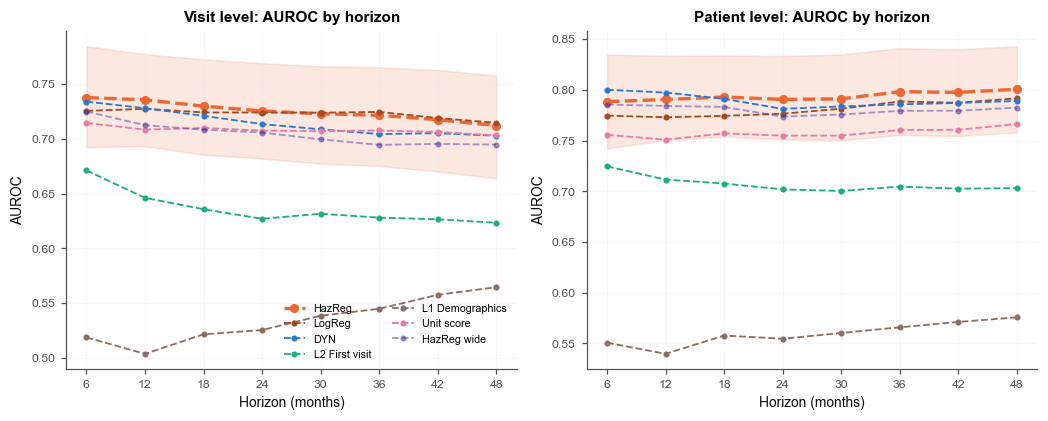

HazReg: cause-specific Poisson hazard regression on the current visit (compact set, splines) [reported model]


,Landmarks (known status),Observed cumulative risk (IPCW),Patients / with onset,Visit AUROC,Patient AUROC,Visit calibration slope,Visit O/E,Visit sens / spec,Patient sens / spec,Patient PPV
Horizon (months),,,,,,,,,,
6,16836,0.008,988 / 112,0.738 (0.692 to 0.785),0.788 (0.742 to 0.835),1.06,0.99 (0.81 to 1.19),0.65 / 0.70,0.68 / 0.77,0.28
12,16180,0.018,970 / 131,0.736 (0.693 to 0.777),0.790 (0.750 to 0.833),1.08,0.98 (0.81 to 1.17),0.63 / 0.72,0.70 / 0.75,0.31
18,15619,0.027,943 / 136,0.730 (0.686 to 0.773),0.793 (0.754 to 0.834),1.08,0.97 (0.81 to 1.15),0.64 / 0.73,0.74 / 0.72,0.31
24,15179,0.035,904 / 136,0.726 (0.682 to 0.769),0.791 (0.751 to 0.833),1.07,0.97 (0.80 to 1.15),0.66 / 0.70,0.72 / 0.73,0.33
30,14796,0.042,877 / 135,0.723 (0.677 to 0.766),0.791 (0.750 to 0.835),1.07,0.96 (0.80 to 1.14),0.65 / 0.70,0.73 / 0.73,0.33
36,14471,0.048,854 / 132,0.722 (0.675 to 0.766),0.798 (0.756 to 0.841),1.06,0.95 (0.79 to 1.13),0.65 / 0.70,0.76 / 0.73,0.34
42,14122,0.055,830 / 131,0.718 (0.670 to 0.763),0.797 (0.754 to 0.840),1.06,0.94 (0.77 to 1.11),0.64 / 0.70,0.75 / 0.73,0.35
48,13609,0.061,801 / 130,0.712 (0.664 to 0.758),0.801 (0.758 to 0.843),1.07,0.92 (0.77 to 1.09),0.64 / 0.69,0.73 / 0.75,0.37


,Model,Level,6 mo,12 mo,18 mo,24 mo,30 mo,36 mo,42 mo,48 mo
0,HazReg,visit,0.738 (0.692 to 0.785),0.736 (0.693 to 0.777),0.730 (0.686 to 0.773),0.726 (0.682 to 0.769),0.723 (0.677 to 0.766),0.722 (0.675 to 0.766),0.718 (0.670 to 0.763),0.712 (0.664 to 0.758)
1,LogReg,visit,0.726 (0.678 to 0.777),0.727 (0.684 to 0.772),0.724 (0.680 to 0.768),0.724 (0.679 to 0.769),0.724 (0.679 to 0.768),0.725 (0.678 to 0.768),0.719 (0.670 to 0.765),0.715 (0.665 to 0.763)
2,DYN,visit,0.734 (0.685 to 0.782),0.728 (0.685 to 0.770),0.721 (0.678 to 0.764),0.714 (0.670 to 0.756),0.709 (0.666 to 0.752),0.704 (0.662 to 0.746),0.705 (0.661 to 0.748),0.703 (0.658 to 0.747)
3,L2 First visit,visit,0.671 (0.616 to 0.723),0.646 (0.593 to 0.697),0.636 (0.582 to 0.687),0.627 (0.572 to 0.681),0.632 (0.578 to 0.687),0.628 (0.574 to 0.686),0.626 (0.573 to 0.683),0.623 (0.569 to 0.683)
4,L1 Demographics,visit,0.518 (0.466 to 0.569),0.503 (0.457 to 0.552),0.521 (0.471 to 0.570),0.525 (0.475 to 0.573),0.538 (0.484 to 0.590),0.545 (0.488 to 0.595),0.557 (0.500 to 0.610),0.564 (0.506 to 0.617)
5,Unit score,visit,0.714 (0.665 to 0.767),0.708 (0.664 to 0.755),0.710 (0.667 to 0.756),0.708 (0.665 to 0.753),0.707 (0.663 to 0.751),0.708 (0.663 to 0.751),0.706 (0.660 to 0.749),0.703 (0.657 to 0.748)
6,HazReg wide,visit,0.725 (0.677 to 0.773),0.713 (0.669 to 0.753),0.708 (0.666 to 0.750),0.706 (0.663 to 0.746),0.700 (0.656 to 0.742),0.695 (0.653 to 0.738),0.695 (0.653 to 0.737),0.695 (0.651 to 0.740)
7,HazReg,patient,0.788 (0.742 to 0.835),0.790 (0.750 to 0.833),0.793 (0.754 to 0.834),0.791 (0.751 to 0.833),0.791 (0.750 to 0.835),0.798 (0.756 to 0.841),0.797 (0.754 to 0.840),0.801 (0.758 to 0.843)
8,LogReg,patient,0.775 (0.726 to 0.824),0.773 (0.729 to 0.818),0.774 (0.734 to 0.818),0.776 (0.736 to 0.821),0.781 (0.741 to 0.826),0.788 (0.748 to 0.833),0.787 (0.747 to 0.831),0.792 (0.750 to 0.836)
9,DYN,patient,0.800 (0.754 to 0.843),0.797 (0.755 to 0.839),0.791 (0.750 to 0.832),0.781 (0.739 to 0.824),0.784 (0.743 to 0.826),0.786 (0.744 to 0.829),0.787 (0.745 to 0.831),0.789 (0.748 to 0.832)


In [62]:
"""AUROC by horizon, every model; the main model's metrics by horizon."""
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9))
for ax, lev in zip(axes, ["visit", "patient"]):
    for m in APP_MODELS:
        v = np.array([ci((m, lev, h, "auroc")) for h in HORIZONS])
        main = m == REPORTED
        ax.plot(HORIZONS, v[:, 0], "o-", color=model_color(m), ls=model_ls(m), lw=2.2 if main else 1.2,
                ms=5 if main else 3, label=short_label(m), alpha=1 if m in FIG_MODELS else 0.5)
        if main:
            ax.fill_between(HORIZONS, v[:, 1], v[:, 2], color=model_color(m), alpha=0.15)
    ax.set_xticks(HORIZONS); ax.set_xlabel("Horizon (months)"); ax.set_ylabel("AUROC"); ax.grid(alpha=0.3)
    ax.set_title(f"{lev.capitalize()} level: AUROC by horizon")
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); save_fig("horizons_auroc")

rows = []
for h in HORIZONS:
    rows.append({"Horizon (months)": h, "Landmarks (known status)": len(IPCW_H[h][0]),
                 "Observed cumulative risk (IPCW)": round(CIF_IPCW[h], 3),
                 "Patients / with onset": f"{len(PTW[h]['pids'])} / {int(PTW[h]['event'].sum())}",
                 "Visit AUROC": fmtk((REPORTED, "visit", h, "auroc")),
                 "Patient AUROC": fmtk((REPORTED, "patient", h, "auroc")),
                 "Visit calibration slope": f"{ci((REPORTED, 'visit', h, 'cal_slope'))[0]:.2f}",
                 "Visit O/E": fmtk((REPORTED, "visit", h, "oe"), 2),
                 "Visit sens / spec": f"{ci((REPORTED, 'visit', h, MAIN_THRESHOLD, 'sensitivity'))[0]:.2f} / "
                                      f"{ci((REPORTED, 'visit', h, MAIN_THRESHOLD, 'specificity'))[0]:.2f}",
                 "Patient sens / spec": f"{ci((REPORTED, 'patient', h, MAIN_THRESHOLD, 'sensitivity'))[0]:.2f} / "
                                        f"{ci((REPORTED, 'patient', h, MAIN_THRESHOLD, 'specificity'))[0]:.2f}",
                 "Patient PPV": f"{ci((REPORTED, 'patient', h, MAIN_THRESHOLD, 'ppv'))[0]:.2f}"})
HORIZON_MAIN = pd.DataFrame(rows).set_index("Horizon (months)")
print(model_label(REPORTED))
display(HORIZON_MAIN)
HORIZON_MAIN.to_csv(f"appA_horizons_main_{TAG}.csv")
HORIZON_ALL = pd.DataFrame([{"Model": short_label(m), "Level": lev,
                             **{f"{h} mo": fmtk((m, lev, h, "auroc")) for h in HORIZONS}}
                            for lev in ["visit", "patient"] for m in APP_MODELS])
display(HORIZON_ALL)
HORIZON_ALL.to_csv(f"appA_horizons_all_{TAG}.csv", index=False)

## A.2 Exclusive 12-month intervals

AUROC for an onset in months 0-12, 12-24, 24-36 and 36-48 among the landmarks still at risk at the start of the
interval (no shared onsets, unlike the cumulative horizons); the slope per year over the four intervals.

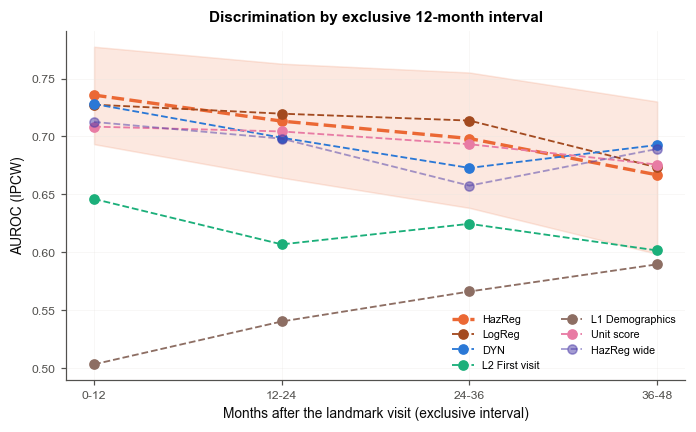

Landmarks at risk with a known status / onsets: 0-12 mo 16,180 / 303, 12-24 mo 14,500 / 264, 24-36 mo 13,215 / 193, 36-48 mo 11,882 / 182


,0-12 mo,12-24 mo,24-36 mo,36-48 mo,0-12 minus 36-48,Slope per year
Model,,,,,,
HazReg,0.736 (0.693 to 0.777),0.713 (0.664 to 0.763),0.698 (0.638 to 0.755),0.667 (0.599 to 0.730),0.069 (0.016 to 0.123),-0.0221 (-0.0405 to -0.0046)
LogReg,0.727 (0.684 to 0.772),0.720 (0.669 to 0.767),0.714 (0.653 to 0.768),0.673 (0.605 to 0.741),0.054 (0.000 to 0.111),-0.0168 (-0.0359 to 0.0023)
DYN,0.728 (0.685 to 0.770),0.699 (0.649 to 0.748),0.673 (0.619 to 0.729),0.693 (0.626 to 0.753),0.035 (-0.017 to 0.089),-0.0132 (-0.0319 to 0.0053)
L2 First visit,0.646 (0.593 to 0.697),0.607 (0.547 to 0.669),0.625 (0.556 to 0.692),0.602 (0.535 to 0.672),0.044 (-0.014 to 0.103),-0.0116 (-0.0321 to 0.0087)
L1 Demographics,0.503 (0.457 to 0.552),0.540 (0.481 to 0.597),0.566 (0.498 to 0.632),0.590 (0.521 to 0.654),-0.086 (-0.144 to -0.023),0.0285 (0.0076 to 0.0484)
Unit score,0.708 (0.664 to 0.755),0.704 (0.653 to 0.757),0.693 (0.636 to 0.749),0.676 (0.612 to 0.741),0.033 (-0.027 to 0.094),-0.0109 (-0.0305 to 0.0080)
HazReg wide,0.713 (0.669 to 0.753),0.698 (0.652 to 0.744),0.658 (0.601 to 0.712),0.689 (0.623 to 0.750),0.023 (-0.032 to 0.078),-0.0110 (-0.0306 to 0.0078)


In [63]:
"""Exclusive intervals."""
_x = np.array([(a + b) / 24 for a, b in INTERVALS])
rows = []
fig, ax = plt.subplots(figsize=(6.4, 4))
for m in APP_MODELS:
    v = np.array([ci((m, "interval", iv, "auroc")) for iv in INTERVALS])
    main = m == REPORTED
    ax.plot(range(len(INTERVALS)), v[:, 0], "o-", color=model_color(m), ls=model_ls(m), lw=2.2 if main else 1.2,
            label=short_label(m), alpha=1 if m in FIG_MODELS else 0.5)
    if main:
        ax.fill_between(range(len(INTERVALS)), v[:, 1], v[:, 2], color=model_color(m), alpha=0.15)
    p0, b0 = STATS[(m, "interval", INTERVALS[0], "auroc")]
    p3, b3 = STATS[(m, "interval", INTERVALS[-1], "auroc")]
    dd = _diff_summary(p0 - p3, b0 - b3)
    xc = _x - _x.mean()
    pts = np.array([STATS[(m, "interval", iv, "auroc")][0] for iv in INTERVALS])
    bts = np.vstack([STATS[(m, "interval", iv, "auroc")][1] for iv in INTERVALS])
    sl = _diff_summary(float(xc @ pts / (xc @ xc)), xc @ bts / (xc @ xc))
    rows.append({"Model": short_label(m), **{f"{a}-{b} mo": fmt(*v_) for (a, b), v_ in zip(INTERVALS, v)},
                 "0-12 minus 36-48": fmt(*dd[:3]), "Slope per year": fmt(*sl[:3], nd=4)})
ax.set_xticks(range(len(INTERVALS))); ax.set_xticklabels([f"{a}-{b}" for a, b in INTERVALS])
ax.set_xlabel("Months after the landmark visit (exclusive interval)"); ax.set_ylabel("AUROC (IPCW)")
ax.set_title("Discrimination by exclusive 12-month interval"); ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); save_fig("intervals")
INTERVAL_TABLE = pd.DataFrame(rows).set_index("Model")
print("Landmarks at risk with a known status / onsets: " + ", ".join(
    f"{a}-{b} mo {len(IPCW_INT[(a, b)][0]):,} / {int(IPCW_INT[(a, b)][1].sum())}" for a, b in INTERVALS))
display(INTERVAL_TABLE)
INTERVAL_TABLE.to_csv(f"appA_intervals_{TAG}.csv")

## A.3 Patient windows

Every patient-window metric (Section 9; one score per patient, onset and event-free patients scored at different
calendar times, so descriptive), both threshold rules and both patient rules, and the visit level under both
threshold rules.

In [64]:
"""Patient-level table of every model."""
rows = []
for m in APP_MODELS:
    for c in THRESHOLD_RULES:
        rows.append({"Model": short_label(m), "Rule": PATIENT_RULE_LABELS["meanlogit"], "Threshold": THRESHOLD_LABELS[c],
                     "AUROC": fmtk((m, "patient", H, "auroc")),
                     **{METRIC_LABELS[x]: fmtk((m, "patient", H, c, x)) for x in CONF_METRICS}})
    rows.append({"Model": short_label(m), "Rule": PATIENT_RULE_LABELS["run2"], "Threshold": THRESHOLD_LABELS["cost"],
                 "AUROC": fmtk((m, "patient", H, "run2", "auroc")),
                 **{METRIC_LABELS[x]: fmtk((m, "patient", H, "run2", x)) for x in CONF_METRICS}})
PATIENT_TABLE = pd.DataFrame(rows)
display(PATIENT_TABLE)
PATIENT_TABLE.to_csv(f"appA_patient_level_{TAG}.csv", index=False)
rows = []
for m in APP_MODELS:
    for c in THRESHOLD_RULES:
        rows.append({"Model": short_label(m), "Threshold": THRESHOLD_LABELS[c],
                     f"Threshold ({H}-month risk)": f"{100 * ci((m, 'visit', H, c, 'threshold'))[0]:.1f} %",
                     **{METRIC_LABELS[x]: fmtk((m, "visit", H, c, x)) for x in CONF_METRICS}})
VISIT_TABLE = pd.DataFrame(rows)
print("Visit level (IPCW), both threshold rules:")
display(VISIT_TABLE)
VISIT_TABLE.to_csv(f"appA_visit_level_{TAG}.csv", index=False)

,Model,Rule,Threshold,AUROC,Sensitivity,Specificity,PPV,NPV,Balanced accuracy,Share flagged
0,HazReg,mean logit over the window,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.791 (0.751 to 0.833),0.725 (0.659 to 0.787),0.733 (0.706 to 0.760),0.325 (0.276 to 0.377),0.938 (0.920 to 0.955),0.729 (0.694 to 0.765),0.336 (0.308 to 0.365)
1,HazReg,mean logit over the window,Max PPV (sensitivity >= 25%),0.791 (0.751 to 0.833),0.265 (0.203 to 0.334),0.954 (0.939 to 0.967),0.505 (0.399 to 0.617),0.880 (0.858 to 0.902),0.609 (0.577 to 0.645),0.079 (0.065 to 0.096)
2,HazReg,2 consecutive alarms,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.788 (0.747 to 0.831),0.719 (0.650 to 0.784),0.748 (0.721 to 0.774),0.337 (0.284 to 0.391),0.938 (0.920 to 0.955),0.734 (0.698 to 0.771),0.322 (0.295 to 0.350)
3,LogReg,mean logit over the window,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.776 (0.736 to 0.821),0.691 (0.621 to 0.758),0.739 (0.711 to 0.768),0.320 (0.270 to 0.375),0.931 (0.911 to 0.949),0.715 (0.679 to 0.752),0.326 (0.298 to 0.353)
4,LogReg,mean logit over the window,Max PPV (sensitivity >= 25%),0.776 (0.736 to 0.821),0.290 (0.219 to 0.362),0.946 (0.932 to 0.960),0.488 (0.391 to 0.592),0.883 (0.861 to 0.905),0.618 (0.583 to 0.655),0.089 (0.073 to 0.108)
5,LogReg,2 consecutive alarms,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.772 (0.731 to 0.817),0.681 (0.612 to 0.748),0.741 (0.713 to 0.770),0.318 (0.268 to 0.372),0.929 (0.909 to 0.948),0.711 (0.675 to 0.747),0.323 (0.294 to 0.350)
6,DYN,mean logit over the window,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.781 (0.739 to 0.824),0.694 (0.622 to 0.766),0.747 (0.719 to 0.777),0.327 (0.275 to 0.381),0.932 (0.914 to 0.951),0.721 (0.681 to 0.760),0.319 (0.291 to 0.348)
7,DYN,mean logit over the window,Max PPV (sensitivity >= 25%),0.781 (0.739 to 0.824),0.285 (0.217 to 0.355),0.954 (0.940 to 0.966),0.523 (0.415 to 0.622),0.883 (0.862 to 0.904),0.619 (0.584 to 0.654),0.082 (0.067 to 0.099)
8,DYN,2 consecutive alarms,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.774 (0.733 to 0.818),0.672 (0.600 to 0.744),0.743 (0.715 to 0.770),0.317 (0.264 to 0.370),0.928 (0.908 to 0.947),0.708 (0.669 to 0.747),0.319 (0.292 to 0.347)
9,L2 First visit,mean logit over the window,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.702 (0.654 to 0.750),0.584 (0.514 to 0.654),0.712 (0.686 to 0.738),0.265 (0.221 to 0.319),0.906 (0.885 to 0.928),0.648 (0.612 to 0.686),0.332 (0.307 to 0.360)


Visit level (IPCW), both threshold rules:


,Model,Threshold,Threshold (24-month risk),Sensitivity,Specificity,PPV,NPV,Balanced accuracy,Share flagged
0,HazReg,"Max Youden (cost-weighted, R = (1 - pi) / pi)",3.8 %,0.659 (0.590 to 0.724),0.701 (0.673 to 0.728),0.074 (0.060 to 0.090),0.983 (0.978 to 0.987),0.680 (0.644 to 0.715),0.312 (0.284 to 0.339)
1,HazReg,Max PPV (sensitivity >= 25%),7.9 %,0.254 (0.193 to 0.313),0.933 (0.920 to 0.945),0.121 (0.091 to 0.154),0.972 (0.966 to 0.977),0.593 (0.563 to 0.623),0.073 (0.061 to 0.086)
2,LogReg,"Max Youden (cost-weighted, R = (1 - pi) / pi)",3.9 %,0.623 (0.559 to 0.693),0.729 (0.701 to 0.755),0.077 (0.062 to 0.094),0.982 (0.976 to 0.986),0.676 (0.641 to 0.713),0.284 (0.257 to 0.311)
3,LogReg,Max PPV (sensitivity >= 25%),8.3 %,0.285 (0.218 to 0.353),0.926 (0.910 to 0.939),0.122 (0.091 to 0.156),0.973 (0.967 to 0.978),0.605 (0.571 to 0.639),0.082 (0.068 to 0.098)
4,DYN,"Max Youden (cost-weighted, R = (1 - pi) / pi)",3.8 %,0.619 (0.550 to 0.690),0.701 (0.676 to 0.725),0.070 (0.056 to 0.084),0.981 (0.975 to 0.985),0.660 (0.626 to 0.696),0.311 (0.286 to 0.335)
5,DYN,Max PPV (sensitivity >= 25%),7.7 %,0.271 (0.212 to 0.332),0.928 (0.914 to 0.941),0.120 (0.090 to 0.154),0.972 (0.967 to 0.977),0.600 (0.571 to 0.631),0.079 (0.066 to 0.093)
6,L2 First visit,"Max Youden (cost-weighted, R = (1 - pi) / pi)",4.1 %,0.486 (0.413 to 0.563),0.713 (0.684 to 0.743),0.058 (0.046 to 0.074),0.975 (0.968 to 0.980),0.599 (0.563 to 0.637),0.294 (0.264 to 0.321)
7,L2 First visit,Max PPV (sensitivity >= 25%),5.2 %,0.269 (0.204 to 0.342),0.883 (0.861 to 0.904),0.077 (0.057 to 0.104),0.971 (0.965 to 0.977),0.576 (0.542 to 0.611),0.122 (0.101 to 0.144)
8,L1 Demographics,"Max Youden (cost-weighted, R = (1 - pi) / pi)",3.8 %,0.404 (0.335 to 0.468),0.658 (0.623 to 0.692),0.041 (0.031 to 0.051),0.968 (0.961 to 0.975),0.531 (0.496 to 0.564),0.344 (0.311 to 0.379)
9,L1 Demographics,Max PPV (sensitivity >= 25%),4.2 %,0.299 (0.240 to 0.356),0.775 (0.748 to 0.801),0.045 (0.033 to 0.058),0.968 (0.962 to 0.974),0.537 (0.508 to 0.566),0.228 (0.202 to 0.254)


## A.4 Patients who stay at work, especially healthy-looking ones

**Healthy-looking** at a visit: modified LLDAS, SDI 0, prednisone ≤ 5 mg/day and none of fatigue, arthralgia,
dyspnoea or fibromyalgia. Mean predicted risk and share flagged (fold threshold) in visits before an onset and in
visits of patients who never have an onset (healthy-looking or not), and the time-matched AUROC against
healthy-looking and other controls. Descriptive.

Landmark visits / patients per group: Before an onset (within 24 months): 567 / 139, Never an onset: healthy-looking: 2,223 / 303, Never an onset: other: 12,834 / 855
Healthy-looking visits among all landmarks: 14%; among those before an onset: 3%


Model,HazReg,LogReg,DYN,L2 First visit,L1 Demographics,Unit score,HazReg wide
Mean 24-mo risk: Before an onset (within 24 months),0.063 (0.056 to 0.071),0.067 (0.059 to 0.076),0.060 (0.053 to 0.066),0.044 (0.041 to 0.047),0.037 (0.036 to 0.038),0.060 (0.054 to 0.068),0.062 (0.054 to 0.069)
Mean 24-mo risk: Never an onset: healthy-looking,0.016 (0.015 to 0.016),0.013 (0.012 to 0.013),0.016 (0.015 to 0.017),0.029 (0.028 to 0.030),0.036 (0.035 to 0.037),0.014 (0.013 to 0.014),0.019 (0.018 to 0.019)
Mean 24-mo risk: Never an onset: other,0.037 (0.035 to 0.039),0.037 (0.035 to 0.039),0.035 (0.033 to 0.036),0.037 (0.036 to 0.039),0.037 (0.036 to 0.037),0.038 (0.036 to 0.040),0.037 (0.035 to 0.038)
Flagged: Before an onset (within 24 months),0.660 (0.593 to 0.724),0.624 (0.559 to 0.693),0.620 (0.552 to 0.692),0.487 (0.415 to 0.564),0.404 (0.335 to 0.467),0.642 (0.576 to 0.716),0.651 (0.588 to 0.716)
Flagged: Never an onset: healthy-looking,0.008 (0.003 to 0.016),0.003 (0.001 to 0.005),0.020 (0.015 to 0.027),0.072 (0.051 to 0.096),0.278 (0.222 to 0.342),0.003 (0.000 to 0.008),0.033 (0.026 to 0.043)
Flagged: Never an onset: other,0.318 (0.289 to 0.348),0.287 (0.259 to 0.315),0.311 (0.287 to 0.337),0.291 (0.257 to 0.321),0.343 (0.305 to 0.382),0.388 (0.357 to 0.420),0.367 (0.339 to 0.393)
"Flagged, healthy minus other stayers",-0.310 (-0.340 to -0.280),-0.284 (-0.312 to -0.255),-0.291 (-0.318 to -0.266),-0.219 (-0.255 to -0.179),-0.065 (-0.124 to -0.001),-0.384 (-0.416 to -0.353),-0.333 (-0.362 to -0.304)
Time-matched AUROC vs healthy-looking controls,0.943 (0.917 to 0.964),0.949 (0.923 to 0.971),0.909 (0.877 to 0.938),0.789 (0.738 to 0.839),0.596 (0.533 to 0.659),0.961 (0.939 to 0.980),0.922 (0.892 to 0.948)
Time-matched AUROC vs other controls,0.709 (0.667 to 0.752),0.694 (0.650 to 0.740),0.700 (0.658 to 0.741),0.606 (0.559 to 0.659),0.530 (0.486 to 0.575),0.682 (0.635 to 0.731),0.689 (0.649 to 0.733)


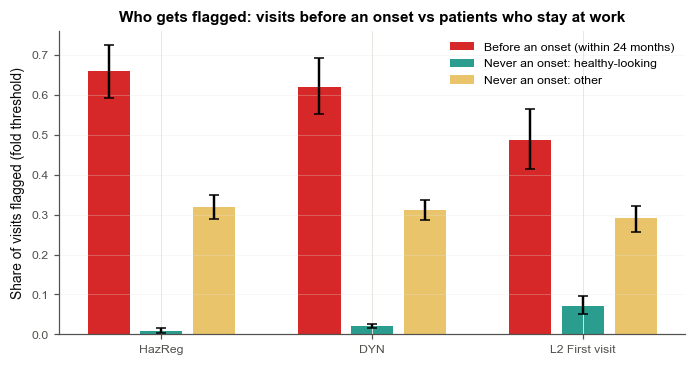

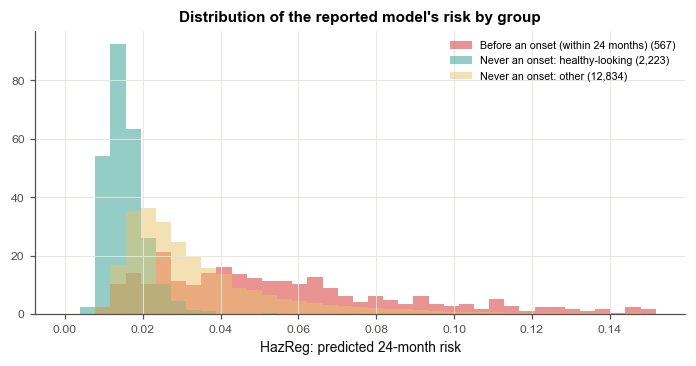

In [65]:
"""Healthy-looking stayers: risk, flags and time-matched AUROC."""
GROUPS = {NEAR_LABEL: NEAR, "Never an onset: healthy-looking": NEVER & HEALTHY,
          "Never an onset: other": NEVER & ~HEALTHY}
print("Landmark visits / patients per group: " + ", ".join(
    f"{k}: {int(v.sum()):,} / {len(np.unique(PID_ALL[v]))}" for k, v in GROUPS.items()))
print(f"Healthy-looking visits among all landmarks: {HEALTHY.mean():.0%}; among those before an onset: "
      f"{HEALTHY[NEAR].mean():.0%}")
_d = TM["main"]
_hk = HEALTHY[_d["last"][_d["pk"]]]
for lab_, mk in [("healthy", _hk), ("other", ~_hk)]:
    _d[f"den_{lab_}"] = _pair_sum_fast(_BOTH, sparse.coo_matrix((np.ones(mk.sum()), (_d["ppc"][mk], _d["ppk"][mk])),
                                                                 shape=(P_, P_)).toarray())
for m in APP_MODELS:
    acc = {}
    for r in REPEATS:
        z = zpred(m, r)
        p = _expit(z)
        thr = THR_V[m][r][H][MAIN_THRESHOLD]
        flag = (z >= thr).astype(np.float32)
        for g, mask in GROUPS.items():
            Wg = _W_ALL[:, mask]
            acc.setdefault(("mean_risk", g), []).append((Wg @ p[mask]) / Wg.sum(1))
            acc.setdefault(("flagged", g), []).append((Wg @ flag[mask]) / Wg.sum(1))
        s = np.asarray(_d["mat"] @ np.nan_to_num(z)).ravel()
        for lab_, mk in [("healthy", _hk), ("other", ~_hk)]:
            a, b_ = s[_d["pc"][mk]], s[_d["pk"][mk]]
            K = sparse.coo_matrix(((a > b_) + 0.5 * (a == b_), (_d["ppc"][mk], _d["ppk"][mk])), shape=(P_, P_)).toarray()
            acc.setdefault(("tm_auroc", lab_), []).append(_pair_sum_fast(_BOTH, K) / _d[f"den_{lab_}"])
    for k, v in acc.items():
        v = np.mean(v, 0)
        STATS[(m, "obj3") + k] = (float(v[0]), v[1:])
    fh = STATS[(m, "obj3", "flagged", "Never an onset: healthy-looking")]
    fo = STATS[(m, "obj3", "flagged", "Never an onset: other")]
    STATS[(m, "obj3", "flag_diff")] = (fh[0] - fo[0], fh[1] - fo[1])
rows = []
for m in APP_MODELS:
    row = {"Model": short_label(m)}
    for g in GROUPS:
        row[f"Mean {H}-mo risk: {g}"] = fmtk((m, "obj3", "mean_risk", g))
    for g in GROUPS:
        row[f"Flagged: {g}"] = fmtk((m, "obj3", "flagged", g))
    row["Flagged, healthy minus other stayers"] = fmtk((m, "obj3", "flag_diff"))
    row["Time-matched AUROC vs healthy-looking controls"] = fmtk((m, "obj3", "tm_auroc", "healthy"))
    row["Time-matched AUROC vs other controls"] = fmtk((m, "obj3", "tm_auroc", "other"))
    rows.append(row)
OBJ3 = pd.DataFrame(rows).set_index("Model")
display(OBJ3.T)
OBJ3.to_csv(f"appA_healthy_{TAG}.csv")
fig, ax = plt.subplots(figsize=(6.4, 3.4))
_gcol = ["#d62828", "#2a9d8f", "#e9c46a"]
_km = [m for m in KEY_MODELS if m in MODELS_RUN]
for j, m in enumerate(_km):
    for k, g in enumerate(GROUPS):
        a = ci((m, "obj3", "flagged", g))
        ax.bar(j * 4 + k, a[0], color=_gcol[k], yerr=[[a[0] - a[1]], [a[2] - a[0]]], capsize=3,
               label=g if j == 0 else None)
ax.set_xticks([j * 4 + 1 for j in range(len(_km))]); ax.set_xticklabels([short_label(m) for m in _km])
ax.set_ylabel("Share of visits flagged (fold threshold)"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
ax.set_title("Who gets flagged: visits before an onset vs patients who stay at work")
plt.tight_layout(); save_fig("healthy_flags")
fig, ax = plt.subplots(figsize=(6.4, 3.4))
pz = _expit(np.mean([zpred(REPORTED, r) for r in REPEATS], 0))
bins = np.linspace(0, np.percentile(pz, 99), 40)
for (g, mask), c in zip(GROUPS.items(), _gcol):
    ax.hist(pz[mask], bins=bins, density=True, alpha=0.5, color=c, label=f"{g} ({int(mask.sum()):,})")
ax.set_xlabel(f"{short_label(REPORTED)}: predicted {H}-month risk"); ax.legend(fontsize=7)
ax.set_title("Distribution of the reported model's risk by group")
plt.tight_layout(); save_fig("healthy_hist")

## A.5 Who are the false positives?

Visits of patients who never have an onset that the reported model flags, against those it does not flag, and
against visits before an onset: means and the standardised mean difference of flagged vs unflagged stayers.

In [66]:
"""Profile of the reported model's false positives."""
_zm = np.mean([zpred(REPORTED, r) for r in REPEATS], 0)
_tm = np.nanmean([THR_V[REPORTED][r][H][MAIN_THRESHOLD] for r in REPEATS], 0)
FP = NEVER & (_zm >= _tm)
TN = NEVER & (_zm < _tm)
rows = []
for c in FP_PROFILE_VARS:
    x = _v[c].astype(float).values
    a, b_, n_ = np.nanmean(x[FP]), np.nanmean(x[TN]), np.nanmean(x[NEAR])
    sd = np.sqrt((np.nanvar(x[FP]) + np.nanvar(x[TN])) / 2)
    rows.append({"Variable": DISPLAY_NAMES.get(c, c), "Flagged stayers (false positives)": round(a, 2),
                 "Unflagged stayers": round(b_, 2), "Before an onset": round(n_, 2),
                 "SMD flagged vs unflagged": round((a - b_) / sd if sd > 0 else np.nan, 2)})
FPT = pd.DataFrame(rows).set_index("Variable").sort_values("SMD flagged vs unflagged", key=np.abs, ascending=False)
print(f"Stayer visits flagged: {int(FP.sum()):,} of {int(NEVER.sum()):,} ({FP.sum() / NEVER.sum():.0%}); healthy-looking "
      f"among them: {HEALTHY[FP].mean():.0%} (among unflagged: {HEALTHY[TN].mean():.0%})")
display(FPT)
FPT.to_csv(f"appA_false_positives_{TAG}.csv")

Stayer visits flagged: 4,047 of 15,057 (27%); healthy-looking among them: 0% (among unflagged: 20%)


,Flagged stayers (false positives),Unflagged stayers,Before an onset,SMD flagged vs unflagged
Variable,,,,
Fibromyalgia tender points (0-18),5.19,0.68,3.97,0.88
Fibromyalgia,0.31,0.02,0.23,0.83
"Prednisone, average dose since last visit (mg/day)",9.24,2.42,9.03,0.82
SLEDAI-2K,5.53,2.71,5.24,0.67
SDI damage score,2.78,1.45,2.71,0.63
"Acute visits, last 12 months",0.63,0.23,0.57,0.61
Arthralgia,0.42,0.18,0.43,0.54
Fatigue,0.21,0.04,0.22,0.51
Calendar year (adjustment),2008.69,2012.43,2006.98,-0.49


## A.6 Alarms: re-assessment schedules and alarm rules

Each assessment scored as in a clinic (at every landmark visit, every 6 or every 12 months; the latest score carried
forward), with four alarm rules learned on the training folds (level; confirmed twice; rise above the patient's own
usual risk; level or rise). Alarms per patient-year, share false, PPV, share of onsets with an alarm in the 24 months
before, flip rate. Descriptive: the per-visit PPV is low, which is why the output is a tier, not an alarm.

Assessments per patient-year at risk: visit 2.01, 6 months 1.85, 12 months 0.96


Alarms per patient-year  Share of assessments alarming  False alarms, share of resolved alarms  PPV of an alarm (onset within 24 months)  \
Model          Alarm rule                                                                                                                                                
HazReg         level                            0.611                          0.304                                   0.921                                     0.079   
               confirmed                        0.471                          0.234                                   0.918                                     0.082   
               rise                             0.413                          0.205                                   0.941                                     0.059   
               level_or_rise                    0.787                          0.391                                   0.934                                     0.066   
DYN            level                            0.598                          0.297                                   0.925                                     0.075   
               confirmed                        0.440                          0.219                                   0.922                                     0.078   
               rise                             0.443                          0.221                                   0.939                                     0.061   
               level_or_rise                    0.785                          0.390                                   0.936                                     0.064   
L2 First visit level                            0.570                          0.284                                   0.938                                     0.062   
               confirmed                        0.510                          0.254                                   0.939                                     0.061   
               rise                             1.338                          0.665                                   0.965                                     0.035   
               level_or_rise                    1.557                          0.774                                   0.961                                     0.039   

                              Alarms per patient-year, never-onset patients  Onsets with an alarm in the 24 months before  Flip rate (alarm, then no alarm next)  
Model          Alarm rule                                                                                                                                         
HazReg         level                                                  0.538                                         0.712                                  0.186  
               confirmed                                              0.410                                         0.556                                  0.135  
               rise                                                   0.385                                         0.537                                  0.516  
               level_or_rise                                          0.716                                         0.796                                  0.254  
DYN            level                                                  0.530                                         0.689                                  0.227  
               confirmed                                              0.382                                         0.515                                  0.171  
               rise                                                   0.416                                         0.576                                  0.496  
               level_or_rise                                          0.719                                         0.775                                  0.281  
L2 First visit leve

Alarms per patient-year  Share of assessments alarming  False alarms, share of resolved alarms  PPV of an alarm (onset within 24 months)  \
Re-assessment Alarm rule                                                                                                                                                
visit         level                            0.611                          0.304                                   0.921                                     0.079   
              confirmed                        0.471                          0.234                                   0.918                                     0.082   
              rise                             0.413                          0.205                                   0.941                                     0.059   
              level_or_rise                    0.787                          0.391                                   0.934                                     0.066   
6 months      level                            0.505                          0.273                                   0.938                                     0.062   
              confirmed                        0.388                          0.210                                   0.940                                     0.060   
              rise                             0.342                          0.185                                   0.957                                     0.043   
              level_or_rise                    0.669                          0.361                                   0.949                                     0.051   
12 months     level                            0.269                          0.281                                   0.937                                     0.063   
              confirmed                        0.173                          0.180                                   0.943                                     0.057   
              rise                             0.167                          0.174                                   0.962                                     0.038   
              level_or_rise                    0.350                          0.365                                   0.948                                     0.052   

                             Alarms per patient-year, never-onset patients  Onsets with an alarm in the 24 months before  Flip rate (alarm, then no alarm next)  
Re-assessment Alarm rule                                                                                                                                         
visit         level                                                  0.538                                         0.712                                  0.186  
              confirmed                                              0.410                                         0.556                                  0.135  
              rise                                                   0.385                                         0.537                                  0.516  
              level_or_rise                                          0.716                                         0.796                                  0.254  
6 months      level                                                  0.458                                         0.685                                  0.177  
              confirmed                                              0.350                                         0.475                                  0.143  
              rise                                                   0.329                                         0.412                                  0.443  
              level_or_rise                                          0.625                                         0.760                                  0.229  
12 months     level                       

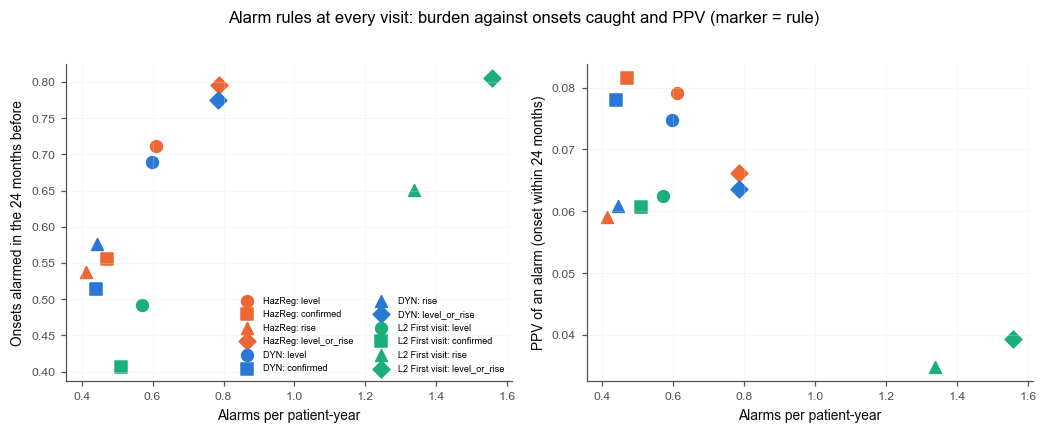

In [67]:
"""Alarm burden and false alarms by re-assessment schedule and alarm rule."""


def ewma_rise(z, rows):
    """Score at each row minus the EWMA of the same patient's EARLIER scores (rows in date order within patient)."""
    s_ = pd.Series(z[rows])
    prev = s_.groupby(PID_ALL[rows]).transform(lambda x: x.ewm(alpha=EWMA_LAMBDA, adjust=False).mean().shift(1))
    out = np.full(N_LAND, np.nan)
    out[rows] = (s_ - prev).values
    return out


THR_RISE, RISE = {}, {}
for m in APP_MODELS:
    for r in REPEATS:
        thr = np.full(N_LAND, np.nan)
        for f in range(CV_N_SPLITS):
            tr, zo = OOF_H[(m, r, f)]
            zf = np.full(N_LAND, np.nan); zf[tr] = zo
            ro = ewma_rise(zf, np.sort(tr))[tr]
            lab = LABEL_H[H][tr]
            k = ~np.isnan(lab) & ~np.isnan(ro)
            thr[rows_of(OUTER[r][f][1])] = choose_thresholds(lab[k], ro[k])["cost"]
        THR_RISE[(m, r)] = thr
        RISE[(m, r)] = ewma_rise(zpred(m, r), np.arange(N_LAND))


def assessment_schedule(every_months):
    """Assessments of every patient: (latest landmark row, date in days, position within the patient)."""
    lr_, tau_, seq_ = [], [], []
    for pid, li in PT_ROWS.items():
        t = _LAND_T[li]
        if every_months == 0:
            tau, lr = t, li
        else:
            tau = np.arange(t[0], t[-1] + 1e-6, every_months * MONTH_DAYS)
            lr = li[np.searchsorted(t, tau, side="right") - 1]
            ok = tau < INT_END[lr]                       # still at risk since the latest landmark
            tau, lr = tau[ok], lr[ok]
        lr_.append(lr); tau_.append(tau); seq_.append(np.arange(len(lr)))
    lr, tau, sq = np.concatenate(lr_), np.concatenate(tau_), np.concatenate(seq_)
    rem = _END[lr] - tau                                 # follow-up left after the assessment
    true = (C_ALL[lr] == 1) & (rem <= HORIZON_DAYS)
    false = ~true & ((rem > HORIZON_DAYS) | (C_ALL[lr] >= 2))
    fo = pd.Series(PID_ALL[lr]).map(FIRST_ONSET).values.astype("datetime64[ns]")
    fo_d = (fo - np.datetime64("1970-01-01")) / np.timedelta64(1, "D")
    pre_onset = (tau < fo_d) & (tau >= fo_d - H * MONTH_DAYS)
    return {"lr": lr, "tau": tau, "seq": sq, "pid": PID_ALL[lr], "true": true, "false": false, "pre_onset": pre_onset}


ASSESS = {k: assessment_schedule(v) for k, v in ASSESS_SCHEDULES.items()}
_PY_ALL = INT_YRS.sum()
_never = ~np.isin(PID_ALL, list(EVER_ONSET))
_PY_NEVER = INT_YRS[_never].sum()
print("Assessments per patient-year at risk: " + ", ".join(f"{k} {len(a['lr']) / _PY_ALL:.2f}" for k, a in ASSESS.items()))


def alarm_stats(m, r, sched, rule):
    A = ASSESS[sched]
    lr = A["lr"]
    level = zpred(m, r)[lr] >= THR_V[m][r][H][MAIN_THRESHOLD][lr]
    rise = np.nan_to_num(RISE[(m, r)][lr], nan=-np.inf) >= THR_RISE[(m, r)][lr]
    if rule == "level":
        on = level
    elif rule == "confirmed":
        on = level & np.r_[False, level[:-1]] & (A["seq"] > 0)
    elif rule == "rise":
        on = rise
    else:
        on = level | rise
    has_next = np.r_[A["seq"][1:] > 0, False]
    resolved = on & (A["true"] | A["false"])
    ev_alarmed = pd.Series(on & A["pre_onset"]).groupby(A["pid"]).max()
    ev_alarmed = ev_alarmed.reindex(list(EVER_ONSET)).fillna(False).astype(float)
    never_on = on & ~np.isin(A["pid"], list(EVER_ONSET))
    return {"Alarms per patient-year": on.sum() / _PY_ALL, "Share of assessments alarming": on.mean(),
            "False alarms, share of resolved alarms": (on & A["false"]).sum() / max(resolved.sum(), 1),
            "PPV of an alarm (onset within 24 months)": (on & A["true"]).sum() / max(resolved.sum(), 1),
            "Alarms per patient-year, never-onset patients": never_on.sum() / _PY_NEVER,
            "Onsets with an alarm in the 24 months before": float(ev_alarmed.mean()),
            "Flip rate (alarm, then no alarm next)": (on & np.r_[~on[1:], True] & has_next).sum()
            / max((on & has_next).sum(), 1)}


rows = []
for m in APP_MODELS:
    for sched in ASSESS_SCHEDULES:
        for rule in ALARM_RULE_LABELS:
            vals = pd.DataFrame([alarm_stats(m, r, sched, rule) for r in REPEATS]).mean()
            rows.append({"Model": short_label(m), "Re-assessment": sched, "Alarm rule": rule, **vals.to_dict()})
ALARMS = pd.DataFrame(rows)
ALARMS.to_csv(f"appA_alarms_{TAG}.csv", index=False)
_am = [m for m in KEY_MODELS if m in MODELS_RUN]
display(ALARMS[(ALARMS["Model"].isin([short_label(m) for m in _am])) & (ALARMS["Re-assessment"] == "visit")]
        .set_index(["Model", "Alarm rule"]).drop(columns="Re-assessment").round(3))
display(ALARMS[(ALARMS["Model"] == short_label(REPORTED))].set_index(["Re-assessment", "Alarm rule"])
        .drop(columns="Model").round(3))
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))
_v = ALARMS[ALARMS["Re-assessment"] == "visit"]
for m in _am:
    d = _v[_v["Model"] == short_label(m)].set_index("Alarm rule")
    for rule, mk in zip(ALARM_RULE_LABELS, ["o", "s", "^", "D"]):
        axes[0].scatter(d.loc[rule, "Alarms per patient-year"], d.loc[rule, "Onsets with an alarm in the 24 months before"],
                        color=model_color(m), marker=mk, s=60, label=f"{short_label(m)}: {rule}")
        axes[1].scatter(d.loc[rule, "Alarms per patient-year"], d.loc[rule, "PPV of an alarm (onset within 24 months)"],
                        color=model_color(m), marker=mk, s=60)
axes[0].set_xlabel("Alarms per patient-year"); axes[0].set_ylabel("Onsets alarmed in the 24 months before")
axes[1].set_xlabel("Alarms per patient-year"); axes[1].set_ylabel("PPV of an alarm (onset within 24 months)")
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=6, ncol=2)
fig.suptitle("Alarm rules at every visit: burden against onsets caught and PPV (marker = rule)", y=1.02)
plt.tight_layout(); save_fig("appA_alarms")

## A.7 The evaluation rules side by side

Every model under each way of scoring it (patient windows, time-matched AUROC, risk-set C, the visit AUROC at 6, 12
and 24 months, within-patient C, prospective alarms) and how well the rules agree across models.

,E0 patient windows,E0b time-matched patient AUROC,E1 risk-set C,E2 visit AUROC 6 mo,E2 visit AUROC 12 mo,E2 visit AUROC 24 mo,Within-patient C,E3 onsets alarmed (level),E3 alarm PPV (level),E3 alarms / patient-year (level),E3 onsets alarmed (level or rise),E3 alarm PPV (level or rise)
Model,,,,,,,,,,,,
HazReg,0.791 (0.751 to 0.833),0.745 (0.707 to 0.784),0.745 (0.706 to 0.784),0.738 (0.692 to 0.785),0.736 (0.693 to 0.777),0.726 (0.682 to 0.769),0.591 (0.519 to 0.661),0.71,0.079,0.61,0.80,0.066
LogReg,0.776 (0.736 to 0.821),0.733 (0.692 to 0.774),0.729 (0.687 to 0.770),0.726 (0.678 to 0.777),0.727 (0.684 to 0.772),0.724 (0.679 to 0.769),0.616 (0.548 to 0.684),0.69,0.082,0.56,0.79,0.065
DYN,0.781 (0.739 to 0.824),0.731 (0.693 to 0.771),0.745 (0.703 to 0.785),0.734 (0.685 to 0.782),0.728 (0.685 to 0.770),0.714 (0.670 to 0.756),0.622 (0.559 to 0.689),0.69,0.075,0.60,0.77,0.064
L2 First visit,0.702 (0.654 to 0.750),0.634 (0.587 to 0.684),0.634 (0.588 to 0.684),0.671 (0.616 to 0.723),0.646 (0.593 to 0.697),0.627 (0.572 to 0.681),0.248 (0.185 to 0.309),0.49,0.062,0.57,0.81,0.039
L1 Demographics,0.555 (0.507 to 0.601),0.540 (0.494 to 0.586),0.539 (0.493 to 0.585),0.518 (0.466 to 0.569),0.503 (0.457 to 0.552),0.525 (0.475 to 0.573),0.672 (0.623 to 0.722),0.38,0.043,0.70,0.79,0.037
Unit score,0.755 (0.709 to 0.803),0.724 (0.682 to 0.769),0.725 (0.683 to 0.766),0.714 (0.665 to 0.767),0.708 (0.664 to 0.755),0.708 (0.665 to 0.753),0.707 (0.641 to 0.769),0.69,0.066,0.72,0.78,0.056
HazReg wide,0.774 (0.732 to 0.815),0.724 (0.688 to 0.767),0.734 (0.695 to 0.773),0.725 (0.677 to 0.773),0.713 (0.669 to 0.753),0.706 (0.663 to 0.746),0.584 (0.520 to 0.648),0.72,0.068,0.70,0.78,0.062


Rank correlation across models between the rules (Spearman):


,E0 patient windows,E0b time-matched patient AUROC,E1 risk-set C,E2 visit AUROC 6 mo,E2 visit AUROC 12 mo,E2 visit AUROC 24 mo,Within-patient C,E3 onsets alarmed,E3 alarm PPV
E0 patient windows,1.00,0.93,0.93,1.00,1.00,0.93,-0.14,0.71,0.89
E0b time-matched patient AUROC,0.93,1.00,0.75,0.93,0.93,1.00,0.00,0.54,0.93
E1 risk-set C,0.93,0.75,1.00,0.93,0.93,0.75,-0.14,0.82,0.75
E2 visit AUROC 6 mo,1.00,0.93,0.93,1.00,1.00,0.93,-0.14,0.71,0.89
E2 visit AUROC 12 mo,1.00,0.93,0.93,1.00,1.00,0.93,-0.14,0.71,0.89
E2 visit AUROC 24 mo,0.93,1.00,0.75,0.93,0.93,1.00,0.00,0.54,0.93
Within-patient C,-0.14,0.00,-0.14,-0.14,-0.14,0.00,1.00,-0.25,-0.14
E3 onsets alarmed,0.71,0.54,0.82,0.71,0.71,0.54,-0.25,1.00,0.54
E3 alarm PPV,0.89,0.93,0.75,0.89,0.89,0.93,-0.14,0.54,1.00


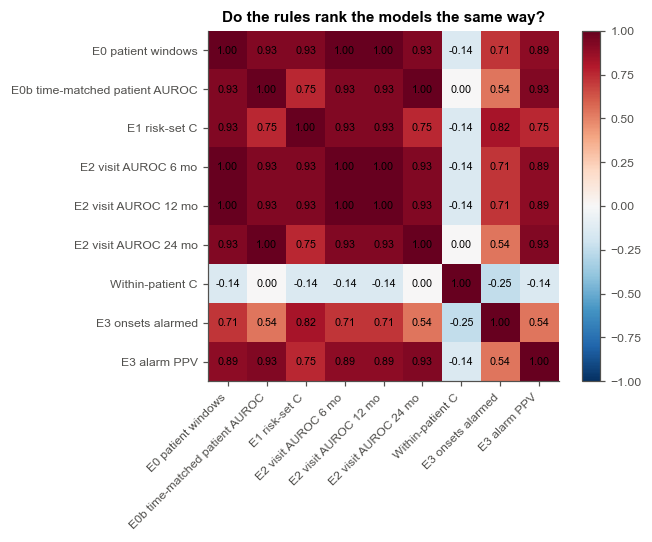

In [68]:
"""Every model under every evaluation rule."""
_al = ALARMS[(ALARMS["Re-assessment"] == "visit") & (ALARMS["Alarm rule"] == "level")].set_index("Model")
_alr = ALARMS[(ALARMS["Re-assessment"] == "visit") & (ALARMS["Alarm rule"] == "level_or_rise")].set_index("Model")
FRAME_KEYS = [("E0 patient windows", K_PT), ("E0b time-matched patient AUROC", K_TM), ("E1 risk-set C", K_RS), ("E2 visit AUROC 6 mo", ("visit", 6, "auroc")),
              ("E2 visit AUROC 12 mo", ("visit", 12, "auroc")), (f"E2 visit AUROC {H} mo", K_VIS),
              ("Within-patient C", ("within", H, "c"))]
rows, num = [], []
for m in APP_MODELS:
    row = {"Model": short_label(m), **{lab_: fmtk((m,) + k) for lab_, k in FRAME_KEYS}}
    a_, b_ = _al.loc[short_label(m)], _alr.loc[short_label(m)]
    row.update({"E3 onsets alarmed (level)": f"{a_['Onsets with an alarm in the 24 months before']:.2f}",
                "E3 alarm PPV (level)": f"{a_['PPV of an alarm (onset within 24 months)']:.3f}",
                "E3 alarms / patient-year (level)": f"{a_['Alarms per patient-year']:.2f}",
                "E3 onsets alarmed (level or rise)": f"{b_['Onsets with an alarm in the 24 months before']:.2f}",
                "E3 alarm PPV (level or rise)": f"{b_['PPV of an alarm (onset within 24 months)']:.3f}"})
    rows.append(row)
    num.append({"Model": short_label(m), **{lab_: ci((m,) + k)[0] for lab_, k in FRAME_KEYS},
                "E3 onsets alarmed": a_["Onsets with an alarm in the 24 months before"],
                "E3 alarm PPV": a_["PPV of an alarm (onset within 24 months)"]})
FRAMES = pd.DataFrame(rows).set_index("Model")
display(FRAMES)
FRAMES.to_csv(f"appA_evaluation_rules_{TAG}.csv")
NUM = pd.DataFrame(num).set_index("Model")
RHO = NUM.corr(method="spearman")
print("Rank correlation across models between the rules (Spearman):")
display(RHO.round(2))
RHO.to_csv(f"appA_rule_agreement_{TAG}.csv")
fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(RHO.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(RHO))); ax.set_xticklabels(RHO.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(RHO))); ax.set_yticklabels(RHO.index, fontsize=8)
for i in range(len(RHO)):
    for j in range(len(RHO)):
        ax.text(j, i, f"{RHO.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, fraction=0.046); ax.set_title("Do the rules rank the models the same way?")
plt.tight_layout(); save_fig("rule_agreement")

## A.8 Discrimination across calendar time

Visit AUROC of the key models in overlapping 4-year windows of landmark dates (CV predictions; not a temporal
validation).

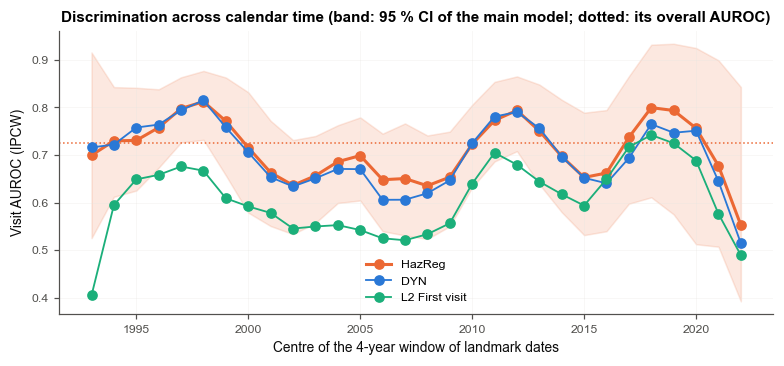

,windows,below,above,lowest,highest
Model,,,,,
DYN,30,0.033,0.067,0.515,0.815
HazReg,30,0.000,0.067,0.553,0.812
L2 First visit,30,0.000,0.000,0.405,0.742


In [69]:
"""Discrimination in rolling calendar windows."""
_yr_l = land["CAL_YEAR"].values
_y0, _y1 = int(np.floor(_yr_l[ROWS_IPCW].min())), int(np.ceil(_yr_l[ROWS_IPCW].max()))
_wins = [(a, a + CAL_WINDOW_YEARS) for a in range(_y0, _y1 - CAL_WINDOW_YEARS + 1, CAL_WINDOW_STEP)]
rows = []
for m in [m for m in KEY_MODELS if m in MODELS_RUN]:
    overall = ci((m,) + K_VIS)[0]
    for a, b in _wins:
        k = (_yr_l[ROWS_IPCW] >= a) & (_yr_l[ROWS_IPCW] < b)
        if Y_IPCW[k].sum() < CAL_WINDOW_MIN_ONSETS:
            continue
        rr = ROWS_IPCW[k]
        Wr = _BOTH[:, ROW_PIDX[rr]] * WI_IPCW[k][None, :]
        v = np.mean([wauc(Y_IPCW[k], zpred(m, r)[rr], Wr) for r in REPEATS], 0)
        lo, hi = np.nanpercentile(v[1:], [2.5, 97.5])
        rows.append({"Model": short_label(m), "Window": f"{a}-{b - 1}", "Start": a, "Landmarks": int(k.sum()),
                     "Onsets": int(Y_IPCW[k].sum()), "AUROC": v[0], "Lower": lo, "Upper": hi, "Overall": overall,
                     "CI below overall": hi < overall, "CI above overall": lo > overall})
CALWIN = pd.DataFrame(rows)
CALWIN.to_csv(f"appA_calendar_windows_{TAG}.csv", index=False)
fig, ax = plt.subplots(figsize=(7.2, 3.4))
for m in KEY_MODELS:
    d = CALWIN[CALWIN["Model"] == short_label(m)]
    if len(d):
        x = d["Start"] + CAL_WINDOW_YEARS / 2
        ax.plot(x, d["AUROC"], "o-", color=model_color(m), lw=2 if m == REPORTED else 1.2, label=short_label(m))
        if m == REPORTED:
            ax.fill_between(x, d["Lower"], d["Upper"], color=model_color(m), alpha=0.15)
            ax.axhline(d["Overall"].iloc[0], color=model_color(m), ls=":", lw=1)
ax.set_xlabel(f"Centre of the {CAL_WINDOW_YEARS}-year window of landmark dates"); ax.set_ylabel("Visit AUROC (IPCW)")
ax.set_title("Discrimination across calendar time (band: 95 % CI of the main model; dotted: its overall AUROC)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("calendar_windows")
_s = CALWIN.groupby("Model").agg(windows=("Window", "size"), below=("CI below overall", "mean"),
                                 above=("CI above overall", "mean"), lowest=("AUROC", "min"), highest=("AUROC", "max"))
display(_s.round(3))

## A.9 Restricted risk sets

Each onset's last landmark against every control's latest landmark on the onset date, restricting the controls to
those onset-free for 24 months, never an onset, and never an onset with the same time in clinic.

In [70]:
"""Restricted risk sets."""
_FIRST_DAY = pd.Series({pid: _VDAYS[_VIDX[pid][0]] for pid in PT_ROWS})
_first_row = _FIRST_DAY.reindex(PID_ALL).values
_ever = np.isin(PID_ALL, list(EVER_ONSET))
_rem = _END[RS_CTRL] - INT_END[RS_CASE]
RS_VARIANTS = {"All at risk (main)": np.ones(len(RS_CASE), bool),
               f"Onset-free {H} months": (_rem > HORIZON_DAYS) | (C_ALL[RS_CTRL] >= 2),
               "Never an onset": ~_ever[RS_CTRL],
               "Never an onset, matched time in clinic": ~_ever[RS_CTRL]
               & (np.abs(_first_row[RS_CTRL] - _first_row[RS_CASE]) <= 2 * 365.25)}
rows = []
for m in APP_MODELS:
    row = {"Model": short_label(m), "Patient AUROC (windows)": fmtk((m,) + K_PT)}
    for lab_, mk in RS_VARIANTS.items():
        den = _pair_sum_fast(_BOTH, sparse.coo_matrix((np.ones(mk.sum()), (RS_PC[mk], RS_PK[mk])),
                                                      shape=(P_, P_)).toarray())
        vals = []
        for r in REPEATS:
            ps = patient_score_rs(m, zpred(m, r))
            a, b = ps[RS_CASE[mk]], ps[RS_CTRL[mk]]
            K = sparse.coo_matrix(((a > b) + 0.5 * (a == b), (RS_PC[mk], RS_PK[mk])), shape=(P_, P_)).toarray()
            vals.append(_pair_sum_fast(_BOTH, K) / den)
        v = np.mean(vals, 0)
        row[lab_] = fmt(v[0], *np.nanpercentile(v[1:], [2.5, 97.5]))
    rows.append(row)
RS_RESTRICTED = pd.DataFrame(rows).set_index("Model")
display(RS_RESTRICTED)
RS_RESTRICTED.to_csv(f"sensitivity_riskset_restricted_{TAG}.csv")
_pa = [ci((m,) + K_PT)[0] for m in APP_MODELS]
_rc = [ci((m,) + K_RS)[0] for m in APP_MODELS]
print(f"Rank correlation across models, patient AUROC vs risk-set C: {stats.spearmanr(_pa, _rc).correlation:.2f}")

,Patient AUROC (windows),All at risk (main),Onset-free 24 months,Never an onset,"Never an onset, matched time in clinic"
Model,,,,,
HazReg,0.791 (0.751 to 0.833),0.745 (0.706 to 0.784),0.757 (0.717 to 0.798),0.759 (0.718 to 0.803),0.776 (0.732 to 0.815)
LogReg,0.776 (0.736 to 0.821),0.729 (0.687 to 0.770),0.744 (0.703 to 0.788),0.741 (0.697 to 0.787),0.762 (0.717 to 0.802)
DYN,0.781 (0.739 to 0.824),0.745 (0.703 to 0.785),0.758 (0.717 to 0.798),0.758 (0.713 to 0.800),0.772 (0.731 to 0.811)
L2 First visit,0.702 (0.654 to 0.750),0.634 (0.588 to 0.684),0.640 (0.590 to 0.691),0.645 (0.591 to 0.702),0.650 (0.596 to 0.706)
L1 Demographics,0.555 (0.507 to 0.601),0.539 (0.493 to 0.585),0.544 (0.495 to 0.594),0.550 (0.498 to 0.600),0.554 (0.505 to 0.606)
Unit score,0.755 (0.709 to 0.803),0.725 (0.683 to 0.766),0.742 (0.699 to 0.784),0.738 (0.693 to 0.783),0.762 (0.717 to 0.806)
HazReg wide,0.774 (0.732 to 0.815),0.734 (0.695 to 0.773),0.749 (0.710 to 0.789),0.746 (0.704 to 0.789),0.758 (0.717 to 0.797)


Rank correlation across models, patient AUROC vs risk-set C: 0.93
